# ST1131 · Searchable Exam Code Reference

An expanded **separate copy** of the consolidated notes, including your friend’s cleaning workflow, CI/sample-size shortcut functions and revised diagnostics helper. Covers the lecture notebooks, Tutorials 1–10 and their solutions, plus common NumPy/pandas variations useful for the assigned DataCamp areas. This is a practical catalogue, not a claim to cover every API in either library. The individual DataCamp exercises were not provided; the extra recipes cover their named skill areas.

**Fast use:** run **SETUP-01** once; load your data with **DATA-01**; then search for the question's words or a recipe ID. Each recipe says when to use it and what to change. Most cookbook examples use a tiny reproducible `df`, `arr`, or `mat`; replace those with your exam variables. Original course-data examples are retained in the appendix.

**Search in VS Code:** use **Find in Notebook** (`Ctrl+F` / `Cmd+F`) and include code/Markdown sources. If a collapsed or rendered cell is not found, use VS Code's file search or the companion HTML. In the HTML, the search box filters recipes; several words narrow results; quotes match a phrase. Use ordinary browser Find to search the full page text. No internet/CDN is required.

**What to practise:** find → choose the correct variation → change inputs → run → read the requested output. Do not copy a fixed example's alternative, group order, cut-off, or significance level without checking the question.

**Inputs used repeatedly:** `df` = table; `s` = one column; `arr` = 1D array; `mat` = 2D array; `x`, `y` = numeric samples; `n` = observations per sample; `N` = simulation repetitions; `confidence` = e.g. `0.95`; `alpha` = `1-confidence`; `mu0`/`p0` = null values.

**Safe execution:** examples change in-memory objects or new copies only. Export snippets are commented out. No package installs, network calls or dataset overwrites are performed. Run from the project root or `src`; the data resolver handles either. Outside this project, set `DATA_DIR` explicitly.

**Scope distinction:** course methods appear throughout the statistics sections. Broader pandas/NumPy recipes are extra reference material. Prediction intervals and nonzero-null extensions are labelled where they extend the tutorial patterns.


## How to use a method without memorising it

Every example has a **Method guide** immediately before its code. Copy the matching pattern, change the named inputs, and read the result column to see whether you need an assignment, a mask, an aggregation or a result attribute.

1. Run **SETUP-01**, then load the file required by your question with DATA-01. Run any additional prerequisite named in the recipe.
2. Replace `data` / `df` with your actual table; `s` is one column such as `data["score"]`; `values` is a numeric array or sample. Quoted column names must match your file exactly.
3. Choose the operation that answers the question. A cell may demonstrate several **alternatives**; they are not automatically one cleaning pipeline. Preserve linked assignments needed by your chosen operation.
4. Assign returned data if you want to use it: `clean = data.dropna(...)`. To update a column: `data["x"] = pd.to_numeric(data["x"], errors="coerce")`. Displaying a returned object does not save the change.

**Read a call:** in `pd.to_numeric(data["x"], errors="coerce")`, `pd.to_numeric` is the function, `data["x"]` is its input, and `errors="coerce"` is a named option. `numbers = ...` stores the result. In `data.loc[mask]`, square brackets select rows; `.loc` is not called with parentheses.

| Option you see | Meaning / how to choose it |
|---|---|
| `errors="coerce"` versus `"raise"` | In numeric conversion, coerce makes invalid text NaN; raise stops at invalid input and is the default. For dates, coerce makes NaT. |
| `axis=0` versus `axis=1` | A reduction with axis=0 collapses rows, producing column summaries; axis=1 collapses columns, producing row summaries. For `div`, axis instead tells pandas which labels to align. |
| `ddof=1` versus `0` | ddof sets the divisor to n-ddof. Sample variance/SD uses ddof=1 (n-1); population-style denominator uses ddof=0 (n). NumPy defaults to 0 and pandas to 1. Search NP-08 for the worked example. |
| `subset=[...]` | The particular columns to inspect for missing values/duplicates. It does not select output columns. |
| `inplace=True` | Some pandas methods mutate the object and return None; their default usually returns a new object. The reference normally uses explicit assignments. Never assign a None result back to your data. |
| `na=False` | In text matching, make missing text a nonmatch. Negating that mask then includes those missing entries unless notna is also required. |
| `ascending=False` | Sort/rank largest first; True means smallest first. |
| `normalize=True` | In value_counts, return proportions rather than counts; multiply by 100 for percentages. In crosstab, choose row/column/overall normalisation explicitly. |
| `size=(N,n)` | Simulation output shape: N repeated samples, n observations per sample. `.mean(axis=1)` calculates one mean per row. |
| `loc`, `scale` | For normal distributions: mean, SD. In an interval for an estimated mean: loc is the estimate and scale its SE. They are unrelated to pandas `.loc`. |
| `confidence=.95` versus `alpha=.05` | SciPy interval calls use confidence; statsmodels conf_int/summary_frame use alpha=1-confidence. Read the particular method’s pattern. |
| `alternative`, `equal_var` | Direction of the test (first minus second), and pooled True versus Welch False. Match the question rather than copying the example’s choice. |
| Plot `color` / `colors`, `edgecolor`, `facecolor` | Line/point/bar colour(s), border colour and filled-interior colour. They change appearance, not statistical calculations. |
| Plot `label`, `linewidth` / `lw`, `alpha`, `s` | Legend name, line thickness, opacity and scatter-marker area. Statistical significance is not encoded by plot alpha. |
| `figsize`, `bins`, `grid`, `stacked` | Figure dimensions in inches, histogram intervals, background grid visibility and whether bars stack. Choose sensible display settings for your actual data. |
| Names such as `mean_score=`, `SR=` or `facecolor=` inside a mapping | Named aggregation and assign choose output column names; dict(...) chooses dictionary keys. Some names are your choices rather than fixed method parameters. Read the specific call. |

**When stuck:** search the exact method name (`to_numeric`, `dropna`, `transform`, `ttest_ind`) or the task words. The local guide explains the call; the code beneath it shows a runnable use. The retained appendix has the same method guides.

**Helper functions:** run their definition cell once, then copy the demonstrated call with your inputs. You do not need to memorise or retype the internals of mean_ci, independent_t_interval or the diagnostics helpers.

**Showing versus storing:** `print(value)` shows text/numbers and `display(table)` shows a formatted table. Neither saves a calculation for later: use `answer = calculation` first when you need to reuse it.


## Parameter choices — how to choose a value

Each Method guide now includes **Parameter choices and examples**. For settings with a finite set, the guide lists those choices and their meanings. For numbers, data, labels, paths or patterns, it gives the accepted form/range and examples: there is no finite list of all possible sample sizes or column names. The examples are inputs to adapt, not exam constants.

Choices are specific to the method: `axis` for a reduction differs from `axis` for `div`; `keep` for duplicates differs from `keep` for largest rows. Options marked NumPy-only or pandas-only must stay with that API. The descriptions target the installed exam environment and the course templates; older/deprecated alternatives are marked where relevant.

**Try one change at a time:** choose the method, choose the stated parameter value, run the example, and inspect the shape/output. For a tuple such as `(5000,25)`, both entries have a role: rows first, columns second. Search SIM-03 for the complete explanation.


## How to read and replace example numbers

Every code example now has **Example values explained** and **Replace for your question** guidance. The numbers demonstrate a particular situation; read their roles before replacing them. The same explanation is included as comments when you copy a code cell.

| Kind of number | Meaning | What to do |
|---|---|---|
| Observations or table counts | Actual measurements, or counts in labelled row/column combinations | Replace with your data, preserving the matching labels/order. |
| Question inputs | Mean, SD, sample size, null value, event boundary, confidence/significance level | Enter the values specified in your question; SD is not variance. |
| Index or slice positions | `0` is the first position; `-1` the last; slice stops are excluded | Change to the required positions. `.loc` uses labels; `.iloc` uses positions. |
| Method conventions | `ddof=1`, `n-1`, `alpha/2`, `axis=0/1`, continuity correction `0.5` | Keep the convention appropriate to the method; these are not sample data. |
| Simulation settings | Seed, repetitions `N`, observations per sample `n` | Use prescribed settings. A seed is not a sample size. |
| Display settings | Figure size, colours, bins, opacity, rounding | Adapt for readability. Plot `alpha` means opacity, not significance. |

**Counts versus probabilities:** a table entry of `30` means 30 observations in that cell. Divide by the appropriate computed total to obtain a probability. For conditional probability, the denominator is the group after **given**.

**Indentation:** blocks use four spaces. Each statement is on its own line; table rows and dictionary fields are separated and labelled where helpful. Copy the whole relevant code cell, including its indentation.


## Contents and search shortcuts

| Section | Jump / typical search words |
|---|---|
| [00 · Setup, imports and reusable example data](#setup) | Run the import/example-data cell first. Templates print real results rather than using unbound placeholders. |
| [01 · NumPy arrays, indexing and numerical operations](#numpy) | Search by task: create, slice, mask, rows, columns, reshape, missing, sort, unique, broadcasting, axis, copy. |
| [02 · pandas loading, inspection, rows and columns](#pandas-basics) | Use DATA-01 to load exam files, then select/filter using the recipes below. Selecting does not automatically change the original table. |
| [03 · Filtering cookbook: comparisons, text, dates, groups and indices](#filtering) | Each recipe gives a different filtering pattern. Search synonyms such as between, exclude, contains, all columns, top per group, missing, duplicate, or MultiIndex. |
| [04 · Cleaning, recoding, transformations and safe assignment](#cleaning) | Recipes operate on new copies. Missingness should be handled to match the analysis, not blindly removed from the whole file. |
| [05 · Frequencies, grouped summaries, pivots and joins](#grouping) | Counts, proportions and conditional percentages answer different questions. Read the denominator before selecting normalize. |
| [06 · Dates, cumulative/rolling operations and ranking](#dates) | Broader pandas reference for data manipulation. Sort by the intended order before any cumulative, lagged or rolling calculation. |
| [07 · Plots, graphical comparisons and outlier checks](#plots) | Choose plot by variable type: categorical→bar; quantitative→histogram/boxplot; categorical+quantitative→grouped boxplots; two quantitative→scatter. |
| [08 · Probability, random variables and distribution variations](#probability) | Translate the event first, then choose pmf/cdf/sf/ppf. scipy norm scale is SD, never variance. Probability distributions below are course-scope unless noted. |
| [09 · Sampling distributions, CLT and simulation](#sampling) | n is sample size; N is the number of repetitions. Increasing n changes the sampling distribution; increasing N only improves the simulation approximation. |
| [10 · Confidence intervals and sample-size planning](#ci) | Input confidence=0.95 into scipy interval methods; input alpha=0.05 into statsmodels conf_int/summary_frame. Width=2×margin of error. |
| [11 · Hypothesis tests: raw data, summaries, tails and paired data](#tests) | Decide mean/proportion; one/two samples; independent/paired; direction; variance assumption. Alternative always follows the subtraction order. The Levene→pooled/Welch selection below follows the course workflow. |
| [12 · Regression templates and interpretation](#regression) | Course workflow: scatter/correlation → fit → coefficient/overall tests → diagnostics → interpret/predict/refine. Models with different response transformations have R² on different scales. |
| [12B · Extra Python, NumPy and pandas variations](#extra-recipes) | Additional lookup recipes for common data-manipulation questions. These extend the core course examples without requiring additional packages. |
| [12C · Additional variations found in the course audit](#audit-helpers) | These recipes fill gaps found by checking all lecture notebooks and tutorial solution code. They run after SETUP-01 without needing the earlier regression examples. |
| [12D · Complete workflows on actual tutorial datasets](#course-workflows) | These examples use the real course column names and run after SETUP-01. They provide complete starting points for the most connected tutorial question types; change filenames, columns and hypotheses for the exam. |
| [13 · Decision cards and conceptual checks](#decisions) | Python calculates the output. These decisions determine whether that output answers the question. |
| [14 · Course question map and lookup drill](#coverage) | Use this map to rehearse retrieval: open the tutorial, hide its solution, find the relevant recipe and adapt it to the actual dataset. |
| [15 · Merged consolidated course notes and dataset examples](#original-appendix) | Your friend’s updated topic-by-topic notes follow, with the earlier worked CI example also retained. This copy uses corrected data-folder lookup, portable boxplots, validated shortcut functions and aligned diagnostic rows. Both source versions remain unchanged. These examples depend on earlier appendix cells; use the cookbook above for shorter task-based recipes. |

## Recipe index — exact IDs and natural-language task names

- [SETUP-01 · Imports, data folder and reproducible example data](#SETUP-01)
- [NP-01 · Create arrays, sequences, zeros, ones and data types](#NP-01)
- [NP-02 · Index and slice a 1D array](#NP-02)
- [NP-03 · Select 2D rows, columns, rectangles and individual cells](#NP-03)
- [NP-04 · Boolean filters: comparisons, AND, OR, NOT, XOR](#NP-04)
- [NP-05 · Membership, nonmembership, close values and condition positions](#NP-05)
- [NP-06 · Filter entire rows or columns using any/all](#NP-06)
- [NP-07 · Conditional replacement and multiple categories](#NP-07)
- [NP-08 · Mean, variance, standard deviation and quantiles](#NP-08)
- [NP-09 · Axis summaries, cumulative totals and differences](#NP-09)
- [NP-10 · Missing and infinite values](#NP-10)
- [NP-11 · Sort, rank positions, min/max locations and unique counts](#NP-11)
- [NP-12 · Reshape, flatten, transpose and combine arrays](#NP-12)
- [NP-13 · Broadcasting, standardisation and elementwise versus matrix math](#NP-13)
- [NP-14 · Copies, views and safe mutation](#NP-14)
- [NP-15 · Simulate, sample, shuffle and draw weighted categories](#NP-15)
- [DATA-01 · Read CSV/text files and inspect the dataset](#DATA-01)
- [PD-01 · Inspect shape, types, missingness and numerical/categorical summaries](#PD-01)
- [PD-02 · Select columns by name, position, type or name pattern](#PD-02)
- [PD-03 · loc versus iloc, scalar access and slices](#PD-03)
- [PD-04 · Rename, reorder, add/drop columns and reset the index](#PD-04)
- [COUNT-01 · Count rows, columns, cells, missing entries and column names](#COUNT-01)
- [COUNT-02 · Count x/y/z values: cells, rows, columns, any, all and every target](#COUNT-02)
- [COUNT-03 · Count numeric matches: at least k, exactly k, different conditions and column summaries](#COUNT-03)
- [COUNT-04 · Count removed rows and columns before/after each cleaning step](#COUNT-04)
- [COUNT-05 · Count overlapping exclusions without double-counting rows](#COUNT-05)
- [FILTER-01 · One condition and all comparison operators](#FILTER-01)
- [FILTER-02 · AND / OR / NOT / XOR with nested conditions](#FILTER-02)
- [FILTER-03 · Membership: in, not in, allowed/excluded categories](#FILTER-03)
- [FILTER-04 · Between, inside/outside an interval and endpoint rules](#FILTER-04)
- [FILTER-05 · Missing values: one column, any/all columns and complete pairs](#FILTER-05)
- [FILTER-06 · Text contains: literal, case-insensitive and regex alternatives](#FILTER-06)
- [FILTER-07 · Text starts/ends with, exact match and full regular expression](#FILTER-07)
- [FILTER-08 · Any/all conditions across several columns](#FILTER-08)
- [FILTER-09 · Filter by row index or physical position](#FILTER-09)
- [FILTER-10 · query with external variables and special column names](#FILTER-10)
- [FILTER-11 · Threshold relative to the overall/group mean or quantile](#FILTER-11)
- [FILTER-12 · Largest/smallest rows, sorted rows and top k per group](#FILTER-12)
- [FILTER-13 · Keep/drop entire groups based on size or summary](#FILTER-13)
- [FILTER-14 · Find duplicates, unique rows and first/last occurrence](#FILTER-14)
- [FILTER-15 · Filter dates, months, weekdays and date intervals](#FILTER-15)
- [FILTER-16 · Floating-point tolerance, finite values and numeric strings](#FILTER-16)
- [FILTER-17 · Filter columns/rows by missingness, variability or Boolean mask](#FILTER-17)
- [FILTER-18 · Random sample and stratified sample of rows](#FILTER-18)
- [FILTER-19 · MultiIndex selection and cross-sections](#FILTER-19)
- [FILTER-20 · Keep matching IDs from another table: semi/anti joins](#FILTER-20)
- [CLEAN-01 · Handle missing values and fill within groups](#CLEAN-01)
- [CLEAN-02 · Assign using masks; derive numeric and categorical columns](#CLEAN-02)
- [CLEAN-03 · Map, replace, categorical order and dummy indicators](#CLEAN-03)
- [CLEAN-04 · Convert types and clean/extract/split text](#CLEAN-04)
- [CLEAN-05 · Bin with cut or equal-count quantile groups](#CLEAN-05)
- [CLEAN-06 · Apply a custom function and loop over rows/groups](#CLEAN-06)
- [CLEAN-07 · Export a new CSV without overwriting course files](#CLEAN-07)
- [CLEAN-09 · Reload, clean a fresh copy and audit rows removed](#CLEAN-09)
- [CLEAN-10 · One ordered cleaning pipeline: IDs, numeric conversion, categories and counts](#CLEAN-10)
- [CLEAN-11 · Separate temporary median imputation before validity filtering](#CLEAN-11)
- [GROUP-01 · Frequency, proportion, percentage and category order](#GROUP-01)
- [GROUP-02 · Count a condition and compute its proportion](#GROUP-02)
- [GROUP-03 · groupby summaries, several statistics and named aggregation](#GROUP-03)
- [GROUP-04 · transform, group-standardisation and grouped proportions](#GROUP-04)
- [GROUP-05 · Contingency tables: counts, row/column/overall percentages](#GROUP-05)
- [GROUP-06 · Pivot, pivot_table, melt, stack and unstack](#GROUP-06)
- [GROUP-07 · Merge inner/left/right/outer and validate join keys](#GROUP-07)
- [GROUP-08 · Correlation matrix, covariance and matched nonmissing pairs](#GROUP-08)
- [TIME-01 · Parse dates, extract components and calculate durations](#TIME-01)
- [TIME-02 · Cumulative sum/product/min/max and grouped running totals](#TIME-02)
- [TIME-03 · Lag, lead, change and rolling/resampled summaries](#TIME-03)
- [PLOT-01 · Bar plot of counts/proportions/percentages with labels](#PLOT-01)
- [PLOT-02 · Histogram: frequency versus bin probability versus density](#PLOT-02)
- [PLOT-03 · Single/grouped boxplots, horizontal orientation and fliers](#PLOT-03)
- [PLOT-04 · IQR outlier fences, inspect/remove and recompute correlation](#PLOT-04)
- [PLOT-05 · Scatterplot with category colours, legend and trend](#PLOT-05)
- [PLOT-06 · Clustered versus 100-percent stacked bars](#PLOT-06)
- [PLOT-07 · Probability mass/density curves, shading and cut-off lines](#PLOT-07)
- [PLOT-08 · QQ plot, histogram and Shapiro-Wilk normality test](#PLOT-08)
- [PROB-01 · Binomial exact probabilities: every inequality and interval](#PROB-01)
- [PROB-02 · Normal probabilities, standardisation and quantiles](#PROB-02)
- [PROB-03 · Custom discrete distribution, moments and transformations](#PROB-03)
- [PROB-04 · Independent sums/differences and weighted averages](#PROB-04)
- [PROB-05 · Bayes, sensitivity/specificity, positive/negative predictive values](#PROB-05)
- [PROB-06 · Screening cut-off from sensitivity or specificity](#PROB-06)
- [PROB-07 · Normal approximation with all continuity corrections](#PROB-07)
- [PROB-08 · Conditional probabilities and relative risk from table counts](#PROB-08)
- [PROB-10 · Total probability and Bayes for two or many sources](#PROB-10)
- [PROB-11 · Events, conditional probability and relative risk directly from raw rows](#PROB-11)
- [SIM-01 · Probability for one observation versus a sample mean](#SIM-01)
- [SIM-02 · Sample proportions: approximate probability and exact count boundary](#SIM-02)
- [SIM-03 · Repeated normal/exponential samples and sample-mean probabilities](#SIM-03)
- [SIM-04 · Dice means and sampling an existing population](#SIM-04)
- [SIM-05 · Confidence-interval coverage simulation](#SIM-05)
- [CI-01 · Proportion CI from success count or p-hat](#CI-01)
- [CI-02 · Mean CI from raw data and summary statistics](#CI-02)
- [CI-03 · Sample size for specified width or margin of error](#CI-03)
- [CI-04 · Change confidence levels; interval contains a null value](#CI-04)
- [CI-05 · Shortcut functions: mean_ci and proportion_ci](#CI-05)
- [CI-06 · Shortcut functions: sample_size_mean and sample_size_proportion](#CI-06)
- [CI-07 · Proportion CI from string-labelled outcomes within a subgroup](#CI-07)
- [TEST-01 · One-proportion Z test with all three alternatives](#TEST-01)
- [TEST-02 · One-sample t test from raw data, one-/two-sided CI](#TEST-02)
- [TEST-03 · One-sample t/Z test from summary statistics](#TEST-03)
- [TEST-04 · Independent samples: explicit pooled and Welch tests](#TEST-04)
- [TEST-05 · Course Levene workflow with separate significance levels](#TEST-05)
- [TEST-06 · Independent pooled/Welch tests from summaries and nonzero null](#TEST-06)
- [TEST-07 · Paired t test with complete pairs, differences and CI](#TEST-07)
- [TEST-08 · Manual paired test and testing a nonzero mean difference](#TEST-08)
- [TEST-09 · Type I error rate and power by simulation](#TEST-09)
- [REG-01 · Fit simple/multiple regression and read every main output](#REG-01)
- [REG-02 · Coefficient CIs, nonzero slope null and one-sided slope tests](#REG-02)
- [REG-03 · Predict one/many observations: mean CI versus individual PI](#REG-03)
- [REG-04 · Reusable residual diagnostics aligned to fitted rows](#REG-04)
- [REG-05 · Inspect/remove a specified or influential point and refit](#REG-05)
- [REG-06 · Categorical predictors, chosen baseline and group predictions](#REG-06)
- [REG-07 · Interactions: group-specific equations and effects](#REG-07)
- [REG-08 · Quadratic/cubic terms and exact change x to x+d](#REG-08)
- [REG-09 · Transform response: log, square root and reciprocal](#REG-09)
- [REG-10 · Compare models on identical rows and response; compute OLS manually](#REG-10)
- [REG-11 · Formula syntax, awkward column names and complete new prediction rows](#REG-11)
- [PY-01 · Dictionaries, list comprehensions, enumerate, zip and while](#PY-01)
- [NP-16 · Weighted averages and counts of integer categories](#NP-16)
- [NP-17 · Set operations and search in sorted arrays](#NP-17)
- [NP-18 · Rounding, floor/ceiling and tolerant equality](#NP-18)
- [PD-05 · Create tables/Series and convert to arrays, lists or dictionaries](#PD-05)
- [CLEAN-08 · where/mask replacement while keeping table shape](#CLEAN-08)
- [GROUP-09 · Get one group, within-group row numbers and percentages](#GROUP-09)
- [SETUP-02 · Check the active interpreter and packages without changing anything](#SETUP-02)
- [PY-02 · Basic types, list/string methods, nested lists and loops](#PY-02)
- [NP-19 · Minimum/maximum aliases and all NaN-aware summaries](#NP-19)
- [NP-20 · SciPy random draws and gamma/exponential parameterisation](#NP-20)
- [GROUP-10 · Normalise an existing count table by row/column totals](#GROUP-10)
- [PLOT-09 · Manually position grouped bars, add heights and customise axes](#PLOT-09)
- [PLOT-10 · Annotate scatter points and colour individual boxplot groups](#PLOT-10)
- [PLOT-11 · Draw confidence intervals as error bars](#PLOT-11)
- [PLOT-12 · Compare t densities and normal empirical-rule probabilities](#PLOT-12)
- [PLOT-13 · Construct the course QQ plot by hand](#PLOT-13)
- [PROB-09 · Translate a budget or cost threshold into a success count](#PROB-09)
- [TEST-10 · Critical values and rejection regions for Z/t tests](#TEST-10)
- [WF-01 · Animals: two-variable outliers, names and before/after correlation](#WF-01)
- [WF-02 · App clicks: binary data to a one-proportion test](#WF-02)
- [WF-03 · Internet hours: actual genders, two Levene levels and 99% CIs](#WF-03)
- [WF-04 · Corneal thickness: paired versus deliberately unpaired analysis](#WF-04)
- [WF-05 · Anorexia: treatment/control changes and independent test](#WF-05)
- [WF-06 · House prices: complete simple regression, diagnostics and prediction](#WF-06)
- [WF-07 · House models: NW indicator, quadrant baseline, quadratic and comparisons](#WF-07)


<a id="setup"></a>
# 00 · Setup, imports and reusable example data

Run the import/example-data cell first. Templates print real results rather than using unbound placeholders.


<a id="SETUP-01"></a>
## SETUP-01 · Imports, data folder and reproducible example data

**Search:** imports packages setup path data folder example dataset kernel versions

**Use when:** Start a fresh notebook session. The example data below is deliberately small and includes missing values.

**Remember:** Select the intended Python kernel. Never assign to t, norm, list, sum, min, max or other imported/built-in names. Avoid C and I too: they are formula helpers used by statsmodels/Patsy. Use t_stat, p_value, cutoff and data_list.


**Example values explained:** df is a MADE-UP table of 12 people: each position across name/score/hours/income is the same person. score contains example marks, hours contains example study hours, income contains arbitrary monetary amounts, and np.nan means a missing mark. arr is eight arbitrary numeric observations; mat contains the integers 1–12 arranged as 3 rows by 4 columns. The independent_t_interval helper returns df and a two-sided independent-means interval on both older and newer SciPy; confidence=.95 is its default level, not a sample observation.

**Replace for your question:** Use your loaded data instead of df/arr/mat. The example names, marks, hours, incomes, dates and labels are not fixed exam inputs. Keep the imports and use the correct data directory.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `first = next(iterable,default)` | Returns the first available item; default is used when the iterable is empty. | Used in SETUP-01 to select the first existing data folder; keep it unless adapting folder discovery. |
| `Path.cwd()`<br>**OR**<br>`path.resolve()`<br>**OR**<br>`path.is_dir()` | cwd gets working directory; resolve makes a full path; is_dir tests whether a directory exists. | Returns a Path or Boolean. These support finding data, not changing your Python environment. |
| `Path.cwd()`<br>**OR**<br>`path.resolve()`<br>**OR**<br>`path.is_dir()` | cwd gets working directory; resolve makes a full path; is_dir tests whether a directory exists. | Returns a Path or Boolean. These support finding data, not changing your Python environment. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `Path.cwd()`<br>**OR**<br>`path.resolve()`<br>**OR**<br>`path.is_dir()` | cwd gets working directory; resolve makes a full path; is_dir tests whether a directory exists. | Returns a Path or Boolean. These support finding data, not changing your Python environment. |
| `hasattr(object,"name")`<br>**OR**<br>`importlib.metadata.version("pandas")` | hasattr checks an attribute; __import__ loads a named module; version reads installed package metadata. | Supports interpreter/package checking; it does not install or update anything. |
| `hasattr(object,"name")`<br>**OR**<br>`importlib.metadata.version("pandas")` | hasattr checks an attribute; __import__ loads a named module; version reads installed package metadata. | Supports interpreter/package checking; it does not install or update anything. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `pd.date_range("2026-01-01", periods=12, freq="D")` | start is the first date, periods the number, freq="D" means daily; replace these demo settings.<br><br>**Parameter choices and examples:**<br><br>**frequency:** Supply a supported frequency string: e.g. "D" daily, "3D" three-day, "W" weekly, "h" hourly, "min" minute. Resampling additionally requires datetime-like indexing.<br>**Examples:** pd.date_range("2026-01-01",periods=5,freq="D"); timed_series.resample("3D").sum()<br><br>**periods / start / end:** periods is a nonnegative number of timestamps; start/end are date-like strings or timestamps. Supply a valid combination of start, end, periods and frequency.<br>**Examples:** pd.date_range(start="2026-01-01",periods=12); pd.date_range(start="2026-01-01",end="2026-01-05",freq="D") | Returns a DatetimeIndex, which can be assigned as a date column. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `matrix = values.reshape(3, -1)` | Supply desired dimensions with the same total element count; one -1 lets NumPy infer that dimension.<br><br>**Parameter choices and examples:**<br><br>**shape / inferred dimension:** Supply integers preserving total element count. Exactly one -1 may infer a dimension. A 1D shape is e.g. (6,); two dimensions e.g. (2,3).<br>**Examples:** np.arange(6).reshape(2,3); np.arange(6).reshape(3,-1); matrix.reshape(-1) | Returns reshaped values; it may share memory with the original. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `parameters = inspect.signature(function).parameters` | Pass the function itself, without calling it. | Inspects accepted arguments; SETUP-01 uses it to adapt boxplots to the installed Matplotlib version. |
| `plt.boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Supply one numeric sample per box. Matplotlib argument names vary by version; course_boxplot in SETUP-01 handles those differences.<br><br>**Parameter choices and examples:**<br><br>****kwargs:** Additional keyword arguments must be supported by the actual plotting function. Pass them as named options or expand a dictionary; the portable helper forwards supported plot settings.<br>**Examples:** styling={"patch_artist":True,"boxprops":{"facecolor":"lightblue"}}; course_boxplot(values,**styling)<br><br>**labels / vert / patch_artist:** For installed older Matplotlib, vert=True vertical, False horizontal; newer versions use orientation="vertical"/"horizontal" and tick_labels instead of labels. Use course_boxplot to handle version differences. patch_artist=True fills boxes.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True) | Returns an artist dictionary; result["fliers"] contains the plotted outlier artists. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `CI = namedtuple("CI",["low","high"])`<br>`ci = CI(lower,upper)` | names provide the result fields; values populate them in that order. | Makes a small result container with ci.low/ci.high, used by the portable independent-CI helper. |
| `CI = namedtuple("CI",["low","high"])`<br>`ci = CI(lower,upper)` | names provide the result fields; values populate them in that order. | Makes a small result container with ci.low/ci.high, used by the portable independent-CI helper. |


In [2]:
# EXAMPLE VALUES EXPLAINED: df is a MADE-UP table of 12 people: each position across
# name/score/hours/income is the same person. score contains example marks, hours
# contains example study hours, income contains arbitrary monetary amounts, and
# np.nan means a missing mark. arr is eight arbitrary numeric observations; mat
# contains the integers 1–12 arranged as 3 rows by 4 columns. The
# independent_t_interval helper returns df and a two-sided independent-means
# interval on both older and newer SciPy; confidence=.95 is its default level, not a
# sample observation.
# REPLACE FOR YOUR QUESTION: Use your loaded data instead of df/arr/mat. The example
# names, marks, hours, incomes, dates and labels are not fixed exam inputs. Keep the
# imports and use the correct data directory.

from pathlib import Path
import math
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import (
    bernoulli,
    binom,
    norm,
    t,
    ttest_1samp,
    ttest_ind,
    ttest_rel,
    levene,
    shapiro,
    probplot,
)
import statsmodels.formula.api as smf

# Works from project root, src, or src1; set a different path explicitly if needed.
DATA_DIR = next(
    (p for p in (Path.cwd() / "data", Path.cwd().parent / "data") if p.is_dir()), None
)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Set DATA_DIR = Path("/absolute/path/to/data") before proceeding.'
    )
print("Data folder:", DATA_DIR.resolve())
print(
    "NumPy:",
    np.__version__,
    "| pandas:",
    pd.__version__,
    "| scipy:",
    stats.__version__
    if hasattr(stats, "__version__")
    else __import__("scipy").__version__,
)

df = pd.DataFrame(
    {
        # Person identifiers 1–12; they are labels, not measurements.
        "id": np.arange(1, 13),
        # Example categories: four people in each of groups A, B and C.
        "group": ["A", "A", "A", "A", "B", "B", "B", "B", "C", "C", "C", "C"],
        # Made-up names; the same list position identifies the same person in every column.
        "name": [
            "Alice",
            "Bob",
            "Cara",
            "Dan",
            "Eva",
            "Finn",
            "Grace",
            "Hari",
            "Ivy",
            "Jin",
            "Kai",
            "Lina",
        ],
        # Example city labels; None represents one missing city.
        "city": [
            "SG",
            "KL",
            "SG",
            None,
            "SG",
            "KL",
            "SG",
            "KL",
            "SG",
            "KL",
            "SG",
            "KL",
        ],
        # Example marks; np.nan means one missing mark.
        "score": [
            72.0,
            85.0,
            np.nan,
            91.0,
            65.0,
            78.0,
            82.0,
            88.0,
            55.0,
            69.0,
            74.0,
            95.0,
        ],
        # Example study hours for those same people, in matching row order.
        "hours": [2.0, 4.0, 3.0, 5.0, 1.0, 3.0, 4.0, 5.0, 1.0, 2.0, 3.0, 6.0],
        # Arbitrary example monetary amounts in a consistent unit.
        "income": [
            100.0,
            150.0,
            120.0,
            180.0,
            90.0,
            130.0,
            140.0,
            170.0,
            80.0,
            110.0,
            125.0,
            200.0,
        ],
        # Example True/False outcomes; separate from any score cut-off used later.
        "passed": [
            True,
            True,
            False,
            True,
            False,
            True,
            True,
            True,
            False,
            False,
            True,
            True,
        ],
        # Twelve consecutive example dates; change to your actual dates.
        "date": pd.date_range("2026-01-01", periods=12),
        # Example comma-separated text tags used in text-filter recipes.
        "tags": [
            "math,python",
            "python",
            "math",
            "stats",
            "stats,python",
            "math",
            "python",
            "stats",
            "math",
            "stats",
            "python",
            "math,stats",
        ],
    }
)
arr = np.array([3.0, 1.0, 4.0, 1.0, 5.0, 9.0, 2.0, 6.0])
mat = np.arange(1, 13).reshape(3, 4)
display(df.head())


def course_boxplot(values, labels=None, horizontal=False, **kwargs):
    # Matplotlib renamed labels -> tick_labels and vert -> orientation.
    params = inspect.signature(plt.boxplot).parameters
    if labels is not None:
        kwargs["tick_labels" if "tick_labels" in params else "labels"] = labels
    if "orientation" in params:
        kwargs["orientation"] = "horizontal" if horizontal else "vertical"
    else:
        kwargs["vert"] = not horizontal
    return plt.boxplot(values, **kwargs)


def independent_t_interval(sample1, sample2, confidence=0.95, equal_var=True):
    """Return (df, two-sided CI) for independent means; works with SciPy 1.10."""
    from collections import namedtuple

    first = np.asarray(sample1, dtype=float)
    second = np.asarray(sample2, dtype=float)
    if first.ndim != 1 or second.ndim != 1:
        raise ValueError("Supply two one-dimensional samples.")
    n_first, n_second = first.size, second.size
    if (
        min(n_first, n_second) < 2
        or not np.isfinite(first).all()
        or not np.isfinite(second).all()
    ):
        raise ValueError(
            "Each sample needs at least two finite values; handle missing values first."
        )
    if not 0 < confidence < 1:
        raise ValueError("Confidence must lie between 0 and 1.")
    v_first = first.var(ddof=1)
    v_second = second.var(ddof=1)
    if equal_var:
        degrees = n_first + n_second - 2
        pooled_variance = (
            (n_first - 1) * v_first + (n_second - 1) * v_second
        ) / degrees
        se = np.sqrt(pooled_variance * (1 / n_first + 1 / n_second))
    else:
        term1, term2 = v_first / n_first, v_second / n_second
        se = np.sqrt(term1 + term2)
        df_denominator = term1**2 / (n_first - 1) + term2**2 / (n_second - 1)
        degrees = (term1 + term2) ** 2 / df_denominator if df_denominator else 1.0
    if se == 0:
        raise ValueError(
            "Both samples have zero variance; ordinary t interval is not applicable."
        )
    mean_difference = first.mean() - second.mean()
    bounds = t.interval(confidence, df=degrees, loc=mean_difference, scale=se)
    CI = namedtuple("CI", ["low", "high"])
    return degrees, CI(*bounds)


Data folder: /Users/ananya/st1131_tutorials/data
NumPy: 1.24.4 | pandas: 2.0.3 | scipy: 1.10.1


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


<a id="numpy"></a>
# 01 · NumPy arrays, indexing and numerical operations

Search by task: create, slice, mask, rows, columns, reshape, missing, sort, unique, broadcasting, axis, copy.


<a id="NP-01"></a>
## NP-01 · Create arrays, sequences, zeros, ones and data types

**Search:** numpy array arange linspace zeros ones full eye dtype astype boolean integer float | numpy array ndarray

**Use when:** Create data or a grid for a plot; distinguish arange step from linspace point count.


**Example values explained:** [1,2,3] are arbitrary observations. arange(2,11,2) means start at 2, stop BEFORE 11, step by 2. linspace(0,1,5) means five points from 0 to 1. (2,3) means two rows and three columns; full(3,7) means three entries all equal to 7; eye(3) is a 3-by-3 identity matrix.

**Replace for your question:** Replace the observations, sequence limits, step, point count and desired dimensions. Zeros/ones describe the kind of array being created.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `np.zeros((2,3))`<br>**OR**<br>`np.ones(3)`<br>**OR**<br>`np.full(3,7)` | shape gives dimensions; full also needs the value to repeat. (2,3) means two rows and three columns.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**shape / fill_value:** A nonnegative integer creates a 1D length; a tuple gives dimensions. full also needs a scalar fill_value.<br>**Examples:** np.zeros(5); np.ones((2,3)); np.full((2,3),7) | Returns an array filled with 0, 1 or the supplied value. |
| `np.zeros((2,3))`<br>**OR**<br>`np.ones(3)`<br>**OR**<br>`np.full(3,7)` | shape gives dimensions; full also needs the value to repeat. (2,3) means two rows and three columns.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**shape / fill_value:** A nonnegative integer creates a 1D length; a tuple gives dimensions. full also needs a scalar fill_value.<br>**Examples:** np.zeros(5); np.ones((2,3)); np.full((2,3),7) | Returns an array filled with 0, 1 or the supplied value. |
| `np.zeros((2,3))`<br>**OR**<br>`np.ones(3)`<br>**OR**<br>`np.full(3,7)` | shape gives dimensions; full also needs the value to repeat. (2,3) means two rows and three columns.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**shape / fill_value:** A nonnegative integer creates a 1D length; a tuple gives dimensions. full also needs a scalar fill_value.<br>**Examples:** np.zeros(5); np.ones((2,3)); np.full((2,3),7) | Returns an array filled with 0, 1 or the supplied value. |
| `identity = np.eye(3)` | N is the square-matrix size; this example has three rows and columns.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**N / M / k:** N is rows; M=None makes a square or an integer supplies columns. k=0 main diagonal; positive shifts up, negative down. **Default:** M=None; k=0.<br>**Examples:** np.eye(3); np.eye(2,3); np.eye(3,k=1) | Returns ones on the main diagonal and zeros elsewhere. |
| `converted = s.astype("float")` | dtype is the target type: float, int, "string", "category", or nullable "Int64". errors="raise" is default; errors="ignore" can leave failed conversion unchanged.<br><br>**Parameter choices and examples:**<br><br>**dtype / errors:** dtype can be int, float, bool, "string", "category", or nullable "Int64". errors is "raise" or "ignore"; astype does NOT accept errors="coerce". **Default:** errors="raise".<br>**Examples:** s.astype(float); s.astype("Int64"); s.astype(int, errors="ignore") | Returns converted values; assign them. astype does not have errors="coerce"; use to_numeric to coerce dirty numbers. |


In [3]:
# EXAMPLE VALUES EXPLAINED: [1,2,3] are arbitrary observations. arange(2,11,2) means
# start at 2, stop BEFORE 11, step by 2. linspace(0,1,5) means five points from 0 to
# 1. (2,3) means two rows and three columns; full(3,7) means three entries all equal
# to 7; eye(3) is a 3-by-3 identity matrix.
# REPLACE FOR YOUR QUESTION: Replace the observations, sequence limits, step, point
# count and desired dimensions. Zeros/ones describe the kind of array being created.

print(np.array([1, 2, 3], dtype=float))
print(np.arange(2, 11, 2))  # 2,4,6,8,10; stop excluded
print(np.linspace(0, 1, 5))  # 0,.25,.5,.75,1; end included
print(np.zeros((2, 3)), np.ones(3), np.full(3, 7), sep="\n")
print(np.eye(3))
# Return a changed data type; save it. Dirty numbers may need to_numeric instead.
print(np.array([True, False, True]).astype(int))


[1. 2. 3.]
[ 2  4  6  8 10]
[0.   0.25 0.5  0.75 1.  ]
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1.]
[7 7 7]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[1 0 1]


<a id="NP-02"></a>
## NP-02 · Index and slice a 1D array

**Search:** numpy indexing slicing negative reverse every nth step first last inclusive exclusive | numpy array ndarray

**Use when:** Get individual entries, intervals, every second value or reversed values.

**Remember:** Slices exclude their stop; arr[-3:] remains an array. arr[-1] is a scalar.


**Example values explained:** 0 is the first POSITION, -1 the last, :3 the first three entries, -3: the last three, 1:5 positions 1 through 4, ::2 every second entry, and ::-1 reverse order. [0,3,6] selects three positions, not values equal to those numbers.

**Replace for your question:** Replace the positions/slice limits to select what the question requests; use arr from SETUP-01 or your own array. Indexing remains zero-based.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `print(value)`<br>**OR**<br>`display(table)` | print formats text/scalars; display renders tables or other rich output.<br><br>**Parameter choices and examples:**<br><br>**sep / end:** sep is a string between printed items, default one space; end is a string after the output, default newline.<br>**Examples:** print(a,b,sep=" &#124; "); print(a,b,sep="\n") | Shows a result; does not save it as data. Assign the calculation separately if needed later. |


In [4]:
# EXAMPLE VALUES EXPLAINED: 0 is the first POSITION, -1 the last, :3 the first three
# entries, -3: the last three, 1:5 positions 1 through 4, ::2 every second entry,
# and ::-1 reverse order. [0,3,6] selects three positions, not values equal to those
# numbers.
# REPLACE FOR YOUR QUESTION: Replace the positions/slice limits to select what the
# question requests; use arr from SETUP-01 or your own array. Indexing remains
# zero-based.

print("First/last:", arr[0], arr[-1])
print("First 3:", arr[:3], "| Last 3:", arr[-3:])
print("Positions 1 to 4:", arr[1:5])
print("Every second:", arr[::2], "| Reverse:", arr[::-1])
print("Selected positions:", arr[[0, 3, 6]])


First/last: 3.0 6.0
First 3: [3. 1. 4.] | Last 3: [9. 2. 6.]
Positions 1 to 4: [1. 4. 1. 5.]
Every second: [3. 4. 5. 2.] | Reverse: [6. 2. 9. 5. 1. 4. 1. 3.]
Selected positions: [3. 1. 2.]


<a id="NP-03"></a>
## NP-03 · Select 2D rows, columns, rectangles and individual cells

**Search:** numpy 2d matrix rows columns submatrix fancy indexing ix diagonal ndim size shape | numpy array ndarray

**Use when:** Extract a row/column or a rectangular selection from a 2D array.


**Example values explained:** mat is the 3-row, 4-column demonstration array. [1,2] means second row/third column; [:2,1:3] selects the first two rows and columns in positions 1 and 2. [[0,2],[1,3]] selects two paired cells; np.ix_ selects every row/column combination.

**Replace for your question:** Replace row and column POSITIONS. Keep row position before column position, and remember slice stops are excluded.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `matrix[np.ix_([0,2],[1,3])]` | Supply row and column POSITION lists. Positions are zero-based. | Builds selectors for every row/column combination; matrix[[0,2],[1,3]] instead selects paired cells. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |


In [5]:
# EXAMPLE VALUES EXPLAINED: mat is the 3-row, 4-column demonstration array. [1,2]
# means second row/third column; [:2,1:3] selects the first two rows and columns in
# positions 1 and 2. [[0,2],[1,3]] selects two paired cells; np.ix_ selects every
# row/column combination.
# REPLACE FOR YOUR QUESTION: Replace row and column POSITIONS. Keep row position
# before column position, and remember slice stops are excluded.

print(mat)
print("One cell:", mat[1, 2])
print("First row:", mat[0, :], "| Last column:", mat[:, -1])
print("Rectangle:", mat[:2, 1:3])
print("Keep 2D column:", mat[:, [1]])
print("Two paired cells:", mat[[0, 2], [1, 3]])
print("All combinations of selected rows/columns:", mat[np.ix_([0, 2], [1, 3])])
print("shape, ndim, size:", mat.shape, mat.ndim, mat.size)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
One cell: 7
First row: [1 2 3 4] | Last column: [ 4  8 12]
Rectangle: [[2 3]
 [6 7]]
Keep 2D column: [[ 2]
 [ 6]
 [10]]
Two paired cells: [ 2 12]
All combinations of selected rows/columns: [[ 2  4]
 [10 12]]
shape, ndim, size: (3, 4) 2 12


<a id="NP-04"></a>
## NP-04 · Boolean filters: comparisons, AND, OR, NOT, XOR

**Search:** numpy filtering boolean mask comparison equality greater less and or not xor parentheses | numpy array ndarray

**Use when:** Keep values meeting one or multiple conditions.

**Remember:** Use &, |, ~ with arrays, and parentheses around every comparison. Python and/or/not are for scalar truth values.


**Example values explained:** 4, 2 and 6 are arbitrary VALUE cut-offs applied to arr, not row indices. For example arr>4 keeps observations larger than 4; 2<=arr<=6 is an inclusive range.

**Replace for your question:** Replace the example cut-offs and comparison operators with the requested conditions. Keep parentheses and the array operators &, OR and ~ as appropriate.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.logical_and(values>=low, values<=high)` | Supply two same-shape compatible conditions; the equivalent mask is (values>=low)&(values<=high). | Returns True where both conditions hold. |


In [6]:
# EXAMPLE VALUES EXPLAINED: 4, 2 and 6 are arbitrary VALUE cut-offs applied to arr,
# not row indices. For example arr>4 keeps observations larger than 4; 2<=arr<=6 is
# an inclusive range.
# REPLACE FOR YOUR QUESTION: Replace the example cut-offs and comparison operators
# with the requested conditions. Keep parentheses and the array operators &, OR and
# ~ as appropriate.

print(arr[arr > 4])
print(arr[(arr >= 2) & (arr <= 6)])  # AND
print(arr[(arr < 2) | (arr > 6)])  # OR
print(arr[~(arr > 4)])  # NOT
print(arr[(arr >= 2) ^ (arr >= 6)])  # XOR: exactly one condition true
print(arr[np.logical_and(arr >= 2, arr <= 6)])


[5. 9. 6.]
[3. 4. 5. 2. 6.]
[1. 1. 9.]
[3. 1. 4. 1. 2.]
[3. 4. 5. 2.]
[3. 4. 5. 2. 6.]


<a id="NP-05"></a>
## NP-05 · Membership, nonmembership, close values and condition positions

**Search:** numpy isin not in isclose where flatnonzero nonzero argwhere floating point equality | numpy array ndarray

**Use when:** Match a set of allowed values, compare rounded floats, or locate matching positions.


**Example values explained:** [1,3,9] is an example list of allowed observation VALUES. isclose(...,3.0) tests closeness to 3, and mat>8 locates cells whose VALUE exceeds 8.

**Replace for your question:** Replace allowed values and target/cut-off values. Returned nonzero/argwhere numbers are POSITIONS of matches.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |
| `np.argwhere(mask)`<br>**OR**<br>`np.flatnonzero(mask)` | Use a Boolean condition. argwhere preserves multidimensional coordinates; flatnonzero gives flat positions. | Returns matching POSITIONS; use the original array to obtain the corresponding measured values. |
| `np.argwhere(mask)`<br>**OR**<br>`np.flatnonzero(mask)` | Use a Boolean condition. argwhere preserves multidimensional coordinates; flatnonzero gives flat positions. | Returns matching POSITIONS; use the original array to obtain the corresponding measured values. |


In [7]:
# EXAMPLE VALUES EXPLAINED: [1,3,9] is an example list of allowed observation
# VALUES. isclose(...,3.0) tests closeness to 3, and mat>8 locates cells whose VALUE
# exceeds 8.
# REPLACE FOR YOUR QUESTION: Replace allowed values and target/cut-off values.
# Returned nonzero/argwhere numbers are POSITIONS of matches.

print(arr[np.isin(arr, [1, 3, 9])])
print(arr[~np.isin(arr, [1, 3, 9])])
# Approximate equality; with rtol=0, atol is the entire allowed absolute difference.
print(arr[np.isclose(arr, 3.0)])
print("Positions:", np.flatnonzero(arr > 4))
print("2D positions:", np.argwhere(mat > 8))


[3. 1. 1. 9.]
[4. 5. 2. 6.]
[3.]
Positions: [4 5 7]
2D positions: [[2 0]
 [2 1]
 [2 2]
 [2 3]]


<a id="NP-06"></a>
## NP-06 · Filter entire rows or columns using any/all

**Search:** numpy filter rows columns any all axis condition at least one every threshold | numpy array ndarray

**Use when:** Keep rows with any qualifying entry, or columns whose entries all qualify.


**Example values explained:** 8 and 10 are example cell-value cut-offs; 4 and 5 are further thresholds used to illustrate different conditions. any(axis=1) asks whether at least one column qualifies within each row; all(axis=1) asks whether every column qualifies.

**Replace for your question:** Replace thresholds and choose any/all. axis=1 checks across columns for each row; axis=0 checks down rows for each column.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |


In [8]:
# EXAMPLE VALUES EXPLAINED: 8 and 10 are example cell-value cut-offs; 4 and 5 are
# further thresholds used to illustrate different conditions. any(axis=1) asks
# whether at least one column qualifies within each row; all(axis=1) asks whether
# every column qualifies.
# REPLACE FOR YOUR QUESTION: Replace thresholds and choose any/all. axis=1 checks
# across columns for each row; axis=0 checks down rows for each column.

print("Rows having any entry > 8:", mat[(mat > 8).any(axis=1)])
print("Rows with every entry > 4:", mat[(mat > 4).all(axis=1)])
print("Columns having any entry > 10:", mat[:, (mat > 10).any(axis=0)])
print("Count > 5 in each row:", (mat > 5).sum(axis=1))


Rows having any entry > 8: [[ 9 10 11 12]]
Rows with every entry > 4: [[ 5  6  7  8]
 [ 9 10 11 12]]
Columns having any entry > 10: [[ 3  4]
 [ 7  8]
 [11 12]]
Count > 5 in each row: [0 3 4]


<a id="NP-07"></a>
## NP-07 · Conditional replacement and multiple categories

**Search:** numpy where select conditional if else replace clip bins digitize | numpy array ndarray

**Use when:** Replace matching entries or classify numeric values into several groups.

**Remember:** np.select uses the first matching condition. np.where evaluates both branches; mask first if one branch would be invalid.


**Example values explained:** 5 separates high/low values; 3 and 6 divide small/medium/large categories; clipping limits are 2 and 6. These are chosen example thresholds, not statistical rules.

**Replace for your question:** Replace cut-offs, replacement values and category labels. np.select uses the FIRST matching condition; its order matters.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `answer = np.where(condition, value_if_true, value_if_false)` | The first argument is a Boolean condition; the next two are the matching and nonmatching choices.<br><br>**Parameter choices and examples:**<br><br>**condition / replacements:** For np.where: condition plus true/false choices, each scalar or broadcast-compatible array. pandas.where keeps True positions and uses other for False; mask does the reverse. other defaults to missing in pandas.<br>**Examples:** np.where(s>=70,"Pass","Fail"); s.where(s>=70,other=0); s.mask(s<70,other=0) | Returns selected values for each position. Both branches are evaluated, so mask first if one would be invalid. |
| `np.select([condition1,condition2],[choice1,choice2],default=other)` | Conditions and choices must match in length; first matching condition wins.<br><br>**Parameter choices and examples:**<br><br>**condlist / choicelist / default:** Conditions and choices are equal-length lists. Choices/default can be compatible scalars/arrays; first matching condition wins. Choose a default compatible with the output dtype.<br>**Examples:** np.select([s<50,s<80],["Low","Mid"],default="High") | Returns one choice per position; include a missing-value condition first when missing needs a separate category. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `np.clip(values,low,high)`<br>**OR**<br>`s.clip(lower=low,upper=high)` | Choose the lowest and highest permitted replacement values.<br><br>**Parameter choices and examples:**<br><br>**bounds:** Numeric lower/upper, or None for an unbounded side; NumPy uses positional bounds, pandas lower=/upper=.<br>**Examples:** np.clip(values,0,100); np.clip(values,0,None); s.clip(upper=100)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns values capped at bounds; it replaces extremes instead of deleting rows. |
| `codes = np.digitize(values, bins=[3,6], right=False)` | bins are increasing boundaries; right=False uses left-inclusive intervals [a,b).<br><br>**Parameter choices and examples:**<br><br>**right / bins:** bins are monotonic edges. For increasing bins, right=False means bins[i-1]<=x<bins[i]; True means bins[i-1]<x<=bins[i]. **Default:** right=False.<br>**Examples:** np.digitize([3,6],bins=[3,6],right=False) gives [1,2]; right=True gives [0,1]. | Returns bin POSITION codes, not labels: 0 below the first edge, len(bins) above the last. |


In [9]:
# EXAMPLE VALUES EXPLAINED: 5 separates high/low values; 3 and 6 divide
# small/medium/large categories; clipping limits are 2 and 6. These are chosen
# example thresholds, not statistical rules.
# REPLACE FOR YOUR QUESTION: Replace cut-offs, replacement values and category
# labels. np.select uses the FIRST matching condition; its order matters.

print(np.where(arr >= 5, "high", "low"))
print(np.select([arr < 3, arr < 6], ["small", "medium"], default="large"))
b = arr.copy()
b[b > 6] = 6
print("Replace >6:", b)
print("Clip to [2,6]:", np.clip(arr, 2, 6))
print("Bin indices:", np.digitize(arr, bins=[3, 6], right=False))


['low' 'low' 'low' 'low' 'high' 'high' 'low' 'high']
['medium' 'small' 'medium' 'small' 'medium' 'large' 'small' 'large']
Replace >6: [3. 1. 4. 1. 5. 6. 2. 6.]
Clip to [2,6]: [3. 2. 4. 2. 5. 6. 2. 6.]
Bin indices: [1 0 1 0 1 2 0 2]


<a id="NP-08"></a>
## NP-08 · Mean, variance, standard deviation and quantiles

**Search:** numpy descriptive statistics mean median variance var std ddof percentile quantile range ptp sum product | numpy array ndarray

**Use when:** Compute sample or population summaries.


**Example values explained:** arr contains the example observations. Quantiles .25/.5/.75 mean the 25th/50th/75th percentiles; percentile(...,90) requests the 90th percentile. ddof=1 means SAMPLE variance/SD and ddof=0 the population-style denominator. The separate [1,2,3] demonstration has n=3, mean=2 and squared deviations totalling 2: ddof=0 divides by 3, while ddof=1 divides by 2.

**Replace for your question:** Replace arr with the required numeric sample and change the requested percentile if necessary. Keep ddof=1 when asked for sample SD/variance.

### What does ddof do? — worked example

**ddof means delta degrees of freedom. It chooses the divisor `n - ddof` when calculating variance. SD is the square root of that variance.** Here n means the number of observations actually used, excluding missing entries when the method ignores them.

`variance = sum((observation - mean)**2) / (n - ddof)`

For the three example observations **[1, 2, 3]**, the mean is 2. Their deviations from the mean are [-1, 0, 1]; squaring gives [1, 0, 1], which sum to **2**.

| Setting | Divisor | Variance | SD | When to use |
|---|---:|---:|---:|---|
| `ddof=0` | n = 3 | 2/3 = 0.6667 | sqrt(2/3) = 0.8165 | Describing these values with the population-style denominator; NumPy default. |
| `ddof=1` | n-1 = 2 | 2/2 = 1 | sqrt(1) = 1 | Estimating population variability from a sample; use when asked for SAMPLE variance/SD. pandas default. |

**Why n-1 for a sample?** We estimate the unknown population mean using the same sample. Once that sample mean is fixed, the deviations must sum to zero, so only n-1 deviations can vary independently. Using n-1 corrects the downward bias in the variance estimate from using the sample mean; it does not make the resulting SD exactly unbiased.

**Exam rule:** asked for sample SD → `np.std(values, ddof=1)` or `data["column"].std(ddof=1)`. Asked for sample variance → `.var(ddof=1)`. If using all values as the population, use `ddof=0`. The choice does not automatically depend on how large n is.

**Do not confuse SD and SE:** ddof does not calculate the standard error. For a sample mean, first compute sample SD with ddof=1, then use `SE = sample_sd / np.sqrt(n)`. You need n>ddof for the divisor to be positive.


### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `middle = np.median(values)`<br>**OR**<br>`s.median()` | Use the required sample; choose axis explicitly for a matrix.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the middle value/average of two central values. pandas skips missing; np.median does not. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `spread = np.ptp(values)` | Supply the required sample; optional axis chooses a matrix direction.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns max minus min, the range. This is not SD or IQR. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |


In [10]:
# EXAMPLE VALUES EXPLAINED: arr contains the example observations. Quantiles
# .25/.5/.75 mean the 25th/50th/75th percentiles; percentile(...,90) requests the
# 90th percentile. ddof=1 means SAMPLE variance/SD and ddof=0 the population-style
# denominator. The separate [1,2,3] demonstration has n=3, mean=2 and squared
# deviations totalling 2: ddof=0 divides by 3, while ddof=1 divides by 2.
# REPLACE FOR YOUR QUESTION: Replace arr with the required numeric sample and change
# the requested percentile if necessary. Keep ddof=1 when asked for sample
# SD/variance.

print("n, sum, product:", arr.size, arr.sum(), arr.prod())
# Average values; for a Boolean mask this gives the True proportion.
print("Mean, median:", arr.mean(), np.median(arr))
print("Min, max, range:", arr.min(), arr.max(), np.ptp(arr))
# Compute variance: ddof=1 is sample variance, whose square root is sample SD.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print("Sample variance, SD:", arr.var(ddof=1), arr.std(ddof=1))
print("Population variance, SD:", arr.var(ddof=0), arr.std(ddof=0))
print("Q1, median, Q3:", np.quantile(arr, [0.25, 0.5, 0.75]))
print("90th percentile:", np.percentile(arr, 90))

# Separate ddof demonstration: [1,2,3] are three made-up observations.
# Mean=2; squared deviations are [1,0,1], whose sum is 2.
ddof_demo = np.array([1.0, 2.0, 3.0])
ddof_n = ddof_demo.size
ddof_squared_total = ((ddof_demo - ddof_demo.mean()) ** 2).sum()
print("ddof demo: n=", ddof_n, "sum of squared deviations=", ddof_squared_total)
print(
    "ddof=0: variance=2/3, SD=sqrt(2/3):", ddof_demo.var(ddof=0), ddof_demo.std(ddof=0)
)
print("ddof=1: variance=2/2, SD=sqrt(1):", ddof_demo.var(ddof=1), ddof_demo.std(ddof=1))
# Defaults differ: NumPy uses ddof=0, pandas uses ddof=1.
print("NumPy default SD:", np.std(ddof_demo))
print("pandas default SD:", pd.Series(ddof_demo).std())


n, sum, product: 8 31.0 6480.0
Mean, median: 3.875 3.5
Min, max, range: 1.0 9.0 8.0
Sample variance, SD: 7.553571428571429 2.748376143938713
Population variance, SD: 6.609375 2.5708704751503917
Q1, median, Q3: [1.75 3.5  5.25]
90th percentile: 6.8999999999999995
ddof demo: n= 3 sum of squared deviations= 2.0
ddof=0: variance=2/3, SD=sqrt(2/3): 0.6666666666666666 0.816496580927726
ddof=1: variance=2/2, SD=sqrt(1): 1.0 1.0
NumPy default SD: 0.816496580927726
pandas default SD: 1.0


<a id="NP-09"></a>
## NP-09 · Axis summaries, cumulative totals and differences

**Search:** numpy axis row column mean sum cumsum cumprod diff cumulative standard deviation | numpy array ndarray

**Use when:** Summarise across rows or down columns; calculate running totals or consecutive differences.

**Remember:** axis=0 reduces rows, giving a result per column. axis=1 reduces columns, giving a result per row.


**Example values explained:** The numbers in axis=0 and axis=1 specify a DIRECTION, not data values. axis=0 gives one result per column; axis=1 gives one per row. ddof=1 selects sample SD.

**Replace for your question:** Replace mat/arr with the intended data. Choose the axis based on how rows/columns represent your observations; do not treat it as an adjustable numeric cut-off.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `s.cumsum()`<br>**OR**<br>`s.cumprod()`<br>**OR**<br>`s.cummax()` | Uses current order; GroupBy versions reset within each group. NumPy variants accept an explicit axis. | Returns running sum/product/maximum. Sort by the intended time/order before calculating. |
| `s.cumsum()`<br>**OR**<br>`s.cumprod()`<br>**OR**<br>`s.cummax()` | Uses current order; GroupBy versions reset within each group. NumPy variants accept an explicit axis. | Returns running sum/product/maximum. Sort by the intended time/order before calculating. |
| `s.diff()`<br>**OR**<br>`np.diff(values)` | Default gives current minus previous value. pandas periods can change the lag; NumPy n is the difference ORDER.<br><br>**Parameter choices and examples:**<br><br>**periods / n:** pandas periods is an integer lag (1 preceding row, -1 following row). NumPy n is the nonnegative DIFFERENCE ORDER, not a lag; n=0 leaves input unchanged.<br>**Examples:** s.diff(periods=2); s.diff(periods=-1); np.diff(values,n=2) | pandas preserves length with a missing first value; NumPy’s first differences have one fewer entry. |


In [11]:
# EXAMPLE VALUES EXPLAINED: The numbers in axis=0 and axis=1 specify a DIRECTION,
# not data values. axis=0 gives one result per column; axis=1 gives one per row.
# ddof=1 selects sample SD.
# REPLACE FOR YOUR QUESTION: Replace mat/arr with the intended data. Choose the axis
# based on how rows/columns represent your observations; do not treat it as an
# adjustable numeric cut-off.

# Average values; for a Boolean mask this gives the True proportion.
print("Column means:", mat.mean(axis=0))
print("Row means:", mat.mean(axis=1))
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print("Column sample SD:", mat.std(axis=0, ddof=1))
print("Row means kept 2D:", mat.mean(axis=1, keepdims=True))
print("Cumulative sum:", np.cumsum(arr))
print("Cumulative product:", np.cumprod(arr))
print("Consecutive changes:", np.diff(arr))


Column means: [5. 6. 7. 8.]
Row means: [ 2.5  6.5 10.5]
Column sample SD: [4. 4. 4. 4.]
Row means kept 2D: [[ 2.5]
 [ 6.5]
 [10.5]]
Cumulative sum: [ 3.  4.  8.  9. 14. 23. 25. 31.]
Cumulative product: [3.00e+00 3.00e+00 1.20e+01 1.20e+01 6.00e+01 5.40e+02 1.08e+03 6.48e+03]
Consecutive changes: [-2.  3. -3.  4.  4. -7.  4.]


<a id="NP-10"></a>
## NP-10 · Missing and infinite values

**Search:** numpy nan isnan isfinite isinf missing nanmean nanstd nanvar nanmedian nanquantile nan_to_num | numpy array ndarray

**Use when:** Detect missing/infinite entries or calculate summaries without NaN.

**Remember:** nan-functions ignore NaN, not infinity. Missing values do not compare equal to np.nan; use isnan.


**Example values explained:** [1,NaN,3,infinity,5] deliberately demonstrates missing and infinite entries; the second array leaves out infinity. nan=0, posinf=10 and neginf=-10 are example replacement VALUES.

**Replace for your question:** Replace the array and replacement choices if justified. np.nan is missing, np.inf is infinity; ignoring or filling these changes the sample and must match the question.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `np.isnan(values)`<br>**OR**<br>`np.isinf(values)` | isnan tests missing NaNs; isinf tests either sign of infinity. | Returns Boolean flags. For pandas mixed/text data use .isna() for missingness. |
| `np.isnan(values)`<br>**OR**<br>`np.isinf(values)` | isnan tests missing NaNs; isinf tests either sign of infinity. | Returns Boolean flags. For pandas mixed/text data use .isna() for missingness. |
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nan_to_num(values, nan=0, posinf=10, neginf=-10)` | Explicitly supply replacement values; these are choices, not a standard statistical cleaning rule.<br><br>**Parameter choices and examples:**<br><br>**nan / posinf / neginf:** Choose scalar replacement values explicitly. nan replaces NaN; posinf/neginf replace the corresponding infinities. These choices change data and are not automatic statistical cleaning rules.<br>**Examples:** np.nan_to_num(values,nan=0,posinf=100,neginf=-100) | Returns substituted numeric data; do not replace missing/infinite data without instructions or justification. |


In [12]:
# EXAMPLE VALUES EXPLAINED: [1,NaN,3,infinity,5] deliberately demonstrates missing
# and infinite entries; the second array leaves out infinity. nan=0, posinf=10 and
# neginf=-10 are example replacement VALUES.
# REPLACE FOR YOUR QUESTION: Replace the array and replacement choices if justified.
# np.nan is missing, np.inf is infinity; ignoring or filling these changes the
# sample and must match the question.

v = np.array([1.0, np.nan, 3.0, np.inf, 5.0])
print("Missing:", np.isnan(v), "| Infinite:", np.isinf(v))
# Keep ordinary numeric values; exclude NaN and both infinities.
finite = v[np.isfinite(v)]
# Average values; for a Boolean mask this gives the True proportion.
print("Finite only:", finite, "| Mean:", finite.mean())
with_nan = np.array([1.0, np.nan, 3.0, 5.0])
print(np.nanmean(with_nan), np.nanmedian(with_nan), np.nanstd(with_nan, ddof=1))
print("NaN->0, inf->10:", np.nan_to_num(v, nan=0, posinf=10, neginf=-10))


Missing: [False  True False False False] | Infinite: [False False False  True False]
Finite only: [1. 3. 5.] | Mean: 3.0
3.0 3.0 2.0
NaN->0, inf->10: [ 1.  0.  3. 10.  5.]


<a id="NP-11"></a>
## NP-11 · Sort, rank positions, min/max locations and unique counts

**Search:** numpy sort argsort argmin argmax unique return_counts ascending descending top largest smallest | numpy array ndarray

**Use when:** Sort values or obtain sorting positions, unique values and their frequencies.


**Example values explained:** 3 in largest-three is the NUMBER of observations requested; it is not a value threshold. Sorting positions, min/max positions and unique frequencies are computed from the example arr.

**Replace for your question:** Replace arr and the number of extreme values required. [-3:] means the last three sorted positions; [::-1] reverses order.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sort(values)`<br>**OR**<br>`sorted(items,reverse=True)` | np.sort returns sorted array values; Python sorted returns a list. Descending NumPy form: np.sort(values)[::-1].<br><br>**Parameter choices and examples:**<br><br>**axis / kind:** For NumPy, axis=-1 uses the last dimension; axis=0 sorts within each column; axis=1 within each row; axis=None sorts flattened values. kind can be "quicksort", "mergesort", "heapsort", "stable". **Default:** axis=-1; kind="quicksort".<br>**Examples:** np.argsort(values,kind="stable"); np.sort(matrix,axis=1) | Returns sorted values without sorting the original in place; preserve paired row alignment when ordering data. |
| `positions = np.argsort(values)` | Supply the values used for ordering.<br><br>**Parameter choices and examples:**<br><br>**axis / kind:** For NumPy, axis=-1 uses the last dimension; axis=0 sorts within each column; axis=1 within each row; axis=None sorts flattened values. kind can be "quicksort", "mergesort", "heapsort", "stable". **Default:** axis=-1; kind="quicksort".<br>**Examples:** np.argsort(values,kind="stable"); np.sort(matrix,axis=1) | Returns POSITIONS in sorted order. values[positions] applies the order; this is not a rank for each original row. |
| `np.argmin(values)`<br>**OR**<br>`np.argmax(values)` | For one-dimensional data, supply the measured values; axis can locate extrema within a matrix direction.<br><br>**Parameter choices and examples:**<br><br>**axis:** None returns a position in flattened NumPy data; axis=0 locates the extreme within each column, 1 within each row. First tied occurrence wins. **Default:** None.<br>**Examples:** np.argmax(values); np.argmax(matrix,axis=1) | Returns the first POSITION of a minimum/maximum, not its value or pandas index label. |
| `np.argmin(values)`<br>**OR**<br>`np.argmax(values)` | For one-dimensional data, supply the measured values; axis can locate extrema within a matrix direction.<br><br>**Parameter choices and examples:**<br><br>**axis:** None returns a position in flattened NumPy data; axis=0 locates the extreme within each column, 1 within each row. First tied occurrence wins. **Default:** None.<br>**Examples:** np.argmax(values); np.argmax(matrix,axis=1) | Returns the first POSITION of a minimum/maximum, not its value or pandas index label. |
| `s.unique()`<br>**OR**<br>`np.unique(values, return_counts=True)` | pandas preserves appearance order; NumPy generally sorts. return_counts=True is a NumPy option.<br><br>**Parameter choices and examples:**<br><br>**return_counts / return_index / return_inverse:** For np.unique each Boolean controls an extra output tuple member; use True to request it. pandas Series.unique has none of these options. **Default:** False for all three NumPy options.<br>**Examples:** unique_values,counts=np.unique(values,return_counts=True); unique_values,codes=np.unique(values,return_inverse=True) | Returns distinct values; NumPy with counts returns (values, counts), which must be unpacked. |
| `items = list(iterable)`<br>`settings = dict(color="blue")` | list converts an iterable; dict builds key/value associations. | Returns a Python container, not a pandas table or a NumPy array. |
| `for first,second in zip(values,weights): ...` | Supply matching ordered collections; ordinary zip stops at the shortest. | Pairs same-position items; it does not align pandas labels or verify equal lengths. |


In [13]:
# EXAMPLE VALUES EXPLAINED: 3 in largest-three is the NUMBER of observations
# requested; it is not a value threshold. Sorting positions, min/max positions and
# unique frequencies are computed from the example arr.
# REPLACE FOR YOUR QUESTION: Replace arr and the number of extreme values required.
# [-3:] means the last three sorted positions; [::-1] reverses order.

print("Ascending:", np.sort(arr), "| Descending:", np.sort(arr)[::-1])
order = np.argsort(arr)
print("Sorting positions:", order, "| Sorted via positions:", arr[order])
print("Min/max positions:", np.argmin(arr), np.argmax(arr))
print("Largest 3:", np.sort(arr)[-3:][::-1])
values, counts = np.unique(arr, return_counts=True)
print("Value/count pairs:", list(zip(values, counts)))


Ascending: [1. 1. 2. 3. 4. 5. 6. 9.] | Descending: [9. 6. 5. 4. 3. 2. 1. 1.]
Sorting positions: [1 3 6 0 2 4 7 5] | Sorted via positions: [1. 1. 2. 3. 4. 5. 6. 9.]
Min/max positions: 1 5
Largest 3: [9. 6. 5.]
Value/count pairs: [(1.0, 2), (2.0, 1), (3.0, 1), (4.0, 1), (5.0, 1), (6.0, 1), (9.0, 1)]


<a id="NP-12"></a>
## NP-12 · Reshape, flatten, transpose and combine arrays

**Search:** numpy reshape flatten ravel transpose T concatenate stack vstack hstack column_stack split | numpy array ndarray

**Use when:** Change array shape or join arrays along the correct dimension.

**Remember:** reshape keeps the element count. ravel may share memory; flatten always copies.


**Example values explained:** arange(12) creates values 0–11; reshape(3,-1) requests 3 rows and lets NumPy infer 4 columns. Two copies are stacked to demonstrate dimensions, and array_split(...,3) makes three parts.

**Replace for your question:** Replace the data, target shape and number of parts. -1 in reshape means infer this dimension, not a negative dimension size.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `matrix = values.reshape(3, -1)` | Supply desired dimensions with the same total element count; one -1 lets NumPy infer that dimension.<br><br>**Parameter choices and examples:**<br><br>**shape / inferred dimension:** Supply integers preserving total element count. Exactly one -1 may infer a dimension. A 1D shape is e.g. (6,); two dimensions e.g. (2,3).<br>**Examples:** np.arange(6).reshape(2,3); np.arange(6).reshape(3,-1); matrix.reshape(-1) | Returns reshaped values; it may share memory with the original. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `flat = matrix.ravel()` | Flattens to one dimension in default row order.<br><br>**Parameter choices and examples:**<br><br>**order:** "C" traverses rows first; "F" columns first; "A" chooses Fortran order if stored that way, otherwise C; "K" follows memory layout. **Default:** "C".<br>**Examples:** np.array([[1,2],[3,4]]).ravel(order="C") -> [1,2,3,4]; order="F" -> [1,3,2,4]. | Returns 1D values; may share memory. .copy() ensures an independent result. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `joined = np.concatenate([a,b], axis=0)` | List arrays with compatible dimensions; axis chooses an EXISTING dimension to extend.<br><br>**Parameter choices and examples:**<br><br>**axis:** NumPy stack inserts a NEW dimension; concatenate joins an EXISTING one. axis=0 is the first axis, 1 the next; negative counts from the end. Dimensions must be compatible. **Default:** 0.<br>**Examples:** np.stack([a,b],axis=0); np.stack([a,b],axis=1); np.concatenate([a,b],axis=0) | Returns joined values; for 1D arrays axis=0 joins end-to-end. |
| `np.vstack([a,b])`<br>**OR**<br>`np.column_stack([a,b])` | For 1D a/b, vstack makes them rows and column_stack makes them columns. | Returns a 2D array with the requested orientation. |
| `np.vstack([a,b])`<br>**OR**<br>`np.column_stack([a,b])` | For 1D a/b, vstack makes them rows and column_stack makes them columns. | Returns a 2D array with the requested orientation. |
| `data.stack()`<br>**OR**<br>`np.stack([a, b], axis=0)` | pandas stacks column labels into row-index levels; NumPy stacks same-shaped arrays along a NEW axis.<br><br>**Parameter choices and examples:**<br><br>**axis:** NumPy stack inserts a NEW dimension; concatenate joins an EXISTING one. axis=0 is the first axis, 1 the next; negative counts from the end. Dimensions must be compatible. **Default:** 0.<br>**Examples:** np.stack([a,b],axis=0); np.stack([a,b],axis=1); np.concatenate([a,b],axis=0) | Returns reshaped data. Do not confuse NumPy stack with concatenate, which uses an existing axis. |
| `parts = np.array_split(values, 3)` | sections=3 asks for three pieces, allowing unequal sizes.<br><br>**Parameter choices and examples:**<br><br>**sections / axis:** A positive integer chooses the number of chunks; an index sequence chooses split positions. Unequal chunk sizes are allowed. axis chooses the split dimension. **Default:** axis=0.<br>**Examples:** np.array_split(np.arange(5),2); np.array_split(np.arange(5),[1,3]) | Returns a list of subarrays; unpack or index that list to use a piece. |


In [14]:
# EXAMPLE VALUES EXPLAINED: arange(12) creates values 0–11; reshape(3,-1) requests 3
# rows and lets NumPy infer 4 columns. Two copies are stacked to demonstrate
# dimensions, and array_split(...,3) makes three parts.
# REPLACE FOR YOUR QUESTION: Replace the data, target shape and number of parts. -1
# in reshape means infer this dimension, not a negative dimension size.

print(np.arange(12).reshape(3, -1))
print("Flattened:", mat.ravel(), "| Transposed shape:", mat.T.shape)
print(np.concatenate([arr[:3], arr[-2:]]))
print(np.vstack([arr, arr]).shape, np.column_stack([arr, arr]).shape)
print(np.stack([mat, mat], axis=0).shape)
print("Three parts:", np.array_split(arr, 3))


[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Flattened: [ 1  2  3  4  5  6  7  8  9 10 11 12] | Transposed shape: (4, 3)
[3. 1. 4. 2. 6.]
(2, 8) (8, 2)
(2, 3, 4)
Three parts: [array([3., 1., 4.]), array([1., 5., 9.]), array([2., 6.])]


<a id="NP-13"></a>
## NP-13 · Broadcasting, standardisation and elementwise versus matrix math

**Search:** numpy broadcasting normalize standardize zscore newaxis keepdims sqrt log exp power dot matmul correlation corrcoef | numpy array ndarray

**Use when:** Apply a formula to an entire array or standardise columns.

**Remember:** Use positive inputs for log and nonnegative inputs for sqrt. * is elementwise; @ is matrix multiplication.


**Example values explained:** 2 in arr**2 squares each observation. The factors in column standardisation are calculated means and sample SDs, not supplied constants. [0,1] extracts the off-diagonal correlation from a 2-by-2 correlation matrix.

**Replace for your question:** Replace arrays/columns with your measurements. The square/log/sqrt operation depends on the requested transformation; do not replace the standardisation formula blindly.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `matrix = np.corrcoef(x,y)`<br>`r = matrix[0,1]` | Supply matched numeric vectors. Handle missing pairs before this calculation. | Returns a 2-by-2 correlation matrix for two vectors; [0,1] extracts their correlation. |


In [15]:
# EXAMPLE VALUES EXPLAINED: 2 in arr**2 squares each observation. The factors in
# column standardisation are calculated means and sample SDs, not supplied
# constants. [0,1] extracts the off-diagonal correlation from a 2-by-2 correlation
# matrix.
# REPLACE FOR YOUR QUESTION: Replace arrays/columns with your measurements. The
# square/log/sqrt operation depends on the requested transformation; do not replace
# the standardisation formula blindly.

print("Square/sqrt/log:", arr**2, np.sqrt(arr), np.log(arr))
# Average values; for a Boolean mask this gives the True proportion.
print("Column-centred:", mat - mat.mean(axis=0))
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
z_cols = (mat - mat.mean(axis=0)) / mat.std(axis=0, ddof=1)
print("Standardised columns:", z_cols)
print("Elementwise square:", mat * mat)
print("Matrix product:", mat @ mat.T)
print("Correlation:", np.corrcoef(arr, arr**2)[0, 1])


Square/sqrt/log: [ 9.  1. 16.  1. 25. 81.  4. 36.] [1.73205081 1.         2.         1.         2.23606798 3.
 1.41421356 2.44948974] [1.09861229 0.         1.38629436 0.         1.60943791 2.19722458
 0.69314718 1.79175947]
Column-centred: [[-4. -4. -4. -4.]
 [ 0.  0.  0.  0.]
 [ 4.  4.  4.  4.]]
Standardised columns: [[-1. -1. -1. -1.]
 [ 0.  0.  0.  0.]
 [ 1.  1.  1.  1.]]
Elementwise square: [[  1   4   9  16]
 [ 25  36  49  64]
 [ 81 100 121 144]]
Matrix product: [[ 30  70 110]
 [ 70 174 278]
 [110 278 446]]
Correlation: 0.9644460973579859


<a id="NP-14"></a>
## NP-14 · Copies, views and safe mutation

**Search:** numpy copy view slice assignment mutate shallow shares_memory | numpy array ndarray

**Use when:** Change a subset without accidentally altering the original array.


**Example values explained:** arange(6) creates a six-entry demo array; 1:4 selects positions 1–3; 999 is an obviously artificial replacement so you can see whether the original changed.

**Replace for your question:** Use your array and required edit. 999 is not a recommended data fill value; .copy() is what prevents shared-memory mutation.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `np.shares_memory(original, selected)` | Supply two arrays, often an original and a slice/copy. | Returns whether they share underlying memory; True means editing one may affect the other. |


In [16]:
# EXAMPLE VALUES EXPLAINED: arange(6) creates a six-entry demo array; 1:4 selects
# positions 1–3; 999 is an obviously artificial replacement so you can see whether
# the original changed.
# REPLACE FOR YOUR QUESTION: Use your array and required edit. 999 is not a
# recommended data fill value; .copy() is what prevents shared-memory mutation.

source = np.arange(6)
view = source[1:4]  # basic slice usually shares memory
independent = source[1:4].copy()
independent[0] = 999
print("Source unchanged:", source)
print("Slice shares memory:", np.shares_memory(source, view))
print("Copy shares memory:", np.shares_memory(source, independent))


Source unchanged: [0 1 2 3 4 5]
Slice shares memory: True
Copy shares memory: False


<a id="NP-15"></a>
## NP-15 · Simulate, sample, shuffle and draw weighted categories

**Search:** numpy random seed normal uniform binomial choice replace permutation shuffle randint reproducible | numpy array ndarray

**Use when:** Generate random data or a sample, with or without replacement.

**Remember:** np.random.seed does not seed an independent np.random.default_rng generator. Do not swap generator APIs when a question expects a particular seeded result.


**Example values explained:** 1131 is a reproducibility seed, NOT a sample size. normal(10,2,size=5) means mean 10, SD 2, five draws; uniform(0,1) uses bounds 0 and 1; randint(1,7) can generate 1–6. [.2,.5,.3] are probabilities for A/B/C.

**Replace for your question:** Replace population parameters, sample sizes, category weights and seed as requested. replace=False means no repeated selections within that draw.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `draws = np.random.normal(loc=mu,scale=sigma,size=(N,n))` | loc is mean; scale is SD, NOT variance. size=n makes one sample; (N,n) makes N rows of n observations.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns random observations. samples.mean(axis=1) produces one mean per row. |
| `draws = np.random.uniform(low=0,high=1,size=n)` | low/high bound the uniform distribution; size is sample count/shape.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**low / high:** Numeric lower/upper bounds (low<=high); positive width gives a nondegenerate uniform distribution.<br>**Examples:** np.random.uniform(0,1,size=25); np.random.uniform(10,20,size=25) | Returns uniform draws, not a normal sample; use prescribed population parameters. |
| `rolls = np.random.randint(1,7,size=(N,n))` | low is included, high EXCLUDED. (1,7) gives fair-die labels 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**low / high:** Integer low is included, high excluded. With one endpoint, low is interpreted as high and lower bound is 0. Require a nonempty integer range.<br>**Examples:** np.random.randint(1,7,size=25) -> dice 1..6; np.random.randint(10,size=25) -> 0..9. | Returns integer draws with the requested shape. |
| `draws = np.random.choice(population,size=n,replace=False,p=weights)` | replace=False prevents repeated selected positions within this draw; optional p must be probabilities summing to 1.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**a / replace / p:** a can be a 1D population or integer m representing positions 0..m-1. replace is True/False. p=None gives equal probabilities; a probability vector must match a and sum to 1. **Default:** replace=True; p=None.<br>**Examples:** np.random.choice(["A","B"],size=5,p=[.2,.8]); np.random.choice(10,size=3,replace=False) | Returns sampled entries. To repeat independent without-replacement samples, call separately per sample. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `shuffled = np.random.permutation(values)` | Supply an array to reorder, or an integer m for shuffled positions 0 through m-1.<br><br>**Parameter choices and examples:**<br><br>**x:** An integer m permutes 0..m-1; an array/list permutes its entries (rows on the first axis for a 2D array).<br>**Examples:** np.random.permutation(5); np.random.permutation(["A","B","C"]) | Returns a randomly reordered copy. |


In [17]:
# EXAMPLE VALUES EXPLAINED: 1131 is a reproducibility seed, NOT a sample size.
# normal(10,2,size=5) means mean 10, SD 2, five draws; uniform(0,1) uses bounds 0
# and 1; randint(1,7) can generate 1–6. [.2,.5,.3] are probabilities for A/B/C.
# REPLACE FOR YOUR QUESTION: Replace population parameters, sample sizes, category
# weights and seed as requested. replace=False means no repeated selections within
# that draw.

np.random.seed(1131)  # use course seed style if exact seeded output is requested
print(np.random.normal(10, 2, size=5))
print(np.random.uniform(0, 1, size=5))
print(np.random.randint(1, 7, size=5))
print(np.random.choice(["A", "B", "C"], size=5, p=[0.2, 0.5, 0.3]))
print(np.random.choice(np.arange(10), size=4, replace=False))
print(np.random.permutation(6))


[ 8.77906031  9.42062602 12.84564236  9.01792375  9.09097866]
[0.06587699 0.78719815 0.23946235 0.10119013 0.04256086]
[3 6 1 6 5]
['A' 'B' 'A' 'B' 'B']
[1 2 5 8]
[2 4 5 0 1 3]


<a id="pandas-basics"></a>
# 02 · pandas loading, inspection, rows and columns

Use DATA-01 to load exam files, then select/filter using the recipes below. Selecting does not automatically change the original table.


<a id="DATA-01"></a>
## DATA-01 · Read CSV/text files and inspect the dataset

**Search:** pandas read_csv import load data separator delimiter header names index_col usecols nrows decimal encoding

**Use when:** Open a course dataset; adapt the commented variations to the exam file format.

**Remember:** Keep index_col=0 only if the first column really contains row identifiers. Reading it as an index removes it from the ordinary columns.


**Example values explained:** The lung_cancer filename is the worked-example file. In the commented alternatives, nrows=100 means read at most 100 rows and index_col=0 means use the first column as the index; head(3) displays three rows.

**Replace for your question:** Change filename, delimiter, header/index options and analysis columns to your file. Display-row limits do not define the statistical sample unless you actually use them while reading/selecting data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [18]:
# EXAMPLE VALUES EXPLAINED: The lung_cancer filename is the worked-example file. In
# the commented alternatives, nrows=100 means read at most 100 rows and index_col=0
# means use the first column as the index; head(3) displays three rows.
# REPLACE FOR YOUR QUESTION: Change filename, delimiter, header/index options and
# analysis columns to your file. Display-row limits do not define the statistical
# sample unless you actually use them while reading/selecting data.

exam_df = pd.read_csv(DATA_DIR / "lung_cancer.csv")
# exam_df = pd.read_csv(DATA_DIR / 'data1.csv')
# exam_df = pd.read_csv(DATA_DIR / 'file.tsv', sep='\t')
# exam_df = pd.read_csv(DATA_DIR / 'file.txt', sep=r'\s+')
# exam_df = pd.read_csv(DATA_DIR / 'file.csv', header=None, names=['x','y'])
# exam_df = pd.read_csv(DATA_DIR / 'file.csv', index_col=0, na_values=['?','missing'])
# exam_df = pd.read_csv(DATA_DIR / 'file.csv', usecols=['x','y'], nrows=100)
print(exam_df.shape, exam_df.columns.tolist())
print(exam_df.dtypes)
display(exam_df.head(3))


(34, 4) ['Cancer', 'Age', 'Gender', 'Smoke']
Cancer    int64
Age       int64
Gender    int64
Smoke     int64
dtype: object


,Cancer,Age,Gender,Smoke
0,1,68,1,1
1,1,69,0,1
2,1,55,1,1


<a id="PD-01"></a>
## PD-01 · Inspect shape, types, missingness and numerical/categorical summaries

**Search:** pandas inspect head tail info describe shape columns dtypes count size missing unique nunique | pandas dataframe series table

**Use when:** Understand a newly loaded table before choosing columns or tests.


**Example values explained:** head(3)/tail(2) display three first/two last rows only. The counts, means, unique categories and missing counts printed afterwards are computed from the full df.

**Replace for your question:** Replace df with your table. Inspect its columns and types before copying other examples; describe() excludes nonnumeric columns by default.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `data.info()` | Call on the table; no measurement column is required. | Prints columns, nonmissing counts and types; returns None. Do not assign data = data.info(). |
| `data.describe()`<br>**OR**<br>`data.describe(include="all")` | Default summarises numeric columns; include="all" adds categorical summaries.<br><br>**Parameter choices and examples:**<br><br>**include / exclude:** Select dtype names/types, e.g. "number", "bool", ["object","string"], "category", "datetime". describe(include="all") includes all types; otherwise describe defaults to numeric summaries for mixed tables. include="all" belongs to describe, not select_dtypes.<br>**Examples:** data.select_dtypes(include="number"); data.select_dtypes(exclude="number"); data.describe(include="all") | Returns a summary table. count excludes missing values; std is sample SD. |
| `mapping = s.to_dict()`<br>**OR**<br>`data.to_dict("records")` | Series maps labels to values; DataFrame orient="records" makes one dictionary per row.<br><br>**Parameter choices and examples:**<br><br>**orient:** For a DataFrame: "dict" (column -> row/value mapping), "list", "series", "split", "tight", "records" (list of row dictionaries), "index" (row -> column/value mapping). Series.to_dict always maps its index to values. **Default:** DataFrame "dict".<br>**Examples:** data.to_dict("records"); data.to_dict("list"); data.to_dict("index") | Returns a Python dictionary or list of dictionaries, depending on the selected form. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |
| `s.unique()`<br>**OR**<br>`np.unique(values, return_counts=True)` | pandas preserves appearance order; NumPy generally sorts. return_counts=True is a NumPy option.<br><br>**Parameter choices and examples:**<br><br>**return_counts / return_index / return_inverse:** For np.unique each Boolean controls an extra output tuple member; use True to request it. pandas Series.unique has none of these options. **Default:** False for all three NumPy options.<br>**Examples:** unique_values,counts=np.unique(values,return_counts=True); unique_values,codes=np.unique(values,return_inverse=True) | Returns distinct values; NumPy with counts returns (values, counts), which must be unpacked. |
| `s.nunique(dropna=False)` | Default dropna=True excludes missing values; False counts missing as a distinct category.<br><br>**Parameter choices and examples:**<br><br>**dropna:** True excludes missing from the distinct count; False counts missing as a distinct category. **Default:** True.<br>**Examples:** s.nunique(dropna=True); s.nunique(dropna=False) | Returns the distinct-value count (per column for a DataFrame), not total row count. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |


In [19]:
# EXAMPLE VALUES EXPLAINED: head(3)/tail(2) display three first/two last rows only.
# The counts, means, unique categories and missing counts printed afterwards are
# computed from the full df.
# REPLACE FOR YOUR QUESTION: Replace df with your table. Inspect its columns and
# types before copying other examples; describe() excludes nonnumeric columns by
# default.

print("Rows/columns:", df.shape, "| Total cells:", df.size)
display(df.head(3))
display(df.tail(2))
df.info()
display(df.describe())
display(df.describe(include="all"))
print("Nonmissing counts:", df.count().to_dict())
print("Unique group labels:", df["group"].unique(), "| Count:", df["group"].nunique())
print("Missing per column:", df.isna().sum().to_dict())


Rows/columns: (12, 10) | Total cells: 120


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math


,id,group,name,city,score,hours,income,passed,date,tags
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   id      12 non-null     int64         
 1   group   12 non-null     object        
 2   name    12 non-null     object        
 3   city    11 non-null     object        
 4   score   11 non-null     float64       
 5   hours   12 non-null     float64       
 6   income  12 non-null     float64       
 7   passed  12 non-null     bool          
 8   date    12 non-null     datetime64[ns]
 9   tags    12 non-null     object        
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 1004.0+ bytes


,id,score,hours,income,date
count,12.000000,11.000000,12.000000,12.000000,12
mean,6.500000,77.636364,3.250000,132.916667,2026-01-06 12:00:00
min,1.000000,55.000000,1.000000,80.000000,2026-01-01 00:00:00
25%,3.750000,70.500000,2.000000,107.500000,2026-01-03 18:00:00
50%,6.500000,78.000000,3.000000,127.500000,2026-01-06 12:00:00
75%,9.250000,86.500000,4.250000,155.000000,2026-01-09 06:00:00
max,12.000000,95.000000,6.000000,200.000000,2026-01-12 00:00:00
std,3.605551,12.052159,1.602555,36.832442,NaN


,id,group,name,city,score,hours,income,passed,date,tags
count,12.000000,12,12,11,11.000000,12.000000,12.000000,12,12,12
unique,NaN,3,12,2,NaN,NaN,NaN,2,NaN,6
top,NaN,A,Alice,SG,NaN,NaN,NaN,True,NaN,python
freq,NaN,4,1,6,NaN,NaN,NaN,8,NaN,3
mean,6.500000,NaN,NaN,NaN,77.636364,3.250000,132.916667,NaN,2026-01-06 12:00:00,NaN
min,1.000000,NaN,NaN,NaN,55.000000,1.000000,80.000000,NaN,2026-01-01 00:00:00,NaN
25%,3.750000,NaN,NaN,NaN,70.500000,2.000000,107.500000,NaN,2026-01-03 18:00:00,NaN
50%,6.500000,NaN,NaN,NaN,78.000000,3.000000,127.500000,NaN,2026-01-06 12:00:00,NaN
75%,9.250000,NaN,NaN,NaN,86.500000,4.250000,155.000000,NaN,2026-01-09 06:00:00,NaN
max,12.000000,NaN,NaN,NaN,95.000000,6.000000,200.000000,NaN,2026-01-12 00:00:00,NaN


Nonmissing counts: {'id': 12, 'group': 12, 'name': 12, 'city': 11, 'score': 11, 'hours': 12, 'income': 12, 'passed': 12, 'date': 12, 'tags': 12}
Unique group labels: ['A' 'B' 'C'] | Count: 3
Missing per column: {'id': 0, 'group': 0, 'name': 0, 'city': 1, 'score': 1, 'hours': 0, 'income': 0, 'passed': 0, 'date': 0, 'tags': 0}


<a id="PD-02"></a>
## PD-02 · Select columns by name, position, type or name pattern

**Search:** pandas columns select Series DataFrame select_dtypes filter regex like drop column names | pandas dataframe series table

**Use when:** Get one column as a Series, retain a DataFrame, or choose columns by type/name.


**Example values explained:** [0,4,5] are example COLUMN POSITIONS; score/hours/name are demo column names; the pattern ^(score|hours) matches names beginning with either word.

**Replace for your question:** Replace column names, positions or name patterns with your file's schema. Single brackets return a Series and double brackets preserve a DataFrame.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `type(value)`<br>**OR**<br>`isinstance(value,(int,float))` | type inspects the actual class; isinstance tests membership of one or several classes. | Returns a type object or Boolean; used for checking helper inputs, not estimating a parameter. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `numeric = data.select_dtypes(include="number")` | include/exclude choose types; e.g. "number", "bool", or ["object", "string"].<br><br>**Parameter choices and examples:**<br><br>**include / exclude:** Select dtype names/types, e.g. "number", "bool", ["object","string"], "category", "datetime". describe(include="all") includes all types; otherwise describe defaults to numeric summaries for mixed tables. include="all" belongs to describe, not select_dtypes.<br>**Examples:** data.select_dtypes(include="number"); data.select_dtypes(exclude="number"); data.describe(include="all") | Returns selected columns; their values and row labels are retained. |
| `data.filter(like="score", axis=1)` | like searches labels literally; regex uses a label pattern. axis=1 selects column labels, axis=0 row labels.<br><br>**Parameter choices and examples:**<br><br>**items / like / regex / axis:** Choose ONE of items (exact label list), like (literal substring), regex (label pattern). axis=0/"index" means rows; 1/"columns" means columns.<br>**Examples:** data.filter(items=["score","hours"]); data.filter(like="score",axis=1); data.filter(regex="^score",axis=1) | Selects labels, not observations satisfying a value condition; use loc for value filtering. |


In [20]:
# EXAMPLE VALUES EXPLAINED: [0,4,5] are example COLUMN POSITIONS; score/hours/name
# are demo column names; the pattern ^(score|hours) matches names beginning with
# either word.
# REPLACE FOR YOUR QUESTION: Replace column names, positions or name patterns with
# your file's schema. Single brackets return a Series and double brackets preserve a
# DataFrame.

print(type(df["score"]).__name__, type(df[["score"]]).__name__)
display(df[["name", "score", "hours"]].head())
display(df.iloc[:, [0, 4, 5]].head())
print("Numeric columns:", df.select_dtypes(include="number").columns.tolist())
print("Text columns:", df.select_dtypes(include=["object", "string"]).columns.tolist())
print('Name contains "o":', df.filter(like="o", axis=1).columns.tolist())
print(
    "Names start score/hour:",
    df.filter(regex=r"^(score|hours)", axis=1).columns.tolist(),
)


Series DataFrame


,name,score,hours
0,Alice,72.0,2.0
1,Bob,85.0,4.0
2,Cara,NaN,3.0
3,Dan,91.0,5.0
4,Eva,65.0,1.0


,id,score,hours
0,1,72.0,2.0
1,2,85.0,4.0
2,3,NaN,3.0
3,4,91.0,5.0
4,5,65.0,1.0


Numeric columns: ['id', 'score', 'hours', 'income']
Text columns: ['group', 'name', 'city', 'tags']
Name contains "o": ['group', 'score', 'hours', 'income']
Names start score/hour: ['score', 'hours']


<a id="PD-03"></a>
## PD-03 · loc versus iloc, scalar access and slices

**Search:** pandas loc iloc at iat label position inclusive exclusive rows columns index slice | pandas dataframe series table

**Use when:** Select by row label or by physical position; understand slice endpoints.

**Remember:** loc uses labels, even when labels are integers. iloc always uses positions. Label slicing normally requires a suitably ordered index.


**Example values explained:** 1:4 in iloc selects row positions 1,2,3; [0,4] selects first/fifth columns. Bob:Dan is instead an inclusive LABEL slice. iat[1,4] gets one scalar by position; [0,-1] selects first/last rows.

**Replace for your question:** Change labels/positions to those requested. The index need not equal the physical row number.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `indexed = data.set_index("id")` | Choose the identifier column, or ["group", "id"] for a MultiIndex. drop=True removes it from ordinary columns by default.<br><br>**Parameter choices and examples:**<br><br>**keys / drop / append:** keys may be a column label or list. drop=True removes those columns from ordinary columns; False retains them. append=True adds index levels; False replaces the old index. **Default:** drop=True; append=False.<br>**Examples:** data.set_index("id",drop=False); data.set_index(["group","id"])<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table with new row labels; it does not sort rows automatically. |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `value = data.at[row_label,"score"]` | Supply exactly one row label and one column label. | Returns one cell by labels; data.at[...] = replacement changes that cell. |
| `value = data.iat[row_position,column_position]` | Supply exactly one zero-based row and column position. | Returns one cell by physical position, not labels. |


In [21]:
# EXAMPLE VALUES EXPLAINED: 1:4 in iloc selects row positions 1,2,3; [0,4] selects
# first/fifth columns. Bob:Dan is instead an inclusive LABEL slice. iat[1,4] gets
# one scalar by position; [0,-1] selects first/last rows.
# REPLACE FOR YOUR QUESTION: Change labels/positions to those requested. The index
# need not equal the physical row number.

labelled = df.set_index("name")
display(df.iloc[1:4, [0, 4]])  # positions 1,2,3
display(labelled.loc["Bob":"Dan", ["score", "hours"]])  # both labels included
print(labelled.at["Bob", "score"])  # scalar label access
print(df.iat[1, 4])  # scalar positional access
display(df.iloc[[0, -1]])  # first and last rows


,id,score
1,2,85.0
2,3,NaN
3,4,91.0


,score,hours
name,,
Bob,85.0,4.0
Cara,NaN,3.0
Dan,91.0,5.0


85.0
85.0


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="PD-04"></a>
## PD-04 · Rename, reorder, add/drop columns and reset the index

**Search:** pandas rename reorder columns assign drop reset_index set_index inplace copy | pandas dataframe series table

**Use when:** Change structure in a new table without overwriting the source.


**Example values explained:** columns[1] names the SECOND column; index=[0,1] drops rows with those labels in the example. Other strings are example old/new column names and selected columns.

**Replace for your question:** Replace names and row labels deliberately. reset_index(drop=True) discards old labels; reset_index() retains them as a column.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `indexed = data.set_index("id")` | Choose the identifier column, or ["group", "id"] for a MultiIndex. drop=True removes it from ordinary columns by default.<br><br>**Parameter choices and examples:**<br><br>**keys / drop / append:** keys may be a column label or list. drop=True removes those columns from ordinary columns; False retains them. append=True adds index levels; False replaces the old index. **Default:** drop=True; append=False.<br>**Examples:** data.set_index("id",drop=False); data.set_index(["group","id"])<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table with new row labels; it does not sort rows automatically. |
| `flat = data.reset_index()` | Default drop=False stores old index/group labels as columns; add drop=True only when those old labels should be discarded.<br><br>**Parameter choices and examples:**<br><br>**drop / level:** drop=False stores old index levels as columns; True discards them. level=None resets all levels; a name/position or list resets selected MultiIndex levels. **Default:** drop=False; level=None.<br>**Examples:** data.reset_index(drop=True); grouped.reset_index(); multi.reset_index(level="group")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table numbered 0,1,...; save the result. After groupby, retain group labels if later code needs them. |
| `smaller = data.drop(columns=["unused"])` | columns lists column labels; index lists row labels. A label is not necessarily a row position.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns data with those labels removed; assign it. Missing requested labels normally raise KeyError. |


In [22]:
# EXAMPLE VALUES EXPLAINED: columns[1] names the SECOND column; index=[0,1] drops
# rows with those labels in the example. Other strings are example old/new column
# names and selected columns.
# REPLACE FOR YOUR QUESTION: Replace names and row labels deliberately.
# reset_index(drop=True) discards old labels; reset_index() retains them as a
# column.

renamed = df.rename(
    columns={
        "score": "mark",
    }
)
selected = renamed[["id", "group", "mark"]].copy()
display(selected.head())
print("Second column name:", df.columns[1])
renamed_by_position = df.rename(
    columns={
        df.columns[1]: "group_label",
    }
)
indexed = df.set_index("id")
display(indexed.reset_index().head(2))
display(df.drop(columns=["tags"]).head(2))
display(df.drop(index=[0, 1]).reset_index(drop=True).head(2))


,id,group,mark
0,1,A,72.0
1,2,A,85.0
2,3,A,NaN
3,4,A,91.0
4,5,B,65.0


Second column name: group


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python


,id,group,name,city,score,hours,income,passed,date
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02


,id,group,name,city,score,hours,income,passed,date,tags
0,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
1,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats


<a id="COUNT-01"></a>
## COUNT-01 · Count rows, columns, cells, missing entries and column names

**Search:** count number how many rows columns cells shape size len nonmissing missing names labels numeric columns count versus sum | pandas dataframe series table

**Use when:** Identify what is being counted before choosing a method.

**Remember:** shape[0] counts rows; shape[1] counts columns; size counts all cells. DataFrame.count counts nonmissing cells, so it need not equal the number of rows. A condition.sum() counts True flags, whereas a numeric_column.sum() adds its values.

**Change these inputs:** The exact table/stage, measurement columns or requested column names. A numeric ID is still a numeric-typed column unless you exclude it.

**Read these outputs:** Scalar row/column/cell counts and labelled per-row/per-column missing or observed counts.


**Example values explained:** shape[0] is the row count, shape[1] the column count, and size the number of cells. score/hours/not_a_real_column are demonstration column NAMES; the last name is intentionally absent. Missing/observed counts are computed from the chosen table.

**Replace for your question:** Use the required raw/cleaned table and actual column names. Distinguish rows, columns, cells, nonmissing cells and unique values before choosing a count.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `numeric = data.select_dtypes(include="number")` | include/exclude choose types; e.g. "number", "bool", or ["object", "string"].<br><br>**Parameter choices and examples:**<br><br>**include / exclude:** Select dtype names/types, e.g. "number", "bool", ["object","string"], "category", "datetime". describe(include="all") includes all types; otherwise describe defaults to numeric summaries for mixed tables. include="all" belongs to describe, not select_dtypes.<br>**Examples:** data.select_dtypes(include="number"); data.select_dtypes(exclude="number"); data.describe(include="all") | Returns selected columns; their values and row labels are retained. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `data.filter(like="score", axis=1)` | like searches labels literally; regex uses a label pattern. axis=1 selects column labels, axis=0 row labels.<br><br>**Parameter choices and examples:**<br><br>**items / like / regex / axis:** Choose ONE of items (exact label list), like (literal substring), regex (label pattern). axis=0/"index" means rows; 1/"columns" means columns.<br>**Examples:** data.filter(items=["score","hours"]); data.filter(like="score",axis=1); data.filter(regex="^score",axis=1) | Selects labels, not observations satisfying a value condition; use loc for value filtering. |


In [23]:
# EXAMPLE VALUES EXPLAINED: shape[0] is the row count, shape[1] the column count,
# and size the number of cells. score/hours/not_a_real_column are demonstration
# column NAMES; the last name is intentionally absent. Missing/observed counts are
# computed from the chosen table.
# REPLACE FOR YOUR QUESTION: Use the required raw/cleaned table and actual column
# names. Distinguish rows, columns, cells, nonmissing cells and unique values before
# choosing a count.

count_data = df.copy()  # Replace df with the relevant raw/cleaned table.
print("Number of rows:", count_data.shape[0])
print("Number of columns:", count_data.shape[1])
print("Number of cells:", count_data.size)
print("Rows via len:", len(count_data))
print("Observed cells PER COLUMN:")
display(count_data.count())
print("Observed cells PER ROW:")
display(count_data.count(axis=1))
print("Missing cells PER COLUMN:")
display(count_data.isna().sum(axis=0))
print("Total missing cells:", int(count_data.isna().sum().sum()))
print("Rows with any missing value:", int(count_data.isna().any(axis=1).sum()))
print("Columns with any missing value:", int(count_data.isna().any(axis=0).sum()))
print("Rows with ALL values missing:", int(count_data.isna().all(axis=1).sum()))
print("Columns with ALL values missing:", int(count_data.isna().all(axis=0).sum()))
print("Numeric-typed columns:", count_data.select_dtypes(include="number").shape[1])
# Counting column NAMES is different from counting VALUES inside columns.
wanted_column_names = ["score", "hours", "not_a_real_column"]
print(
    "Requested column names present:",
    int(count_data.columns.isin(wanted_column_names).sum()),
)
print(
    "Columns named exactly score or hours:",
    count_data.filter(regex=r"^(score|hours)$", axis=1).shape[1],
)


Number of rows: 12
Number of columns: 10
Number of cells: 120
Rows via len: 12
Observed cells PER COLUMN:


id        12
group     12
name      12
city      11
score     11
hours     12
income    12
passed    12
date      12
tags      12
dtype: int64

Observed cells PER ROW:


0     10
1     10
2      9
3      9
4     10
5     10
6     10
7     10
8     10
9     10
10    10
11    10
dtype: int64

Missing cells PER COLUMN:


id        0
group     0
name      0
city      1
score     1
hours     0
income    0
passed    0
date      0
tags      0
dtype: int64

Total missing cells: 2
Rows with any missing value: 2
Columns with any missing value: 2
Rows with ALL values missing: 0
Columns with ALL values missing: 0
Numeric-typed columns: 4
Requested column names present: 2
Columns named exactly score or hours: 2


<a id="COUNT-02"></a>
## COUNT-02 · Count x/y/z values: cells, rows, columns, any, all and every target

**Search:** count columns rows contains x y z value values any all either every each target exactly count occurrences frequency membership contains all three | pandas dataframe series table

**Use when:** The question asks how many cells/rows/columns contain one value or a collection of values.

**Remember:** any counts an item once even if several cells match; summing the full mask counts cells/occurrences. isin(targets).all() means every entry belongs to the allowed set; it does NOT mean every target value appears. Missing entries are nonmatches here. Select the intended columns first.

**Change these inputs:** The table, selected columns, one target value or the list of allowed/required values. Text case and spelling must match.

**Read these outputs:** Occurrences per row/column, counts of qualifying rows/columns, and names of columns containing every required target.


**Example values explained:** A/B/C/D are four made-up column labels, x/y/z are allowed or required CELL VALUES, q is a non-target value, and None is missing. The toy table has 16 cells and 11 x/y/z entries. Three columns have any target, two have only target entries (three if missing is ignored), but just B contains all three x/y/z somewhere. Two distinct observed values is a separate example criterion.

**Replace for your question:** Replace the demonstration table and target list. Decide whether the question counts occurrences, rows, columns, any allowed value, every entry belonging to the set, or each required value appearing at least once. Missing entries are nonmatches here.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.nunique(dropna=False)` | Default dropna=True excludes missing values; False counts missing as a distinct category.<br><br>**Parameter choices and examples:**<br><br>**dropna:** True excludes missing from the distinct count; False counts missing as a distinct category. **Default:** True.<br>**Examples:** s.nunique(dropna=True); s.nunique(dropna=False) | Returns the distinct-value count (per column for a DataFrame), not total row count. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `flat = matrix.ravel()` | Flattens to one dimension in default row order.<br><br>**Parameter choices and examples:**<br><br>**order:** "C" traverses rows first; "F" columns first; "A" chooses Fortran order if stored that way, otherwise C; "K" follows memory layout. **Default:** "C".<br>**Examples:** np.array([[1,2],[3,4]]).ravel(order="C") -> [1,2,3,4]; order="F" -> [1,3,2,4]. | Returns 1D values; may share memory. .copy() ensures an independent result. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |


In [24]:
# EXAMPLE VALUES EXPLAINED: A/B/C/D are four made-up column labels, x/y/z are
# allowed or required CELL VALUES, q is a non-target value, and None is missing. The
# toy table has 16 cells and 11 x/y/z entries. Three columns have any target, two
# have only target entries (three if missing is ignored), but just B contains all
# three x/y/z somewhere. Two distinct observed values is a separate example
# criterion.
# REPLACE FOR YOUR QUESTION: Replace the demonstration table and target list. Decide
# whether the question counts occurrences, rows, columns, any allowed value, every
# entry belonging to the set, or each required value appearing at least once.
# Missing entries are nonmatches here.

# Four made-up rows and four columns; None means missing, q is outside x/y/z.
value_count_data = pd.DataFrame(
    {
        "A": ["x", "x", "y", None],
        "B": ["y", "z", "x", "z"],
        "C": ["z", "z", "z", "z"],
        "D": [None, "q", None, "q"],
    }
)
targets = ["x", "y", "z"]
target_mask = value_count_data.isin(targets)
print("Target-value occurrences PER COLUMN:")
display(target_mask.sum(axis=0))
print("Target-value occurrences PER ROW:")
display(target_mask.sum(axis=1))
print("Total target-valued CELLS:", int(target_mask.sum().sum()))
print("ROWS with at least one target:", int(target_mask.any(axis=1).sum()))
print("COLUMNS with at least one target:", int(target_mask.any(axis=0).sum()))
print("ROWS whose EVERY entry is a target:", int(target_mask.all(axis=1).sum()))
print("COLUMNS whose EVERY entry is a target:", int(target_mask.all(axis=0).sum()))
all_observed_allowed = (target_mask | value_count_data.isna()).all(
    axis=0
) & value_count_data.notna().any(axis=0)
print(
    "COLUMNS whose observed entries are all targets (ignore missing, require some data):",
    int(all_observed_allowed.sum()),
)
print(
    "COLUMNS with exactly two distinct observed values:",
    int(value_count_data.nunique(dropna=True).eq(2).sum()),
)

# Different question: x, y AND z each occur at least once within the column/row.
# Return values with missing entries filled; assign the result.
each_target_by_column = pd.DataFrame(
    {value: value_count_data.eq(value).fillna(False).any(axis=0) for value in targets}
)
each_target_by_row = pd.DataFrame(
    {value: value_count_data.eq(value).fillna(False).any(axis=1) for value in targets}
)
columns_with_every_target = each_target_by_column.all(axis=1)
rows_with_every_target = each_target_by_row.all(axis=1)
print(
    "COLUMNS containing all three x/y/z SOMEWHERE:",
    int(columns_with_every_target.sum()),
)
print(
    "Their column names:",
    columns_with_every_target.index[columns_with_every_target].tolist(),
)
print("ROWS containing all three x/y/z SOMEWHERE:", int(rows_with_every_target.sum()))

# One particular value instead of membership in a list:
print("Number of x values in column A:", int(value_count_data["A"].eq("x").sum()))
print("Frequency table over all cells:")
# Count categories; normalize=True changes counts to proportions.
display(pd.Series(value_count_data.to_numpy().ravel()).value_counts(dropna=False))


Target-value occurrences PER COLUMN:


A    3
B    4
C    4
D    0
dtype: int64

Target-value occurrences PER ROW:


0    3
1    3
2    3
3    2
dtype: int64

Total target-valued CELLS: 11
ROWS with at least one target: 4
COLUMNS with at least one target: 3
ROWS whose EVERY entry is a target: 0
COLUMNS whose EVERY entry is a target: 2
COLUMNS whose observed entries are all targets (ignore missing, require some data): 3
COLUMNS with exactly two distinct observed values: 1
COLUMNS containing all three x/y/z SOMEWHERE: 1
Their column names: ['B']
ROWS containing all three x/y/z SOMEWHERE: 2
Number of x values in column A: 2
Frequency table over all cells:


z       6
x       3
None    3
y       2
q       2
Name: count, dtype: int64

<a id="COUNT-03"></a>
## COUNT-03 · Count numeric matches: at least k, exactly k, different conditions and column summaries

**Search:** count number columns rows threshold greater less k at least exactly at most multiple conditions mean summary column condition AND OR | pandas dataframe series table

**Use when:** Count measurements above a threshold or rows satisfying a chosen number of conditions.

**Remember:** A row-wise test uses axis=1, a column-wise test axis=0; sum the resulting Boolean flags to get the number. Include only intended measurement columns. Missing cells are nonmatches here; mean() ignores them. If complete rows are required, filter them first and then recompute all counts.

**Change these inputs:** Measurement columns; comparison operator/cut-off; integer k from 0 through the relevant number of entries; individual thresholds when conditions differ by column.

**Read these outputs:** Per-item match counts, scalar counts meeting at-least/exactly/at-most rules, and qualifying column names.


**Example values explained:** 70 is a chosen common measurement cut-off; k=2 asks for at least/exactly/at most two matches. The separate condition table uses score>=80, hours>=3 and income>=140. These thresholds illustrate distinct conditions rather than fixed exam rules.

**Replace for your question:** Use the correct measurement columns, operators, thresholds and k. Per-cell conditions, conditions on different columns and conditions on column summaries answer different questions; handle missing values as instructed.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |


In [25]:
# EXAMPLE VALUES EXPLAINED: 70 is a chosen common measurement cut-off; k=2 asks for
# at least/exactly/at most two matches. The separate condition table uses score>=80,
# hours>=3 and income>=140. These thresholds illustrate distinct conditions rather
# than fixed exam rules.
# REPLACE FOR YOUR QUESTION: Use the correct measurement columns, operators,
# thresholds and k. Per-cell conditions, conditions on different columns and
# conditions on column summaries answer different questions; handle missing values
# as instructed.

numeric_count_data = df[["score", "hours", "income"]].copy()
threshold = 70  # Example measurement cut-off, not a row/column position.
# Return values with missing entries filled; assign the result.
above_threshold = numeric_count_data.gt(threshold).fillna(False)
matches_per_row = above_threshold.sum(axis=1)
matches_per_column = above_threshold.sum(axis=0)
k_matches = 2  # Requested number of matching selected cells/conditions.
display(matches_per_row.rename("matches_in_row"))
display(matches_per_column.rename("matches_in_column"))
print("ROWS with at least k matches:", int(matches_per_row.ge(k_matches).sum()))
print("ROWS with exactly k matches:", int(matches_per_row.eq(k_matches).sum()))
print("ROWS with at most k matches:", int(matches_per_row.le(k_matches).sum()))
print("COLUMNS with ANY value above threshold:", int(above_threshold.any(axis=0).sum()))
print(
    "COLUMNS with ALL values above threshold:", int(above_threshold.all(axis=0).sum())
)
all_observed_above = (above_threshold | numeric_count_data.isna()).all(
    axis=0
) & numeric_count_data.notna().any(axis=0)
print(
    "COLUMNS with ALL OBSERVED values above threshold:", int(all_observed_above.sum())
)
print(
    "COLUMNS with at least k matching values:",
    int(matches_per_column.ge(k_matches).sum()),
)

# Different thresholds on different variables; each column below is one condition.
condition_flags = pd.DataFrame(
    {
        "high_score": df["score"].ge(80),
        "enough_hours": df["hours"].ge(3),
        "high_income": df["income"].ge(140),
    }
).fillna(False)
print("Meet every condition (AND):", int(condition_flags.all(axis=1).sum()))
print("Meet at least one condition (OR):", int(condition_flags.any(axis=1).sum()))
print("Meet exactly two conditions:", int(condition_flags.sum(axis=1).eq(2).sum()))

# A condition on a COLUMN SUMMARY is different from a condition on each cell.
# Average values; for a Boolean mask this gives the True proportion.
column_means = numeric_count_data.mean(axis=0)
mean_qualifies = column_means.gt(threshold)
print("COLUMNS whose mean exceeds threshold:", int(mean_qualifies.sum()))
print("Their names:", column_means.index[mean_qualifies].tolist())


0     2
1     2
2     1
3     2
4     1
5     2
6     2
7     2
8     1
9     1
10    2
11    2
Name: matches_in_row, dtype: int64

score      8
hours      0
income    12
Name: matches_in_column, dtype: int64

ROWS with at least k matches: 8
ROWS with exactly k matches: 8
ROWS with at most k matches: 12
COLUMNS with ANY value above threshold: 2
COLUMNS with ALL values above threshold: 1
COLUMNS with ALL OBSERVED values above threshold: 1
COLUMNS with at least k matching values: 2
Meet every condition (AND): 5
Meet at least one condition (OR): 8
Meet exactly two conditions: 0
COLUMNS whose mean exceeds threshold: 2
Their names: ['score', 'income']


<a id="COUNT-04"></a>
## COUNT-04 · Count removed rows and columns before/after each cleaning step

**Search:** count removed deleted dropped rows columns before after cleaning missing empty shape difference stage total cells audit | pandas dataframe series table

**Use when:** Report how many rows or columns a cleaning operation removed, separately by step and overall.

**Remember:** Save the before-shape BEFORE changing data. Subtract row counts to count rows, column counts to count columns, and size only to count cells. Do not infer removals from the largest row index. Stage counts depend on cleaning order. The column-name comparison assumes unique column names and no renaming; prefer shape differences for counts.

**Change these inputs:** The original table and required cleaning operations/order. Use each immediately preceding stage for a step-only count, the original for a total.

**Read these outputs:** Rows and columns removed at each stage and in total; names of removed columns. The original df remains available.


**Example values explained:** The demo copies id/score/hours and adds one entirely missing column. Removing incomplete score/hours rows removes one row; removing the empty column removes one column. The before/after shape differences compute these counts; row index labels are not counts.

**Replace for your question:** Use the original table and required sequence of operations. Record shapes before each step and distinguish step-only from total removals; use size differences only if asked for removed cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |


In [26]:
# EXAMPLE VALUES EXPLAINED: The demo copies id/score/hours and adds one entirely
# missing column. Removing incomplete score/hours rows removes one row; removing the
# empty column removes one column. The before/after shape differences compute these
# counts; row index labels are not counts.
# REPLACE FOR YOUR QUESTION: Use the original table and required sequence of
# operations. Record shapes before each step and distinguish step-only from total
# removals; use size differences only if asked for removed cells.

# Local demonstration: a copy of three original columns plus one all-missing column.
removal_raw = df[["id", "score", "hours"]].copy()
removal_raw["empty_measurement"] = np.nan
initial_rows, initial_columns = removal_raw.shape

# STEP 1: remove rows missing the required score/hours measurements.
# Return rows complete in the stated columns; save the returned table.
removal_step1 = removal_raw.dropna(subset=["score", "hours"]).copy()
print("Step 1 removed ROWS:", initial_rows - removal_step1.shape[0])
print("Step 1 removed COLUMNS:", initial_columns - removal_step1.shape[1])

# STEP 2: remove columns whose entries are all missing.
removal_final = removal_step1.dropna(axis=1, how="all").copy()
print("Step 2 removed ROWS:", removal_step1.shape[0] - removal_final.shape[0])
print("Step 2 removed COLUMNS:", removal_step1.shape[1] - removal_final.shape[1])
print("TOTAL removed ROWS:", initial_rows - removal_final.shape[0])
print("TOTAL removed COLUMNS:", initial_columns - removal_final.shape[1])
print("Remaining rows/columns:", removal_final.shape)
removed_column_names = removal_raw.columns[
    ~removal_raw.columns.isin(removal_final.columns)
]
print("Removed column names:", removed_column_names.tolist())
print("Removed CELLS (a different quantity):", removal_raw.size - removal_final.size)


Step 1 removed ROWS: 1
Step 1 removed COLUMNS: 0
Step 2 removed ROWS: 0
Step 2 removed COLUMNS: 1
TOTAL removed ROWS: 1
TOTAL removed COLUMNS: 1
Remaining rows/columns: (11, 3)
Removed column names: ['empty_measurement']
Removed CELLS (a different quantity): 15


<a id="COUNT-05"></a>
## COUNT-05 · Count overlapping exclusions without double-counting rows

**Search:** count removed union overlap double count sequential steps exclusions mask total first second AND OR difference | pandas dataframe series table

**Use when:** Several removal rules may reject the same row; report unique total removals versus removal at each step.

**Remember:** A.sum()+B.sum() double-counts the intersection. Unique total = (A|B).sum() = A.sum()+B.sum()-(A&B).sum(). After removing A, only (~A&B) remains for the second step. These rules exclude low observed values, not missing scores; add missing-value exclusions only if requested.

**Change these inputs:** Two or more Boolean removal masks built on the SAME original rows; the specified step order; actual ID column if reporting identifiers.

**Read these outputs:** Each original-data exclusion count, overlap, unique total, sequential removals and removed IDs.


**Example values explained:** Rule A is score<80 and rule B income<130, chosen example exclusions with overlapping rejected rows. The union counts each rejected row once. Rule B after A counts only rows not already removed by A; id contains the original identifiers.

**Replace for your question:** Replace both exclusion conditions, step order and ID column. Build masks on the same rows. These example rules do not reject missing scores; add a missingness rule only if the question requires it.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |


In [27]:
# EXAMPLE VALUES EXPLAINED: Rule A is score<80 and rule B income<130, chosen example
# exclusions with overlapping rejected rows. The union counts each rejected row
# once. Rule B after A counts only rows not already removed by A; id contains the
# original identifiers.
# REPLACE FOR YOUR QUESTION: Replace both exclusion conditions, step order and ID
# column. Build masks on the same rows. These example rules do not reject missing
# scores; add a missingness rule only if the question requires it.

exclusion_raw = df.copy()
# Return values with missing entries filled; assign the result.
remove_rule_A = exclusion_raw["score"].lt(80).fillna(False)
remove_rule_B = exclusion_raw["income"].lt(130).fillna(False)
remove_any_rule = remove_rule_A | remove_rule_B
overlap = remove_rule_A & remove_rule_B
removed_by_A_first = int(remove_rule_A.sum())
removed_by_B_after_A = int((~remove_rule_A & remove_rule_B).sum())
unique_removed = int(remove_any_rule.sum())
exclusion_clean = exclusion_raw.loc[~remove_any_rule].copy()
print("Fail A on the ORIGINAL data:", int(remove_rule_A.sum()))
print("Fail B on the ORIGINAL data:", int(remove_rule_B.sum()))
print("Fail BOTH rules:", int(overlap.sum()))
print("Unique total removed (A OR B):", unique_removed)
print("Step removals if A then B:", removed_by_A_first, removed_by_B_after_A)
print("Check against before/after length:", len(exclusion_raw) - len(exclusion_clean))
print("IDs of removed rows:", exclusion_raw.loc[remove_any_rule, "id"].tolist())


Fail A on the ORIGINAL data: 6
Fail B on the ORIGINAL data: 6
Fail BOTH rules: 5
Unique total removed (A OR B): 7
Step removals if A then B: 6 1
Check against before/after length: 7
IDs of removed rows: [1, 3, 5, 6, 9, 10, 11]


<a id="filtering"></a>
# 03 · Filtering cookbook: comparisons, text, dates, groups and indices

Each recipe gives a different filtering pattern. Search synonyms such as between, exclude, contains, all columns, top per group, missing, duplicate, or MultiIndex.


<a id="FILTER-01"></a>
## FILTER-01 · One condition and all comparison operators

**Search:** filter pandas equality equals not equal greater less threshold numeric boolean | pandas filtering selection subset rows columns

**Use when:** Select rows using a single numeric, categorical or Boolean condition.

**Remember:** Missing comparisons can behave differently by dtype; combine with notna() when missing rows must be excluded explicitly.


**Example values explained:** 80 is an illustrative score threshold; A is an example category label. passed is a Boolean column in the made-up df.

**Replace for your question:** Change the cut-off, category and selected columns to your question. >80 and >=80 select different boundary cases.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |


In [28]:
# EXAMPLE VALUES EXPLAINED: 80 is an illustrative score threshold; A is an example
# category label. passed is a Boolean column in the made-up df.
# REPLACE FOR YOUR QUESTION: Change the cut-off, category and selected columns to
# your question. >80 and >=80 select different boundary cases.

display(df.loc[df["score"] > 80, ["name", "score"]])
display(df.loc[df["score"] >= 80, ["name", "score"]])
display(df.loc[df["group"] == "A"])
display(df.loc[df["group"] != "A"])
display(df.loc[df["passed"]])
display(df.loc[~df["passed"]])


,name,score
1,Bob,85.0
3,Dan,91.0
6,Grace,82.0
7,Hari,88.0
11,Lina,95.0


,name,score
1,Bob,85.0
3,Dan,91.0
6,Grace,82.0
7,Hari,88.0
11,Lina,95.0


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats


,id,group,name,city,score,hours,income,passed,date,tags
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats


<a id="FILTER-02"></a>
## FILTER-02 · AND / OR / NOT / XOR with nested conditions

**Search:** filter multiple conditions and or not xor parentheses complex nested pandas | pandas filtering selection subset rows columns

**Use when:** Combine conditions; parentheses specify the intended logic.

**Remember:** Avoid df[condition][column] for assignment. Use df.loc[condition, column] on a copy instead.


**Example values explained:** 75/80/90 are example score cut-offs and 4 an hours cut-off. A/B/C are category labels. Each line illustrates a different logical condition, rather than successive filtering steps.

**Replace for your question:** Replace each line's conditions to match the intended AND/OR/NOT/XOR expression; do not apply every example in sequence.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |


In [29]:
# EXAMPLE VALUES EXPLAINED: 75/80/90 are example score cut-offs and 4 an hours
# cut-off. A/B/C are category labels. Each line illustrates a different logical
# condition, rather than successive filtering steps.
# REPLACE FOR YOUR QUESTION: Replace each line's conditions to match the intended
# AND/OR/NOT/XOR expression; do not apply every example in sequence.

display(df.loc[(df["score"] >= 75) & (df["hours"] >= 4)])
display(df.loc[(df["group"] == "A") | (df["score"] >= 90)])
display(df.loc[~df["group"].isin(["A", "C"])])
display(df.loc[((df["group"] == "A") | (df["group"] == "B")) & df["score"].notna()])
display(df.loc[(df["score"] >= 80) ^ (df["hours"] >= 4)])


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats


,id,group,name,city,score,hours,income,passed,date,tags


<a id="FILTER-03"></a>
## FILTER-03 · Membership: in, not in, allowed/excluded categories

**Search:** filter isin membership list set in not in exclude pandas | pandas filtering selection subset rows columns

**Use when:** Keep or exclude a list of values; test numbers or strings.


**Example values explained:** A/C are allowed group labels; [1,4,9] are excluded ID VALUES; SG is an allowed city label. These are not row positions.

**Replace for your question:** Use the allowed/excluded labels or IDs supplied by the question, and normalise text first if needed.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |


In [30]:
# EXAMPLE VALUES EXPLAINED: A/C are allowed group labels; [1,4,9] are excluded ID
# VALUES; SG is an allowed city label. These are not row positions.
# REPLACE FOR YOUR QUESTION: Use the allowed/excluded labels or IDs supplied by the
# question, and normalise text first if needed.

display(df.loc[df["group"].isin(["A", "C"])])
display(df.loc[~df["id"].isin([1, 4, 9])])
display(df.loc[df["city"].isin(["SG"]) & df["city"].notna()])


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


<a id="FILTER-04"></a>
## FILTER-04 · Between, inside/outside an interval and endpoint rules

**Search:** filter between range interval inclusive exclusive open closed both neither left right | pandas filtering selection subset rows columns

**Use when:** Translate inclusive/exclusive endpoints precisely.


**Example values explained:** 70 and 90 are example lower/upper score limits. both/neither/left/right determine whether the lower and upper endpoints are included.

**Replace for your question:** Replace both limits and the endpoint rule. The outside-range example explicitly excludes missing scores.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["score"].between(low, high, inclusive="both")` | inclusive="both" includes both boundaries; "neither" excludes both; "left" includes only low; "right" includes only high.<br><br>**Parameter choices and examples:**<br><br>**inclusive:** "both": low<=x<=high; "neither": low<x<high; "left": low<=x<high; "right": low<x<=high. **Default:** "both".<br>**Examples:** s.between(70,90,inclusive="both"); s.between(70,90,inclusive="right")<br><br>**left / right boundaries:** Numeric/date/text values comparable with the Series; lower and upper limits come from the question.<br>**Examples:** s.between(0,100); dates.between("2026-01-01","2026-01-31") | Returns a Boolean mask; data.loc[mask] selects rows. Missing entries do not satisfy the interval. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |


In [31]:
# EXAMPLE VALUES EXPLAINED: 70 and 90 are example lower/upper score limits.
# both/neither/left/right determine whether the lower and upper endpoints are
# included.
# REPLACE FOR YOUR QUESTION: Replace both limits and the endpoint rule. The
# outside-range example explicitly excludes missing scores.

# Build a row mask; inclusive controls whether boundary values are retained.
display(df.loc[df["score"].between(70, 90, inclusive="both")])  # [70,90]
display(df.loc[df["score"].between(70, 90, inclusive="neither")])  # (70,90)
display(df.loc[df["score"].between(70, 90, inclusive="left")])  # [70,90)
display(df.loc[df["score"].between(70, 90, inclusive="right")])  # (70,90]
display(df.loc[df["score"].notna() & ~df["score"].between(70, 90)])  # outside; no NaN


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-05"></a>
## FILTER-05 · Missing values: one column, any/all columns and complete pairs

**Search:** filter missing nan isna notna dropna subset how any all complete paired rows | pandas filtering selection subset rows columns

**Use when:** Keep complete observations for the exact columns used in an analysis.

**Remember:** For paired tests, remove rows missing either measurement together. Independent dropna on each paired column can destroy the matches.


**Example values explained:** No supplied measurement cut-offs occur here: score/city/hours are chosen columns. axis=1 combines conditions across the selected columns within each row.

**Replace for your question:** Replace the relevant column names. For paired analyses require complete rows for BOTH measurements together, rather than dropping each column independently.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [32]:
# EXAMPLE VALUES EXPLAINED: No supplied measurement cut-offs occur here:
# score/city/hours are chosen columns. axis=1 combines conditions across the
# selected columns within each row.
# REPLACE FOR YOUR QUESTION: Replace the relevant column names. For paired analyses
# require complete rows for BOTH measurements together, rather than dropping each
# column independently.

display(df.loc[df["score"].isna()])
display(df.loc[df["city"].notna()])
display(df.loc[df[["score", "city"]].isna().any(axis=1)])
display(df.loc[df[["score", "hours"]].notna().all(axis=1)])
# Return rows complete in the stated columns; save the returned table.
complete = df.dropna(subset=["score", "hours"]).copy()
display(complete.head())
display(df.dropna(subset=["score", "city"], how="all").head())


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


<a id="FILTER-06"></a>
## FILTER-06 · Text contains: literal, case-insensitive and regex alternatives

**Search:** filter string str contains substring regex literal case insensitive na false word boundary | pandas filtering selection subset rows columns

**Use when:** Find substrings or patterns while treating missing text as nonmatches.

**Remember:** regex=False treats punctuation literally. str.contains matches anywhere; str.fullmatch requires the entire string. na=False means negating the mask includes missing entries unless notna is also required.


**Example values explained:** a/math/python and the A/B/C or math/stats regex patterns are demonstration search text. case=False ignores case; na=False makes missing text a nonmatch.

**Replace for your question:** Change the search text/pattern and choose literal versus regex matching. If you negate a mask, think separately about whether missing entries should be included.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = s.str.contains("python", case=False, regex=False, na=False)` | pat is the search text/pattern; case=False ignores case; regex=False treats punctuation literally; na=False makes missing entries False.<br><br>**Parameter choices and examples:**<br><br>**case / regex / na:** case=True distinguishes uppercase/lowercase; False ignores it. regex=True interprets patterns, False literal text. na=False makes missing a nonmatch, na=True makes it a match; leaving na unspecified can produce missing mask entries. **Default:** case=True; regex=True; na default depends on dtype.<br>**Examples:** s.str.contains("A&#124;B",regex=True,case=False,na=False); s.str.contains(".",regex=False,na=False) | Returns a mask for matches ANYWHERE in the string. Negating it includes missing entries if they were set to False. |


In [33]:
# EXAMPLE VALUES EXPLAINED: a/math/python and the A/B/C or math/stats regex patterns
# are demonstration search text. case=False ignores case; na=False makes missing
# text a nonmatch.
# REPLACE FOR YOUR QUESTION: Change the search text/pattern and choose literal
# versus regex matching. If you negate a mask, think separately about whether
# missing entries should be included.

display(df.loc[df["name"].str.contains("a", case=False, na=False)])
display(df.loc[df["tags"].str.contains("math", regex=False, na=False)])
display(df.loc[df["name"].str.contains(r"^[ABC]", case=False, na=False)])
display(df.loc[df["tags"].str.contains(r"\b(?:math|stats)\b", regex=True, na=False)])
display(df.loc[~df["tags"].str.contains("python", regex=False, na=False)])


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-07"></a>
## FILTER-07 · Text starts/ends with, exact match and full regular expression

**Search:** filter string startswith endswith match fullmatch strip lower casefold exact text length | pandas filtering selection subset rows columns

**Use when:** Match prefixes/suffixes, a complete pattern, or cleaned exact text.


**Example values explained:** A/B are prefix examples, a is a suffix, {3} requires exactly three letters, and len>=4 selects names with at least four characters. sg is a cleaned exact-match city label.

**Replace for your question:** Replace the patterns, text lengths and labels; these are not universal data-cleaning rules.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.str.startswith("A", na=False)`<br>**OR**<br>`s.str.endswith("a", na=False)` | Supply a literal string or tuple of alternatives. These methods do not interpret regular expressions.<br><br>**Parameter choices and examples:**<br><br>**pattern / na:** startswith/endswith take a literal string or tuple of alternatives; fullmatch takes a regex for the whole string. na=True/False controls missing matches; unspecified can retain missingness.<br>**Examples:** s.str.startswith(("A","B"),na=False); s.str.fullmatch(r"[A-Z]{3}",na=False) | Returns a prefix/suffix Boolean mask; use data.loc[mask] to select rows. |
| `s.str.startswith("A", na=False)`<br>**OR**<br>`s.str.endswith("a", na=False)` | Supply a literal string or tuple of alternatives. These methods do not interpret regular expressions.<br><br>**Parameter choices and examples:**<br><br>**pattern / na:** startswith/endswith take a literal string or tuple of alternatives; fullmatch takes a regex for the whole string. na=True/False controls missing matches; unspecified can retain missingness.<br>**Examples:** s.str.startswith(("A","B"),na=False); s.str.fullmatch(r"[A-Z]{3}",na=False) | Returns a prefix/suffix Boolean mask; use data.loc[mask] to select rows. |
| `s.str.fullmatch(r"[A-Za-z]{3}", na=False)` | Supply a regular expression; r"..." keeps backslashes literal in Python.<br><br>**Parameter choices and examples:**<br><br>**pattern / na:** startswith/endswith take a literal string or tuple of alternatives; fullmatch takes a regex for the whole string. na=True/False controls missing matches; unspecified can retain missingness.<br>**Examples:** s.str.startswith(("A","B"),na=False); s.str.fullmatch(r"[A-Z]{3}",na=False) | Returns True only when the ENTIRE string matches, unlike contains. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.str.lower()`<br>**OR**<br>`s.str.upper()`<br>**OR**<br>`s.str.casefold()` | lower/upper standardise case; casefold is useful for caseless matching. Python text.lower() etc. work on one string. | Returns transformed text. Assign the cleaned values or compare the returned Series directly. |
| `clean = s.astype("string").str.strip()` | str.strip removes surrounding whitespace; plain text.strip() works on one Python string.<br><br>**Parameter choices and examples:**<br><br>**characters:** Omit to remove surrounding whitespace; otherwise supply the set of characters to strip from both ends, not an exact substring.<br>**Examples:** s.str.strip(); s.str.strip("$") | Returns cleaned text; internal spaces are retained. Assign before matching labels if cleaning is required. |
| `converted = s.astype("float")` | dtype is the target type: float, int, "string", "category", or nullable "Int64". errors="raise" is default; errors="ignore" can leave failed conversion unchanged.<br><br>**Parameter choices and examples:**<br><br>**dtype / errors:** dtype can be int, float, bool, "string", "category", or nullable "Int64". errors is "raise" or "ignore"; astype does NOT accept errors="coerce". **Default:** errors="raise".<br>**Examples:** s.astype(float); s.astype("Int64"); s.astype(int, errors="ignore") | Returns converted values; assign them. astype does not have errors="coerce"; use to_numeric to coerce dirty numbers. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |


In [34]:
# EXAMPLE VALUES EXPLAINED: A/B are prefix examples, a is a suffix, {3} requires
# exactly three letters, and len>=4 selects names with at least four characters. sg
# is a cleaned exact-match city label.
# REPLACE FOR YOUR QUESTION: Replace the patterns, text lengths and labels; these
# are not universal data-cleaning rules.

display(df.loc[df["name"].str.startswith(("A", "B"), na=False)])
display(df.loc[df["name"].str.endswith("a", na=False)])
display(df.loc[df["name"].str.fullmatch(r"[A-Za-z]{3}", na=False)])
# Return values with missing entries filled; assign the result.
# Return a changed data type; save it. Dirty numbers may need to_numeric instead.
display(
    df.loc[
        df["city"].astype("string").str.strip().str.casefold().eq("sg").fillna(False)
    ]
)
display(df.loc[df["name"].str.len().ge(4)])


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-08"></a>
## FILTER-08 · Any/all conditions across several columns

**Search:** filter multiple columns any all axis row numeric threshold text search across columns | pandas filtering selection subset rows columns

**Use when:** Require any or every selected measurement to satisfy a condition.

**Remember:** Select meaningful measurement columns first; including an ID can change any/all results.


**Example values explained:** 80 is an example threshold applied to BOTH selected numeric columns. a is an example substring searched across name/city. any means at least one selected column and all means every selected column.

**Replace for your question:** Select appropriate measurement columns before applying the cut-off. IDs and unrelated columns should not accidentally enter an any/all test.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `result = s.apply(function)` | Supply the function name, without calling it. DataFrame.apply defaults to one column at a time; axis=1 applies to rows.<br><br>**Parameter choices and examples:**<br><br>**function / axis:** function can be a named function or lambda. For DataFrame.apply, axis=0/"index" passes one column at a time; axis=1/"columns" one row. Series.apply passes individual values in these templates. **Default:** DataFrame axis=0.<br>**Examples:** data["score"].apply(classify_score); data[["x","y"]].apply(lambda row:row.sum(),axis=1) | Returns the function results. For a simple vectorised comparison, prefer the direct comparison. |
| `mask = s.str.contains("python", case=False, regex=False, na=False)` | pat is the search text/pattern; case=False ignores case; regex=False treats punctuation literally; na=False makes missing entries False.<br><br>**Parameter choices and examples:**<br><br>**case / regex / na:** case=True distinguishes uppercase/lowercase; False ignores it. regex=True interprets patterns, False literal text. na=False makes missing a nonmatch, na=True makes it a match; leaving na unspecified can produce missing mask entries. **Default:** case=True; regex=True; na default depends on dtype.<br>**Examples:** s.str.contains("A&#124;B",regex=True,case=False,na=False); s.str.contains(".",regex=False,na=False) | Returns a mask for matches ANYWHERE in the string. Negating it includes missing entries if they were set to False. |
| `converted = s.astype("float")` | dtype is the target type: float, int, "string", "category", or nullable "Int64". errors="raise" is default; errors="ignore" can leave failed conversion unchanged.<br><br>**Parameter choices and examples:**<br><br>**dtype / errors:** dtype can be int, float, bool, "string", "category", or nullable "Int64". errors is "raise" or "ignore"; astype does NOT accept errors="coerce". **Default:** errors="raise".<br>**Examples:** s.astype(float); s.astype("Int64"); s.astype(int, errors="ignore") | Returns converted values; assign them. astype does not have errors="coerce"; use to_numeric to coerce dirty numbers. |


In [35]:
# EXAMPLE VALUES EXPLAINED: 80 is an example threshold applied to BOTH selected
# numeric columns. a is an example substring searched across name/city. any means at
# least one selected column and all means every selected column.
# REPLACE FOR YOUR QUESTION: Select appropriate measurement columns before applying
# the cut-off. IDs and unrelated columns should not accidentally enter an any/all
# test.

measurements = df[["score", "income"]]
display(df.loc[measurements.gt(80).any(axis=1)])
display(df.loc[measurements.gt(80).all(axis=1)])
# Return a changed data type; save it. Dirty numbers may need to_numeric instead.
mask_text = (
    df[["name", "city"]]
    .apply(lambda s: s.astype("string").str.contains("a", case=False, na=False))
    .any(axis=1)
)
display(df.loc[mask_text])


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-09"></a>
## FILTER-09 · Filter by row index or physical position

**Search:** filter index index.isin loc iloc every nth first last row label position | pandas filtering selection subset rows columns

**Use when:** Select rows using positions or an ID-based index.


**Example values explained:** :5 means first five rows, -3: last three, ::3 every third row. IDs [1,5,12] and [2,6] are LABEL VALUES after set_index; 3:6 in loc includes both endpoint labels.

**Replace for your question:** Replace the counts, positions or ID labels; choose loc for labels and iloc for positions.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `indexed = data.set_index("id")` | Choose the identifier column, or ["group", "id"] for a MultiIndex. drop=True removes it from ordinary columns by default.<br><br>**Parameter choices and examples:**<br><br>**keys / drop / append:** keys may be a column label or list. drop=True removes those columns from ordinary columns; False retains them. append=True adds index levels; False replaces the old index. **Default:** drop=True; append=False.<br>**Examples:** data.set_index("id",drop=False); data.set_index(["group","id"])<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table with new row labels; it does not sort rows automatically. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |


In [36]:
# EXAMPLE VALUES EXPLAINED: :5 means first five rows, -3: last three, ::3 every
# third row. IDs [1,5,12] and [2,6] are LABEL VALUES after set_index; 3:6 in loc
# includes both endpoint labels.
# REPLACE FOR YOUR QUESTION: Replace the counts, positions or ID labels; choose loc
# for labels and iloc for positions.

display(df.iloc[:5])
display(df.iloc[-3:])
display(df.iloc[::3])
by_id = df.set_index("id")
display(by_id.loc[[1, 5, 12], ["name", "score"]])
display(by_id.loc[by_id.index.isin([2, 6])])
display(by_id.loc[3:6])  # labels 3 through 6, inclusive


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


,id,group,name,city,score,hours,income,passed,date,tags
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats


,name,score
id,,
1,Alice,72.0
5,Eva,65.0
12,Lina,95.0


,group,name,city,score,hours,income,passed,date,tags
id,,,,,,,,,
2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math


,group,name,city,score,hours,income,passed,date,tags
id,,,,,,,,,
3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math


<a id="FILTER-10"></a>
## FILTER-10 · query with external variables and special column names

**Search:** filter query eval backticks local variable at pandas expression | pandas filtering selection subset rows columns

**Use when:** Write readable complex filtering expressions; use @ for Python variables.

**Remember:** Use trusted fixed expressions. Column names containing spaces need backticks inside query.


**Example values explained:** 75 is an example score cut-off; A/B are allowed groups. @cutoff and @allowed refer to Python variables rather than column names.

**Replace for your question:** Replace cutoff and allowed values. Backticks handle a column name containing spaces.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.query("score >= @cutoff")` | Column names go in the string; @name reads a Python variable. Backticks surround column names containing spaces. | Returns matching rows. Use fixed trusted expressions; normal loc masks are an alternative. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |


In [37]:
# EXAMPLE VALUES EXPLAINED: 75 is an example score cut-off; A/B are allowed groups.
# @cutoff and @allowed refer to Python variables rather than column names.
# REPLACE FOR YOUR QUESTION: Replace cutoff and allowed values. Backticks handle a
# column name containing spaces.

# Example event/filter threshold; replace with the requested value.
cutoff = 75
allowed = ["A", "B"]
display(df.query("score >= @cutoff and group in @allowed"))
spaced = df.rename(
    columns={
        "score": "exam score",
    }
)
display(spaced.query("`exam score` >= @cutoff"))


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats


,id,group,name,city,exam score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-11"></a>
## FILTER-11 · Threshold relative to the overall/group mean or quantile

**Search:** filter above average mean quantile percentile median transform group threshold | pandas filtering selection subset rows columns

**Use when:** Keep values above a global benchmark or their own group benchmark.


**Example values explained:** .9 requests the 90th percentile; global and group means are computed from df rather than entered numbers.

**Replace for your question:** Change the measurement, grouping column and desired percentile. A group-specific threshold differs from a single overall threshold.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `group_mean = data.groupby("group")["score"].transform("mean")` | Supply a summary/function such as "mean", "max", or "size" after selecting the group/value column.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum") | Returns a value for every original row, aligned to that row. Use in a filter or new column. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |


In [38]:
# EXAMPLE VALUES EXPLAINED: .9 requests the 90th percentile; global and group means
# are computed from df rather than entered numbers.
# REPLACE FOR YOUR QUESTION: Change the measurement, grouping column and desired
# percentile. A group-specific threshold differs from a single overall threshold.

# Average values; for a Boolean mask this gives the True proportion.
display(df.loc[df["score"] > df["score"].mean()])
display(df.loc[df["score"] >= df["score"].quantile(0.9)])
# Repeat the group summary at each original row so it can be compared/assigned.
# Choose groups first, then append the required summary or row-aligned transform.
group_mean = df.groupby("group")["score"].transform("mean")
display(df.loc[df["score"] > group_mean])


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-12"></a>
## FILTER-12 · Largest/smallest rows, sorted rows and top k per group

**Search:** filter top bottom nlargest nsmallest sort_values groupby head ties largest smallest | pandas filtering selection subset rows columns

**Use when:** Get extreme rows, optionally within each group.

**Remember:** head(k) returns at most k per group. Equality with the group maximum retains all ties.


**Example values explained:** 3 and 2 mean top three/bottom two rows; head(2) retains two sorted rows per group. keep='all' retains ties at the cut-off.

**Replace for your question:** Change how many rows are required and decide how to handle ties. These are rank-based counts, not numeric value cut-offs.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data.nlargest(3, "score", keep="all")`<br>**OR**<br>`data.nsmallest(3, "score")` | n is requested number, columns is the sorting measurement; keep="all" retains all ties at the boundary.<br><br>**Parameter choices and examples:**<br><br>**n / keep:** n is a nonnegative requested row count; keep="first" or "last" breaks ties by occurrence, "all" retains all boundary ties and may return more than n. **Default:** keep="first".<br>**Examples:** data.nlargest(3,"score",keep="all"); data.nsmallest(2,"score",keep="first") | Returns extreme rows in sorted order; ties can give more than n rows with keep="all". |
| `data.nlargest(3, "score", keep="all")`<br>**OR**<br>`data.nsmallest(3, "score")` | n is requested number, columns is the sorting measurement; keep="all" retains all ties at the boundary.<br><br>**Parameter choices and examples:**<br><br>**n / keep:** n is a nonnegative requested row count; keep="first" or "last" breaks ties by occurrence, "all" retains all boundary ties and may return more than n. **Default:** keep="first".<br>**Examples:** data.nlargest(3,"score",keep="all"); data.nsmallest(2,"score",keep="first") | Returns extreme rows in sorted order; ties can give more than n rows with keep="all". |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `ordered = data.sort_values(["group", "score"], ascending=[True, False])` | List sort keys in priority order; ascending can be one Boolean or one per key. na_position controls missing placement.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns reordered rows; original index labels remain unless reset. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `group_mean = data.groupby("group")["score"].transform("mean")` | Supply a summary/function such as "mean", "max", or "size" after selecting the group/value column.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum") | Returns a value for every original row, aligned to that row. Use in a filter or new column. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |


In [39]:
# EXAMPLE VALUES EXPLAINED: 3 and 2 mean top three/bottom two rows; head(2) retains
# two sorted rows per group. keep='all' retains ties at the cut-off.
# REPLACE FOR YOUR QUESTION: Change how many rows are required and decide how to
# handle ties. These are rank-based counts, not numeric value cut-offs.

display(df.nlargest(3, "score", keep="all"))
display(df.nsmallest(2, "score"))
# Choose groups first, then append the required summary or row-aligned transform.
display(
    df.sort_values(["group", "score"], ascending=[True, False])
    .groupby("group", sort=False)
    .head(2)
)
# Repeat the group summary at each original row so it can be compared/assigned.
display(df.loc[df["score"].eq(df.groupby("group")["score"].transform("max"))])


,id,group,name,city,score,hours,income,passed,date,tags
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats


,id,group,name,city,score,hours,income,passed,date,tags
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


,id,group,name,city,score,hours,income,passed,date,tags
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-13"></a>
## FILTER-13 · Keep/drop entire groups based on size or summary

**Search:** filter groupby filter transform size mean count groups minimum observations | pandas filtering selection subset rows columns

**Use when:** Select every row of groups satisfying a group-level requirement.

**Remember:** size counts rows; count counts nonmissing values in the selected column.


**Example values explained:** 75 is a minimum GROUP MEAN score; 4 is a minimum group row/nonmissing-score COUNT. filter retains whole groups meeting the selected rule.

**Replace for your question:** Change the group-level statistic and threshold. size counts rows; count counts nonmissing values in the selected column.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data.filter(like="score", axis=1)` | like searches labels literally; regex uses a label pattern. axis=1 selects column labels, axis=0 row labels.<br><br>**Parameter choices and examples:**<br><br>**items / like / regex / axis:** Choose ONE of items (exact label list), like (literal substring), regex (label pattern). axis=0/"index" means rows; 1/"columns" means columns.<br>**Examples:** data.filter(items=["score","hours"]); data.filter(like="score",axis=1); data.filter(regex="^score",axis=1) | Selects labels, not observations satisfying a value condition; use loc for value filtering. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `group_mean = data.groupby("group")["score"].transform("mean")` | Supply a summary/function such as "mean", "max", or "size" after selecting the group/value column.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum") | Returns a value for every original row, aligned to that row. Use in a filter or new column. |
| `group_n = data.groupby("group").size()` | size counts every row in a group, including rows with a missing measurement. count on a selected column counts its observed values instead. | Returns one row count per group. In named agg, n=("id","size") requests this row count. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |


In [40]:
# EXAMPLE VALUES EXPLAINED: 75 is a minimum GROUP MEAN score; 4 is a minimum group
# row/nonmissing-score COUNT. filter retains whole groups meeting the selected rule.
# REPLACE FOR YOUR QUESTION: Change the group-level statistic and threshold. size
# counts rows; count counts nonmissing values in the selected column.

# Choose groups first, then append the required summary or row-aligned transform.
# Average values; for a Boolean mask this gives the True proportion.
display(df.groupby("group").filter(lambda g: g["score"].mean() >= 75))
# Repeat the group summary at each original row so it can be compared/assigned.
group_sizes = df.groupby("group")["id"].transform("size")
display(df.loc[group_sizes >= 4])
nonmissing_scores = df.groupby("group")["score"].transform("count")
display(df.loc[nonmissing_scores >= 4])


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats


,id,group,name,city,score,hours,income,passed,date,tags
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="FILTER-14"></a>
## FILTER-14 · Find duplicates, unique rows and first/last occurrence

**Search:** filter duplicate duplicated drop_duplicates subset keep false first last | pandas filtering selection subset rows columns

**Use when:** Identify repeated records, remove them, or retain only unique keys.

**Remember:** Specify the columns that define a duplicate. Different IDs with the same score are not necessarily duplicate records.


**Example values explained:** iloc[[0]] adds a copy of the first row to create a deliberate duplicate; id is the identity key. head/tail limits only shorten what is printed.

**Replace for your question:** Replace the identity key and choose first/last/all-duplicate handling. Similar values do not necessarily mean duplicate identities.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data.duplicated(subset=["id"], keep=False)` | subset defines duplicate identity. keep="first" flags later copies; "last" flags earlier ones; False flags every copy.<br><br>**Parameter choices and examples:**<br><br>**keep / subset:** keep="first" keeps the first occurrence; "last" keeps the last; False marks/removes every member of a duplicate set. subset=None compares all columns; a label/list chooses identity. **Default:** keep="first"; subset=None.<br>**Examples:** data.drop_duplicates(subset=["id"], keep="first"); data.duplicated(subset=["id"], keep=False) | Returns a Boolean mask. display(data.loc[mask]) inspects duplicates before removal. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `clean = data.drop_duplicates(subset=["id"], keep="first")` | subset defines the identity columns; keep controls which occurrence survives. Default considers all columns.<br><br>**Parameter choices and examples:**<br><br>**keep / subset:** keep="first" keeps the first occurrence; "last" keeps the last; False marks/removes every member of a duplicate set. subset=None compares all columns; a label/list chooses identity. **Default:** keep="first"; subset=None.<br>**Examples:** data.drop_duplicates(subset=["id"], keep="first"); data.duplicated(subset=["id"], keep=False)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns deduplicated rows. Follow the question’s specified order before further cleaning. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [41]:
# EXAMPLE VALUES EXPLAINED: iloc[[0]] adds a copy of the first row to create a
# deliberate duplicate; id is the identity key. head/tail limits only shorten what
# is printed.
# REPLACE FOR YOUR QUESTION: Replace the identity key and choose
# first/last/all-duplicate handling. Similar values do not necessarily mean
# duplicate identities.

repeated = pd.concat([df, df.iloc[[0]]], ignore_index=True)
display(repeated.loc[repeated.duplicated(subset=["id"], keep=False)])
display(repeated.drop_duplicates(subset=["id"], keep="first").tail(2))
display(repeated.loc[~repeated.duplicated(subset=["id"], keep=False)].head(2))


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
12,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"


,id,group,name,city,score,hours,income,passed,date,tags
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math


<a id="FILTER-15"></a>
## FILTER-15 · Filter dates, months, weekdays and date intervals

**Search:** filter date datetime between month year day weekday dt range inclusive | pandas filtering selection subset rows columns

**Use when:** Select observations in a time range or with a date characteristic.

**Remember:** For timestamps, < next day includes the whole preceding day. <= a date string often stops at midnight.


**Example values explained:** The January 2026 dates, year 2026 and month 1 are sample date criteria. dayofweek<5 means Monday–Friday because Monday=0 and Saturday=5.

**Replace for your question:** Change date bounds and requested year/month/weekdays. For timestamps, using < next day includes the whole preceding day.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `dates = pd.to_datetime(s, errors="coerce")` | errors="coerce" makes invalid dates NaT; errors="raise" (default) stops. format=... fixes a known date pattern.<br><br>**Parameter choices and examples:**<br><br>**errors / format:** errors="raise" stops; "coerce" makes invalid dates NaT. Older pandas supports "ignore", deprecated in newer versions. format is None (infer) or a format string; dayfirst can be True/False. **Default:** errors="raise"; format=None; dayfirst=False.<br>**Examples:** pd.to_datetime(s, errors="coerce"); pd.to_datetime(s, format="%d/%m/%Y", errors="raise") | Returns datetime values; then use .dt.year, .dt.month, etc. on a Series. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["score"].between(low, high, inclusive="both")` | inclusive="both" includes both boundaries; "neither" excludes both; "left" includes only low; "right" includes only high.<br><br>**Parameter choices and examples:**<br><br>**inclusive:** "both": low<=x<=high; "neither": low<x<high; "left": low<=x<high; "right": low<x<=high. **Default:** "both".<br>**Examples:** s.between(70,90,inclusive="both"); s.between(70,90,inclusive="right")<br><br>**left / right boundaries:** Numeric/date/text values comparable with the Series; lower and upper limits come from the question.<br>**Examples:** s.between(0,100); dates.between("2026-01-01","2026-01-31") | Returns a Boolean mask; data.loc[mask] selects rows. Missing entries do not satisfy the interval. |
| `dates.dt.year`<br>**OR**<br>`dates.dt.month`<br>**OR**<br>`dates.dt.dayofweek`<br>**OR**<br>`durations.dt.days` | dates must be datetime values; durations must be timedelta values. Use to_datetime/to_timedelta first when needed. | Accesses one date/duration component per row. year/month/etc. are properties: do not add parentheses. |


In [42]:
# EXAMPLE VALUES EXPLAINED: The January 2026 dates, year 2026 and month 1 are sample
# date criteria. dayofweek<5 means Monday–Friday because Monday=0 and Saturday=5.
# REPLACE FOR YOUR QUESTION: Change date bounds and requested year/month/weekdays.
# For timestamps, using < next day includes the whole preceding day.

dates = pd.to_datetime(df["date"], errors="coerce")
# Build a row mask; inclusive controls whether boundary values are retained.
display(df.loc[dates.between("2026-01-03", "2026-01-07")])
display(df.loc[(dates.dt.year == 2026) & (dates.dt.month == 1)])
display(df.loc[dates.dt.dayofweek < 5])  # Monday=0; Friday=4
display(df.loc[(dates >= "2026-01-03") & (dates < "2026-01-08")])


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python


<a id="FILTER-16"></a>
## FILTER-16 · Floating-point tolerance, finite values and numeric strings

**Search:** filter isclose finite inf numeric string to_numeric coercion tolerance numpy pandas errors coerce raise default conversion invalid text | pandas filtering selection subset rows columns

**Use when:** Choose one of three separate operations: approximate equality, finite-number filtering, or text-to-number conversion.

**Remember:** These are separate examples, not one mandatory pipeline. errors="coerce" means convert what is valid and mark invalid entries NaN; errors="raise" (the default) rejects invalid input. Neither setting converts "?" to zero. Assign conversion results if later code should use them.


**Example values explained:** Three separate examples: (1) target hours=3.0 with absolute tolerance 1e-8=0.00000001 and rtol=0; (2) finite scores exclude NaN/infinity but may still be negative; (3) text 10/20/?/30 converts to 10/20/NaN/30 with coerce, then the cut-off >15 retains 20/30. With raise (the default), the invalid ? causes an error instead.

**Replace for your question:** Choose only the example you need. Replace table/column, target, tolerance or numeric cut-off. Use errors="coerce" to mark invalid values missing, or errors="raise" to reject invalid input; save the converted result to use it later.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `numbers = pd.to_numeric(text_values, errors="coerce")` | errors="coerce": invalid text becomes NaN. errors="raise": stop with an error on invalid text; this is the default.<br><br>**Parameter choices and examples:**<br><br>**errors:** "raise" stops at invalid numeric text; "coerce" makes it NaN. Older pandas also accepts "ignore", returning the original input on conversion failure; it is deprecated in newer pandas, so use raise/coerce in these templates. **Default:** "raise".<br>**Examples:** pd.to_numeric(s, errors="raise"); pd.to_numeric(s, errors="coerce") | Returns numeric values; assign the result. "?" becomes missing with coerce, not zero. To update a column: data["x"] = pd.to_numeric(data["x"], errors="coerce"). |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |


In [43]:
# EXAMPLE VALUES EXPLAINED: Three separate examples: (1) target hours=3.0 with
# absolute tolerance 1e-8=0.00000001 and rtol=0; (2) finite scores exclude
# NaN/infinity but may still be negative; (3) text 10/20/?/30 converts to
# 10/20/NaN/30 with coerce, then the cut-off >15 retains 20/30. With raise (the
# default), the invalid ? causes an error instead.
# REPLACE FOR YOUR QUESTION: Choose only the example you need. Replace table/column,
# target, tolerance or numeric cut-off. Use errors="coerce" to mark invalid values
# missing, or errors="raise" to reject invalid input; save the converted result to
# use it later.

# EXAMPLE 1: keep rows where hours is within 0.00000001 of 3.
# rtol=0 switches off the extra relative tolerance; atol is the whole tolerance here.
display(df.loc[np.isclose(df["hours"], 3.0, rtol=0, atol=1e-8)])
# If the data records exact hours and the question wants exactly 3, use instead:
# display(df.loc[df['hours'] == 3])

# EXAMPLE 2 (independent of example 1): keep rows with a finite numeric score.
# NaN, inf and -inf are excluded; negative numbers are still finite.
display(df.loc[np.isfinite(df["score"])])

# EXAMPLE 3A: turn numeric text into numbers; invalid text becomes missing.
text_numbers = pd.Series(["10", "20", "?", "30"])
numbers = pd.to_numeric(text_numbers, errors="coerce")
display(
    pd.DataFrame(
        {
            "original_text": text_numbers,
            "converted_number": numbers,
        }
    )
)
print("Converted values above 15 (20 and 30):", numbers[numbers > 15])

# EXAMPLE 3B: errors='raise' stops conversion when it reaches invalid text.
# This is also the DEFAULT: omitting errors= would behave the same way.
# try/except only lets this demonstration continue; without it the cell stops.
try:
    strict_numbers = pd.to_numeric(text_numbers, errors="raise")
except ValueError as error:
    print("errors='raise' could not convert '?':", error)

# With a real dataset, save the returned numbers to the intended column:
# work = df.copy()
# work['score'] = pd.to_numeric(work['score'], errors='coerce')
# display(work.loc[work['score'] > 15])


,id,group,name,city,score,hours,income,passed,date,tags
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python


,original_text,converted_number
0,10,10.0
1,20,20.0
2,?,NaN
3,30,30.0


Converted values above 15 (20 and 30): 1    20.0
3    30.0
dtype: float64
errors='raise' could not convert '?': Unable to parse string "?" at position 2


<a id="FILTER-17"></a>
## FILTER-17 · Filter columns/rows by missingness, variability or Boolean mask

**Search:** filter columns missing fraction nunique constant axis row mask | pandas filtering selection subset rows columns

**Use when:** Choose useful columns based on their contents.


**Example values explained:** .1 means a maximum 10% missing fraction; >1 keeps columns with more than one distinct value; 50 is an example threshold on column means.

**Replace for your question:** Replace quality/summary thresholds with your question's criteria. Missing-value policy and numeric-column choice affect which columns qualify.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.nunique(dropna=False)` | Default dropna=True excludes missing values; False counts missing as a distinct category.<br><br>**Parameter choices and examples:**<br><br>**dropna:** True excludes missing from the distinct count; False counts missing as a distinct category. **Default:** True.<br>**Examples:** s.nunique(dropna=True); s.nunique(dropna=False) | Returns the distinct-value count (per column for a DataFrame), not total row count. |
| `numeric = data.select_dtypes(include="number")` | include/exclude choose types; e.g. "number", "bool", or ["object", "string"].<br><br>**Parameter choices and examples:**<br><br>**include / exclude:** Select dtype names/types, e.g. "number", "bool", ["object","string"], "category", "datetime". describe(include="all") includes all types; otherwise describe defaults to numeric summaries for mixed tables. include="all" belongs to describe, not select_dtypes.<br>**Examples:** data.select_dtypes(include="number"); data.select_dtypes(exclude="number"); data.describe(include="all") | Returns selected columns; their values and row labels are retained. |


In [44]:
# EXAMPLE VALUES EXPLAINED: .1 means a maximum 10% missing fraction; >1 keeps
# columns with more than one distinct value; 50 is an example threshold on column
# means.
# REPLACE FOR YOUR QUESTION: Replace quality/summary thresholds with your question's
# criteria. Missing-value policy and numeric-column choice affect which columns
# qualify.

# Average values; for a Boolean mask this gives the True proportion.
keep_cols = df.isna().mean() < 0.1
print("Under 10% missing:", df.loc[:, keep_cols].columns.tolist())
print("Nonconstant columns:", df.loc[:, df.nunique(dropna=False) > 1].columns.tolist())
print(
    "Numeric columns with mean > 50:",
    df.select_dtypes("number").mean().loc[lambda s: s > 50],
)


Under 10% missing: ['id', 'group', 'name', 'city', 'score', 'hours', 'income', 'passed', 'date', 'tags']
Nonconstant columns: ['id', 'group', 'name', 'city', 'score', 'hours', 'income', 'passed', 'date', 'tags']
Numeric columns with mean > 50: score      77.636364
income    132.916667
dtype: float64


<a id="FILTER-18"></a>
## FILTER-18 · Random sample and stratified sample of rows

**Search:** filter sample random_state frac n replace groupby stratified reproducible pandas | pandas filtering selection subset rows columns

**Use when:** Sample rows reproducibly; choose fixed counts or a fraction.

**Remember:** Without replacement, n must not exceed the group size. Sampling a fraction within groups can round small groups to zero.


**Example values explained:** n=3 means draw three rows, frac=.25 means draw 25%, and n=1 under groupby draws one row per group. random_state=1131 is a seed, not a row ID.

**Replace for your question:** Change the requested sample count/fraction and seed. Sampling is without replacement by default.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `picked = data.sample(n=3, random_state=1131)` | Use n for a count OR frac for a fraction. replace=False by default; random_state makes the draw repeatable.<br><br>**Parameter choices and examples:**<br><br>**n / frac / replace / random_state:** Choose n (integer count) OR frac (nonnegative fraction). replace=True permits repeated selections, False forbids them. random_state=None varies draws; a fixed integer repeats them. Without replacement, requested n cannot exceed available rows. Use frac between 0 and 1 without replacement; frac>1 requires replace=True.<br>**Examples:** data.sample(n=3,replace=False,random_state=1131); data.sample(frac=.25,random_state=42)<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Returns sampled rows. Without replacement, n cannot exceed the available rows/group size. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |


In [45]:
# EXAMPLE VALUES EXPLAINED: n=3 means draw three rows, frac=.25 means draw 25%, and
# n=1 under groupby draws one row per group. random_state=1131 is a seed, not a row
# ID.
# REPLACE FOR YOUR QUESTION: Change the requested sample count/fraction and seed.
# Sampling is without replacement by default.

display(df.sample(n=3, random_state=1131))
display(df.sample(frac=0.25, random_state=1131))
# Choose groups first, then append the required summary or row-aligned transform.
display(df.groupby("group", group_keys=False).sample(n=1, random_state=1131))


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"


,id,group,name,city,score,hours,income,passed,date,tags
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math


<a id="FILTER-19"></a>
## FILTER-19 · MultiIndex selection and cross-sections

**Search:** filter multiindex xs IndexSlice index level tuple sort_index | pandas filtering selection subset rows columns

**Use when:** Select data indexed by more than one label, often after groupby/pivot.


**Example values explained:** A/B/C are first-level group labels and 5 is an ID label in the second level. The tuple ('B',5) specifies both levels of one MultiIndex key.

**Replace for your question:** Replace labels/levels to match your actual MultiIndex. These are labels, not row positions.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `ordered = data.sort_index()` | Sorts row labels by default; axis=1 sorts column labels.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns label-sorted data, not data sorted by cell values. |
| `indexed = data.set_index("id")` | Choose the identifier column, or ["group", "id"] for a MultiIndex. drop=True removes it from ordinary columns by default.<br><br>**Parameter choices and examples:**<br><br>**keys / drop / append:** keys may be a column label or list. drop=True removes those columns from ordinary columns; False retains them. append=True adds index levels; False replaces the old index. **Default:** drop=True; append=False.<br>**Examples:** data.set_index("id",drop=False); data.set_index(["group","id"])<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table with new row labels; it does not sort rows automatically. |
| `data.xs("A", level="group")` | For a MultiIndex, key selects the value and level names the index level.<br><br>**Parameter choices and examples:**<br><br>**level / axis / drop_level:** level is an index name/position or suitable list; axis=0 selects rows, 1 columns. drop_level=True removes the selected level from the result; False preserves it. **Default:** axis=0; drop_level=True.<br>**Examples:** multi.xs("A",level="group",drop_level=False) | Returns the matching cross-section; the selected level is dropped by default. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |


In [46]:
# EXAMPLE VALUES EXPLAINED: A/B/C are first-level group labels and 5 is an ID label
# in the second level. The tuple ('B',5) specifies both levels of one MultiIndex
# key.
# REPLACE FOR YOUR QUESTION: Replace labels/levels to match your actual MultiIndex.
# These are labels, not row positions.

multi = df.set_index(["group", "id"]).sort_index()
display(multi.xs("A", level="group"))
display(multi.loc[("B", 5)])
display(multi.loc[pd.IndexSlice[["A", "C"], :], ["name", "score"]])


,name,city,score,hours,income,passed,date,tags
id,,,,,,,,
1,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats


name                      Eva
city                       SG
score                    65.0
hours                     1.0
income                   90.0
passed                  False
date      2026-01-05 00:00:00
tags             stats,python
Name: (B, 5), dtype: object

name  score
group id              
A     1   Alice   72.0
      2     Bob   85.0
      3    Cara    NaN
      4     Dan   91.0
C     9     Ivy   55.0
      10    Jin   69.0
      11    Kai   74.0
      12   Lina   95.0

<a id="FILTER-20"></a>
## FILTER-20 · Keep matching IDs from another table: semi/anti joins

**Search:** filter match other dataframe semi join anti join isin merge indicator | pandas filtering selection subset rows columns

**Use when:** Keep rows whose key appears in another dataset, or keep the unmatched rows.

**Remember:** Match using the intended key, not the incidental row index. Handle missing keys explicitly if present.


**Example values explained:** [2,4,7] is the other table's list of selected ID VALUES. Matching uses the id column, not the physical row index.

**Replace for your question:** Replace both tables and the intended join key. Use the negated membership condition to retain unmatched IDs.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |


In [47]:
# EXAMPLE VALUES EXPLAINED: [2,4,7] is the other table's list of selected ID VALUES.
# Matching uses the id column, not the physical row index.
# REPLACE FOR YOUR QUESTION: Replace both tables and the intended join key. Use the
# negated membership condition to retain unmatched IDs.

chosen_ids = pd.DataFrame(
    {
        "id": [2, 4, 7],
    }
)
display(df.loc[df["id"].isin(chosen_ids["id"])])  # semi join
display(df.loc[~df["id"].isin(chosen_ids["id"])])  # anti join


,id,group,name,city,score,hours,income,passed,date,tags
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
3,4,A,Dan,None,91.0,5.0,180.0,True,2026-01-04,stats
6,7,B,Grace,SG,82.0,4.0,140.0,True,2026-01-07,python


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
2,3,A,Cara,SG,NaN,3.0,120.0,False,2026-01-03,math
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python"
5,6,B,Finn,KL,78.0,3.0,130.0,True,2026-01-06,math
7,8,B,Hari,KL,88.0,5.0,170.0,True,2026-01-08,stats
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math
9,10,C,Jin,KL,69.0,2.0,110.0,False,2026-01-10,stats
10,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
11,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="cleaning"></a>
# 04 · Cleaning, recoding, transformations and safe assignment

Recipes operate on new copies. Missingness should be handled to match the analysis, not blindly removed from the whole file.


<a id="CLEAN-01"></a>
## CLEAN-01 · Handle missing values and fill within groups

**Search:** missing fillna dropna impute median mean groupby transform ffill bfill replace | pandas dataframe series table

**Use when:** Prepare a table; fill values only when appropriate for the question.

**Remember:** Filling changes the data and may affect inference. For course tests, dropping missing analysis values is often the intended operation; do not impute without reason.


**Example values explained:** The fill median/group mean are calculated from data. [1,NaN,NaN,4] is a tiny sequence showing forward-fill; Unknown is a chosen category replacement.

**Replace for your question:** Change the columns and justified fill policy. These examples demonstrate options; do not impute if the question calls for complete-case analysis instead.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |
| `middle = np.median(values)`<br>**OR**<br>`s.median()` | Use the required sample; choose axis explicitly for a matrix.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the middle value/average of two central values. pandas skips missing; np.median does not. |
| `group_mean = data.groupby("group")["score"].transform("mean")` | Supply a summary/function such as "mean", "max", or "size" after selecting the group/value column.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum") | Returns a value for every original row, aligned to that row. Use in a filter or new column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `filled = s.ffill()` | Copies the preceding observed value forward in row order; sort by the relevant order first.<br><br>**Parameter choices and examples:**<br><br>**limit:** None fills all forward gaps; a positive integer fills at most that many consecutive missing entries. **Default:** None.<br>**Examples:** s.ffill(); s.ffill(limit=1)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values. Leading missing entries remain missing; do not use across group boundaries unintentionally. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |


In [48]:
# EXAMPLE VALUES EXPLAINED: The fill median/group mean are calculated from data.
# [1,NaN,NaN,4] is a tiny sequence showing forward-fill; Unknown is a chosen
# category replacement.
# REPLACE FOR YOUR QUESTION: Change the columns and justified fill policy. These
# examples demonstrate options; do not impute if the question calls for
# complete-case analysis instead.

clean = df.copy()
# Return values with missing entries filled; assign the result.
clean["score_filled"] = clean["score"].fillna(clean["score"].median())
# Repeat the group summary at each original row so it can be compared/assigned.
# Choose groups first, then append the required summary or row-aligned transform.
clean["score_group_fill"] = clean["score"].fillna(
    clean.groupby("group")["score"].transform("mean")
)
clean["city_filled"] = clean["city"].fillna("Unknown")
display(clean[["score", "score_filled", "score_group_fill", "city_filled"]].head())
print(pd.Series([1.0, np.nan, np.nan, 4.0]).ffill().tolist())


,score,score_filled,score_group_fill,city_filled
0,72.0,72.0,72.000000,SG
1,85.0,85.0,85.000000,KL
2,NaN,78.0,82.666667,SG
3,91.0,91.0,91.000000,Unknown
4,65.0,65.0,65.000000,SG


[1.0, 1.0, 1.0, 4.0]


<a id="CLEAN-02"></a>
## CLEAN-02 · Assign using masks; derive numeric and categorical columns

**Search:** assign new column where select loc conditions arithmetic copy SettingWithCopy chained assignment | pandas dataframe series table

**Use when:** Create transformed variables or change selected entries safely.


**Example values explained:** 80 separates High/Other; 70/85 separate Low/Medium/High. Multiplication by 1.1 illustrates a 10% income increase for group A.

**Replace for your question:** Replace thresholds, labels and multiplier with the stated transformation. Keep missing-value handling explicit.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `answer = np.where(condition, value_if_true, value_if_false)` | The first argument is a Boolean condition; the next two are the matching and nonmatching choices.<br><br>**Parameter choices and examples:**<br><br>**condition / replacements:** For np.where: condition plus true/false choices, each scalar or broadcast-compatible array. pandas.where keeps True positions and uses other for False; mask does the reverse. other defaults to missing in pandas.<br>**Examples:** np.where(s>=70,"Pass","Fail"); s.where(s>=70,other=0); s.mask(s<70,other=0) | Returns selected values for each position. Both branches are evaluated, so mask first if one would be invalid. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `np.select([condition1,condition2],[choice1,choice2],default=other)` | Conditions and choices must match in length; first matching condition wins.<br><br>**Parameter choices and examples:**<br><br>**condlist / choicelist / default:** Conditions and choices are equal-length lists. Choices/default can be compatible scalars/arrays; first matching condition wins. Choose a default compatible with the output dtype.<br>**Examples:** np.select([s<50,s<80],["Low","Mid"],default="High") | Returns one choice per position; include a missing-value condition first when missing needs a separate category. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [49]:
# EXAMPLE VALUES EXPLAINED: 80 separates High/Other; 70/85 separate Low/Medium/High.
# Multiplication by 1.1 illustrates a 10% income increase for group A.
# REPLACE FOR YOUR QUESTION: Replace thresholds, labels and multiplier with the
# stated transformation. Keep missing-value handling explicit.

work = df.copy()
work["income_per_hour"] = work["income"] / work["hours"]
work["high_score"] = np.where(work["score"].ge(80), "High", "Other")
work.loc[work["score"].isna(), "high_score"] = "Missing"
work["band"] = np.select(
    [work["score"].isna(), work["score"] < 70, work["score"] < 85],
    ["Missing", "Low", "Medium"],
    default="High",
)
work.loc[work["group"].eq("A"), "income"] *= 1.1
display(work.head())


,id,group,name,city,score,hours,income,passed,date,tags,income_per_hour,high_score,band
0,1,A,Alice,SG,72.0,2.0,110.0,True,2026-01-01,"math,python",50.0,Other,Medium
1,2,A,Bob,KL,85.0,4.0,165.0,True,2026-01-02,python,37.5,High,High
2,3,A,Cara,SG,NaN,3.0,132.0,False,2026-01-03,math,40.0,Missing,Missing
3,4,A,Dan,None,91.0,5.0,198.0,True,2026-01-04,stats,36.0,High,High
4,5,B,Eva,SG,65.0,1.0,90.0,False,2026-01-05,"stats,python",90.0,Other,Low


<a id="CLEAN-03"></a>
## CLEAN-03 · Map, replace, categorical order and dummy indicators

**Search:** map replace dictionary categorical ordered categories get_dummies recode labels baseline | pandas dataframe series table

**Use when:** Recode labels, fix category ordering or create indicators.

**Remember:** map turns unlisted keys into missing values; replace keeps unlisted values. With an intercept, use k-1 category indicators to avoid perfect redundancy.


**Example values explained:** A/B/C→Alpha/Beta/Gamma and SG→Singapore are example label mappings. C,B,A is an intentional category order. drop_first=True creates k-1 indicators.

**Replace for your question:** Replace mappings, order and baseline as needed. The numeric dummy entries are 0/1 indicators, not measurements.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `coded = s.map({"Yes": 1, "No": 0})` | Mapping keys must match the original values exactly; values are the replacements. A function is another option.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False) | Returns recoded values; unlisted keys become missing. Assign to a new/existing column. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `s.replace({"old": "new"})`<br>**OR**<br>`s.str.replace("old", "new", regex=False)` | Series.replace changes whole values and retains unlisted values. str.replace changes substrings; regex=True interprets a regular expression.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns replaced values. Specify the correct whole-value versus substring operation and save the result. |
| `pd.Categorical(s, categories=["Low", "High"], ordered=True)` | categories supplies all permitted levels in the intended order; ordered=True gives them an ordering.<br><br>**Parameter choices and examples:**<br><br>**categories / ordered:** categories is the complete allowed label order, or None to infer. ordered=True makes the order meaningful for comparisons/sorting; False is unordered. Values outside categories become missing. **Default:** ordered=False.<br>**Examples:** pd.Categorical(s,categories=["Low","Medium","High"],ordered=True) | Returns categorical values; observations outside the listed categories become missing. |
| `ordered = data.sort_values(["group", "score"], ascending=[True, False])` | List sort keys in priority order; ascending can be one Boolean or one per key. na_position controls missing placement.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns reordered rows; original index labels remain unless reset. |
| `pd.get_dummies(s, prefix="group", drop_first=True, dtype=int)` | Creates one indicator per category; drop_first=True omits one baseline for a regression with an intercept.<br><br>**Parameter choices and examples:**<br><br>**drop_first / dtype / prefix:** drop_first=True omits a baseline dummy; False retains every category. dtype can be int, float or bool. prefix is a string or suitable mapping/list for multiple columns. **Default:** drop_first=False; dtype default depends on pandas version.<br>**Examples:** pd.get_dummies(s,prefix="group",drop_first=True,dtype=int) | Returns 0/1 columns. Check which category was omitted instead of assuming the baseline. |


In [50]:
# EXAMPLE VALUES EXPLAINED: A/B/C→Alpha/Beta/Gamma and SG→Singapore are example
# label mappings. C,B,A is an intentional category order. drop_first=True creates
# k-1 indicators.
# REPLACE FOR YOUR QUESTION: Replace mappings, order and baseline as needed. The
# numeric dummy entries are 0/1 indicators, not measurements.

work = df.copy()
# Recode matching values; unlisted mapping keys become missing.
work["group_name"] = work["group"].map(
    {
        "A": "Alpha",
        "B": "Beta",
        "C": "Gamma",
    }
)
# Replace matching values/text; save the returned result.
print(
    work["city"]
    .replace(
        {
            "SG": "Singapore",
        }
    )
    .head()
)
work["ordered_group"] = pd.Categorical(
    work["group"], categories=["C", "B", "A"], ordered=True
)
display(work.sort_values("ordered_group")[["group", "ordered_group"]].head())
display(
    pd.get_dummies(work["group"], prefix="group", drop_first=True, dtype=int).head()
)


0    Singapore
1           KL
2    Singapore
3         None
4    Singapore
Name: city, dtype: object


,group,ordered_group
8,C,C
9,C,C
10,C,C
11,C,C
4,B,B


,group_B,group_C
0,0,0
1,0,0
2,0,0
3,0,0
4,1,0


<a id="CLEAN-04"></a>
## CLEAN-04 · Convert types and clean/extract/split text

**Search:** astype to_numeric string strip lower upper replace extract split regex numeric currency | pandas dataframe series table

**Use when:** Clean text and convert numeric strings without crashing on invalid entries.


**Example values explained:** $1,200/$250/? are example dirty text values; [1,None,3] demonstrates nullable integers. slice(0,2) keeps the first two characters; ID-123/456 demonstrate extracting digits.

**Replace for your question:** Replace source data and text patterns. errors='coerce' converts invalid numeric strings to missing values.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `numbers = pd.to_numeric(text_values, errors="coerce")` | errors="coerce": invalid text becomes NaN. errors="raise": stop with an error on invalid text; this is the default.<br><br>**Parameter choices and examples:**<br><br>**errors:** "raise" stops at invalid numeric text; "coerce" makes it NaN. Older pandas also accepts "ignore", returning the original input on conversion failure; it is deprecated in newer pandas, so use raise/coerce in these templates. **Default:** "raise".<br>**Examples:** pd.to_numeric(s, errors="raise"); pd.to_numeric(s, errors="coerce") | Returns numeric values; assign the result. "?" becomes missing with coerce, not zero. To update a column: data["x"] = pd.to_numeric(data["x"], errors="coerce"). |
| `s.replace({"old": "new"})`<br>**OR**<br>`s.str.replace("old", "new", regex=False)` | Series.replace changes whole values and retains unlisted values. str.replace changes substrings; regex=True interprets a regular expression.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns replaced values. Specify the correct whole-value versus substring operation and save the result. |
| `s.str.slice(start=0, stop=2)` | Uses zero-based character positions; stop is excluded; optional step controls skipping.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Integers or None; positions are zero-based, stop excluded. Negative positions count from the end; negative step reverses.<br>**Examples:** s.str.slice(0,2); s.str.slice(-2); s.str.slice(step=-1) | Returns the selected substring for each row. |
| `s.str.lower()`<br>**OR**<br>`s.str.upper()`<br>**OR**<br>`s.str.casefold()` | lower/upper standardise case; casefold is useful for caseless matching. Python text.lower() etc. work on one string. | Returns transformed text. Assign the cleaned values or compare the returned Series directly. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `s.str.split(",")`<br>**OR**<br>`text.split(",")` | sep chooses the delimiter. pandas expand=True makes separate columns; default gives lists in each row.<br><br>**Parameter choices and examples:**<br><br>**pat / n / expand:** Delimiter can be a string or None (whitespace). n=-1 splits all, positive n limits splits. pandas expand=False gives lists per row; True gives columns. Python str.split returns a list and has no expand option.<br>**Examples:** s.str.split(",",expand=True); "A,B,C".split(",",1) gives ["A","B,C"]. | Returns split components; Python str.split returns one list. |
| `digits = s.str.extract(r"ID-(\d+)", expand=False)` | Parentheses define a capture group; expand=False gives a Series for one group.<br><br>**Parameter choices and examples:**<br><br>**pattern / expand:** Regex parentheses identify captured groups. expand=True always gives a DataFrame; False gives a Series for one group (multiple groups still give a DataFrame). **Default:** expand=True.<br>**Examples:** s.str.extract(r"ID-(\d+)",expand=False); s.str.extract(r"(\w+)-(\d+)",expand=True) | Returns captured text (not yet numeric); nonmatches become missing. Use to_numeric afterward if needed. |


In [51]:
# EXAMPLE VALUES EXPLAINED: $1,200/$250/? are example dirty text values; [1,None,3]
# demonstrates nullable integers. slice(0,2) keeps the first two characters;
# ID-123/456 demonstrate extracting digits.
# REPLACE FOR YOUR QUESTION: Replace source data and text patterns. errors='coerce'
# converts invalid numeric strings to missing values.

text = pd.Series([" $1,200 ", "$250", "?", None], dtype="string")
# Convert numeric text: coerce makes invalid values missing; raise (default) stops.
# Replace matching values/text; save the returned result.
numeric = pd.to_numeric(text.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
print(numeric)
print(df["name"].str.lower().str.slice(0, 2))
print(df["tags"].str.split(",").head())
print(pd.Series(["ID-123", "ID-456"]).str.extract(r"ID-(\d+)", expand=False))
print(pd.Series([1, None, 3], dtype="Int64"))  # nullable integer


0    1200
1     250
2    <NA>
3    <NA>
dtype: Int64
0     al
1     bo
2     ca
3     da
4     ev
5     fi
6     gr
7     ha
8     iv
9     ji
10    ka
11    li
Name: name, dtype: object
0     [math, python]
1           [python]
2             [math]
3            [stats]
4    [stats, python]
Name: tags, dtype: object
0    123
1    456
dtype: object
0       1
1    <NA>
2       3
dtype: Int64


<a id="CLEAN-05"></a>
## CLEAN-05 · Bin with cut or equal-count quantile groups

**Search:** cut qcut bins interval labels right include_lowest quantile category | pandas dataframe series table

**Use when:** Convert a numeric variable into specified intervals or quantile bins.

**Remember:** With right=True, bins are (a,b], except the first left endpoint if include_lowest=True. qcut may need duplicates="drop" when many ties prevent distinct edges.


**Example values explained:** [0,70,85,100] are score-bin EDGES, and q=4 requests four approximately equal-count income groups. The three labels correspond to the three intervals.

**Replace for your question:** Replace bin edges/labels or the number of quantile groups. right=True uses right-closed intervals and include_lowest=True includes the first lower edge.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `bands = pd.cut(s, bins=[0, 70, 100], labels=["Low", "High"], include_lowest=True)` | bins are edges; labels has one fewer entry. right=True (default) means (a,b]; include_lowest includes the first lower edge.<br><br>**Parameter choices and examples:**<br><br>**bins / labels:** bins can be a positive integer count or an increasing edge sequence. labels=None uses interval labels; a list names each interval; labels=False returns integer bin codes. **Default:** labels=None.<br>**Examples:** pd.cut(s,bins=3); pd.cut(s,bins=[0,70,100],labels=["Low","High"]); pd.cut(s,bins=[0,70,100],labels=False)<br><br>**right / include_lowest / duplicates:** right=True gives (a,b], False gives [a,b). include_lowest=True includes the lowest edge. duplicates="raise" rejects repeated edges, "drop" removes them; adjust labels accordingly. **Default:** right=True; include_lowest=False; duplicates="raise".<br>**Examples:** pd.cut(s,[0,70,100],right=False); pd.cut(s,[0,70,100],right=True,include_lowest=True) | Returns a category for each value; out-of-range and missing values become missing. |
| `bands = pd.qcut(s, q=4, labels=["Q1", "Q2", "Q3", "Q4"])` | q=4 requests four groups with approximately equal counts; ties can prevent distinct edges.<br><br>**Parameter choices and examples:**<br><br>**q / labels / duplicates:** q is a positive integer number of quantile groups OR increasing quantile probabilities in [0,1]. labels=None gives intervals, False codes, or a list names bins. duplicates="raise" or "drop" handles tied edges. **Default:** labels=None; duplicates="raise".<br>**Examples:** pd.qcut(s,q=4,labels=False); pd.qcut(s,q=[0,.5,1],labels=["Lower","Upper"]); pd.qcut(s,4,duplicates="drop") | Returns quantile categories. If using duplicates="drop", adjust/omit labels to match the actual number of bins. |


In [52]:
# EXAMPLE VALUES EXPLAINED: [0,70,85,100] are score-bin EDGES, and q=4 requests four
# approximately equal-count income groups. The three labels correspond to the three
# intervals.
# REPLACE FOR YOUR QUESTION: Replace bin edges/labels or the number of quantile
# groups. right=True uses right-closed intervals and include_lowest=True includes
# the first lower edge.

work = df.copy()
work["score_band"] = pd.cut(
    work["score"],
    bins=[0, 70, 85, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
    right=True,
)
work["income_quartile"] = pd.qcut(work["income"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
display(work[["score", "score_band", "income", "income_quartile"]])


,score,score_band,income,income_quartile
0,72.0,Medium,100.0,Q1
1,85.0,Medium,150.0,Q3
2,NaN,NaN,120.0,Q2
3,91.0,High,180.0,Q4
4,65.0,Low,90.0,Q1
5,78.0,Medium,130.0,Q3
6,82.0,Medium,140.0,Q3
7,88.0,High,170.0,Q4
8,55.0,Low,80.0,Q1
9,69.0,Low,110.0,Q2


<a id="CLEAN-06"></a>
## CLEAN-06 · Apply a custom function and loop over rows/groups

**Search:** apply map lambda def function for loop iterrows itertuples groupby vectorized | pandas dataframe series table

**Use when:** Implement custom logic; prefer vectorised arithmetic for ordinary column calculations.


**Example values explained:** 80 is an illustrative high-score threshold; head(2) displays two row tuples. The custom ratio divides each row's score by its hours.

**Replace for your question:** Replace the business rule and columns. axis=1 means a rowwise DataFrame apply; it is not a sample-size value.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `result = s.apply(function)` | Supply the function name, without calling it. DataFrame.apply defaults to one column at a time; axis=1 applies to rows.<br><br>**Parameter choices and examples:**<br><br>**function / axis:** function can be a named function or lambda. For DataFrame.apply, axis=0/"index" passes one column at a time; axis=1/"columns" one row. Series.apply passes individual values in these templates. **Default:** DataFrame axis=0.<br>**Examples:** data["score"].apply(classify_score); data[["x","y"]].apply(lambda row:row.sum(),axis=1) | Returns the function results. For a simple vectorised comparison, prefer the direct comparison. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `for row in data.itertuples(index=False): ...` | Each iteration gives a row tuple; index=False omits the row-index field.<br><br>**Parameter choices and examples:**<br><br>**index / name:** index=True includes the index as first field, False omits it. name is a namedtuple type name or None for ordinary tuples. **Default:** index=True; name="Pandas".<br>**Examples:** data.itertuples(index=False); data.itertuples(index=False,name=None) | Read row.column for a suitable column name or tuple positions. It is a row-reading pattern, not an in-place update. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [53]:
# EXAMPLE VALUES EXPLAINED: 80 is an illustrative high-score threshold; head(2)
# displays two row tuples. The custom ratio divides each row's score by its hours.
# REPLACE FOR YOUR QUESTION: Replace the business rule and columns. axis=1 means a
# rowwise DataFrame apply; it is not a sample-size value.


def classify_score(value):
    if pd.isna(value):
        return "Missing"
    return "High" if value >= 80 else "Other"


print(df["score"].apply(classify_score))
print(df[["score", "hours"]].apply(lambda row: row["score"] / row["hours"], axis=1))
# Choose groups first, then append the required summary or row-aligned transform.
for name, group_df in df.groupby("group"):
    # Average values; for a Boolean mask this gives the True proportion.
    print(name, "n=", len(group_df), "mean=", group_df["score"].mean())
for row in df[["name", "score"]].head(2).itertuples(index=False):
    print(row.name, row.score)


0       Other
1        High
2     Missing
3        High
4       Other
5       Other
6        High
7        High
8       Other
9       Other
10      Other
11       High
Name: score, dtype: object
0     36.000000
1     21.250000
2           NaN
3     18.200000
4     65.000000
5     26.000000
6     20.500000
7     17.600000
8     55.000000
9     34.500000
10    24.666667
11    15.833333
dtype: float64
A n= 4 mean= 82.66666666666667
B n= 4 mean= 78.25
C n= 4 mean= 73.25
Alice 72.0
Bob 85.0


<a id="CLEAN-07"></a>
## CLEAN-07 · Export a new CSV without overwriting course files

**Search:** to_csv export save index false filename reset_index | pandas dataframe series table

**Use when:** Save a new derived file only if the task asks you to export data.


**Example values explained:** No special statistical numbers occur here: this selects observed scores and demonstrates an export to a NEW filename. index=False suppresses saved row labels.

**Replace for your question:** Change selected columns and output path only if export is required. The actual file-writing line remains commented out.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `data.to_csv(DATA_DIR`<br>**OR**<br>`"new_output.csv", index=False)` | Choose a NEW filename; index=False omits row labels from the saved CSV.<br><br>**Parameter choices and examples:**<br><br>**index / sep / header:** index=True writes row labels, False omits them. sep is delimiter text, e.g. "," or tab. header=True writes column names; False omits them or a list supplies aliases. **Default:** index=True; sep=","; header=True.<br>**Examples:** data.to_csv("new_output.csv",index=False); data.to_csv("new_output.tsv",sep="\t",index=False) | Writes a file and normally returns None. The reference leaves export commented out so examples do not overwrite files. |


In [54]:
# EXAMPLE VALUES EXPLAINED: No special statistical numbers occur here: this selects
# observed scores and demonstrates an export to a NEW filename. index=False
# suppresses saved row labels.
# REPLACE FOR YOUR QUESTION: Change selected columns and output path only if export
# is required. The actual file-writing line remains commented out.

export_df = df.loc[df["score"].notna(), ["id", "group", "score"]].copy()
print("Ready to export:", export_df.shape)
# Uncomment only when an export is required; choose a NEW filename.
# export_df.to_csv(DATA_DIR / 'my_exam_results_NEW.csv', index=False)


Ready to export: (11, 3)


<a id="CLEAN-09"></a>
## CLEAN-09 · Reload, clean a fresh copy and audit rows removed

**Search:** cleaning workflow reload original rerun fresh copy missing invalid rows removed audit reset_index friend additions | pandas dataframe series table

**Use when:** Reproduce your friend’s full cleaning workflow and report how many observations each step removes.

**Remember:** Adapt the validity rules and cut-off to the question. Whole-table dropna can remove usable observations because of unrelated missing columns; use subset when only analysis columns must be complete.


**Example values explained:** Age between 0 and 120 and Gender in {0,1} are illustrative validity rules for the chosen file; Age>=65 defines an example category. The removal counts are computed, not fixed expected answers.

**Replace for your question:** Replace filename, required columns, valid ranges/category codes and new-category cut-off. Re-read raw data before rerunning a full cleaning pipeline.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `mask = data["score"].between(low, high, inclusive="both")` | inclusive="both" includes both boundaries; "neither" excludes both; "left" includes only low; "right" includes only high.<br><br>**Parameter choices and examples:**<br><br>**inclusive:** "both": low<=x<=high; "neither": low<x<high; "left": low<=x<high; "right": low<x<=high. **Default:** "both".<br>**Examples:** s.between(70,90,inclusive="both"); s.between(70,90,inclusive="right")<br><br>**left / right boundaries:** Numeric/date/text values comparable with the Series; lower and upper limits come from the question.<br>**Examples:** s.between(0,100); dates.between("2026-01-01","2026-01-31") | Returns a Boolean mask; data.loc[mask] selects rows. Missing entries do not satisfy the interval. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `answer = np.where(condition, value_if_true, value_if_false)` | The first argument is a Boolean condition; the next two are the matching and nonmatching choices.<br><br>**Parameter choices and examples:**<br><br>**condition / replacements:** For np.where: condition plus true/false choices, each scalar or broadcast-compatible array. pandas.where keeps True positions and uses other for False; mask does the reverse. other defaults to missing in pandas.<br>**Examples:** np.where(s>=70,"Pass","Fail"); s.where(s>=70,other=0); s.mask(s<70,other=0) | Returns selected values for each position. Both branches are evaluated, so mask first if one would be invalid. |
| `flat = data.reset_index()` | Default drop=False stores old index/group labels as columns; add drop=True only when those old labels should be discarded.<br><br>**Parameter choices and examples:**<br><br>**drop / level:** drop=False stores old index levels as columns; True discards them. level=None resets all levels; a name/position or list resets selected MultiIndex levels. **Default:** drop=False; level=None.<br>**Examples:** data.reset_index(drop=True); grouped.reset_index(); multi.reset_index(level="group")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table numbered 0,1,...; save the result. After groupby, retain group labels if later code needs them. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [55]:
# EXAMPLE VALUES EXPLAINED: Age between 0 and 120 and Gender in {0,1} are
# illustrative validity rules for the chosen file; Age>=65 defines an example
# category. The removal counts are computed, not fixed expected answers.
# REPLACE FOR YOUR QUESTION: Replace filename, required columns, valid
# ranges/category codes and new-category cut-off. Re-read raw data before rerunning
# a full cleaning pipeline.

# Reload the ORIGINAL file on every run, never an already-cleaned in-memory copy.
# Change this filename and the column names/rules to match the exam question.
df_raw = pd.read_csv(DATA_DIR / "lung_cancer.csv")
df_clean = df_raw.copy()
original_n = len(df_clean)

# Choose exactly the missing-value policy requested in the question.
required_columns = ["Age", "Gender"]
# Return rows complete in the stated columns; save the returned table.
df_clean = df_clean.dropna(subset=required_columns).copy()
# For missing values anywhere instead: df_clean = df_raw.dropna().copy()
after_missing_n = len(df_clean)

# Illustration only: apply validity rules specified by the question.
# Build a row mask; inclusive controls whether boundary values are retained.
valid = df_clean["Age"].between(0, 120) & df_clean["Gender"].isin([0, 1])
df_clean = df_clean.loc[valid].copy()
after_filter_n = len(df_clean)

# Create a requested category, then reset labels without retaining the old index.
df_clean["Age_at_least_65"] = np.where(df_clean["Age"] >= 65, "Yes", "No")
df_clean = df_clean.reset_index(drop=True)
audit = pd.Series(
    {
        "Original rows": original_n,
        "Removed for missing values": original_n - after_missing_n,
        "Removed by validity filters": after_missing_n - after_filter_n,
        "Total rows removed": original_n - len(df_clean),
        "Remaining rows": len(df_clean),
    }
)
display(audit)
display(df_clean.head())


Original rows                  34
Removed for missing values      0
Removed by validity filters     0
Total rows removed              0
Remaining rows                 34
dtype: int64

,Cancer,Age,Gender,Smoke,Age_at_least_65
0,1,68,1,1,Yes
1,1,69,0,1,Yes
2,1,55,1,1,No
3,1,48,1,1,No
4,1,73,0,1,Yes


<a id="CLEAN-10"></a>
## CLEAN-10 · One ordered cleaning pipeline: IDs, numeric conversion, categories and counts

**Search:** pandas cleaning pipeline exact order duplicate ID coerce numeric strip upper lower missing positive nonnegative allowed categories audit counts | pandas dataframe series table

**Use when:** Several individually familiar cleaning operations must be applied in a specified order.

**Remember:** The first occurrence of an ID can be invalid even when its later duplicate is valid. Changing the step order can therefore change the answer. Similar non-ID values alone do not establish duplicate identity.

**Change these inputs:** The original table; ID column(s); numeric/required columns; text case rules; positivity/nonnegativity rules; allowed categories. Use the resulting cleaned object for subsequent analysis.

**Read these outputs:** Separate step-removal counts versus total removed, and the final cleaned rows. This pattern leaves the original raw table unchanged.


**Example values explained:** The tiny made-up table has an intentionally repeated ID 1, an invalid numeric string 'bad', a missing value, zero/negative measurements and an invalid group C. value>0 and hours>=0 are example validity rules.

**Replace for your question:** Replace the toy table and ALL identity/column/category/range rules with your task. Preserve the specified order; step counts come from lengths, not from entered counts.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `clean = data.drop_duplicates(subset=["id"], keep="first")` | subset defines the identity columns; keep controls which occurrence survives. Default considers all columns.<br><br>**Parameter choices and examples:**<br><br>**keep / subset:** keep="first" keeps the first occurrence; "last" keeps the last; False marks/removes every member of a duplicate set. subset=None compares all columns; a label/list chooses identity. **Default:** keep="first"; subset=None.<br>**Examples:** data.drop_duplicates(subset=["id"], keep="first"); data.duplicated(subset=["id"], keep=False)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns deduplicated rows. Follow the question’s specified order before further cleaning. |
| `numbers = pd.to_numeric(text_values, errors="coerce")` | errors="coerce": invalid text becomes NaN. errors="raise": stop with an error on invalid text; this is the default.<br><br>**Parameter choices and examples:**<br><br>**errors:** "raise" stops at invalid numeric text; "coerce" makes it NaN. Older pandas also accepts "ignore", returning the original input on conversion failure; it is deprecated in newer pandas, so use raise/coerce in these templates. **Default:** "raise".<br>**Examples:** pd.to_numeric(s, errors="raise"); pd.to_numeric(s, errors="coerce") | Returns numeric values; assign the result. "?" becomes missing with coerce, not zero. To update a column: data["x"] = pd.to_numeric(data["x"], errors="coerce"). |
| `s.str.lower()`<br>**OR**<br>`s.str.upper()`<br>**OR**<br>`s.str.casefold()` | lower/upper standardise case; casefold is useful for caseless matching. Python text.lower() etc. work on one string. | Returns transformed text. Assign the cleaned values or compare the returned Series directly. |
| `clean = s.astype("string").str.strip()` | str.strip removes surrounding whitespace; plain text.strip() works on one Python string.<br><br>**Parameter choices and examples:**<br><br>**characters:** Omit to remove surrounding whitespace; otherwise supply the set of characters to strip from both ends, not an exact substring.<br>**Examples:** s.str.strip(); s.str.strip("$") | Returns cleaned text; internal spaces are retained. Assign before matching labels if cleaning is required. |
| `s.str.lower()`<br>**OR**<br>`s.str.upper()`<br>**OR**<br>`s.str.casefold()` | lower/upper standardise case; casefold is useful for caseless matching. Python text.lower() etc. work on one string. | Returns transformed text. Assign the cleaned values or compare the returned Series directly. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `flat = data.reset_index()` | Default drop=False stores old index/group labels as columns; add drop=True only when those old labels should be discarded.<br><br>**Parameter choices and examples:**<br><br>**drop / level:** drop=False stores old index levels as columns; True discards them. level=None resets all levels; a name/position or list resets selected MultiIndex levels. **Default:** drop=False; level=None.<br>**Examples:** data.reset_index(drop=True); grouped.reset_index(); multi.reset_index(level="group")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table numbered 0,1,...; save the result. After groupby, retain group labels if later code needs them. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |


In [56]:
# EXAMPLE VALUES EXPLAINED: The tiny made-up table has an intentionally repeated ID
# 1, an invalid numeric string 'bad', a missing value, zero/negative measurements
# and an invalid group C. value>0 and hours>=0 are example validity rules.
# REPLACE FOR YOUR QUESTION: Replace the toy table and ALL
# identity/column/category/range rules with your task. Preserve the specified order;
# step counts come from lengths, not from entered counts.

# REPLACE this small example with your original loaded table.
ordered_raw = pd.DataFrame(
    {
        "record_id": [1, 1, 2, 3, 4, 5, 6, 7, 8],
        "value": ["bad", "10", "12", "0", "18", None, "24", "30", "32"],
        "hours": ["2", "2", "3", "1", "-1", "4", "5", "6", "7"],
        "group": [" A ", "a", "B", "A", "A", "B", "A", "C", " B "],
        "status": [" yes ", "YES", "no", "YES", "NO", "YES", " YES ", "YES", "NO"],
    }
)
raw_n = len(ordered_raw)
# 1. Keep first ID BEFORE conversion/removal if that is the specified order.
ordered_clean = ordered_raw.drop_duplicates(subset=["record_id"], keep="first").copy()
after_id_n = len(ordered_clean)
# 2. Convert EACH required numeric column; invalid strings become missing.
numeric_columns = ["value", "hours"]
for column in numeric_columns:
    # Convert numeric text: coerce makes invalid values missing; raise (default) stops.
    ordered_clean[column] = pd.to_numeric(ordered_clean[column], errors="coerce")
# 3. Normalise categorical labels BEFORE testing membership.
ordered_clean["group"] = ordered_clean["group"].str.strip().str.upper()
ordered_clean["status"] = ordered_clean["status"].str.strip().str.lower()
# 4. Remove missing REQUIRED values, not unrelated columns.
required_columns = numeric_columns + ["group", "status"]
# Return rows complete in the stated columns; save the returned table.
ordered_clean = ordered_clean.dropna(subset=required_columns).copy()
after_required_n = len(ordered_clean)
# 5. Apply the question's numeric validity rules.
ordered_clean = ordered_clean.loc[
    (ordered_clean["value"] > 0) & (ordered_clean["hours"] >= 0)
].copy()
after_validity_n = len(ordered_clean)
# 6. Keep the permitted categories, then reset labels.
ordered_clean = ordered_clean.loc[
    ordered_clean["group"].isin(["A", "B"])
    & ordered_clean["status"].isin(["yes", "no"])
].copy()
ordered_clean = ordered_clean.reset_index(drop=True)
display(
    pd.Series(
        {
            "raw_rows": raw_n,
            "removed_duplicate_IDs": raw_n - after_id_n,
            "removed_missing_required": after_id_n - after_required_n,
            "removed_numeric_invalid": after_required_n - after_validity_n,
            "removed_invalid_categories": after_validity_n - len(ordered_clean),
            "final_rows": len(ordered_clean),
            "total_removed": raw_n - len(ordered_clean),
        }
    )
)
display(ordered_clean)


raw_rows                      9
removed_duplicate_IDs         1
removed_missing_required      2
removed_numeric_invalid       2
removed_invalid_categories    1
final_rows                    3
total_removed                 6
dtype: int64

,record_id,value,hours,group,status
0,2,12.0,3,B,no
1,6,24.0,5,A,yes
2,8,32.0,7,B,no


<a id="CLEAN-11"></a>
## CLEAN-11 · Separate temporary median imputation before validity filtering

**Search:** pandas temporary imputation fillna median raw data fresh copy deduplicate coerce order preserve analysis dataframe | pandas dataframe series table

**Use when:** An imputation exercise asks for a median at an earlier preprocessing stage than the final analysis dataset.

**Remember:** Do not combine a temporary imputation branch with the main cleaning pipeline unless instructed. Assign the result of fillna; it returns a Series here.

**Change these inputs:** The original raw table, duplicate-ID column(s), and the numeric column to convert/impute. Match the specified order before calculating the median.

**Read these outputs:** imputation_median is the exact value used for filling; imputation_temp is the separate imputed copy.


**Example values explained:** The small raw table deliberately includes duplicate ID 1, invalid 'bad', zero and missing entries. The median is computed after deduplication/conversion but before validity filtering.

**Replace for your question:** Use the original raw table, correct ID key and imputation column. Keep this temporary copy separate from any differently cleaned analysis data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `clean = data.drop_duplicates(subset=["id"], keep="first")` | subset defines the identity columns; keep controls which occurrence survives. Default considers all columns.<br><br>**Parameter choices and examples:**<br><br>**keep / subset:** keep="first" keeps the first occurrence; "last" keeps the last; False marks/removes every member of a duplicate set. subset=None compares all columns; a label/list chooses identity. **Default:** keep="first"; subset=None.<br>**Examples:** data.drop_duplicates(subset=["id"], keep="first"); data.duplicated(subset=["id"], keep=False)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns deduplicated rows. Follow the question’s specified order before further cleaning. |
| `numbers = pd.to_numeric(text_values, errors="coerce")` | errors="coerce": invalid text becomes NaN. errors="raise": stop with an error on invalid text; this is the default.<br><br>**Parameter choices and examples:**<br><br>**errors:** "raise" stops at invalid numeric text; "coerce" makes it NaN. Older pandas also accepts "ignore", returning the original input on conversion failure; it is deprecated in newer pandas, so use raise/coerce in these templates. **Default:** "raise".<br>**Examples:** pd.to_numeric(s, errors="raise"); pd.to_numeric(s, errors="coerce") | Returns numeric values; assign the result. "?" becomes missing with coerce, not zero. To update a column: data["x"] = pd.to_numeric(data["x"], errors="coerce"). |
| `middle = np.median(values)`<br>**OR**<br>`s.median()` | Use the required sample; choose axis explicitly for a matrix.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the middle value/average of two central values. pandas skips missing; np.median does not. |
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `filled = s.fillna(s.median())` | value is the replacement; a scalar fills all missing entries, a mapping can give column-specific fills.<br><br>**Parameter choices and examples:**<br><br>**value / limit:** value can be one scalar or a mapping/compatible Series/DataFrame. limit=None fills all eligible entries; a positive integer caps filling. Use .ffill()/.bfill() for directional filling.<br>**Examples:** s.fillna(0); s.fillna(s.median()); data.fillna({"score":0,"city":"Unknown"})<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns filled values; assign s = s.fillna(...). It does not remove rows or validate other values. |


In [57]:
# EXAMPLE VALUES EXPLAINED: The small raw table deliberately includes duplicate ID
# 1, invalid 'bad', zero and missing entries. The median is computed after
# deduplication/conversion but before validity filtering.
# REPLACE FOR YOUR QUESTION: Use the original raw table, correct ID key and
# imputation column. Keep this temporary copy separate from any differently cleaned
# analysis data.

# REPLACE this example with the original raw table, not an already-cleaned table.
imputation_raw = pd.DataFrame(
    {
        "record_id": [1, 1, 2, 3, 4, 5],
        "value": ["bad", "8", "0", "10", "20", None],
    }
)
imputation_temp = imputation_raw.drop_duplicates(
    subset=["record_id"], keep="first"
).copy()
# Convert numeric text: coerce makes invalid values missing; raise (default) stops.
imputation_temp["value"] = pd.to_numeric(imputation_temp["value"], errors="coerce")
# Compute NOW: zero/negative values remain if the stated validity-filter step comes later.
imputation_median = imputation_temp["value"].median()
if pd.isna(imputation_median):
    raise ValueError("No observed numeric values are available to calculate a median.")
# Return values with missing entries filled; assign the result.
imputation_temp["value"] = imputation_temp["value"].fillna(imputation_median)
print("Median used:", imputation_median)
display(imputation_temp)
# Continue other analyses using their prescribed cleaned dataset, not imputation_temp.


Median used: 10.0


,record_id,value
0,1,10.0
2,2,0.0
3,3,10.0
4,4,20.0
5,5,10.0


<a id="grouping"></a>
# 05 · Frequencies, grouped summaries, pivots and joins

Counts, proportions and conditional percentages answer different questions. Read the denominator before selecting normalize.


<a id="GROUP-01"></a>
## GROUP-01 · Frequency, proportion, percentage and category order

**Search:** value_counts normalize counts proportions percentages sort_index reindex dropna categorical frequency | pandas dataframe series table

**Use when:** Summarise one categorical variable including optional missing values.

**Remember:** value_counts normally excludes missing values. normalize=True then divides by the number of included nonmissing entries, not necessarily all rows.


**Example values explained:** Multiplication by 100 converts proportions to percentages; it is a unit conversion, not sample data. A/B/C specifies an example category display order.

**Replace for your question:** Replace the categorical column, category order and missingness policy. Denominators differ when missing categories are excluded.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `s.reindex(["A", "B", "C"], fill_value=0)` | Supply required label order. DataFrames accept index=... and columns=... separately.<br><br>**Parameter choices and examples:**<br><br>**index / columns / fill_value:** index/columns are ordered required labels; labels not supplied are removed, new labels added. fill_value may be 0, another scalar, or missing (default); existing NaNs are not filled.<br>**Examples:** s.reindex(["A","B","C"],fill_value=0); data.reindex(columns=["score","hours"]) | Reorders/adds labels. fill_value fills newly introduced labels; it does not replace existing NaNs. |
| `ordered = data.sort_index()` | Sorts row labels by default; axis=1 sorts column labels.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns label-sorted data, not data sorted by cell values. |


In [58]:
# EXAMPLE VALUES EXPLAINED: Multiplication by 100 converts proportions to
# percentages; it is a unit conversion, not sample data. A/B/C specifies an example
# category display order.
# REPLACE FOR YOUR QUESTION: Replace the categorical column, category order and
# missingness policy. Denominators differ when missing categories are excluded.

# Count categories; normalize=True changes counts to proportions.
counts = df["city"].value_counts(dropna=False)
display(
    pd.DataFrame(
        {
            "count": counts,
            "proportion": counts / len(df),
            "percent": 100 * counts / len(df),
        }
    )
)
print(df["group"].value_counts(normalize=True).reindex(["A", "B", "C"], fill_value=0))
print(df["city"].value_counts(dropna=False).sort_index())


,count,proportion,percent
city,,,
SG,6,0.500000,50.000000
KL,5,0.416667,41.666667
None,1,0.083333,8.333333


group
A    0.333333
B    0.333333
C    0.333333
Name: proportion, dtype: float64
city
KL      5
SG      6
None    1
Name: count, dtype: int64


<a id="GROUP-02"></a>
## GROUP-02 · Count a condition and compute its proportion

**Search:** count condition boolean sum mean denominator proportion percentage conditional probability | pandas dataframe series table

**Use when:** Answer how many/what proportion satisfy a condition, using the correct denominator.


**Example values explained:** 80 is the definition of high score in this example. The different denominators are all rows, observed scores only, and observed scores inside group A.

**Replace for your question:** Replace the event cut-off, group and column; choose the denominator that matches the conditioning in the question.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `missing = data["score"].isna()`<br>`observed = data["score"].notna()` | Use on a Series or whole DataFrame; do not compare directly with np.nan. | Returns Boolean flags. .sum() counts True; .mean() gives the True fraction. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |


In [59]:
# EXAMPLE VALUES EXPLAINED: 80 is the definition of high score in this example. The
# different denominators are all rows, observed scores only, and observed scores
# inside group A.
# REPLACE FOR YOUR QUESTION: Replace the event cut-off, group and column; choose the
# denominator that matches the conditioning in the question.

valid = df["score"].notna()
is_high = df["score"] >= 80
print("High count:", is_high.sum())
# Average values; for a Boolean mask this gives the True proportion.
print("Proportion of ALL rows:", is_high.mean())
print("Proportion among OBSERVED scores:", is_high.loc[valid].mean())
# Return rows complete in the stated columns; save the returned table.
a = df.loc[df["group"].eq("A"), "score"].dropna()
print("High proportion within A observed scores:", a.ge(80).mean())


High count: 5
Proportion of ALL rows: 0.4166666666666667
Proportion among OBSERVED scores: 0.45454545454545453
High proportion within A observed scores: 0.6666666666666666


<a id="GROUP-03"></a>
## GROUP-03 · groupby summaries, several statistics and named aggregation

**Search:** groupby agg mean median std var count size sum multiple columns named aggregation reset_index | pandas dataframe series table

**Use when:** Calculate one or several statistics by one or more grouping variables.

**Remember:** pandas std/var use ddof=1. Group means skip missing values.


**Example values explained:** There are no entered observation counts here: n/count/mean/SD are computed inside groups. id is used to count rows, score to count observed scores.

**Replace for your question:** Replace grouping/measurement columns and requested summary functions. Sample SD uses n-1 by default in pandas.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `data.groupby("group").agg(avg=("score", "mean"), n=("id", "size"))` | Named tuples are (input column, aggregation). For selected columns, .agg(["mean", "std"]) requests several summaries.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum")<br><br>**named output columns:** Names before = are your chosen output names; each tuple supplies an existing input column and aggregation string/function.<br>**Examples:** data.groupby("g").agg(mean_x=("x","mean"), n=("id","size")) | Returns group-level summaries, usually one row per group; size counts rows, count counts nonmissing values. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `flat = data.reset_index()` | Default drop=False stores old index/group labels as columns; add drop=True only when those old labels should be discarded.<br><br>**Parameter choices and examples:**<br><br>**drop / level:** drop=False stores old index levels as columns; True discards them. level=None resets all levels; a name/position or list resets selected MultiIndex levels. **Default:** drop=False; level=None.<br>**Examples:** data.reset_index(drop=True); grouped.reset_index(); multi.reset_index(level="group")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table numbered 0,1,...; save the result. After groupby, retain group labels if later code needs them. |
| `group_n = data.groupby("group").size()` | size counts every row in a group, including rows with a missing measurement. count on a selected column counts its observed values instead. | Returns one row count per group. In named agg, n=("id","size") requests this row count. |


In [60]:
# EXAMPLE VALUES EXPLAINED: There are no entered observation counts here:
# n/count/mean/SD are computed inside groups. id is used to count rows, score to
# count observed scores.
# REPLACE FOR YOUR QUESTION: Replace grouping/measurement columns and requested
# summary functions. Sample SD uses n-1 by default in pandas.

# Average values; for a Boolean mask this gives the True proportion.
# Choose groups first, then append the required summary or row-aligned transform.
print(df.groupby("group")["score"].mean())
display(df.groupby("group")[["score", "income"]].agg(["count", "mean", "std"]))
display(
    df.groupby(["group", "city"], dropna=False)
    .agg(
        n=("id", "size"),
        observed_scores=("score", "count"),
        mean_score=("score", "mean"),
        sd_score=("score", "std"),
    )
    .reset_index()
)


group
A    82.666667
B    78.250000
C    73.250000
Name: score, dtype: float64


score                       income                   
      count       mean        std  count    mean        std
group                                                      
A         3  82.666667   9.712535      4  137.50  35.000000
B         4  78.250000   9.742518      4  132.50  33.040379
C         4  73.250000  16.580611      4  128.75  51.051445

,group,city,n,observed_scores,mean_score,sd_score
0,A,KL,1,1,85.0,NaN
1,A,SG,2,1,72.0,NaN
2,A,NaN,1,1,91.0,NaN
3,B,KL,2,2,83.0,7.071068
4,B,SG,2,2,73.5,12.020815
5,C,KL,2,2,82.0,18.384776
6,C,SG,2,2,64.5,13.435029


<a id="GROUP-04"></a>
## GROUP-04 · transform, group-standardisation and grouped proportions

**Search:** groupby transform rank size percentage zscore normalize same length | pandas dataframe series table

**Use when:** Attach group-level quantities to each original row.


**Example values explained:** The z-score uses each group's computed mean and sample SD. Income shares sum to 1 within a group; rank 1 means the largest score because ascending=False.

**Replace for your question:** Replace group/measurement columns and ranking direction/tie rule. These derived values should not be replaced by arbitrary constants.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `group_mean = data.groupby("group")["score"].transform("mean")` | Supply a summary/function such as "mean", "max", or "size" after selecting the group/value column.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum") | Returns a value for every original row, aligned to that row. Use in a filter or new column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `s.rank(ascending=False, method="min")` | ascending=False gives the largest value rank 1. method="min", "average", "dense", etc. controls ties.<br><br>**Parameter choices and examples:**<br><br>**method:** "average": tied ranks averaged; "min": smallest tied rank; "max": largest tied rank; "first": break ties by input order; "dense": next distinct value gets next consecutive rank. **Default:** "average".<br>**Examples:** s.rank(method="min"); s.rank(method="dense",ascending=False)<br><br>**ascending / na_option:** ascending=True gives smallest value rank 1, False largest rank 1. na_option="keep" leaves missing rank NaN, "top" places it at smallest rank, "bottom" largest rank. **Default:** ascending=True; na_option="keep".<br>**Examples:** s.rank(ascending=False,na_option="keep") | Returns ranks aligned to the original rows; it does not sort the data. |


In [61]:
# EXAMPLE VALUES EXPLAINED: The z-score uses each group's computed mean and sample
# SD. Income shares sum to 1 within a group; rank 1 means the largest score because
# ascending=False.
# REPLACE FOR YOUR QUESTION: Replace group/measurement columns and ranking
# direction/tie rule. These derived values should not be replaced by arbitrary
# constants.

work = df.copy()
# Repeat the group summary at each original row so it can be compared/assigned.
# Choose groups first, then append the required summary or row-aligned transform.
work["group_mean"] = work.groupby("group")["score"].transform("mean")
work["within_group_z"] = (work["score"] - work["group_mean"]) / work.groupby("group")[
    "score"
].transform("std")
work["income_share"] = work["income"] / work.groupby("group")["income"].transform("sum")
work["score_rank"] = work.groupby("group")["score"].rank(ascending=False, method="min")
display(
    work[
        ["group", "score", "group_mean", "within_group_z", "income_share", "score_rank"]
    ]
)


,group,score,group_mean,within_group_z,income_share,score_rank
0,A,72.0,82.666667,-1.098237,0.181818,3.0
1,A,85.0,82.666667,0.240239,0.272727,2.0
2,A,NaN,82.666667,NaN,0.218182,NaN
3,A,91.0,82.666667,0.857998,0.327273,1.0
4,B,65.0,78.250000,-1.360018,0.169811,4.0
5,B,78.0,78.250000,-0.025661,0.245283,3.0
6,B,82.0,78.250000,0.384911,0.264151,2.0
7,B,88.0,78.250000,1.000768,0.320755,1.0
8,C,55.0,73.250000,-1.100683,0.155340,4.0
9,C,69.0,73.250000,-0.256323,0.213592,3.0


<a id="GROUP-05"></a>
## GROUP-05 · Contingency tables: counts, row/column/overall percentages

**Search:** crosstab normalize index columns margins conditional percentages contingency table | pandas dataframe series table

**Use when:** Compare categorical variables with the appropriate conditioning denominator.

**Remember:** Rows sum to 100% for normalize="index"; columns for normalize="columns"; the whole table for normalize="all".


**Example values explained:** True/False are categories of the example passed variable. Multiplication by 100 changes proportions to percentages. margins adds computed totals.

**Replace for your question:** Replace row/column variables and choose row, column or overall conditioning. Do not normalise a table that is already a percentage table a second time.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `tab = pd.crosstab(data["group"], data["outcome"], normalize="index")` | First variable forms rows, second columns. Omit normalize for counts; "index"=row, "columns"=column, "all"=overall proportions.<br><br>**Parameter choices and examples:**<br><br>**normalize:** False gives counts; True or "all" overall proportions; "index" (or 0) row proportions; "columns" (or 1) column proportions. **Default:** False.<br>**Examples:** pd.crosstab(a,b,normalize="index"); pd.crosstab(a,b,normalize="columns")<br><br>**margins / margins_name:** margins=True adds totals; False omits them. margins_name is any nonconflicting total label such as "Total". With normalisation, totals are normalised too. **Default:** margins=False; margins_name="All".<br>**Examples:** pd.crosstab(a,b,margins=True,margins_name="Total") | Returns a table. margins=True adds totals; multiply normalised proportions by 100 for percentages. |


In [62]:
# EXAMPLE VALUES EXPLAINED: True/False are categories of the example passed
# variable. Multiplication by 100 changes proportions to percentages. margins adds
# computed totals.
# REPLACE FOR YOUR QUESTION: Replace row/column variables and choose row, column or
# overall conditioning. Do not normalise a table that is already a percentage table
# a second time.

# Build a row-by-column table; normalization chooses the conditioning denominator.
display(pd.crosstab(df["group"], df["passed"]))
display(pd.crosstab(df["group"], df["passed"], normalize="index") * 100)
display(pd.crosstab(df["group"], df["passed"], normalize="columns") * 100)
display(pd.crosstab(df["group"], df["passed"], normalize="all") * 100)
display(pd.crosstab(df["group"], df["passed"], margins=True))


passed,False,True
group,,
A,1,3
B,1,3
C,2,2


passed,False,True
group,,
A,25.0,75.0
B,25.0,75.0
C,50.0,50.0


passed,False,True
group,,
A,25.0,37.5
B,25.0,37.5
C,50.0,25.0


passed,False,True
group,,
A,8.333333,25.000000
B,8.333333,25.000000
C,16.666667,16.666667


passed,False,True,All
group,,,
A,1,3,4
B,1,3,4
C,2,2,4
All,4,8,12


<a id="GROUP-06"></a>
## GROUP-06 · Pivot, pivot_table, melt, stack and unstack

**Search:** pivot_table pivot melt reshape long wide aggregate stack unstack | pandas dataframe series table

**Use when:** Change between long and wide data or aggregate combinations of categories.

**Remember:** pivot needs one value per key combination; pivot_table can aggregate duplicates. Filling an empty cell with 0 is appropriate only when 0 really means absence.


**Example values explained:** id identifies each record; score/hours are example measurements being reshaped. There are no fixed statistical cut-offs.

**Replace for your question:** Change identifier, variable and value columns. pivot requires unique key combinations; pivot_table aggregates them.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `pd.pivot_table(data, index="group", columns="city", values="score", aggfunc="mean")` | Choose row/column keys and measured values; aggfunc combines repeated combinations. observed controls categorical levels.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum")<br><br>**observed:** True includes observed categorical combinations; False includes unused categorical levels where the aggregation permits. Set deliberately rather than relying on a version-dependent default.<br>**Examples:** pd.pivot_table(data,index="group",values="score",aggfunc="mean",observed=True)<br><br>**index / columns / values:** Existing column labels (or supported lists) define rows, output columns and cell values. pivot needs unique key combinations; pivot_table aggregates repeated combinations.<br>**Examples:** data.pivot(index="id",columns="measure",values="value") | Returns an aggregated wide table; an empty combination is not automatically a measured zero. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `long = wide.melt(id_vars="id", value_vars=["score", "hours"], var_name="measure", value_name="value")` | id_vars stay as identifiers; value_vars are columns to stack.<br><br>**Parameter choices and examples:**<br><br>**id_vars / value_vars / var_name / value_name:** Identifiers and measured columns may be one label/list. var_name/value_name are your new output-column names; match labels exactly.<br>**Examples:** data.melt(id_vars="id",value_vars=["score","hours"],var_name="measure",value_name="value") | Returns long data with a variable-name column and a measured-value column. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `wide = long.pivot(index="id", columns="measure", values="value")` | Choose row identifier, output column labels, and cell values.<br><br>**Parameter choices and examples:**<br><br>**index / columns / values:** Existing column labels (or supported lists) define rows, output columns and cell values. pivot needs unique key combinations; pivot_table aggregates repeated combinations.<br>**Examples:** data.pivot(index="id",columns="measure",values="value") | Returns wide data; requires one value for every index/column key combination. Duplicates need pivot_table instead. |
| `wide = grouped_result.unstack("city")` | Choose an index level to move into columns; default is the last level.<br><br>**Parameter choices and examples:**<br><br>**level / fill_value:** level may be an index-level name/position or list. fill_value=None leaves empty combinations missing; a scalar fills new empty combinations when justified. **Default:** level=-1; fill_value=None.<br>**Examples:** result.unstack("city"); result.unstack("city",fill_value=0) | Returns wider data with that level’s values as columns. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |


In [63]:
# EXAMPLE VALUES EXPLAINED: id identifies each record; score/hours are example
# measurements being reshaped. There are no fixed statistical cut-offs.
# REPLACE FOR YOUR QUESTION: Change identifier, variable and value columns. pivot
# requires unique key combinations; pivot_table aggregates them.

display(
    pd.pivot_table(
        df, values="score", index="group", columns="city", aggfunc="mean", observed=True
    )
)
wide = df[["id", "score", "hours"]]
long = wide.melt(
    id_vars="id",
    value_vars=["score", "hours"],
    var_name="measurement",
    value_name="value",
)
display(long.head())
display(long.pivot(index="id", columns="measurement", values="value").head())
# Average values; for a Boolean mask this gives the True proportion.
# Choose groups first, then append the required summary or row-aligned transform.
display(df.groupby(["group", "city"])["income"].mean().unstack("city"))


city,KL,SG
group,,
A,85.0,72.0
B,83.0,73.5
C,82.0,64.5


,id,measurement,value
0,1,score,72.0
1,2,score,85.0
2,3,score,NaN
3,4,score,91.0
4,5,score,65.0


measurement,hours,score
id,,
1,2.0,72.0
2,4.0,85.0
3,3.0,NaN
4,5.0,91.0
5,1.0,65.0


city,KL,SG
group,,
A,150.0,110.0
B,150.0,115.0
C,155.0,102.5


<a id="GROUP-07"></a>
## GROUP-07 · Merge inner/left/right/outer and validate join keys

**Search:** merge join concat inner left right outer on left_on right_on indicator validate many_to_one | pandas dataframe series table

**Use when:** Combine two tables on a shared key.

**Remember:** Duplicate keys on both sides multiply rows. Use validate="one_to_one"/"many_to_one" when appropriate. concat(axis=1) aligns row labels, not arbitrary row positions.


**Example values explained:** A/B/C and Control/Drug1/Drug2 are illustrative lookup-table labels. head(2)/tail(2) select two first/two last demo rows for concatenation.

**Replace for your question:** Replace lookup data and join key. many_to_one checks that each left row matches at most one right lookup row.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `joined = left.merge(right, on="id", how="left", validate="many_to_one")` | on selects matching keys; how can be inner/left/right/outer. validate checks expected key multiplicity; indicator=True adds match status.<br><br>**Parameter choices and examples:**<br><br>**how:** "inner": matching keys; "left": all left keys; "right": all right keys; "outer": either side; "cross": every left/right row combination. Cross merge uses no on key. **Default:** "inner".<br>**Examples:** left.merge(right,on="id",how="left"); left.merge(right,how="cross")<br><br>**on / validate / indicator:** on is a matching label/list (or use left_on/right_on for different labels). validate: "one_to_one"/"1:1", "one_to_many"/"1:m", "many_to_one"/"m:1", "many_to_many"/"m:m" (no uniqueness check). indicator=False omits match status, True adds _merge, a string names that column. **Default:** validate=None; indicator=False.<br>**Examples:** left.merge(right,on="id",validate="many_to_one",indicator=True) | Returns joined rows. Duplicate keys on both sides can multiply rows; check the key and expected final n. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [64]:
# EXAMPLE VALUES EXPLAINED: A/B/C and Control/Drug1/Drug2 are illustrative
# lookup-table labels. head(2)/tail(2) select two first/two last demo rows for
# concatenation.
# REPLACE FOR YOUR QUESTION: Replace lookup data and join key. many_to_one checks
# that each left row matches at most one right lookup row.

group_info = pd.DataFrame(
    {
        "group": ["A", "B", "C"],
        "treatment": ["Control", "Drug1", "Drug2"],
    }
)
joined = df.merge(
    group_info, on="group", how="left", validate="many_to_one", indicator=True
)
display(joined[["id", "group", "treatment", "_merge"]].head())
print("Rows after merge:", len(joined))
display(pd.concat([df.head(2), df.tail(2)], ignore_index=True))


,id,group,treatment,_merge
0,1,A,Control,both
1,2,A,Control,both
2,3,A,Control,both
3,4,A,Control,both
4,5,B,Drug1,both


Rows after merge: 12


,id,group,name,city,score,hours,income,passed,date,tags
0,1,A,Alice,SG,72.0,2.0,100.0,True,2026-01-01,"math,python"
1,2,A,Bob,KL,85.0,4.0,150.0,True,2026-01-02,python
2,11,C,Kai,SG,74.0,3.0,125.0,True,2026-01-11,python
3,12,C,Lina,KL,95.0,6.0,200.0,True,2026-01-12,"math,stats"


<a id="GROUP-08"></a>
## GROUP-08 · Correlation matrix, covariance and matched nonmissing pairs

**Search:** corr covariance cov corrcoef pearson spearman pairwise dropna | pandas dataframe series table

**Use when:** Measure a relationship between numeric variables with aligned observations.

**Remember:** Pearson measures linear association. A low Pearson correlation does not exclude a curved relationship.


**Example values explained:** [0,1] selects the off-diagonal entry of the 2-by-2 NumPy correlation matrix; it is not observation data. The numeric measurements come from score/hours/income.

**Replace for your question:** Replace measurement columns and preserve matched row alignment before correlation/covariance.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `r = first.corr(second,method="pearson")` | Pearson is default; method="spearman" uses ranks. Series align by index and pairwise remove missing values.<br><br>**Parameter choices and examples:**<br><br>**method:** "pearson" linear correlation; "spearman" rank correlation; "kendall" Kendall rank correlation; a compatible callable is also allowed. **Default:** "pearson".<br>**Examples:** data["x"].corr(data["y"],method="pearson"); data["x"].corr(data["y"],method="spearman") | Returns correlation; for a DataFrame .corr() returns the matrix. Preserve correct pairs. |
| `matrix = np.corrcoef(x,y)`<br>`r = matrix[0,1]` | Supply matched numeric vectors. Handle missing pairs before this calculation. | Returns a 2-by-2 correlation matrix for two vectors; [0,1] extracts their correlation. |
| `matrix = data[["x","y"]].cov()` | Select numeric columns; pandas defaults to sample covariance with n-1 denominator and pairwise complete rows. | Returns the covariance matrix. Unlike correlation, covariance carries units and is not bounded by ±1. |


In [65]:
# EXAMPLE VALUES EXPLAINED: [0,1] selects the off-diagonal entry of the 2-by-2 NumPy
# correlation matrix; it is not observation data. The numeric measurements come from
# score/hours/income.
# REPLACE FOR YOUR QUESTION: Replace measurement columns and preserve matched row
# alignment before correlation/covariance.

# Return rows complete in the stated columns; save the returned table.
paired_numeric = df[["score", "hours"]].dropna()
print("Pearson:", paired_numeric["score"].corr(paired_numeric["hours"]))
print(
    "NumPy Pearson:",
    np.corrcoef(paired_numeric["score"], paired_numeric["hours"])[0, 1],
)
print(
    "Spearman (extra):",
    paired_numeric["score"].corr(paired_numeric["hours"], method="spearman"),
)
display(df[["score", "hours", "income"]].corr())
display(df[["score", "hours", "income"]].cov())


Pearson: 0.9691881372277479
NumPy Pearson: 0.9691881372277479
Spearman (extra): 0.9885710532241613


,score,hours,income
score,1.000000,0.969188,0.969544
hours,0.969188,1.000000,0.987623
income,0.969544,0.987623,1.000000


,score,hours,income
score,145.254545,19.609091,448.636364
hours,19.609091,2.568182,58.295455
income,448.636364,58.295455,1356.628788


<a id="dates"></a>
# 06 · Dates, cumulative/rolling operations and ranking

Broader pandas reference for data manipulation. Sort by the intended order before any cumulative, lagged or rolling calculation.


<a id="TIME-01"></a>
## TIME-01 · Parse dates, extract components and calculate durations

**Search:** to_datetime datetime format errors coerce dt year month day day_name timedelta duration | pandas dataframe series table

**Use when:** Convert text dates and calculate elapsed time.


**Example values explained:** 7 in to_timedelta is a seven-DAY shift; the example dates themselves come from SETUP-01. Elapsed days are measured from the earliest observed date.

**Replace for your question:** Replace date columns, parsing rules and time-unit/duration choices.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `dates = pd.to_datetime(s, errors="coerce")` | errors="coerce" makes invalid dates NaT; errors="raise" (default) stops. format=... fixes a known date pattern.<br><br>**Parameter choices and examples:**<br><br>**errors / format:** errors="raise" stops; "coerce" makes invalid dates NaT. Older pandas supports "ignore", deprecated in newer versions. format is None (infer) or a format string; dayfirst can be True/False. **Default:** errors="raise"; format=None; dayfirst=False.<br>**Examples:** pd.to_datetime(s, errors="coerce"); pd.to_datetime(s, format="%d/%m/%Y", errors="raise") | Returns datetime values; then use .dt.year, .dt.month, etc. on a Series. |
| `data["date"].dt.day_name()` | Requires a datetime Series, usually created with pd.to_datetime first. | Returns weekday-name text. .dt.dayofweek instead returns Monday=0 through Sunday=6. |
| `dates.dt.year`<br>**OR**<br>`dates.dt.month`<br>**OR**<br>`dates.dt.dayofweek`<br>**OR**<br>`durations.dt.days` | dates must be datetime values; durations must be timedelta values. Use to_datetime/to_timedelta first when needed. | Accesses one date/duration component per row. year/month/etc. are properties: do not add parentheses. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `pd.to_timedelta(7, unit="D")` | value is a duration; unit="D" means days, "h" hours, "m" minutes.<br><br>**Parameter choices and examples:**<br><br>**unit:** For numeric durations: "W" weeks, "D" days, "h" hours, "m"/"min" minutes, "s" seconds, "ms", "us", "ns". Months/years are not fixed timedeltas.<br>**Examples:** pd.to_timedelta(7,unit="D"); pd.to_timedelta(30,unit="min") | Returns a time duration; add/subtract it from datetimes. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [66]:
# EXAMPLE VALUES EXPLAINED: 7 in to_timedelta is a seven-DAY shift; the example
# dates themselves come from SETUP-01. Elapsed days are measured from the earliest
# observed date.
# REPLACE FOR YOUR QUESTION: Replace date columns, parsing rules and
# time-unit/duration choices.

work = df.copy()
work["date"] = pd.to_datetime(work["date"], errors="coerce")
work["weekday"] = work["date"].dt.day_name()
work["days_since_start"] = (work["date"] - work["date"].min()).dt.days
work["next_week"] = work["date"] + pd.to_timedelta(7, unit="D")
display(work[["date", "weekday", "days_since_start", "next_week"]].head())


,date,weekday,days_since_start,next_week
0,2026-01-01,Thursday,0,2026-01-08
1,2026-01-02,Friday,1,2026-01-09
2,2026-01-03,Saturday,2,2026-01-10
3,2026-01-04,Sunday,3,2026-01-11
4,2026-01-05,Monday,4,2026-01-12


<a id="TIME-02"></a>
## TIME-02 · Cumulative sum/product/min/max and grouped running totals

**Search:** cumsum cumprod cummin cummax cumulative groupby running total sort_values | pandas dataframe series table

**Use when:** Compute cumulative values in the correct order.


**Example values explained:** No arbitrary measurement constants are entered. Cumulative quantities follow sorted dates; [1.1,.9,1.05] are example multiplicative factors for +10%,-10%,+5%.

**Replace for your question:** Use your ordered measurements and groups. A running calculation depends on the sort order.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `ordered = data.sort_values(["group", "score"], ascending=[True, False])` | List sort keys in priority order; ascending can be one Boolean or one per key. na_position controls missing placement.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns reordered rows; original index labels remain unless reset. |
| `s.cumsum()`<br>**OR**<br>`s.cumprod()`<br>**OR**<br>`s.cummax()` | Uses current order; GroupBy versions reset within each group. NumPy variants accept an explicit axis. | Returns running sum/product/maximum. Sort by the intended time/order before calculating. |
| `s.cumsum()`<br>**OR**<br>`s.cumprod()`<br>**OR**<br>`s.cummax()` | Uses current order; GroupBy versions reset within each group. NumPy variants accept an explicit axis. | Returns running sum/product/maximum. Sort by the intended time/order before calculating. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `s.cumsum()`<br>**OR**<br>`s.cumprod()`<br>**OR**<br>`s.cummax()` | Uses current order; GroupBy versions reset within each group. NumPy variants accept an explicit axis. | Returns running sum/product/maximum. Sort by the intended time/order before calculating. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |


In [67]:
# EXAMPLE VALUES EXPLAINED: No arbitrary measurement constants are entered.
# Cumulative quantities follow sorted dates; [1.1,.9,1.05] are example
# multiplicative factors for +10%,-10%,+5%.
# REPLACE FOR YOUR QUESTION: Use your ordered measurements and groups. A running
# calculation depends on the sort order.

work = df.sort_values("date").copy()
work["running_income"] = work["income"].cumsum()
work["running_max_score"] = work["score"].cummax()
# Choose groups first, then append the required summary or row-aligned transform.
work["group_running_income"] = work.groupby("group")["income"].cumsum()
display(work[["group", "date", "income", "running_income", "group_running_income"]])
print(pd.Series([1.1, 0.9, 1.05]).cumprod())


,group,date,income,running_income,group_running_income
0,A,2026-01-01,100.0,100.0,100.0
1,A,2026-01-02,150.0,250.0,250.0
2,A,2026-01-03,120.0,370.0,370.0
3,A,2026-01-04,180.0,550.0,550.0
4,B,2026-01-05,90.0,640.0,90.0
5,B,2026-01-06,130.0,770.0,220.0
6,B,2026-01-07,140.0,910.0,360.0
7,B,2026-01-08,170.0,1080.0,530.0
8,C,2026-01-09,80.0,1160.0,80.0
9,C,2026-01-10,110.0,1270.0,190.0


0    1.1000
1    0.9900
2    1.0395
dtype: float64


<a id="TIME-03"></a>
## TIME-03 · Lag, lead, change and rolling/resampled summaries

**Search:** shift diff pct_change rolling expanding resample moving average lag lead | pandas dataframe series table

**Use when:** Compare adjacent observations or aggregate over a time window.

**Remember:** pct_change returns a fraction; multiply by 100 for percent. These recipes describe ordered data; ordinary iid inference assumptions may not hold for time series.


**Example values explained:** shift(1) means one row back, shift(-1) one row forward; rolling(window=3,min_periods=3) needs three rows; resample('3D') groups three-day periods.

**Replace for your question:** Replace time column, lag/lead, window and resampling frequency. pct_change is a fraction; multiply by 100 for percent.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `ordered = data.sort_values(["group", "score"], ascending=[True, False])` | List sort keys in priority order; ascending can be one Boolean or one per key. na_position controls missing placement.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns reordered rows; original index labels remain unless reset. |
| `previous = s.shift(1)`<br>`following = s.shift(-1)` | periods is the row lag/lead; without freq it shifts VALUES, not timestamp labels.<br><br>**Parameter choices and examples:**<br><br>**periods:** Integer row lag/lead: positive looks back, negative forward, zero leaves alignment unchanged. For grouped/time-ordered work, sort and group first. **Default:** 1.<br>**Examples:** s.shift(1); s.shift(-1); s.shift(2) | Returns shifted values with missing entries at exposed ends. Sort first; group before shifting if needed. |
| `s.diff()`<br>**OR**<br>`np.diff(values)` | Default gives current minus previous value. pandas periods can change the lag; NumPy n is the difference ORDER.<br><br>**Parameter choices and examples:**<br><br>**periods / n:** pandas periods is an integer lag (1 preceding row, -1 following row). NumPy n is the nonnegative DIFFERENCE ORDER, not a lag; n=0 leaves input unchanged.<br>**Examples:** s.diff(periods=2); s.diff(periods=-1); np.diff(values,n=2) | pandas preserves length with a missing first value; NumPy’s first differences have one fewer entry. |
| `fractional_change = s.pct_change(fill_method=None)` | Default compares with the preceding row. fill_method=None avoids filling missing values first.<br><br>**Parameter choices and examples:**<br><br>**periods / fill_method:** periods is an integer lag. fill_method=None avoids filling before calculation. Older pandas also supports pad/ffill or backfill/bfill, deprecated in newer versions; explicitly fill separately if required.<br>**Examples:** s.pct_change(periods=1,fill_method=None); s.pct_change(periods=2,fill_method=None) | Returns (current-previous)/previous, a fraction. Multiply by 100 for percentage change. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `average = s.rolling(window=3, min_periods=3).mean()` | window is the number of rows (or a supported time window); min_periods is the minimum observations required.<br><br>**Parameter choices and examples:**<br><br>**window / min_periods / center:** window is a positive row count or a supported time window for datetime data. min_periods sets required observed values; center=True centres labels, False labels at the right edge. **Default:** center=False; min_periods defaults depend on window kind.<br>**Examples:** s.rolling(3,min_periods=1).mean(); timed_series.rolling("7D").sum() | Returns a rolling object until an aggregation such as .mean() is appended; early windows can be missing. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `totals = data.set_index("date")["income"].resample("3D").sum()` | Requires a datetime-like index; frequency "3D" makes three-day bins.<br><br>**Parameter choices and examples:**<br><br>**frequency:** Supply a supported frequency string: e.g. "D" daily, "3D" three-day, "W" weekly, "h" hourly, "min" minute. Resampling additionally requires datetime-like indexing.<br>**Examples:** pd.date_range("2026-01-01",periods=5,freq="D"); timed_series.resample("3D").sum() | Returns a resampling object; append sum/mean/etc. to calculate each time-bin summary. |
| `indexed = data.set_index("id")` | Choose the identifier column, or ["group", "id"] for a MultiIndex. drop=True removes it from ordinary columns by default.<br><br>**Parameter choices and examples:**<br><br>**keys / drop / append:** keys may be a column label or list. drop=True removes those columns from ordinary columns; False retains them. append=True adds index levels; False replaces the old index. **Default:** drop=True; append=False.<br>**Examples:** data.set_index("id",drop=False); data.set_index(["group","id"])<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table with new row labels; it does not sort rows automatically. |


In [68]:
# EXAMPLE VALUES EXPLAINED: shift(1) means one row back, shift(-1) one row forward;
# rolling(window=3,min_periods=3) needs three rows; resample('3D') groups three-day
# periods.
# REPLACE FOR YOUR QUESTION: Replace time column, lag/lead, window and resampling
# frequency. pct_change is a fraction; multiply by 100 for percent.

work = df.sort_values("date").copy()
work["previous_income"] = work["income"].shift(1)
work["next_income"] = work["income"].shift(-1)
work["income_change"] = work["income"].diff()
work["fraction_change"] = work["income"].pct_change(fill_method=None)
# Average values; for a Boolean mask this gives the True proportion.
work["moving_mean_3"] = work["income"].rolling(window=3, min_periods=3).mean()
display(work[["income", "previous_income", "income_change", "moving_mean_3"]])
print(work.set_index("date")["income"].resample("3D").sum())


,income,previous_income,income_change,moving_mean_3
0,100.0,NaN,NaN,NaN
1,150.0,100.0,50.0,NaN
2,120.0,150.0,-30.0,123.333333
3,180.0,120.0,60.0,150.000000
4,90.0,180.0,-90.0,130.000000
5,130.0,90.0,40.0,133.333333
6,140.0,130.0,10.0,120.000000
7,170.0,140.0,30.0,146.666667
8,80.0,170.0,-90.0,130.000000
9,110.0,80.0,30.0,120.000000


date
2026-01-01    370.0
2026-01-04    400.0
2026-01-07    390.0
2026-01-10    435.0
Freq: 3D, Name: income, dtype: float64


<a id="plots"></a>
# 07 · Plots, graphical comparisons and outlier checks

Choose plot by variable type: categorical→bar; quantitative→histogram/boxplot; categorical+quantitative→grouped boxplots; two quantitative→scatter.


<a id="PLOT-01"></a>
## PLOT-01 · Bar plot of counts/proportions/percentages with labels

**Search:** bar count frequency percentage proportion value_counts text labels categorical

**Use when:** Display one categorical variable.


**Example values explained:** The percentage heights are computed from group counts; 100 converts proportions to percent. The numbers placed above bars are those computed percentages.

**Replace for your question:** Replace category variable and choice of count/proportion/percent. Colours and label positions are presentation settings.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `ordered = data.sort_index()` | Sorts row labels by default; axis=1 sorts column labels.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True: increasing; False: decreasing; for several sort keys use a matching Boolean list. **Default:** True.<br>**Examples:** data.sort_values("score",ascending=False); data.sort_values(["group","score"],ascending=[True,False])<br><br>**na_position:** "first" or "last" places missing labels/values at that end. **Default:** "last".<br>**Examples:** data.sort_values("score",na_position="first")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns label-sorted data, not data sorted by cell values. |
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `ax.bar(positions,heights,width=.35)`<br>**OR**<br>`counts.plot.bar(rot=0)` | Manual bar uses x positions and heights; pandas plot.bar uses index labels and values. stacked=True stacks multiple series.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**width:** For plt.bar/ax.bar, a positive scalar or compatible array gives bar width in x-coordinate units. For pandas .plot.bar, width controls bar/group allocation.<br>**Examples:** ax.bar(positions,heights,width=.35); ax.bar(positions+.35,other_heights,width=.35)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Returns plot artists/Axes. Counts, proportions and percentages are different inputs; choose the intended denominator first. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `for position,value in enumerate(items): ...` | Default first position is 0; start=1 changes numbering.<br><br>**Parameter choices and examples:**<br><br>**start:** Any integer starting index, usually 0 (Python positions) or 1 (human numbering). **Default:** 0.<br>**Examples:** enumerate(items); enumerate(items,start=1) | Yields an index/value pair each iteration; unpack both variables. |
| `ax.text(x,y,"label")`<br>**OR**<br>`plt.annotate("name",(x,y))` | Supply the data-coordinate location and text; ha/va control alignment and fontsize size.<br><br>**Parameter choices and examples:**<br><br>**ha / va / fontsize:** ha: "left", "center", "right". va: "bottom", "baseline", "center", "center_baseline", "top". fontsize can be a positive number (points) or a named size such as "small"/"large".<br>**Examples:** ax.text(x,y,"label",ha="center",va="bottom",fontsize=9) | Adds labels to a plot. Use the same row as the plotted point when labelling observations. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


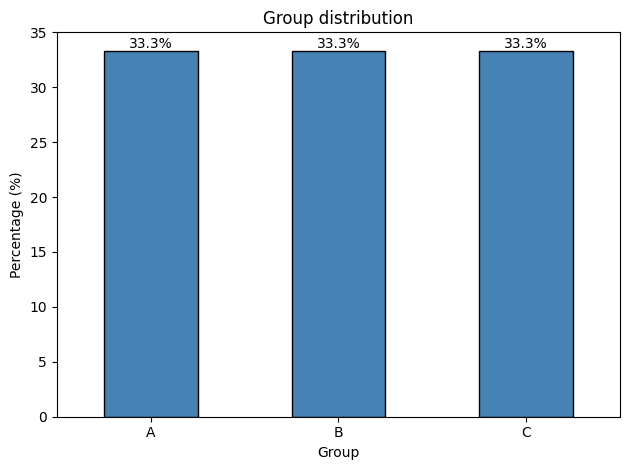

In [69]:
# EXAMPLE VALUES EXPLAINED: The percentage heights are computed from group counts;
# 100 converts proportions to percent. The numbers placed above bars are those
# computed percentages.
# REPLACE FOR YOUR QUESTION: Replace category variable and choice of
# count/proportion/percent. Colours and label positions are presentation settings.

# Count categories; normalize=True changes counts to proportions.
plot_values = df["group"].value_counts().sort_index() / len(df) * 100
ax = plot_values.plot.bar(color="steelblue", edgecolor="black", rot=0)
ax.set(xlabel="Group", ylabel="Percentage (%)", title="Group distribution")
for position, height in enumerate(plot_values):
    ax.text(position, height, f"{height:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()


<a id="PLOT-02"></a>
## PLOT-02 · Histogram: frequency versus bin probability versus density

**Search:** hist histogram bins probability density weights normalization frequency unequal bin width

**Use when:** Match the requested vertical scale. Probability per bin and density are different.

**Remember:** density=True does NOT make bar heights sum to 1. It divides bin probability by bin width. Include the entire intended data range in bins.


**Example values explained:** Histogram bins run from 50 to 100 in widths of 10; these are chosen to cover the demo scores. 1/len(values) gives each observation equal probability weight. The 1-by-3 subplot grid shows three different vertical scales.

**Replace for your question:** Replace data and bin range/width or count. Frequency, bin probability and density are different; density=True makes total AREA equal to 1.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `np.zeros((2,3))`<br>**OR**<br>`np.ones(3)`<br>**OR**<br>`np.full(3,7)` | shape gives dimensions; full also needs the value to repeat. (2,3) means two rows and three columns.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**shape / fill_value:** A nonnegative integer creates a 1D length; a tuple gives dimensions. full also needs a scalar fill_value.<br>**Examples:** np.zeros(5); np.ones((2,3)); np.full((2,3),7) | Returns an array filled with 0, 1 or the supplied value. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


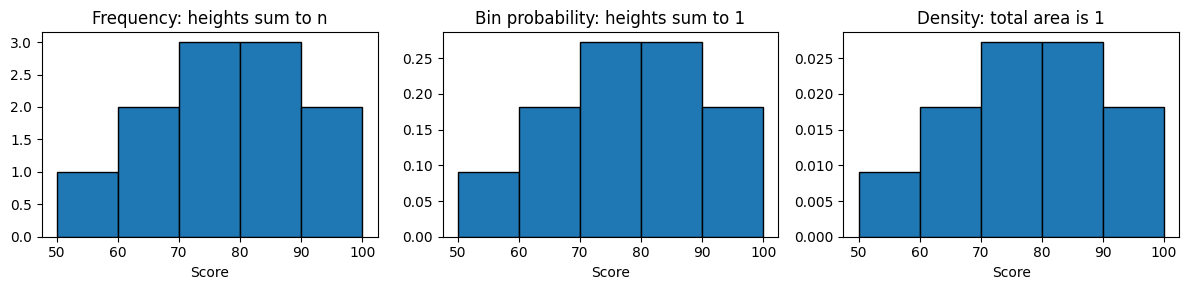

In [70]:
# EXAMPLE VALUES EXPLAINED: Histogram bins run from 50 to 100 in widths of 10; these
# are chosen to cover the demo scores. 1/len(values) gives each observation equal
# probability weight. The 1-by-3 subplot grid shows three different vertical scales.
# REPLACE FOR YOUR QUESTION: Replace data and bin range/width or count. Frequency,
# bin probability and density are different; density=True makes total AREA equal to
# 1.

# Return rows complete in the stated columns; save the returned table.
values = df["score"].dropna().to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
bins = np.arange(50, 101, 10)
axes[0].hist(values, bins=bins, edgecolor="black")
axes[0].set_title("Frequency: heights sum to n")
axes[1].hist(
    values, bins=bins, weights=np.ones(len(values)) / len(values), edgecolor="black"
)
axes[1].set_title("Bin probability: heights sum to 1")
axes[2].hist(values, bins=bins, density=True, edgecolor="black")
axes[2].set_title("Density: total area is 1")
for ax in axes:
    ax.set_xlabel("Score")
plt.tight_layout()
plt.show()


<a id="PLOT-03"></a>
## PLOT-03 · Single/grouped boxplots, horizontal orientation and fliers

**Search:** boxplot side by side horizontal outlier fliers labels category group

**Use when:** Compare a quantitative variable across groups and extract plotted outliers.


**Example values explained:** A/B/C are demo group labels. One box represents the observed scores from one group; fliers[0], etc. refer to box positions, not data values.

**Replace for your question:** Replace groups, label order and numeric outcome. Figure size/colours affect presentation; missing values are removed before drawing each box.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `course_boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Run SETUP-01 for the portable helper. Supply one numeric array per box; horizontal=True changes orientation. boxprops={"facecolor":"lightblue"} styles filled boxes.<br><br>**Parameter choices and examples:**<br><br>**horizontal / labels / patch_artist / boxprops:** horizontal=True gives horizontal boxes, False vertical. labels is one label per box or None. patch_artist=True enables filled patches, False lines. boxprops is a styling dictionary. **Default:** horizontal=False; patch_artist=False.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True,patch_artist=True,boxprops={"facecolor":"lightblue"}) | Returns artists; fliers contains flagged points. &#124;SR&#124;>3 regression outliers are a different rule from boxplot IQR fliers. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `artist.get_data()`<br>**OR**<br>`artist.get_ydata()` | Call on a plotted line, e.g. boxplot_result["fliers"][0]. | get_data returns x/y arrays; get_ydata returns y only. For a horizontal boxplot, observations are on x instead. |
| `for position,value in enumerate(items): ...` | Default first position is 0; start=1 changes numbering.<br><br>**Parameter choices and examples:**<br><br>**start:** Any integer starting index, usually 0 (Python positions) or 1 (human numbering). **Default:** 0.<br>**Examples:** enumerate(items); enumerate(items,start=1) | Yields an index/value pair each iteration; unpack both variables. |


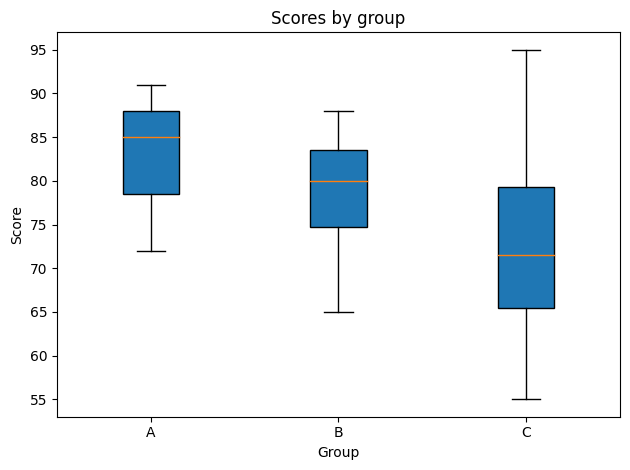

Outliers per group: {'A': [], 'B': [], 'C': []}


In [71]:
# EXAMPLE VALUES EXPLAINED: A/B/C are demo group labels. One box represents the
# observed scores from one group; fliers[0], etc. refer to box positions, not data
# values.
# REPLACE FOR YOUR QUESTION: Replace groups, label order and numeric outcome. Figure
# size/colours affect presentation; missing values are removed before drawing each
# box.

group_names = ["A", "B", "C"]
# Return rows complete in the stated columns; save the returned table.
group_values = [df.loc[df["group"].eq(g), "score"].dropna() for g in group_names]
plt.figure()
bp = course_boxplot(group_values, labels=group_names, patch_artist=True)
plt.xlabel("Group")
plt.ylabel("Score")
plt.title("Scores by group")
plt.tight_layout()
plt.show()
print(
    "Outliers per group:",
    {g: bp["fliers"][i].get_ydata().tolist() for i, g in enumerate(group_names)},
)


<a id="PLOT-04"></a>
## PLOT-04 · IQR outlier fences, inspect/remove and recompute correlation

**Search:** IQR outliers fences quartile 1.5 drop index remove correlation before after

**Use when:** Flag observations using a univariate IQR rule and compare results after exclusion.

**Remember:** Inspect flagged rows. Exclusion is appropriate when requested or justified, not simply because a point is unusual. Scatterplot outliers need not be univariate IQR outliers.


**Example values explained:** .25/.75 select Q1/Q3 and 1.5 is the conventional IQR fence multiplier. Bounds/outlier flags are computed from the selected sample.

**Replace for your question:** Replace sample/measurement and inspect flagged rows. Do not replace 1.5 by a random value or delete flagged rows without instructions/justification.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `r = first.corr(second,method="pearson")` | Pearson is default; method="spearman" uses ranks. Series align by index and pairwise remove missing values.<br><br>**Parameter choices and examples:**<br><br>**method:** "pearson" linear correlation; "spearman" rank correlation; "kendall" Kendall rank correlation; a compatible callable is also allowed. **Default:** "pearson".<br>**Examples:** data["x"].corr(data["y"],method="pearson"); data["x"].corr(data["y"],method="spearman") | Returns correlation; for a DataFrame .corr() returns the matrix. Preserve correct pairs. |


In [72]:
# EXAMPLE VALUES EXPLAINED: .25/.75 select Q1/Q3 and 1.5 is the conventional IQR
# fence multiplier. Bounds/outlier flags are computed from the selected sample.
# REPLACE FOR YOUR QUESTION: Replace sample/measurement and inspect flagged rows. Do
# not replace 1.5 by a random value or delete flagged rows without
# instructions/justification.

# Return rows complete in the stated columns; save the returned table.
s = df["score"].dropna()
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flag = df["score"].lt(low) | df["score"].gt(high)
display(df.loc[flag])
without_outliers = df.loc[~flag].copy()
print("Fences:", low, high)
print("Correlation before:", df["score"].corr(df["hours"]))
print("Correlation after:", without_outliers["score"].corr(without_outliers["hours"]))


,id,group,name,city,score,hours,income,passed,date,tags


Fences: 46.5 110.5
Correlation before: 0.9691881372277479
Correlation after: 0.9691881372277479


<a id="PLOT-05"></a>
## PLOT-05 · Scatterplot with category colours, legend and trend

**Search:** scatter explanatory response groups legend alpha marker size colours for loop

**Use when:** Explore two numeric variables, optionally distinguishing categories.


**Example values explained:** alpha=.7 controls dot opacity, not hypothesis-test significance. Each group gets a labelled set of points. Study hours are x and score is y in this example.

**Replace for your question:** Replace explanatory/response/group variables. Plot aesthetics do not establish statistical significance.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


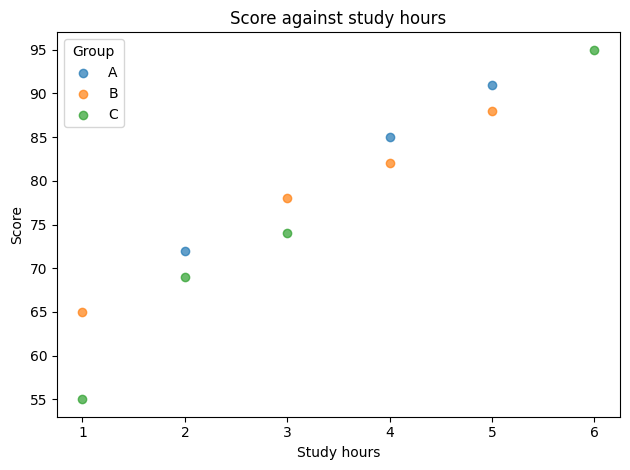

In [73]:
# EXAMPLE VALUES EXPLAINED: alpha=.7 controls dot opacity, not hypothesis-test
# significance. Each group gets a labelled set of points. Study hours are x and
# score is y in this example.
# REPLACE FOR YOUR QUESTION: Replace explanatory/response/group variables. Plot
# aesthetics do not establish statistical significance.

plt.figure()
# Choose groups first, then append the required summary or row-aligned transform.
for group, sub in df.groupby("group"):
    plt.scatter(sub["hours"], sub["score"], label=group, alpha=0.7)
plt.xlabel("Study hours")
plt.ylabel("Score")
plt.legend(title="Group")
plt.title("Score against study hours")
plt.tight_layout()
plt.show()


<a id="PLOT-06"></a>
## PLOT-06 · Clustered versus 100-percent stacked bars

**Search:** crosstab bar clustered grouped stacked conditional row percentages

**Use when:** Compare a categorical outcome across explanatory groups.


**Example values explained:** 100 converts each row's conditional proportions into percentages. The 1-by-2 grid shows clustered and stacked versions of the SAME table.

**Replace for your question:** Replace categorical variables and choose the correct conditioning denominator before plotting.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `tab = pd.crosstab(data["group"], data["outcome"], normalize="index")` | First variable forms rows, second columns. Omit normalize for counts; "index"=row, "columns"=column, "all"=overall proportions.<br><br>**Parameter choices and examples:**<br><br>**normalize:** False gives counts; True or "all" overall proportions; "index" (or 0) row proportions; "columns" (or 1) column proportions. **Default:** False.<br>**Examples:** pd.crosstab(a,b,normalize="index"); pd.crosstab(a,b,normalize="columns")<br><br>**margins / margins_name:** margins=True adds totals; False omits them. margins_name is any nonconflicting total label such as "Total". With normalisation, totals are normalised too. **Default:** margins=False; margins_name="All".<br>**Examples:** pd.crosstab(a,b,margins=True,margins_name="Total") | Returns a table. margins=True adds totals; multiply normalised proportions by 100 for percentages. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `ax.bar(positions,heights,width=.35)`<br>**OR**<br>`counts.plot.bar(rot=0)` | Manual bar uses x positions and heights; pandas plot.bar uses index labels and values. stacked=True stacks multiple series.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**width:** For plt.bar/ax.bar, a positive scalar or compatible array gives bar width in x-coordinate units. For pandas .plot.bar, width controls bar/group allocation.<br>**Examples:** ax.bar(positions,heights,width=.35); ax.bar(positions+.35,other_heights,width=.35)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Returns plot artists/Axes. Counts, proportions and percentages are different inputs; choose the intended denominator first. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


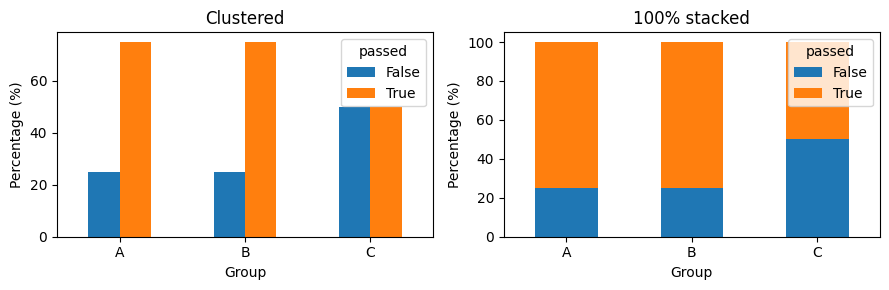

In [74]:
# EXAMPLE VALUES EXPLAINED: 100 converts each row's conditional proportions into
# percentages. The 1-by-2 grid shows clustered and stacked versions of the SAME
# table.
# REPLACE FOR YOUR QUESTION: Replace categorical variables and choose the correct
# conditioning denominator before plotting.

# Build a row-by-column table; normalization chooses the conditioning denominator.
percentages = pd.crosstab(df["group"], df["passed"], normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
percentages.plot.bar(ax=axes[0], stacked=False, rot=0)
percentages.plot.bar(ax=axes[1], stacked=True, rot=0)
for ax in axes:
    ax.set(ylabel="Percentage (%)", xlabel="Group")
axes[0].set_title("Clustered")
axes[1].set_title("100% stacked")
plt.tight_layout()
plt.show()


<a id="PLOT-07"></a>
## PLOT-07 · Probability mass/density curves, shading and cut-off lines

**Search:** plot pmf pdf density curve fill_between axvline axhline normal binomial probability shade

**Use when:** Plot a distribution and shade a probability area.


**Example values explained:** The example normal population has mean 80 and SD 12; 90 is the event cut-off. Four SDs either side and 400 grid points control the displayed curve, not the calculated tail probability.

**Replace for your question:** Replace distribution parameters/event cut-off from the question. The shaded area is probability; curve height is density.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `height = norm.pdf(x,loc=mu,scale=sigma)` | x can be one point or a plotting grid; scale is population SD.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns density HEIGHT, not probability. Use cdf differences or sf for areas. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `plt.fill_between(grid,density,where=grid>=cutoff,alpha=.4)` | x grid and y heights must align; where chooses the shaded positions.<br><br>**Parameter choices and examples:**<br><br>**where / alpha:** where is a matching Boolean mask selecting shaded grid positions; None shades all. alpha in [0,1] controls opacity.<br>**Examples:** plt.fill_between(grid,density,where=grid>=cutoff,alpha=.4) | Shades a region; it does not calculate its probability. Use cdf/sf for the numerical area. |
| `plt.axhline(0)`<br>**OR**<br>`plt.axvline(cutoff)` | axhline takes a y value, axvline an x value; color/linestyle are display settings.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Adds a reference line to the current axes; use ax.axhline/axvline for a chosen subplot. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


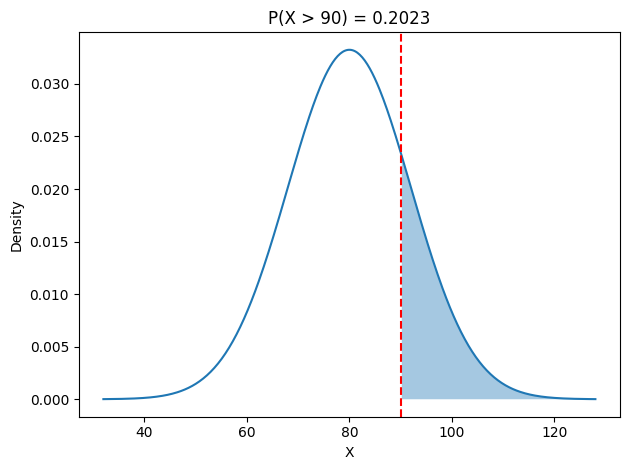

In [75]:
# EXAMPLE VALUES EXPLAINED: The example normal population has mean 80 and SD 12; 90
# is the event cut-off. Four SDs either side and 400 grid points control the
# displayed curve, not the calculated tail probability.
# REPLACE FOR YOUR QUESTION: Replace distribution parameters/event cut-off from the
# question. The shaded area is probability; curve height is density.

# Question input: population mean for this example.
mu = 80
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 12
# Example event/filter threshold; replace with the requested value.
cutoff = 90
grid = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
density = norm.pdf(grid, loc=mu, scale=sigma)
plt.figure()
plt.plot(grid, density)
plt.fill_between(grid, density, where=grid >= cutoff, alpha=0.4)
plt.axvline(cutoff, color="red", linestyle="--")
plt.xlabel("X")
plt.ylabel("Density")
plt.title(f"P(X > {cutoff}) = {norm.sf(cutoff,mu,sigma):.4f}")
plt.tight_layout()
plt.show()


<a id="PLOT-08"></a>
## PLOT-08 · QQ plot, histogram and Shapiro-Wilk normality test

**Search:** normality QQ probplot shapiro histogram assumptions pvalue

**Use when:** Assess approximate normality of a sample or paired differences.

**Remember:** Shapiro H0: normality. A large p-value is insufficient evidence against normality; it does not prove normality. For paired tests assess differences; for regression assess residuals.


**Example values explained:** The sample is the demo score column. The 1-by-2 grid displays its histogram and normal QQ plot. Shapiro computes its statistic and p-value from those observations.

**Replace for your question:** Replace the sample, paired differences or residuals being assessed. The check is on the relevant quantity, not automatically every raw column.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `probplot(values,dist="norm",plot=plt)` | Use the relevant sample/differences/residuals. plot can be plt or an Axes from subplots.<br><br>**Parameter choices and examples:**<br><br>**dist / plot:** dist="norm" is the course normal QQ comparison; another supported scipy distribution can be specified for a different theoretical reference. plot=plt or an Axes draws a graph; plot=None returns calculations only. **Default:** dist="norm"; plot=None.<br>**Examples:** probplot(x,dist="norm",plot=plt); probplot(x,dist="norm",plot=axes[1]) | Draws a QQ plot when plot is supplied and returns plotting quantities. Approximate straightness supports normality. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `res = shapiro(values)` | Use the relevant data: paired differences for paired t, residuals for regression; remove missing values first. | Returns statistic/pvalue for H0 normality. Small p is evidence against normality; large p is not proof. |


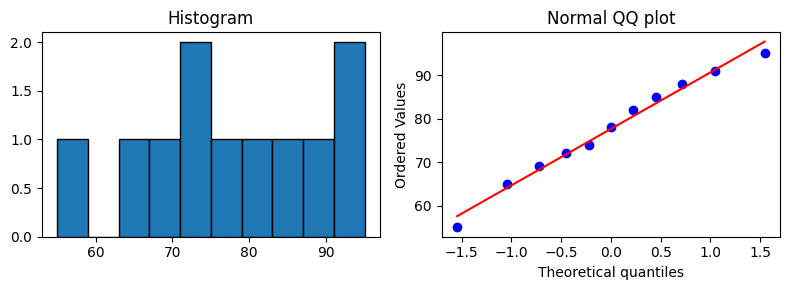

Shapiro statistic: 0.9803041815757751 | p-value: 0.9678304195404053


In [76]:
# EXAMPLE VALUES EXPLAINED: The sample is the demo score column. The 1-by-2 grid
# displays its histogram and normal QQ plot. Shapiro computes its statistic and
# p-value from those observations.
# REPLACE FOR YOUR QUESTION: Replace the sample, paired differences or residuals
# being assessed. The check is on the relevant quantity, not automatically every raw
# column.

# Return rows complete in the stated columns; save the returned table.
values = df["score"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].hist(values, edgecolor="black")
axes[0].set_title("Histogram")
probplot(values, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ plot")
plt.tight_layout()
plt.show()
sw = shapiro(values)
print("Shapiro statistic:", sw.statistic, "| p-value:", sw.pvalue)


<a id="probability"></a>
# 08 · Probability, random variables and distribution variations

Translate the event first, then choose pmf/cdf/sf/ppf. scipy norm scale is SD, never variance. Probability distributions below are course-scope unless noted.


<a id="PROB-01"></a>
## PROB-01 · Binomial exact probabilities: every inequality and interval

**Search:** binomial binom pmf cdf sf exactly at least at most fewer more between inclusive exclusive

**Use when:** Count successes in n independent trials with constant success probability p.

**Remember:** These ±1 rules assume integer a,b,k. For a real threshold c, X≥c means X≥ceil(c), while X>c means X≥floor(c)+1.


**Example values explained:** n=20 is the number of trials, p=.3 the per-trial success probability, k=5 a count cut-off, and a=3,b=8 interval boundaries. Every printed line is a different event on the same binomial variable.

**Replace for your question:** Replace n,p,k,a,b with the question's values. The ±1 adjustments are REQUIRED by strict/inclusive integer boundaries.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `probability = binom.pmf(k,n,p)` | k is a success count, n fixed trials, p per-trial success probability.<br><br>**Parameter choices and examples:**<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns P(X=k), the exact point probability of a discrete binomial count. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [77]:
# EXAMPLE VALUES EXPLAINED: n=20 is the number of trials, p=.3 the per-trial success
# probability, k=5 a count cut-off, and a=3,b=8 interval boundaries. Every printed
# line is a different event on the same binomial variable.
# REPLACE FOR YOUR QUESTION: Replace n,p,k,a,b with the question's values. The ±1
# adjustments are REQUIRED by strict/inclusive integer boundaries.

# Question input: number of observations/trials in this sample.
n = 20
# Question input: probability of success on EACH trial.
p = 0.3
# Question input: event count cut-off.
k = 5
# Question input: lower count boundary.
a = 3
# Question input: upper count boundary.
b = 8
print("P(X=k):", binom.pmf(k, n, p))
print("P(X<=k):", binom.cdf(k, n, p))
print("P(X<k):", binom.cdf(k - 1, n, p))
print("P(X>=k):", binom.sf(k - 1, n, p))
print("P(X>k):", binom.sf(k, n, p))
print("P(a<=X<=b):", binom.cdf(b, n, p) - binom.cdf(a - 1, n, p))
print("P(a<X<b):", binom.cdf(b - 1, n, p) - binom.cdf(a, n, p))
print("P(a<X<=b):", binom.cdf(b, n, p) - binom.cdf(a, n, p))
print("P(a<=X<b):", binom.cdf(b - 1, n, p) - binom.cdf(a - 1, n, p))
print("Mean, variance, SD:", n * p, n * p * (1 - p), np.sqrt(n * p * (1 - p)))


P(X=k): 0.17886305056987964
P(X<=k): 0.4163708294474809
P(X<k): 0.23750777887760136
P(X>=k): 0.7624922211223987
P(X>k): 0.5836291705525192
P(a<=X<=b): 0.8511854048245531
P(a<X<b): 0.6651849929144299
P(a<X<=b): 0.7795817326192909
P(a<=X<b): 0.7367886651196921
Mean, variance, SD: 6.0 4.199999999999999 2.0493901531919194


<a id="PROB-02"></a>
## PROB-02 · Normal probabilities, standardisation and quantiles

**Search:** normal norm cdf sf ppf percentile quantile cutoff top bottom central interval zscore

**Use when:** Find tail/interval probabilities or invert a given probability to obtain a cut-off.

**Remember:** For a continuous normal variable, < and ≤ have the same probability. pdf(x) is a density height, not P(X=x).


**Example values explained:** mu=80 and sigma=12 define the normal distribution; a=60 and b=90 are example event limits. .10/.90 request bottom/top 10% cut-offs; [.025,.975] gives a central 95% interval.

**Replace for your question:** Replace mean, SD, event limits and percentile probabilities. If supplied variance, take its square root for scale.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |


In [78]:
# EXAMPLE VALUES EXPLAINED: mu=80 and sigma=12 define the normal distribution; a=60
# and b=90 are example event limits. .10/.90 request bottom/top 10% cut-offs;
# [.025,.975] gives a central 95% interval.
# REPLACE FOR YOUR QUESTION: Replace mean, SD, event limits and percentile
# probabilities. If supplied variance, take its square root for scale.

# Question input: population mean for this example.
mu = 80
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 12
# Question input: lower event limit in the original measurement units.
a = 60
# Question input: upper event limit in the original measurement units.
b = 90
print("Below a:", norm.cdf(a, loc=mu, scale=sigma))
print("Above b:", norm.sf(b, loc=mu, scale=sigma))
print("Between:", norm.cdf(b, mu, sigma) - norm.cdf(a, mu, sigma))
print("Outside:", norm.cdf(a, mu, sigma) + norm.sf(b, mu, sigma))
print("Bottom 10% cutoff:", norm.ppf(0.10, mu, sigma))
print("Top 10% cutoff:", norm.ppf(0.90, mu, sigma))
print("Central 95% interval:", norm.ppf([0.025, 0.975], mu, sigma))
print("Standardised a:", (a - mu) / sigma)


Below a: 0.0477903522728147
Above b: 0.20232838096364308
Between: 0.7498812667635422
Outside: 0.2501187332364578
Bottom 10% cutoff: 64.6213812134648
Top 10% cutoff: 95.3786187865352
Central 95% interval: [ 56.48043219 103.51956781]
Standardised a: -1.6666666666666667


<a id="PROB-03"></a>
## PROB-03 · Custom discrete distribution, moments and transformations

**Search:** discrete distribution expected value expectation variance mean weighted probabilities transformation profit sum

**Use when:** Compute moments from a supplied probability table.


**Example values explained:** values=[0,1,2,3,4] lists possible outcomes; probs lists their matching probabilities, not frequencies. a=-2,b=10 define the example transformation Y=-2X+10. 2 in the last filter is an example outcome cut-off.

**Replace for your question:** Replace outcome values, paired probabilities and transformation coefficients. Probabilities must be between 0 and 1 and sum to 1; variance multiplies by a² and SD by abs(a).

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [79]:
# EXAMPLE VALUES EXPLAINED: values=[0,1,2,3,4] lists possible outcomes; probs lists
# their matching probabilities, not frequencies. a=-2,b=10 define the example
# transformation Y=-2X+10. 2 in the last filter is an example outcome cut-off.
# REPLACE FOR YOUR QUESTION: Replace outcome values, paired probabilities and
# transformation coefficients. Probabilities must be between 0 and 1 and sum to 1;
# variance multiplies by a² and SD by abs(a).

values = np.array([0, 1, 2, 3, 4], dtype=float)
probs = np.array([0.15, 0.35, 0.25, 0.15, 0.10])
# Approximate equality; with rtol=0, atol is the entire allowed absolute difference.
assert (probs >= 0).all() and (probs <= 1).all() and np.isclose(probs.sum(), 1)
mu = np.sum(values * probs)
variance = np.sum((values - mu) ** 2 * probs)
print("E(X), Var(X), SD(X):", mu, variance, np.sqrt(variance))
# Question input: multiplier in Y = a*X + b.
a = -2
# Question input: additive constant in Y = a*X + b.
b = 10
print(
    "Y=aX+b: mean, variance, SD:",
    a * mu + b,
    a * a * variance,
    abs(a) * np.sqrt(variance),
)
print("P(X>=2):", probs[values >= 2].sum())


E(X), Var(X), SD(X): 1.6999999999999997 1.4100000000000001 1.1874342087037917
Y=aX+b: mean, variance, SD: 6.6000000000000005 5.640000000000001 2.3748684174075834
P(X>=2): 0.5


<a id="PROB-04"></a>
## PROB-04 · Independent sums/differences and weighted averages

**Search:** normal sum difference linear combination independent variance add subtract probability weighted mean

**Use when:** Find the distribution/probability of aX+bY+c for independent normal variables.

**Remember:** Variances add for independent differences too. Without independence add 2abCov(X,Y). A normal sum/difference is exactly normal here because both inputs are normal and independent.


**Example values explained:** Both example variables have mean 200 and SD 20. a=-1,b=1,c=0 define -X+Y+0, and 30 is the threshold in P(Y-X>30).

**Replace for your question:** Replace both variables' means/SDs, coefficients and event threshold. Squaring coefficients in the variance formula is a mathematical requirement.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |


In [80]:
# EXAMPLE VALUES EXPLAINED: Both example variables have mean 200 and SD 20.
# a=-1,b=1,c=0 define -X+Y+0, and 30 is the threshold in P(Y-X>30).
# REPLACE FOR YOUR QUESTION: Replace both variables' means/SDs, coefficients and
# event threshold. Squaring coefficients in the variance formula is a mathematical
# requirement.

# Question input: population mean of X.
mu_x = 200
# Question input: population STANDARD DEVIATION of X.
sd_x = 20
# Question input: population mean of Y.
mu_y = 200
# Question input: population STANDARD DEVIATION of Y.
sd_y = 20
# Question input: coefficient of X in a*X + b*Y + c.
a = -1
# Question input: coefficient of Y in a*X + b*Y + c.
b = 1
# Question input: additive constant in a*X + b*Y + c.
c = 0  # Y-X
mu_combined = a * mu_x + b * mu_y + c
var_combined = a * a * sd_x**2 + b * b * sd_y**2
sd_combined = np.sqrt(var_combined)
print("Mean, SD:", mu_combined, sd_combined)
print("P(Y-X>30):", norm.sf(30, mu_combined, sd_combined))


Mean, SD: 0 28.284271247461902
P(Y-X>30): 0.14442218317324246


<a id="PROB-05"></a>
## PROB-05 · Bayes, sensitivity/specificity, positive/negative predictive values

**Search:** Bayes screening diagnostic prevalence sensitivity specificity PPV NPV false positive negative conditional

**Use when:** Translate screening rates to conditional probabilities and reverse conditioning.


**Example values explained:** prev=.01 means 1% prevalence; sens=.96 means P(positive|disease)=96%; spec=.95 means P(negative|no disease)=95%. Table cells are JOINT probabilities computed from these inputs.

**Replace for your question:** Replace the three screening rates. The denominators for reversed probabilities are total positive/negative probability, not total prevalence.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |


In [81]:
# EXAMPLE VALUES EXPLAINED: prev=.01 means 1% prevalence; sens=.96 means
# P(positive|disease)=96%; spec=.95 means P(negative|no disease)=95%. Table cells
# are JOINT probabilities computed from these inputs.
# REPLACE FOR YOUR QUESTION: Replace the three screening rates. The denominators for
# reversed probabilities are total positive/negative probability, not total
# prevalence.

# Question input: prevalence P(disease), as a proportion.
prev = 0.01
# Question input: sensitivity P(positive | disease).
sens = 0.96
# Question input: specificity P(negative | no disease).
spec = 0.95
tp = prev * sens
fn = prev * (1 - sens)
fp = (1 - prev) * (1 - spec)
tn = (1 - prev) * spec
p_pos = tp + fp
p_neg = fn + tn
print("P(+), P(-):", p_pos, p_neg)
print("P(D|+):", tp / p_pos, "| P(no D|-):", tn / p_neg)
print("P(D|-):", fn / p_neg, "| P(no D|+):", fp / p_pos)
display(
    pd.DataFrame(
        [
            [tp, fn],  # Disease: Positive, Negative
            [fp, tn],  # No disease: Positive, Negative
        ],
        index=["Disease", "No disease"],
        columns=["Positive", "Negative"],
    )
)


P(+), P(-): 0.05910000000000004 0.9409
P(D|+): 0.16243654822335013 | P(no D|-): 0.9995748751195664
P(D|-): 0.0004251248804336278 | P(no D|+): 0.8375634517766499


,Positive,Negative
Disease,0.0096,0.0004
No disease,0.0495,0.9405


<a id="PROB-06"></a>
## PROB-06 · Screening cut-off from sensitivity or specificity

**Search:** normal screening cutoff sensitivity specificity threshold diabetes healthy diseased ppf

**Use when:** A positive result means X>=C; obtain C from the desired detection rate.

**Remember:** If positive means X<=C instead, reverse tails: sensitivity uses cdf and specificity uses sf.


**Example values explained:** Healthy glucose: mean 5.31, SD .58; disease glucose: mean 11.74, SD 3.50. 6.5 is a chosen positive-test threshold; .98 and .95 are example target sensitivity/specificity.

**Replace for your question:** Replace group distribution parameters, cut-off and requested target rate. All rates are proportions between 0 and 1.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |


In [82]:
# EXAMPLE VALUES EXPLAINED: Healthy glucose: mean 5.31, SD .58; disease glucose:
# mean 11.74, SD 3.50. 6.5 is a chosen positive-test threshold; .98 and .95 are
# example target sensitivity/specificity.
# REPLACE FOR YOUR QUESTION: Replace group distribution parameters, cut-off and
# requested target rate. All rates are proportions between 0 and 1.

# Question input: population mean glucose in the healthy group.
mu_h = 5.31
# Question input: POPULATION SD of glucose in the healthy group.
sd_h = 0.58
# Question input: population mean glucose in the disease group.
mu_d = 11.74
# Question input: POPULATION SD of glucose in the disease group.
sd_d = 3.50
# Example event/filter threshold; replace with the requested value.
cutoff = 6.5
print(
    "Sensitivity:",
    norm.sf(cutoff, mu_d, sd_d),
    "Specificity:",
    norm.cdf(cutoff, mu_h, sd_h),
)
target_sensitivity = 0.98
C_sens = norm.ppf(1 - target_sensitivity, mu_d, sd_d)
print(
    "Cutoff for sensitivity .98:", C_sens, "specificity:", norm.cdf(C_sens, mu_h, sd_h)
)
target_specificity = 0.95
C_spec = norm.ppf(target_specificity, mu_h, sd_h)
print(
    "Cutoff for specificity .95:", C_spec, "sensitivity:", norm.sf(C_spec, mu_d, sd_d)
)


Sensitivity: 0.9328219548640079 Specificity: 0.9799017602299771
Cutoff for sensitivity .98: 4.551878812788622 specificity: 0.09558844262223931
Cutoff for specificity .95: 6.264015103631854 sensitivity: 0.9411577774665217


<a id="PROB-07"></a>
## PROB-07 · Normal approximation with all continuity corrections

**Search:** binomial normal approximation continuity correction half 0.5 inclusive exclusive

**Use when:** The question requests a normal approximation to an integer binomial count.

**Remember:** Use the exact binomial when requested; do not automatically replace the course method with an approximation.


**Example values explained:** n=200,p=.2 define the binomial; k=45 is an event cut-off and a=30,b=50 an interval. .5 is the HALF-UNIT continuity correction; 5 is the course approximation-check threshold.

**Replace for your question:** Replace distribution/event inputs. Keep the correct +/-.5 boundary correction for the requested integer event.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |


In [83]:
# EXAMPLE VALUES EXPLAINED: n=200,p=.2 define the binomial; k=45 is an event cut-off
# and a=30,b=50 an interval. .5 is the HALF-UNIT continuity correction; 5 is the
# course approximation-check threshold.
# REPLACE FOR YOUR QUESTION: Replace distribution/event inputs. Keep the correct
# +/-.5 boundary correction for the requested integer event.

# Question input: number of observations/trials in this sample.
n = 200
p = 0.2
k = 45
a = 30
b = 50
mu, sd = n * p, np.sqrt(n * p * (1 - p))
print("Course validity check np(1-p)>=5:", n * p * (1 - p) >= 5)
print("P(X<=k) approx:", norm.cdf(k + 0.5, mu, sd))
print("P(X<k) approx:", norm.cdf(k - 0.5, mu, sd))
print("P(X>=k) approx:", norm.sf(k - 0.5, mu, sd))
print("P(X>k) approx:", norm.sf(k + 0.5, mu, sd))
print("P(X=k) approx:", norm.cdf(k + 0.5, mu, sd) - norm.cdf(k - 0.5, mu, sd))
print("P(a<=X<=b) approx:", norm.cdf(b + 0.5, mu, sd) - norm.cdf(a - 0.5, mu, sd))
print("Exact P(X<=k):", binom.cdf(k, n, p))


Course validity check np(1-p)>=5: True
P(X<=k) approx: 0.8345423314430407
P(X<k) approx: 0.786837228307796
P(X>=k) approx: 0.213162771692204
P(X>k) approx: 0.16545766855695937
P(X=k) approx: 0.047705103135244675
P(a<=X<=b) approx: 0.9365685747113888
Exact P(X<=k): 0.8348824711532761


<a id="PROB-08"></a>
## PROB-08 · Conditional probabilities and relative risk from table counts

**Search:** contingency probability conditional union intersection complement independent relative risk risk difference

**Use when:** Calculate probabilities from a supplied two-way count table.


**Example values explained:** 30 exercise AND have high stress; 70 exercise AND do not have high stress; 60 do not exercise AND have high stress; 40 do not exercise AND do not have high stress. A means Exercise and B means High stress.

**Replace for your question:** Replace the FOUR CELL COUNTS and their matching row/column labels. These are people counts, not probabilities or universal constants. Every denominator is computed from the table.

**Read this table before using the template:** `A = Exercise`, `B = High stress`. The four numbers are **people counts**:

| | High stress (B) | Not high stress (not B) | Row total |
|---|---:|---:|---:|
| Exercise (A) | 30 | 70 | 100 |
| No exercise (not A) | 60 | 40 | 100 |
| Column total | 90 | 110 | 200 |

For example, `P(A and B) = 30/200`, `P(B given A) = 30/100`, and `P(A given B) = 30/90`. Relative risk compares the high-stress proportions **within** the exercise and no-exercise rows: `(30/100)/(60/100)`. Replace the counts and labels together; the code calculates all totals.


### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |


In [84]:
# EXAMPLE VALUES EXPLAINED: 30 exercise AND have high stress; 70 exercise AND do not
# have high stress; 60 do not exercise AND have high stress; 40 do not exercise AND
# do not have high stress. A means Exercise and B means High stress.
# REPLACE FOR YOUR QUESTION: Replace the FOUR CELL COUNTS and their matching
# row/column labels. These are people counts, not probabilities or universal
# constants. Every denominator is computed from the table.

# EVENTS: A = person exercises; B = high stress.
tab = pd.DataFrame(
    [
        [30, 70],  # Exercise: High stress, Not high
        [60, 40],  # No exercise: High stress, Not high
    ],
    index=["Exercise", "No exercise"],
    columns=["High stress", "Not high"],
)
total = tab.to_numpy().sum()
p_A = tab.loc["Exercise"].sum() / total
p_B = tab["High stress"].sum() / total
p_AB = tab.loc["Exercise", "High stress"] / total
p_B_given_A = tab.loc["Exercise", "High stress"] / tab.loc["Exercise"].sum()
p_B_given_notA = tab.loc["No exercise", "High stress"] / tab.loc["No exercise"].sum()
print("P(A), P(B), P(A and B):", p_A, p_B, p_AB)
print("P(A or B):", p_A + p_B - p_AB, "| P(not A):", 1 - p_A)
print("P(A|B):", p_AB / p_B, "| P(B|A):", p_B_given_A)
# Approximate equality; with rtol=0, atol is the entire allowed absolute difference.
print("Independent?", np.isclose(p_AB, p_A * p_B))
print(
    "RR:",
    p_B_given_A / p_B_given_notA,
    "Risk difference:",
    p_B_given_A - p_B_given_notA,
)


P(A), P(B), P(A and B): 0.5 0.45 0.15
P(A or B): 0.7999999999999999 | P(not A): 0.5
P(A|B): 0.3333333333333333 | P(B|A): 0.3
Independent? False
RR: 0.5 Risk difference: -0.3


<a id="PROB-10"></a>
## PROB-10 · Total probability and Bayes for two or many sources

**Search:** Bayes supplier source machine mixture total probability prior posterior defective weighted sum partition

**Use when:** You know source proportions and the conditional probability of an outcome within each source.

**Remember:** Keep the source ordering identical in the labels, priors and conditional rates. Use two entries for two sources; the same pattern works with more.

**Change these inputs:** source_labels, source_priors and outcome_rates from the question; rates must be probabilities between 0 and 1.

**Read these outputs:** overall_outcome_probability is the total-probability result. The selected posterior_given_outcome entry answers the reversed conditional probability.


**Example values explained:** Source shares [.5,.3,.2] mean 50%,30%,20% of items originate from X/Y/Z. Conditional rates [.01,.04,.02] mean 1%,4%,2% outcome probability within those sources, in the same order.

**Replace for your question:** Replace source names/shares/rates together; use two entries for two sources. The posterior is a computed reverse conditional probability, not an entered prior.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |


In [85]:
# EXAMPLE VALUES EXPLAINED: Source shares [.5,.3,.2] mean 50%,30%,20% of items
# originate from X/Y/Z. Conditional rates [.01,.04,.02] mean 1%,4%,2% outcome
# probability within those sources, in the same order.
# REPLACE FOR YOUR QUESTION: Replace source names/shares/rates together; use two
# entries for two sources. The posterior is a computed reverse conditional
# probability, not an entered prior.

source_labels = np.array(["Source X", "Source Y", "Source Z"])
source_priors = np.array([0.5, 0.3, 0.2])
outcome_rates = np.array([0.01, 0.04, 0.02])  # P(outcome | source)
# Approximate equality; with rtol=0, atol is the entire allowed absolute difference.
if (
    not np.isclose(source_priors.sum(), 1)
    or not ((source_priors >= 0) & (source_priors <= 1)).all()
):
    raise ValueError("Source probabilities must sum to 1.")
joint_probabilities = source_priors * outcome_rates
overall_outcome_probability = joint_probabilities.sum()
if overall_outcome_probability <= 0:
    raise ValueError("Conditioning requires positive outcome probability.")
posterior_given_outcome = joint_probabilities / overall_outcome_probability
display(
    pd.DataFrame(
        {
            "prior": source_priors,
            "conditional_outcome_rate": outcome_rates,
            "joint_probability": joint_probabilities,
            "posterior_given_outcome": posterior_given_outcome,
        },
        index=source_labels,
    )
)
print("Overall outcome probability:", overall_outcome_probability)


,prior,conditional_outcome_rate,joint_probability,posterior_given_outcome
Source X,0.5,0.01,0.005,0.238095
Source Y,0.3,0.04,0.012,0.571429
Source Z,0.2,0.02,0.004,0.190476


Overall outcome probability: 0.021


<a id="PROB-11"></a>
## PROB-11 · Events, conditional probability and relative risk directly from raw rows

**Search:** empirical raw data event boolean mask conditional probability given union intersection neither exactly one relative risk crosstab denominator missing

**Use when:** Each row is an observation and the question defines events using column values; avoid entering a table by hand.

**Remember:** These are sample proportions, not proof of population independence or a causal effect. Drop missing values only in the event-defining columns; any subgroup filter goes before BOTH masks. A zero conditioning count makes the conditional probability undefined. The RR output is NaN when the comparison risk is zero rather than a finite ratio.

**Change these inputs:** The raw DataFrame, event-defining columns, subgroup filter if any, and the comparisons defining A and B.

**Read these outputs:** A labelled computed count table, marginal/joint/conditional proportions, risk difference and relative risk. OR includes the overlap; XOR means exactly one.


**Example values explained:** The observations come from the small SETUP-01 table. A means group equals A; B means passed is True. True/False define events rather than numeric measurements. The four table cells and every probability are computed from the SAME complete rows.

**Replace for your question:** Replace df, event-defining columns and the comparisons defining A/B. If a subgroup is requested, filter first. Do not manually enter sample counts or treat missing outcomes as failures.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `s.reindex(["A", "B", "C"], fill_value=0)` | Supply required label order. DataFrames accept index=... and columns=... separately.<br><br>**Parameter choices and examples:**<br><br>**index / columns / fill_value:** index/columns are ordered required labels; labels not supplied are removed, new labels added. fill_value may be 0, another scalar, or missing (default); existing NaNs are not filled.<br>**Examples:** s.reindex(["A","B","C"],fill_value=0); data.reindex(columns=["score","hours"]) | Reorders/adds labels. fill_value fills newly introduced labels; it does not replace existing NaNs. |
| `tab = pd.crosstab(data["group"], data["outcome"], normalize="index")` | First variable forms rows, second columns. Omit normalize for counts; "index"=row, "columns"=column, "all"=overall proportions.<br><br>**Parameter choices and examples:**<br><br>**normalize:** False gives counts; True or "all" overall proportions; "index" (or 0) row proportions; "columns" (or 1) column proportions. **Default:** False.<br>**Examples:** pd.crosstab(a,b,normalize="index"); pd.crosstab(a,b,normalize="columns")<br><br>**margins / margins_name:** margins=True adds totals; False omits them. margins_name is any nonconflicting total label such as "Total". With normalisation, totals are normalised too. **Default:** margins=False; margins_name="All".<br>**Examples:** pd.crosstab(a,b,margins=True,margins_name="Total") | Returns a table. margins=True adds totals; multiply normalised proportions by 100 for percentages. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `prob = empirical_conditional(event_B,event_A)` | Run PROB-11 first. Both arguments are Boolean masks for the same rows; the SECOND argument is the conditioning event. | Returns P(B given A)=(B&A).sum()/A.sum(); returns NaN if no observations satisfy A. |


In [86]:
# EXAMPLE VALUES EXPLAINED: The observations come from the small SETUP-01 table. A
# means group equals A; B means passed is True. True/False define events rather than
# numeric measurements. The four table cells and every probability are computed from
# the SAME complete rows.
# REPLACE FOR YOUR QUESTION: Replace df, event-defining columns and the comparisons
# defining A/B. If a subgroup is requested, filter first. Do not manually enter
# sample counts or treat missing outcomes as failures.

# Return rows complete in the stated columns; save the returned table.
event_data = df[["group", "passed"]].dropna().copy()
if event_data.empty:
    raise ValueError("No complete observations for the two events.")
event_A = event_data["group"].eq("A")
event_B = event_data["passed"].eq(True)
# Build a row-by-column table; normalization chooses the conditioning denominator.
event_table = (
    pd.crosstab(event_A, event_B)
    .reindex(index=[True, False], columns=[True, False], fill_value=0)
    .rename(
        index={
            True: "A",
            False: "not A",
        },
        columns={
            True: "B",
            False: "not B",
        },
    )
)
display(event_table)
print("Sample size:", len(event_data))
# Average values; for a Boolean mask this gives the True proportion.
print("P(A), P(B):", event_A.mean(), event_B.mean())
print("P(A and B):", (event_A & event_B).mean())
print("P(A or B):", (event_A | event_B).mean())
print("P(neither):", (~event_A & ~event_B).mean())
print("P(exactly one):", (event_A ^ event_B).mean())


def empirical_conditional(event, given):
    # Both masks must refer to the same rows, with matching index labels.
    denominator = given.sum()
    return (event & given).sum() / denominator if denominator else np.nan


risk_A = empirical_conditional(event_B, event_A)
risk_not_A = empirical_conditional(event_B, ~event_A)
print("P(B|A):", risk_A, "| P(A|B):", empirical_conditional(event_A, event_B))
print("P(B|not A):", risk_not_A)
print("Risk difference:", risk_A - risk_not_A)
print("Relative risk:", risk_A / risk_not_A if risk_not_A > 0 else np.nan)


passed,B,not B
group,,
A,3,1
not A,5,3


Sample size: 12
P(A), P(B): 0.3333333333333333 0.6666666666666666
P(A and B): 0.25
P(A or B): 0.75
P(neither): 0.25
P(exactly one): 0.5
P(B|A): 0.75 | P(A|B): 0.375
P(B|not A): 0.625
Risk difference: 0.125
Relative risk: 1.2


<a id="sampling"></a>
# 09 · Sampling distributions, CLT and simulation

n is sample size; N is the number of repetitions. Increasing n changes the sampling distribution; increasing N only improves the simulation approximation.


<a id="SIM-01"></a>
## SIM-01 · Probability for one observation versus a sample mean

**Search:** sampling distribution sample mean observation standard error sigma sqrt n CLT probability

**Use when:** Choose between SD of X and SD of the sample mean.

**Remember:** The exact mean/SE formulas require independent observations with common finite variance. CLT gives approximate normality for sufficiently large n; n>=30 is a course rule of thumb, not a universal guarantee.


**Example values explained:** mu=2.8 is the population mean, sigma=2.1 its SD, n=45 the sample size and 3.5 an event cut-off for X or the sample mean. .1 is a TARGET maximum standard error.

**Replace for your question:** Replace population parameters, n, event cut-off and target SE. sigma/sqrt(n) is the sample-mean SD, not the individual-observation SD.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [87]:
# EXAMPLE VALUES EXPLAINED: mu=2.8 is the population mean, sigma=2.1 its SD, n=45
# the sample size and 3.5 an event cut-off for X or the sample mean. .1 is a TARGET
# maximum standard error.
# REPLACE FOR YOUR QUESTION: Replace population parameters, n, event cut-off and
# target SE. sigma/sqrt(n) is the sample-mean SD, not the individual-observation SD.

# Question input: population mean for this example.
mu = 2.8
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 2.1
# Question input: number of observations/trials in this sample.
n = 45
# Example event/filter threshold; replace with the requested value.
cutoff = 3.5
se = sigma / np.sqrt(n)
print("P(X>3.5), if individual X is normal:", norm.sf(cutoff, mu, sigma))
print("P(sample mean>3.5), exact if X normal / CLT otherwise:", norm.sf(cutoff, mu, se))
print("SE:", se, "| Minimum n for SE<=.1:", math.ceil((sigma / 0.1) ** 2))


P(X>3.5), if individual X is normal: 0.3694413401817636
P(sample mean>3.5), exact if X normal / CLT otherwise: 0.012673659338734105
SE: 0.31304951684997057 | Minimum n for SE<=.1: 441


<a id="SIM-02"></a>
## SIM-02 · Sample proportions: approximate probability and exact count boundary

**Search:** sampling proportion phat p_hat binomial mean standard error threshold count ceil floor

**Use when:** Convert an event about a proportion into an event about an integer success count.

**Remember:** Use the approximation specified in the question. When applying continuity correction, correct the count boundary then divide by n if working on the proportion scale.


**Example values explained:** n=500 is sample size, p=.04 the true population success proportion, and c=.05 the sample-proportion threshold. Count thresholds are calculated as ceil(n*c) or floor(n*c)+1.

**Replace for your question:** Replace n,p,c. Rounding in count conversion implements the event boundary; it is not final-answer rounding.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [88]:
# EXAMPLE VALUES EXPLAINED: n=500 is sample size, p=.04 the true population success
# proportion, and c=.05 the sample-proportion threshold. Count thresholds are
# calculated as ceil(n*c) or floor(n*c)+1.
# REPLACE FOR YOUR QUESTION: Replace n,p,c. Rounding in count conversion implements
# the event boundary; it is not final-answer rounding.

# Question input: number of observations/trials in this sample.
n = 500
# Question input: true population success proportion.
p = 0.04
# Question input: event threshold for the SAMPLE proportion.
c = 0.05
se = np.sqrt(p * (1 - p) / n)
print("Mean, SE:", p, se)
print("Normal approximation P(p_hat>=c):", norm.sf(c, p, se))
k = math.ceil(n * c)
print("Exact P(p_hat>=c):", binom.sf(k - 1, n, p))
k_strict = math.floor(n * c) + 1
print("Exact P(p_hat>c):", binom.sf(k_strict - 1, n, p))


Mean, SE: 0.04 0.008763560920082658
Normal approximation P(p_hat>=c): 0.12691651460793674
Exact P(p_hat>=c): 0.15220113668816085
Exact P(p_hat>c): 0.10763553908971268


<a id="SIM-03"></a>
## SIM-03 · Repeated normal/exponential samples and sample-mean probabilities

**Search:** simulation normal exponential samples matrix axis mean CLT empirical probability theoretical

**Use when:** Generate N samples, obtain one mean per row and compare with theory.


**Example values explained:** mu=2.8 and sigma=2.1 are the population mean/SD; n=45 observations go into EACH sample; N=1000 is the number of simulated samples; 3.5 is the mean-event threshold; 42 is the seed.

**Replace for your question:** Replace population parameters, per-sample n, repetitions N, event threshold and prescribed seed. size=(N,n) and mean(axis=1) match one sample per row.

### Why size is a tuple — repeated samples and axis

`size` describes the **shape of the generated output**. One integer requests a 1D sample; a two-number tuple requests rows and columns.

| size value | Output shape | Interpretation |
|---|---|---|
| `None` (omitted) | scalar | One random observation. |
| `25` | `(25,)` | One 1D sample of 25 observations. |
| `(25,)` | `(25,)` | Same 1D sample shape; the comma makes a one-element tuple. `(25)` alone is just the integer 25. |
| `(5000,25)` | `(5000,25)` | 5,000 rows of 25 observations: one sample per row. |

```python
practice_samples = np.random.normal(
    loc=70,           # Population mean
    scale=10,         # Population SD, not variance
    size=(5000, 25)   # 5,000 samples; 25 observations in each
)
practice_means = practice_samples.mean(axis=1)  # One mean per sample
theoretical_mean_sd = 10 / np.sqrt(25)         # 2
```

For this 5,000-by-25 matrix:

| mean call | What is averaged? | Result shape | Meaning |
|---|---|---|---|
| `.mean(axis=1)` | The 25 columns within each row | `(5000,)` | 5,000 sample means: this is the requested calculation. |
| `.mean(axis=0)` | The 5,000 rows within each column position | `(25,)` | One average for each column position, not one per sample. |
| `.mean(axis=None)` or NumPy `.mean()` | All 125,000 entries together | scalar | One overall average. |

The theoretical SD of a sample mean is `sigma/sqrt(n)=10/sqrt(25)=2`. Here **n=25 observations per sample**; N=5000 is the number of repetitions. An empirical SD such as `practice_means.std(ddof=1)` varies randomly around the theoretical value. The existing simulation below uses different example parameters; replace them with the question’s values.


### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `draws = np.random.normal(loc=mu,scale=sigma,size=(N,n))` | loc is mean; scale is SD, NOT variance. size=n makes one sample; (N,n) makes N rows of n observations.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns random observations. samples.mean(axis=1) produces one mean per row. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


Mean of sample means: 2.800163615984196 theory: 2.8
SD of sample means: 0.31160630056060606 theory: 0.31304951684997057
Empirical P(mean>3.5): 0.016
Theoretical P(mean>3.5): 0.012673659338734105


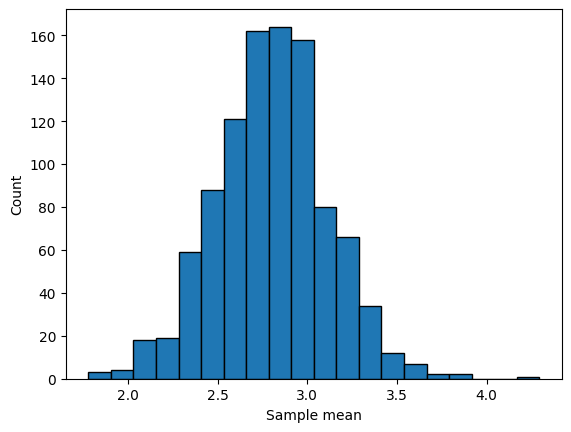

In [89]:
# EXAMPLE VALUES EXPLAINED: mu=2.8 and sigma=2.1 are the population mean/SD; n=45
# observations go into EACH sample; N=1000 is the number of simulated samples; 3.5
# is the mean-event threshold; 42 is the seed.
# REPLACE FOR YOUR QUESTION: Replace population parameters, per-sample n,
# repetitions N, event threshold and prescribed seed. size=(N,n) and mean(axis=1)
# match one sample per row.

np.random.seed(42)
# Question input: population mean for this example.
mu = 2.8
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 2.1
# Question input: number of observations in EACH simulated sample.
n = 45
# Simulation setting: number of samples to simulate.
N = 1000
samples = np.random.normal(mu, sigma, size=(N, n))
# Average values; for a Boolean mask this gives the True proportion.
sample_means = samples.mean(axis=1)
print("Mean of sample means:", sample_means.mean(), "theory:", mu)
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print("SD of sample means:", sample_means.std(ddof=1), "theory:", sigma / np.sqrt(n))
print("Empirical P(mean>3.5):", (sample_means > 3.5).mean())
print("Theoretical P(mean>3.5):", norm.sf(3.5, mu, sigma / np.sqrt(n)))
plt.figure()
plt.hist(sample_means, bins=20, edgecolor="black")
plt.xlabel("Sample mean")
plt.ylabel("Count")
plt.show()
# For exponential draws replace generation with np.random.exponential(scale=mu,size=(N,n)); then sigma=mu.


<a id="SIM-04"></a>
## SIM-04 · Dice means and sampling an existing population

**Search:** simulation dice randint choice population sample means n versus N seed sampling

**Use when:** Compare sample means for different sample sizes from a nonnormal population.

**Remember:** choice(...,size=(N,n),replace=False) samples N*n distinct values in one call; it does NOT independently sample n without replacement in each row. Use separate choice calls for that task.


**Example values explained:** N=5000 repeats each dice experiment; n=1,5,30 means that many dice averaged per repetition; randint(1,7) generates die faces 1–6. 3.5 and sqrt(35/12) are the TRUE fair-die mean/SD, not arbitrary inputs.

**Replace for your question:** Replace the generating population if the question differs. The resampling example uses 1000 samples of 5 incomes with replacement; adapt those counts separately.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `rolls = np.random.randint(1,7,size=(N,n))` | low is included, high EXCLUDED. (1,7) gives fair-die labels 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**low / high:** Integer low is included, high excluded. With one endpoint, low is interpreted as high and lower bound is 0. Require a nonempty integer range.<br>**Examples:** np.random.randint(1,7,size=25) -> dice 1..6; np.random.randint(10,size=25) -> 0..9. | Returns integer draws with the requested shape. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `draws = np.random.choice(population,size=n,replace=False,p=weights)` | replace=False prevents repeated selected positions within this draw; optional p must be probabilities summing to 1.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**a / replace / p:** a can be a 1D population or integer m representing positions 0..m-1. replace is True/False. p=None gives equal probabilities; a probability vector must match a and sum to 1. **Default:** replace=True; p=None.<br>**Examples:** np.random.choice(["A","B"],size=5,p=[.2,.8]); np.random.choice(10,size=3,replace=False) | Returns sampled entries. To repeat independent without-replacement samples, call separately per sample. |


In [90]:
# EXAMPLE VALUES EXPLAINED: N=5000 repeats each dice experiment; n=1,5,30 means that
# many dice averaged per repetition; randint(1,7) generates die faces 1–6. 3.5 and
# sqrt(35/12) are the TRUE fair-die mean/SD, not arbitrary inputs.
# REPLACE FOR YOUR QUESTION: Replace the generating population if the question
# differs. The resampling example uses 1000 samples of 5 incomes with replacement;
# adapt those counts separately.

# Simulation setting: number of repeated samples/experiments.
N = 5000
for n in [1, 5, 30]:
    np.random.seed(0)
    rolls = np.random.randint(1, 7, size=(N, n))
    # Average values; for a Boolean mask this gives the True proportion.
    means = rolls.mean(axis=1)
    # Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
    print(
        "n=",
        n,
        "mean=",
        means.mean(),
        "SD=",
        means.std(ddof=1),
        "theory SE=",
        np.sqrt(35 / 12) / np.sqrt(n),
    )
# Return rows complete in the stated columns; save the returned table.
population = df["income"].dropna().to_numpy()
np.random.seed(1131)
means_from_population = np.random.choice(population, size=(1000, 5), replace=True).mean(
    axis=1
)
print("Population resampling mean:", means_from_population.mean())


n= 1 mean= 3.5054 SD= 1.7128215293831122 theory SE= 1.707825127659933
n= 5 mean= 3.507 SD= 0.7645363975512455 theory SE= 0.7637626158259733
n= 30 mean= 3.5060933333333333 SD= 0.3148848671539793 theory SE= 0.31180478223116176
Population resampling mean: 133.051


<a id="SIM-05"></a>
## SIM-05 · Confidence-interval coverage simulation

**Search:** simulation confidence interval coverage repeated samples binomial proportion normal mean contain true parameter

**Use when:** Estimate the fraction of repeated confidence intervals covering the true parameter.


**Example values explained:** The proportion simulation uses true p=.58, sample size n=600, N=1000 repetitions and confidence=.95. The mean simulation uses true mean 70, population SD 10, n=12 and 1000 repetitions; 1131 is a seed.

**Replace for your question:** Change the population truth, sample sizes, repetitions, confidence and prescribed seed. Coverage compares each computed interval with the SAME fixed true parameter.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `counts = np.random.binomial(n,p,size=N)` | n trials per experiment, p success probability, N simulated experiments.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns success COUNTS; divide by n to obtain simulated sample proportions. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `draws = np.random.normal(loc=mu,scale=sigma,size=(N,n))` | loc is mean; scale is SD, NOT variance. size=n makes one sample; (N,n) makes N rows of n observations.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns random observations. samples.mean(axis=1) produces one mean per row. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |


In [91]:
# EXAMPLE VALUES EXPLAINED: The proportion simulation uses true p=.58, sample size
# n=600, N=1000 repetitions and confidence=.95. The mean simulation uses true mean
# 70, population SD 10, n=12 and 1000 repetitions; 1131 is a seed.
# REPLACE FOR YOUR QUESTION: Change the population truth, sample sizes, repetitions,
# confidence and prescribed seed. Coverage compares each computed interval with the
# SAME fixed true parameter.

np.random.seed(1131)
# Question input: number of observations/trials in this sample.
n = 600
# Simulation setting: number of repeated samples/experiments.
N = 1000
# Simulation input: fixed TRUE population success proportion.
p_true = 0.58
# Question input: desired confidence level as a proportion.
confidence = 0.95
p_hats = np.random.binomial(n, p_true, size=N) / n
mult = norm.ppf(1 - (1 - confidence) / 2)
ses = np.sqrt(p_hats * (1 - p_hats) / n)
lower, upper = p_hats - mult * ses, p_hats + mult * ses
covers = (lower <= p_true) & (p_true <= upper)
# Average values; for a Boolean mask this gives the True proportion.
print("Proportion intervals covering p:", covers.mean())
np.random.seed(1131)
samples = np.random.normal(70, 10, size=(1000, 12))
means = samples.mean(axis=1)
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
ses = samples.std(axis=1, ddof=1) / np.sqrt(12)
tm = t.ppf(0.975, df=11)
print(
    "t-interval mean coverage:",
    ((means - tm * ses <= 70) & (70 <= means + tm * ses)).mean(),
)


Proportion intervals covering p: 0.955
t-interval mean coverage: 0.953


<a id="ci"></a>
# 10 · Confidence intervals and sample-size planning

Input confidence=0.95 into scipy interval methods; input alpha=0.05 into statsmodels conf_int/summary_frame. Width=2×margin of error.


<a id="CI-01"></a>
## CI-01 · Proportion CI from success count or p-hat

**Search:** confidence interval proportion count successes phat p_hat standard error margin error normal interval

**Use when:** Estimate a population proportion using the course normal/Wald interval.

**Remember:** The CI standard error uses p_hat. The proportion hypothesis-test standard error uses p0. This Wald interval can extend outside [0,1]; do not silently change methods.


**Example values explained:** 348 is the observed SUCCESS COUNT out of n=600, so p_hat is computed as 348/600. confidence=.95 requests a 95% CI; the multiplier and MOE are calculated.

**Replace for your question:** Replace successes,n and confidence; keep percentages in proportion form, e.g. .95 rather than 95.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |


In [92]:
# EXAMPLE VALUES EXPLAINED: 348 is the observed SUCCESS COUNT out of n=600, so p_hat
# is computed as 348/600. confidence=.95 requests a 95% CI; the multiplier and MOE
# are calculated.
# REPLACE FOR YOUR QUESTION: Replace successes,n and confidence; keep percentages in
# proportion form, e.g. .95 rather than 95.

# Question input: observed number of successes, not a proportion.
successes = 348
# Question input: number of observations/trials in this sample.
n = 600
# Question input: desired confidence level as a proportion.
confidence = 0.95
p_hat = successes / n
alpha = 1 - confidence
se = np.sqrt(p_hat * (1 - p_hat) / n)
mult = norm.ppf(1 - alpha / 2)
moe = mult * se
lower, upper = norm.interval(confidence, loc=p_hat, scale=se)
print("Estimate, SE, multiplier, MOE:", p_hat, se, mult, moe)
print("CI:", lower, upper, "| width:", upper - lower)
print("Course condition n*p_hat*(1-p_hat)>=5:", n * p_hat * (1 - p_hat) >= 5)


Estimate, SE, multiplier, MOE: 0.58 0.020149441679609883 1.959963984540054 0.039492180000625626
CI: 0.5405078199993744 0.6194921800006256 | width: 0.0789843600012512
Course condition n*p_hat*(1-p_hat)>=5: True


<a id="CI-02"></a>
## CI-02 · Mean CI from raw data and summary statistics

**Search:** confidence interval mean t normal z known unknown sigma summary raw sample std ddof

**Use when:** Use t when population SD is unknown; derive n, mean and sample SD from data if available.


**Example values explained:** The first sample is actual TVhours data. The separate summary example gives n=12, sample mean 480 and sample SD 95. The final alternative uses known POPULATION sigma=90 solely to illustrate a known-SD interval.

**Replace for your question:** Replace the dataset/column OR all supplied summary statistics. Use known sigma only if the question supplies it; confidence=.95 is a chosen interval level.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |


In [93]:
# EXAMPLE VALUES EXPLAINED: The first sample is actual TVhours data. The separate
# summary example gives n=12, sample mean 480 and sample SD 95. The final
# alternative uses known POPULATION sigma=90 solely to illustrate a known-SD
# interval.
# REPLACE FOR YOUR QUESTION: Replace the dataset/column OR all supplied summary
# statistics. Use known sigma only if the question supplies it; confidence=.95 is a
# chosen interval level.

# Return rows complete in the stated columns; save the returned table.
values = pd.read_csv(DATA_DIR / "TVhours.csv")["hours"].dropna()
n = values.size
# Average values; for a Boolean mask this gives the True proportion.
x_bar = values.mean()
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
s = values.std(ddof=1)
# Question input: desired confidence level as a proportion.
confidence = 0.95
se = s / np.sqrt(n)
mult = t.ppf(1 - (1 - confidence) / 2, df=n - 1)
print("n, mean, sample SD:", n, x_bar, s)
print("SE, multiplier, MOE:", se, mult, mult * se)
print("t CI:", t.interval(confidence, df=n - 1, loc=x_bar, scale=se))
# Summary-only question: set n, x_bar, s directly and use the same formula.
# Question input: number of observations/trials in this sample.
n = 12
# Question input/statistic: sample mean.
x_bar = 480
# Question input/statistic: SAMPLE standard deviation, not variance.
s = 95
print("Summary-only t CI:", t.interval(0.95, df=n - 1, loc=x_bar, scale=s / np.sqrt(n)))
# Known population sigma (extra variation): exact if population normal; approximate via CLT otherwise.
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 90
print("Known-sigma z CI:", norm.interval(0.95, loc=x_bar, scale=sigma / np.sqrt(n)))


n, mean, sample SD: 60 2.6166666666666667 1.7953958693512737
SE, multiplier, MOE: 0.231784610061569 2.00099537704821 0.4637999332041216
t CI: (2.1528667334625453, 3.080466599870788)
Summary-only t CI: (419.63987970382755, 540.3601202961725)
Known-sigma z CI: (429.07864196657226, 530.9213580334277)


<a id="CI-03"></a>
## CI-03 · Sample size for specified width or margin of error

**Search:** sample size n planning ceil round up width margin error MOE conservative proportion pilot sigma

**Use when:** Find minimum integer sample size for a desired precision.

**Remember:** Use p=.5 for a conservative proportion calculation. The mean formula uses a normal multiplier and pilot SD as the course planning approximation. Always round n upward.


**Example values explained:** confidence=.95 sets the interval level; M=.02 is desired margin of error, hence total width D=.04. p guesses .5/.58 show conservative/prior planning. Pilot SD .5064 and width .20 belong to the separate mean example.

**Replace for your question:** Replace confidence, target precision and planning proportion/pilot SD. Total width is TWICE the margin of error; ceil enforces the minimum integer n.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [94]:
# EXAMPLE VALUES EXPLAINED: confidence=.95 sets the interval level; M=.02 is desired
# margin of error, hence total width D=.04. p guesses .5/.58 show conservative/prior
# planning. Pilot SD .5064 and width .20 belong to the separate mean example.
# REPLACE FOR YOUR QUESTION: Replace confidence, target precision and planning
# proportion/pilot SD. Total width is TWICE the margin of error; ceil enforces the
# minimum integer n.

# Question input: desired confidence level as a proportion.
confidence = 0.95
alpha = 1 - confidence
z_mult = norm.ppf(1 - alpha / 2)
# Question input: target margin of error, HALF the total interval width.
M = 0.02
D = 2 * M
for p_guess in [0.5, 0.58]:
    n_needed = math.ceil((z_mult / M) ** 2 * p_guess * (1 - p_guess))
    print("Proportion p=", p_guess, "n=", n_needed)
# Question input: SD estimated from a pilot/similar study.
s_pilot = 0.5064
# Question input: desired TOTAL width of the mean confidence interval.
D_mean = 0.20
M_mean = D_mean / 2
print("Mean planned n:", math.ceil((z_mult * s_pilot / M_mean) ** 2))


Proportion p= 0.5 n= 2401
Proportion p= 0.58 n= 2340
Mean planned n: 99


<a id="CI-04"></a>
## CI-04 · Change confidence levels; interval contains a null value

**Search:** confidence interval level width compare contains null value 90 95 99 test consistency

**Use when:** Compare widths or check whether a reference mean lies in the interval.

**Remember:** For matching two-sided mean t-tests and CIs, the null is outside the CI exactly when rejected (apart from boundary conventions/rounding). Different proportion CI/test standard errors may disagree near the cutoff.


**Example values explained:** n=12, mean=480, SD=95 describe the sample; mu0=500 is the reference mean to check. .90/.95/.99 are three alternative confidence levels for the SAME sample.

**Replace for your question:** Replace sample summaries, reference value and requested levels. A confidence-level change changes the interval, not the observed sample mean.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [95]:
# EXAMPLE VALUES EXPLAINED: n=12, mean=480, SD=95 describe the sample; mu0=500 is
# the reference mean to check. .90/.95/.99 are three alternative confidence levels
# for the SAME sample.
# REPLACE FOR YOUR QUESTION: Replace sample summaries, reference value and requested
# levels. A confidence-level change changes the interval, not the observed sample
# mean.

# Question input: number of observations/trials in this sample.
n = 12
# Question input/statistic: sample mean.
x_bar = 480
# Question input/statistic: SAMPLE standard deviation, not variance.
s = 95
# Question input: hypothesised population mean under H0.
mu0 = 500
for confidence in [0.90, 0.95, 0.99]:
    lower, upper = t.interval(confidence, df=n - 1, loc=x_bar, scale=s / np.sqrt(n))
    print(
        confidence,
        "CI=",
        (lower, upper),
        "width=",
        upper - lower,
        "contains mu0=",
        lower <= mu0 <= upper,
    )


0.9 CI= (430.74940728317404, 529.250592716826) width= 98.50118543365193 contains mu0= True
0.95 CI= (419.63987970382755, 540.3601202961725) width= 120.72024059234491 contains mu0= True
0.99 CI= (394.82593424319293, 565.1740657568071) width= 170.34813151361413 contains mu0= True


<a id="CI-05"></a>
## CI-05 · Shortcut functions: mean_ci and proportion_ci

**Search:** mean_ci proportion_ci shortcut function population mean proportion confidence interval friend additions summary stats

**Use when:** Use your friend’s reusable CI functions with summary inputs. Both return (lower, upper).

**Remember:** Run this cell to DEFINE the functions before calling them elsewhere. Pass SD, not variance. Check randomisation/normality assumptions separately; input validation does not establish statistical validity.


**Example values explained:** mean_ci takes sample mean, sample size n and SAMPLE SD s. Its call (480,12,95) is an example, not a built-in distribution. proportion_ci uses p_hat=348/600 and n=600; .95 is the confidence default.

**Replace for your question:** Replace call arguments with your computed or supplied statistics. Keep function validation and n-1 degrees of freedom; run the definition before calling it.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `type(value)`<br>**OR**<br>`isinstance(value,(int,float))` | type inspects the actual class; isinstance tests membership of one or several classes. | Returns a type object or Boolean; used for checking helper inputs, not estimating a parameter. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `low,high = mean_ci(mean=480,n=12,s=95,confidence=.95)` | Define this helper first in CI-05. Supply sample mean, sample size, SAMPLE SD, and desired confidence.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**sample summaries:** Sample sizes are positive integers (>=2 for a sample-SD mean procedure); sample SDs nonnegative; means real; p_hat a fraction in [0,1]. Assumptions/approximation checks still apply.<br>**Examples:** mean_ci(mean=480,n=12,s=95); proportion_ci(p_hat=348/600,n=600) | Returns two endpoints for a t mean CI; these inputs do not establish the sampling/normality assumptions. |
| `low,high = proportion_ci(p_hat=successes/n,n=n,confidence=.95)` | Define in CI-05. p_hat and confidence are proportions in 0–1; n is number of relevant observed responses.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**sample summaries:** Sample sizes are positive integers (>=2 for a sample-SD mean procedure); sample SDs nonnegative; means real; p_hat a fraction in [0,1]. Assumptions/approximation checks still apply.<br>**Examples:** mean_ci(mean=480,n=12,s=95); proportion_ci(p_hat=348/600,n=600) | Returns endpoints of the course normal/Wald proportion CI, after input/approximation checks. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |


In [96]:
# EXAMPLE VALUES EXPLAINED: mean_ci takes sample mean, sample size n and SAMPLE SD
# s. Its call (480,12,95) is an example, not a built-in distribution. proportion_ci
# uses p_hat=348/600 and n=600; .95 is the confidence default.
# REPLACE FOR YOUR QUESTION: Replace call arguments with your computed or supplied
# statistics. Keep function validation and n-1 degrees of freedom; run the
# definition before calling it.


def mean_ci(mean, n, s, confidence=0.95):
    """Two-sided t CI: mean=sample mean, n=sample size, s=SAMPLE SD."""
    if not isinstance(n, (int, np.integer)) or n < 2:
        raise ValueError("Require integer n >= 2.")
    if not np.isfinite(mean) or not np.isfinite(s) or s < 0 or not 0 < confidence < 1:
        raise ValueError("Require finite mean, finite s >= 0 and 0 < confidence < 1.")
    if s == 0:
        return float(mean), float(mean)
    se = s / np.sqrt(n)
    return stats.t.interval(confidence=confidence, df=n - 1, loc=mean, scale=se)


def proportion_ci(p_hat, n, confidence=0.95):
    """Course normal/Wald CI with the course normal-approximation check."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("Require positive integer n.")
    if not 0 <= p_hat <= 1 or not 0 < confidence < 1:
        raise ValueError("Require 0 <= p_hat <= 1 and 0 < confidence < 1.")
    if n * p_hat * (1 - p_hat) < 5:
        raise ValueError("Normal-approximation condition is not satisfied.")
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    return stats.norm.interval(confidence=confidence, loc=p_hat, scale=se)


print("Mean CI:", mean_ci(mean=480, n=12, s=95, confidence=0.95))
print("Proportion CI:", proportion_ci(p_hat=348 / 600, n=600, confidence=0.95))
# Return rows complete in the stated columns; save the returned table.
hours_data = pd.read_csv(DATA_DIR / "TVhours.csv")["hours"].dropna()
# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print(
    "Raw-data mean CI via shortcut:",
    mean_ci(hours_data.mean(), len(hours_data), hours_data.std(ddof=1)),
)


Mean CI: (419.63987970382755, 540.3601202961725)
Proportion CI: (0.5405078199993744, 0.6194921800006256)
Raw-data mean CI via shortcut: (2.1528667334625453, 3.080466599870788)


<a id="CI-06"></a>
## CI-06 · Shortcut functions: sample_size_mean and sample_size_proportion

**Search:** sample_size_mean sample_size_proportion shortcut function width margin error MOE ceil sample size friend additions

**Use when:** Use your friend’s named sample-size functions; width is the TOTAL CI width.

**Remember:** These use the course normal-multiplier planning approximation. Do not pass margin of error directly as width. Always round sample size UP, not to the nearest integer.


**Example values explained:** sample_size_mean uses pilot SD .5064 and TOTAL width .20. The proportion examples use TOTAL width .04, default planning p=.5 or prior p=.58; MOE .02 must be doubled to supply width .04.

**Replace for your question:** Replace pilot SD/planning p, desired total width and confidence. Do not pass MOE as width; ceil is necessary.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `needed = sample_size_mean(s=pilot_sd,width=total_width,confidence=.95)` | Define in CI-06. width is TOTAL interval width, twice the margin of error; s is a pilot SD.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**width / planning SD or p:** width must be positive TOTAL width, twice MOE. For mean planning, s>0 is pilot SD; proportion helper planning p is in (0,1), with .5 conservative.<br>**Examples:** sample_size_mean(s=.5064,width=.20); sample_size_proportion(width=.04,p=.58) | Returns sample size rounded UP using the course normal-multiplier planning formula. |
| `needed = sample_size_proportion(width=total_width,p=.5,confidence=.95)` | Define in CI-06. Use p=.5 for conservative planning or the supplied prior estimate; width is TOTAL width.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**width / planning SD or p:** width must be positive TOTAL width, twice MOE. For mean planning, s>0 is pilot SD; proportion helper planning p is in (0,1), with .5 conservative.<br>**Examples:** sample_size_mean(s=.5064,width=.20); sample_size_proportion(width=.04,p=.58) | Returns the upward-rounded planned n. Do not enter margin of error as total width. |


In [97]:
# EXAMPLE VALUES EXPLAINED: sample_size_mean uses pilot SD .5064 and TOTAL width
# .20. The proportion examples use TOTAL width .04, default planning p=.5 or prior
# p=.58; MOE .02 must be doubled to supply width .04.
# REPLACE FOR YOUR QUESTION: Replace pilot SD/planning p, desired total width and
# confidence. Do not pass MOE as width; ceil is necessary.


def sample_size_mean(s, width, confidence=0.95):
    """Approximate planned n for a mean CI; s is pilot SD, width is TOTAL width."""
    if (
        not np.isfinite(s)
        or not np.isfinite(width)
        or s <= 0
        or width <= 0
        or not 0 < confidence < 1
    ):
        raise ValueError(
            "Require finite s > 0, finite width > 0 and 0 < confidence < 1."
        )
    z = stats.norm.ppf((1 + confidence) / 2)
    return math.ceil((2 * z * s / width) ** 2)


def sample_size_proportion(width, confidence=0.95, p=0.5):
    """Approximate planned n for a proportion CI; p=.5 is conservative if unknown."""
    if not np.isfinite(width) or width <= 0 or not 0 < confidence < 1 or not 0 < p < 1:
        raise ValueError("Require finite width > 0, 0 < confidence < 1 and 0 < p < 1.")
    z = stats.norm.ppf((1 + confidence) / 2)
    return math.ceil((2 * z / width) ** 2 * p * (1 - p))


print("Mean CI width .20:", sample_size_mean(s=0.5064, width=0.20))
print("Proportion CI width .04:", sample_size_proportion(width=0.04))
print("Proportion CI, planning p=.58:", sample_size_proportion(width=0.04, p=0.58))
margin_of_error = 0.02
print(
    "Given MOE .02, use width=2*MOE:", sample_size_proportion(width=2 * margin_of_error)
)


Mean CI width .20: 99
Proportion CI width .04: 2401
Proportion CI, planning p=.58: 2340
Given MOE .02, use width=2*MOE: 2401


<a id="CI-07"></a>
## CI-07 · Proportion CI from string-labelled outcomes within a subgroup

**Search:** pandas proportion subgroup success label string categorical filter mean count denominator confidence interval

**Use when:** The dataset records success as text, and only a specified subgroup belongs in the sample.

**Remember:** Filter first, then calculate BOTH successes and sample size from the same observed outcomes. Do not treat missing labels as failures unless specified. Brackets work for column names containing dots/spaces.

**Change these inputs:** DataFrame; group column/label; outcome column/success label; confidence level. Exact spelling, case and whitespace matter.

**Read these outputs:** subgroup_n and subgroup_successes define the sample; subgroup_p_hat, subgroup_lower and subgroup_upper give the proportion CI. These distinct variable names avoid accidentally reusing another dataset’s sample size.


**Example values explained:** The made-up table contains 30 group-A outcomes (18 successes,12 failures) and 20 group-B outcomes (10 successes,10 failures). The example analyses A only, with success spelled 'success' and 95% confidence.

**Replace for your question:** Replace data, group/outcome columns, subgroup label, success label and confidence. Calculate the denominator AFTER the subgroup filter and missing-value policy.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |


In [98]:
# EXAMPLE VALUES EXPLAINED: The made-up table contains 30 group-A outcomes (18
# successes,12 failures) and 20 group-B outcomes (10 successes,10 failures). The
# example analyses A only, with success spelled 'success' and 95% confidence.
# REPLACE FOR YOUR QUESTION: Replace data, group/outcome columns, subgroup label,
# success label and confidence. Calculate the denominator AFTER the subgroup filter
# and missing-value policy.

# REPLACE this example with your loaded table.
subgroup_data = pd.DataFrame(
    {
        "group": ["A"] * 30 + ["B"] * 20,
        "outcome": ["success"] * 18
        + ["failure"] * 12
        + ["success"] * 10
        + ["failure"] * 10,
    }
)
group_column = "group"
group_label = "A"
outcome_column = "outcome"
success_label = "success"
confidence_level = 0.95
# Return rows complete in the stated columns; save the returned table.
subgroup_outcomes = subgroup_data.loc[
    subgroup_data[group_column].eq(group_label), outcome_column
].dropna()
subgroup_n = len(subgroup_outcomes)
if subgroup_n == 0:
    raise ValueError("No observed outcomes in the selected subgroup.")
subgroup_successes = int(subgroup_outcomes.eq(success_label).sum())
subgroup_p_hat = subgroup_successes / subgroup_n
subgroup_condition = subgroup_n * subgroup_p_hat * (1 - subgroup_p_hat)
if subgroup_condition < 5:
    raise ValueError("The course normal-approximation CI condition is not satisfied.")
subgroup_se = np.sqrt(subgroup_p_hat * (1 - subgroup_p_hat) / subgroup_n)
subgroup_lower, subgroup_upper = norm.interval(
    confidence_level, loc=subgroup_p_hat, scale=subgroup_se
)
display(
    pd.Series(
        {
            "n": subgroup_n,
            "successes": subgroup_successes,
            "p_hat": subgroup_p_hat,
            "approximation_check": subgroup_condition,
            "SE": subgroup_se,
            "CI_lower": subgroup_lower,
            "CI_upper": subgroup_upper,
        }
    )
)
# To use TEST-01 on this SAME sample, set its n=subgroup_n and successes=subgroup_successes.
# Its null-test SE must use the given p0, not subgroup_p_hat.


n                      30.000000
successes              18.000000
p_hat                   0.600000
approximation_check     7.200000
SE                      0.089443
CI_lower                0.424695
CI_upper                0.775305
dtype: float64

<a id="tests"></a>
# 11 · Hypothesis tests: raw data, summaries, tails and paired data

Decide mean/proportion; one/two samples; independent/paired; direction; variance assumption. Alternative always follows the subtraction order. The Levene→pooled/Welch selection below follows the course workflow.


<a id="TEST-01"></a>
## TEST-01 · One-proportion Z test with all three alternatives

**Search:** hypothesis proportion z test p0 phat tails greater less two-sided statistic pvalue

**Use when:** Test a population proportion against a specified null probability.

**Remember:** This is an approximate proportion test based on a normal null distribution. The original notes call the normal-tail p-value exact; that does not make the binomial approximation exact.


**Example values explained:** 22 successes out of n=54 gives the observed proportion; p0=1/7 is the hypothesised chance success rate; alpha=.05 is the decision level. alternative='greater' selects a right-sided test.

**Replace for your question:** Replace success count,n,p0,alpha and alternative. Keep p0 in the NULL SE; the function prints alternative tail probabilities for illustration.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [99]:
# EXAMPLE VALUES EXPLAINED: 22 successes out of n=54 gives the observed proportion;
# p0=1/7 is the hypothesised chance success rate; alpha=.05 is the decision level.
# alternative='greater' selects a right-sided test.
# REPLACE FOR YOUR QUESTION: Replace success count,n,p0,alpha and alternative. Keep
# p0 in the NULL SE; the function prints alternative tail probabilities for
# illustration.

successes, n, p0, alpha = 22, 54, 1 / 7, 0.05
p_hat = successes / n
se0 = np.sqrt(p0 * (1 - p0) / n)
z_stat = (p_hat - p0) / se0
p_values = {
    "greater": norm.sf(z_stat),
    "less": norm.cdf(z_stat),
    "two-sided": 2 * norm.sf(abs(z_stat)),
}
alternative = "greater"
p_value = p_values[alternative]
print("z=", z_stat, "all tail p-values=", p_values)
print(
    "Reject H0?",
    p_value <= alpha,
    "| normal approximation condition:",
    n * p0 * (1 - p0) >= 5,
)


z= 5.555555555555555 all tail p-values= {'greater': 1.3836508957768791e-08, 'less': 0.9999999861634911, 'two-sided': 2.7673017915537582e-08}
Reject H0? True | normal approximation condition: True


<a id="TEST-02"></a>
## TEST-02 · One-sample t test from raw data, one-/two-sided CI

**Search:** ttest_1samp raw mean alternative less greater two-sided statistic pvalue df confidence_interval

**Use when:** Test one mean when only sample SD is known.

**Remember:** greater gives a lower confidence bound (L, infinity); less gives an upper bound (-infinity, U). A two-sided result gives two finite endpoints. Use a separate two-sided result when asked for a two-sided CI, even when the hypothesis test itself is one-sided.


**Example values explained:** The example tests SocialMediaHours against mu0=3 hours using alpha=.05 and a two-sided alternative. .95 requests the separately constructed two-sided CI. The matching interval uses confidence=1-alpha and follows the chosen alternative; greater gives a lower bound and less an upper bound.

**Replace for your question:** Replace dataset/column, null mean, direction and decision/interval levels. popmean is NOT the observed sample mean.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `res = ttest_1samp(values,popmean=mu0,alternative="two-sided")` | values are observed numeric data; popmean is the NULL mean. alternative: "greater", "less", "two-sided".<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**popmean / axis:** popmean is any real hypothesised mean, not the observed mean. axis=0 tests columns; axis=1 tests each row of a simulated matrix; None flattens all data into one test. **Default:** axis=0.<br>**Examples:** ttest_1samp(x,popmean=3.3); ttest_1samp(samples,popmean=70,axis=1)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Returns a result; read res.statistic, res.pvalue, res.df. It tests population mean minus mu0. |
| `ci = res.confidence_interval(confidence_level=.95)` | Use the desired confidence level. The result’s alternative determines one- versus two-sided bounds; use a two-sided result for two finite endpoints.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Read ci.low and ci.high. SciPy 1.10 independent-test results lack this method; use independent_t_interval instead. |


In [100]:
# EXAMPLE VALUES EXPLAINED: The example tests SocialMediaHours against mu0=3 hours
# using alpha=.05 and a two-sided alternative. .95 requests the separately
# constructed two-sided CI. The matching interval uses confidence=1-alpha and
# follows the chosen alternative; greater gives a lower bound and less an upper
# bound.
# REPLACE FOR YOUR QUESTION: Replace dataset/column, null mean, direction and
# decision/interval levels. popmean is NOT the observed sample mean.

# Return rows complete in the stated columns; save the returned table.
values = pd.read_csv(DATA_DIR / "SocialMediaHours.csv")["hours"].dropna()
# Question input: hypothesised population mean under H0.
mu0 = 3
# Decision/input level: .05 means 5% significance (or 1-confidence for a CI).
alpha = 0.05
alternative = "two-sided"
# Test this sample mean against popmean; alternative sets the tail.
result = ttest_1samp(values, popmean=mu0, alternative=alternative)
print("t=", result.statistic, "p=", result.pvalue, "df=", result.df)
print("Reject H0?", result.pvalue <= alpha)
# Read ci.low/ci.high; the test alternative controls one- versus two-sided bounds.
print("CI matching the chosen alternative:", result.confidence_interval(1 - alpha))
two_sided = ttest_1samp(values, popmean=mu0, alternative="two-sided")
print("Two-sided 95% CI:", two_sided.confidence_interval(0.95))


t= 6.03001380240353 p= 2.5040386505299448e-09 df= 799
Reject H0? True
CI matching the chosen alternative: ConfidenceInterval(low=3.3465100642902277, high=3.680989935709772)
Two-sided 95% CI: ConfidenceInterval(low=3.3465100642902277, high=3.680989935709772)


<a id="TEST-03"></a>
## TEST-03 · One-sample t/Z test from summary statistics

**Search:** summary statistics manual t z test n mean sd unknown known sigma pvalue tails degrees freedom

**Use when:** The question gives n, sample mean and sample SD but no raw dataset.


**Example values explained:** Summary inputs are n=12, mean=480, sample SD=95 and null mean=500; alpha=.05 is the example significance level. Population sigma=90 belongs ONLY to the known-sigma alternative.

**Replace for your question:** Replace sample summaries/null value and only use sigma if actually known. n-1 and the two-sided multiplier 2 are method requirements.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [101]:
# EXAMPLE VALUES EXPLAINED: Summary inputs are n=12, mean=480, sample SD=95 and null
# mean=500; alpha=.05 is the example significance level. Population sigma=90 belongs
# ONLY to the known-sigma alternative.
# REPLACE FOR YOUR QUESTION: Replace sample summaries/null value and only use sigma
# if actually known. n-1 and the two-sided multiplier 2 are method requirements.

# Question input: number of observations/trials in this sample.
n = 12
# Question input/statistic: sample mean.
x_bar = 480
# Question input/statistic: SAMPLE standard deviation, not variance.
s = 95
# Question input: hypothesised population mean under H0.
mu0 = 500
# Decision/input level: .05 means 5% significance (or 1-confidence for a CI).
alpha = 0.05
t_stat = (x_bar - mu0) / (s / np.sqrt(n))
degrees = n - 1
print("t statistic:", t_stat, "df:", degrees)
print(
    "Less p:",
    t.cdf(t_stat, degrees),
    "Greater p:",
    t.sf(t_stat, degrees),
    "Two-sided p:",
    2 * t.sf(abs(t_stat), degrees),
)
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 90  # only use if population SD is actually known
z_stat = (x_bar - mu0) / (sigma / np.sqrt(n))
print("Known-sigma Z:", z_stat, "two-sided p:", 2 * norm.sf(abs(z_stat)))


t statistic: -0.7292845505553167 df: 11
Less p: 0.2405340554679089 Greater p: 0.759465944532091 Two-sided p: 0.4810681109358178
Known-sigma Z: -0.769800358919501 two-sided p: 0.4414183267820536


<a id="TEST-04"></a>
## TEST-04 · Independent samples: explicit pooled and Welch tests

**Search:** two sample ttest_ind independent equal_var True False pooled Welch levene two groups alternatives

**Use when:** Compare two independently sampled groups. Extract data separately and check assumptions.

**Remember:** equal_var=True assumes equal population variances, not identical sample variances. Welch allows unequal variances. Raw ttest_ind tests a zero difference. The SETUP-01 helper independent_t_interval supplies df and a TWO-sided CI on SciPy 1.10 too; use the same equal_var for both calls.


**Example values explained:** Group A and group B provide independent demo score samples. True requests the pooled equal-variance test; False requests Welch. .95 is the CI level.

**Replace for your question:** Replace group labels and outcome column. Choose equal_var from the requested assumptions/procedure rather than treating both printed alternatives as sequential steps. The interval/df helper is defined in SETUP-01 and needs the same two samples and equal_var setting as the SciPy test.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |
| `degrees,ci = independent_t_interval(first,second,.95,equal_var=False)` | Run SETUP-01 to define the helper. Use the SAME samples and equal_var choice as ttest_ind; .95 is confidence.<br><br>**Parameter choices and examples:**<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Returns df and a TWO-sided CI with ci.low/ci.high, including on SciPy 1.10. It does not calculate the p-value. |


In [102]:
# EXAMPLE VALUES EXPLAINED: Group A and group B provide independent demo score
# samples. True requests the pooled equal-variance test; False requests Welch. .95
# is the CI level.
# REPLACE FOR YOUR QUESTION: Replace group labels and outcome column. Choose
# equal_var from the requested assumptions/procedure rather than treating both
# printed alternatives as sequential steps. The interval/df helper is defined in
# SETUP-01 and needs the same two samples and equal_var setting as the SciPy test.

internet = pd.read_csv(DATA_DIR / "internet_hours.csv")
print(internet.columns.tolist())
# Reusable illustration; replace filters and value column with the actual exam labels.
# Return rows complete in the stated columns; save the returned table.
x = df.loc[df["group"].eq("A"), "score"].dropna()
y = df.loc[df["group"].eq("B"), "score"].dropna()
for equal_variances in [True, False]:
    # Test first-minus-second independent means; False=Welch, True=pooled.
    res = ttest_ind(x, y, equal_var=equal_variances, alternative="two-sided")
    # Get df and a two-sided independent-means CI; define in SETUP-01 first.
    independent_df, independent_ci = independent_t_interval(
        x, y, 0.95, equal_var=equal_variances
    )
    print(
        "Pooled" if equal_variances else "Welch",
        "t=",
        res.statistic,
        "df=",
        independent_df,
        "p=",
        res.pvalue,
        "CI=",
        independent_ci,
    )


['gender', 'hours']
Pooled t= 0.5942914157387196 df= 5 p= 0.5781851196684862 CI= CI(low=-14.687434134793737, high=23.52076746812708)
Welch t= 0.5946054956068909 df= 4.46308708223756 p= 0.5809535822051486 CI= CI(low=-15.389363285624466, high=24.22269661895781)


<a id="TEST-05"></a>
## TEST-05 · Course Levene workflow with separate significance levels

**Search:** levene variance test alpha variance mean test independent equal_var branch confidence level internet tutorial9

**Use when:** A question asks you to choose pooled/Welch using an equal-variance test.

**Remember:** Not rejecting equal variance does not prove equality. The variance-test alpha and mean-test alpha can differ, as in Tutorial 9.


**Example values explained:** .15 is the decision level for Levene's variance test; .01 is the DIFFERENT decision level for the mean test; .99 is the matching two-sided CI confidence. The sample groups are A minus B.

**Replace for your question:** Replace both significance levels, groups, outcome and direction separately. Do not accidentally use the variance-test alpha for the mean-test decision. The SETUP-01 independent_t_interval helper returns a two-sided CI even if a directional test is requested.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `res = levene(first,second)` | Supply the two independent numeric samples. Compare its p-value with the VARIANCE-test alpha.<br><br>**Parameter choices and examples:**<br><br>**center:** "median" (default Brown-Forsythe form), "mean" (classical Levene), "trimmed" (trimmed centre). Follow the course’s default unless another form is requested. **Default:** "median".<br>**Examples:** levene(a,b); levene(a,b,center="mean") | H0: equal population variances. Small p rejects; large p does not prove equality. Course workflow then selects pooled/Welch. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |
| `degrees,ci = independent_t_interval(first,second,.95,equal_var=False)` | Run SETUP-01 to define the helper. Use the SAME samples and equal_var choice as ttest_ind; .95 is confidence.<br><br>**Parameter choices and examples:**<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Returns df and a TWO-sided CI with ci.low/ci.high, including on SciPy 1.10. It does not calculate the p-value. |


In [103]:
# EXAMPLE VALUES EXPLAINED: .15 is the decision level for Levene's variance test;
# .01 is the DIFFERENT decision level for the mean test; .99 is the matching
# two-sided CI confidence. The sample groups are A minus B.
# REPLACE FOR YOUR QUESTION: Replace both significance levels, groups, outcome and
# direction separately. Do not accidentally use the variance-test alpha for the
# mean-test decision. The SETUP-01 independent_t_interval helper returns a two-sided
# CI even if a directional test is requested.

# Return rows complete in the stated columns; save the returned table.
x = df.loc[df["group"].eq("A"), "score"].dropna()
y = df.loc[df["group"].eq("B"), "score"].dropna()
# Question input: significance level for LEVENE'S variance test.
alpha_variance = 0.15
# Question input: significance level for the separate MEAN test.
alpha_mean = 0.01
alternative = "two-sided"
lev = levene(x, y)
equal_variances = lev.pvalue > alpha_variance
# Test first-minus-second independent means; False=Welch, True=pooled.
res = ttest_ind(x, y, equal_var=equal_variances, alternative=alternative)
# Get df and a two-sided independent-means CI; define in SETUP-01 first.
mean_test_df, mean_test_ci = independent_t_interval(
    x, y, 1 - alpha_mean, equal_var=equal_variances
)
print(
    "Levene H0: equal population variances; p=",
    lev.pvalue,
    "equal_var=",
    equal_variances,
)
print(
    "Mean test t, df, p:",
    res.statistic,
    mean_test_df,
    res.pvalue,
    "Reject?",
    res.pvalue <= alpha_mean,
)
print("Two-sided CI for mean(x)-mean(y):", mean_test_ci)


Levene H0: equal population variances; p= 0.9345136168780962 equal_var= True
Mean test t, df, p: 0.5942914157387196 5 0.5781851196684862 Reject? False
Two-sided CI for mean(x)-mean(y): CI(low=-25.549493097858754, high=34.3828264311921)


<a id="TEST-06"></a>
## TEST-06 · Independent pooled/Welch tests from summaries and nonzero null

**Search:** summary statistics two sample ttest_ind_from_stats pooled variance Welch df null delta difference CI

**Use when:** You have n1,n2,means,SDs rather than raw data, or H0 specifies a nonzero difference.

**Remember:** Pass SD, not variance, into ttest_ind_from_stats. That shortcut tests a zero difference; the manual formula supports delta0≠0 as an extra variation.


**Example values explained:** n1=11,n2=21 are sample sizes, means 52/48, SDs 4/5, delta0=0 the hypothesised mean difference, and confidence=.95 the CI level. alternative chooses less/greater/two-sided for FIRST minus SECOND; alpha=1-confidence supplies the matching test level. Directional alternatives also print the matching one-sided confidence bound; the two-sided CI is labelled separately.

**Replace for your question:** Replace all supplied summaries/null difference/level. SD 4 and 5 correspond to variances 16 and 25; the shortcut requires SDs, not variances.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `stats.ttest_ind_from_stats(mean1,sd1,n1,mean2,sd2,n2,equal_var=False)` | Supply sample MEAN, SAMPLE SD, sample size for each independent group; SD is not variance.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**sample summaries:** Sample sizes are positive integers (>=2 for a sample-SD mean procedure); sample SDs nonnegative; means real; p_hat a fraction in [0,1]. Assumptions/approximation checks still apply.<br>**Examples:** mean_ci(mean=480,n=12,s=95); proportion_ci(p_hat=348/600,n=600) | Returns t statistic/p-value for null difference zero. See TEST-06 for nonzero null difference and manual df/CI. |


In [104]:
# EXAMPLE VALUES EXPLAINED: n1=11,n2=21 are sample sizes, means 52/48, SDs 4/5,
# delta0=0 the hypothesised mean difference, and confidence=.95 the CI level.
# alternative chooses less/greater/two-sided for FIRST minus SECOND;
# alpha=1-confidence supplies the matching test level. Directional alternatives also
# print the matching one-sided confidence bound; the two-sided CI is labelled
# separately.
# REPLACE FOR YOUR QUESTION: Replace all supplied summaries/null difference/level.
# SD 4 and 5 correspond to variances 16 and 25; the shortcut requires SDs, not
# variances.

# Question input: sample size of the FIRST independent group.
n1 = 11
# Question input: sample size of the SECOND independent group.
n2 = 21
# Question input: FIRST group sample mean.
mean1 = 52
# Question input: SECOND group sample mean.
mean2 = 48
# Question input: FIRST group SAMPLE SD, not variance.
sd1 = 4
# Question input: SECOND group SAMPLE SD, not variance.
sd2 = 5
# Question input: hypothesised difference between population means.
delta0 = 0.0
# Question input: desired confidence level as a proportion.
confidence = 0.95
alternative = "two-sided"
alpha = 1 - confidence
sp2 = ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2) / (n1 + n2 - 2)
se_p = np.sqrt(sp2 * (1 / n1 + 1 / n2))
df_p = n1 + n2 - 2
v1, v2 = sd1**2 / n1, sd2**2 / n2
se_w = np.sqrt(v1 + v2)
df_w = (v1 + v2) ** 2 / (v1 * v1 / (n1 - 1) + v2 * v2 / (n2 - 1))
estimate = mean1 - mean2
for name, se, degrees in [
    ("Pooled", se_p, df_p),  # Row 1
    ("Welch", se_w, df_w),  # Row 2
]:
    statistic = (estimate - delta0) / se
    summary_p_values = {
        "less": t.cdf(statistic, degrees),
        "greater": t.sf(statistic, degrees),
        "two-sided": 2 * t.sf(abs(statistic), degrees),
    }
    print(
        name,
        "estimate=",
        estimate,
        "t=",
        statistic,
        "df=",
        degrees,
        "all tail p-values=",
        summary_p_values,
    )
    print(
        "Chosen alternative:",
        alternative,
        "p=",
        summary_p_values[alternative],
        "Reject?",
        summary_p_values[alternative] <= alpha,
    )
    print(
        "CI for actual difference:",
        t.interval(confidence, df=degrees, loc=estimate, scale=se),
    )
    if alternative != "two-sided":
        one_sided_multiplier = t.ppf(confidence, df=degrees)
        matching_interval = (
            (estimate - one_sided_multiplier * se, np.inf)
            if alternative == "greater"
            else (-np.inf, estimate + one_sided_multiplier * se)
        )
        print("One-sided CI matching the chosen alternative:", matching_interval)
if delta0 == 0:
    print(
        "SciPy Welch summary shortcut:",
        stats.ttest_ind_from_stats(
            mean1, sd1, n1, mean2, sd2, n2, equal_var=False, alternative=alternative
        ),
    )
else:
    print("Use the manual results above for the specified nonzero null difference.")


Pooled estimate= 4 t= 2.2912878474779204 df= 30 all tail p-values= {'less': 0.9854287498954712, 'greater': 0.014571250104528699, 'two-sided': 0.029142500209057398}
Chosen alternative: two-sided p= 0.029142500209057398 Reject? True
CI for actual difference: (0.43471690639092886, 7.565283093609072)
Welch estimate= 4 t= 2.4594917841566133 df= 24.771064671203018 all tail p-values= {'less': 0.9893749665820204, 'greater': 0.010625033417979622, 'two-sided': 0.021250066835959244}
Chosen alternative: two-sided p= 0.021250066835959244 Reject? True
CI for actual difference: (0.6488944666473238, 7.351105533352676)
SciPy Welch summary shortcut: Ttest_indResult(statistic=2.4594917841566133, pvalue=0.021250066835959244)


<a id="TEST-07"></a>
## TEST-07 · Paired t test with complete pairs, differences and CI

**Search:** paired dependent matched before after ttest_rel dropna missing incomplete pair differences normality ttest_1samp

**Use when:** Two measurements belong to the same individual or matched pair.

**Remember:** A paired-test SE is SD(differences)/sqrt(number of pairs). You cannot recover SD(differences) from marginal SDs alone without their covariance/correlation.


**Example values explained:** Yes/No are matched reaction-time columns; the example difference is Yes minus No. greater tests an increase; .99 requests a TWO-sided 99% CI built separately.

**Replace for your question:** Replace paired column names/order, direction and confidence. n is the number of complete PAIRS, not twice that count.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `res = ttest_rel(after,before,alternative="less")` | Supply matching observations in identical pair order, after jointly removing missing pairs. Tests mean(after-before).<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read statistic/pvalue/df. less means mean(first-second)<0; it does not automatically mean an after decrease unless order matches. |
| `res = ttest_1samp(values,popmean=mu0,alternative="two-sided")` | values are observed numeric data; popmean is the NULL mean. alternative: "greater", "less", "two-sided".<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**popmean / axis:** popmean is any real hypothesised mean, not the observed mean. axis=0 tests columns; axis=1 tests each row of a simulated matrix; None flattens all data into one test. **Default:** axis=0.<br>**Examples:** ttest_1samp(x,popmean=3.3); ttest_1samp(samples,popmean=70,axis=1)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Returns a result; read res.statistic, res.pvalue, res.df. It tests population mean minus mu0. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `ci = res.confidence_interval(confidence_level=.95)` | Use the desired confidence level. The result’s alternative determines one- versus two-sided bounds; use a two-sided result for two finite endpoints.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Read ci.low and ci.high. SciPy 1.10 independent-test results lack this method; use independent_t_interval instead. |
| `res = shapiro(values)` | Use the relevant data: paired differences for paired t, residuals for regression; remove missing values first. | Returns statistic/pvalue for H0 normality. Small p is evidence against normality; large p is not proof. |


In [105]:
# EXAMPLE VALUES EXPLAINED: Yes/No are matched reaction-time columns; the example
# difference is Yes minus No. greater tests an increase; .99 requests a TWO-sided
# 99% CI built separately.
# REPLACE FOR YOUR QUESTION: Replace paired column names/order, direction and
# confidence. n is the number of complete PAIRS, not twice that count.

reaction = pd.read_csv(DATA_DIR / "cellphone_reaction.csv", index_col=0)
# Return rows complete in the stated columns; save the returned table.
paired = reaction[["Yes", "No"]].dropna()  # remove incomplete PAIRS together
differences = paired["Yes"] - paired["No"]
alternative = "greater"
# Test matched first-minus-second measurements; keep complete pairs together.
res = ttest_rel(paired["Yes"], paired["No"], alternative=alternative)
# Test this sample mean against popmean; alternative sets the tail.
equivalent = ttest_1samp(differences, popmean=0, alternative=alternative)
print("Paired:", res, "| One-sample on differences:", equivalent)
# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print(
    "n pairs, mean difference, SD difference:",
    len(differences),
    differences.mean(),
    differences.std(ddof=1),
)
# Read ci.low/ci.high; the test alternative controls one- versus two-sided bounds.
print(
    "99% two-sided CI:",
    ttest_1samp(differences, 0, alternative="two-sided").confidence_interval(0.99),
)
print("Normality of differences:", shapiro(differences))


Paired: TtestResult(statistic=5.456300665835772, pvalue=2.901702659056478e-06, df=31) | One-sample on differences: TtestResult(statistic=5.456300665835772, pvalue=2.901702659056478e-06, df=31)
n pairs, mean difference, SD difference: 32 50.625 52.48578916731775
99% two-sided CI: ConfidenceInterval(low=25.165053660516808, high=76.0849463394832)
Normality of differences: ShapiroResult(statistic=0.9219404458999634, pvalue=0.023476600646972656)


<a id="TEST-08"></a>
## TEST-08 · Manual paired test and testing a nonzero mean difference

**Search:** paired summary difference t statistic n mean sd differences delta0 nonzero null

**Use when:** Only summaries of the paired differences are supplied, or the hypothesised change is not zero.


**Example values explained:** n=8 is the number of pairs; mean_d=-6.25 and sd_d=10.43 summarise the DIFFERENCES; delta0=0 is the hypothesised mean difference. .95 requests a 95% CI. alternative chooses less/greater/two-sided for the defined paired difference; confidence=.95 and alpha=1-confidence set the interval/decision levels. A directional alternative prints its one-sided bound as well as the separately labelled two-sided CI.

**Replace for your question:** Replace difference summaries/null value/level. Do not substitute the SD of either original measurement for SD of the differences.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |


In [106]:
# EXAMPLE VALUES EXPLAINED: n=8 is the number of pairs; mean_d=-6.25 and sd_d=10.43
# summarise the DIFFERENCES; delta0=0 is the hypothesised mean difference. .95
# requests a 95% CI. alternative chooses less/greater/two-sided for the defined
# paired difference; confidence=.95 and alpha=1-confidence set the interval/decision
# levels. A directional alternative prints its one-sided bound as well as the
# separately labelled two-sided CI.
# REPLACE FOR YOUR QUESTION: Replace difference summaries/null value/level. Do not
# substitute the SD of either original measurement for SD of the differences.

# Question input: number of observations/trials in this sample.
n = 8
# Question input: sample mean of paired differences.
mean_d = -6.25
# Question input: SAMPLE SD of paired differences.
sd_d = 10.43
# Question input: hypothesised difference between population means.
delta0 = 0
alternative = "less"
# Question input: desired confidence level as a proportion.
confidence = 0.95
alpha = 1 - confidence
se = sd_d / np.sqrt(n)
t_stat = (mean_d - delta0) / se
paired_summary_p_values = {
    "less": t.cdf(t_stat, n - 1),
    "greater": t.sf(t_stat, n - 1),
    "two-sided": 2 * t.sf(abs(t_stat), n - 1),
}
print("t=", t_stat, "df=", n - 1, "all tail p-values=", paired_summary_p_values)
print(
    "Chosen alternative:",
    alternative,
    "p=",
    paired_summary_p_values[alternative],
    "Reject?",
    paired_summary_p_values[alternative] <= alpha,
)
print(
    "Two-sided CI for mean difference:",
    t.interval(confidence, df=n - 1, loc=mean_d, scale=se),
)
if alternative != "two-sided":
    one_sided_multiplier = t.ppf(confidence, df=n - 1)
    matching_interval = (
        (mean_d - one_sided_multiplier * se, np.inf)
        if alternative == "greater"
        else (-np.inf, mean_d + one_sided_multiplier * se)
    )
    print("One-sided CI matching the chosen alternative:", matching_interval)


t= -1.6948868197184745 df= 7 all tail p-values= {'less': 0.06696021384599876, 'greater': 0.9330397861540012, 'two-sided': 0.13392042769199752}
Chosen alternative: less p= 0.06696021384599876 Reject? False
Two-sided CI for mean difference: (-14.969698210449938, 2.4696982104499376)
One-sided CI matching the chosen alternative: (-inf, 0.7363758121618984)


<a id="TEST-09"></a>
## TEST-09 · Type I error rate and power by simulation

**Search:** simulation power type I type II alpha beta errors rejection rate axis ttest_1samp

**Use when:** Estimate rejection rates under a true null versus under an alternative.


**Example values explained:** N=2000 repetitions each contain n=12 observations. mu0=70, sigma=10 and alpha=.05 define the null experiment; alternative truth 75 defines the separate power experiment; 2026 is the seed.

**Replace for your question:** Replace design parameters, true alternative, repetitions and seed. The two simulated truths have different interpretations: Type I error versus power.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `draws = np.random.normal(loc=mu,scale=sigma,size=(N,n))` | loc is mean; scale is SD, NOT variance. size=n makes one sample; (N,n) makes N rows of n observations.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns random observations. samples.mean(axis=1) produces one mean per row. |
| `res = ttest_1samp(values,popmean=mu0,alternative="two-sided")` | values are observed numeric data; popmean is the NULL mean. alternative: "greater", "less", "two-sided".<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**popmean / axis:** popmean is any real hypothesised mean, not the observed mean. axis=0 tests columns; axis=1 tests each row of a simulated matrix; None flattens all data into one test. **Default:** axis=0.<br>**Examples:** ttest_1samp(x,popmean=3.3); ttest_1samp(samples,popmean=70,axis=1)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Returns a result; read res.statistic, res.pvalue, res.df. It tests population mean minus mu0. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |


In [107]:
# EXAMPLE VALUES EXPLAINED: N=2000 repetitions each contain n=12 observations.
# mu0=70, sigma=10 and alpha=.05 define the null experiment; alternative truth 75
# defines the separate power experiment; 2026 is the seed.
# REPLACE FOR YOUR QUESTION: Replace design parameters, true alternative,
# repetitions and seed. The two simulated truths have different interpretations:
# Type I error versus power.

np.random.seed(2026)
# Simulation setting: number of repeated samples/experiments.
N = 2000
# Question input: number of observations/trials in this sample.
n = 12
# Question input: hypothesised population mean under H0.
mu0 = 70
# Question input: POPULATION STANDARD DEVIATION, not variance.
sigma = 10
# Decision/input level: .05 means 5% significance (or 1-confidence for a CI).
alpha = 0.05
under_null = np.random.normal(mu0, sigma, size=(N, n))
# Test this sample mean against popmean; alternative sets the tail.
p_null = ttest_1samp(under_null, popmean=mu0, axis=1).pvalue
under_alt = np.random.normal(75, sigma, size=(N, n))
p_alt = ttest_1samp(under_alt, popmean=mu0, axis=1).pvalue
# Average values; for a Boolean mask this gives the True proportion.
print("Estimated Type I error rate:", (p_null <= alpha).mean())
print(
    "Estimated power:",
    (p_alt <= alpha).mean(),
    "Estimated Type II rate:",
    (p_alt > alpha).mean(),
)


Estimated Type I error rate: 0.053
Estimated power: 0.3325 Estimated Type II rate: 0.6675


<a id="regression"></a>
# 12 · Regression templates and interpretation

Course workflow: scatter/correlation → fit → coefficient/overall tests → diagnostics → interpret/predict/refine. Models with different response transformations have R² on different scales.


<a id="REG-01"></a>
## REG-01 · Fit simple/multiple regression and read every main output

**Search:** ols smf statsmodels regression summary params bse tvalues pvalues fvalue f_pvalue rsquared mse_resid df

**Use when:** Fit a model and extract coefficients, uncertainty, significance and fit measures.

**Remember:** The t p-values test individual coefficients=0; the overall F-test tests all non-intercept coefficients=0. A small p-value does not guarantee a large R².


**Example values explained:** score/hours are the demo response/predictor. Numeric fitted coefficients, R², t/F values and df are computed from that sample; .fit() includes an intercept by default. nobs, ssr, ess, centered_tss and mse_resid are computed fit summaries: number of fitted rows, residual sum of squares, explained sum of squares, total centred sum of squares and residual variance.

**Replace for your question:** Replace dataset and formula variables. Coefficients in the output are estimates, not constants to reuse with unrelated data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `print(model.summary())` | Call on a fitted model, not the unfitted ols specification. | Returns the formatted regression table; use named model attributes for exact numeric answers. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |


In [108]:
# EXAMPLE VALUES EXPLAINED: score/hours are the demo response/predictor. Numeric
# fitted coefficients, R², t/F values and df are computed from that sample; .fit()
# includes an intercept by default. nobs, ssr, ess, centered_tss and mse_resid are
# computed fit summaries: number of fitted rows, residual sum of squares, explained
# sum of squares, total centred sum of squares and residual variance.
# REPLACE FOR YOUR QUESTION: Replace dataset and formula variables. Coefficients in
# the output are estimates, not constants to reuse with unrelated data.

houses = pd.read_csv(DATA_DIR / "house_selling_prices_FL.csv")
print("House columns:", houses.columns.tolist())
# Return rows complete in the stated columns; save the returned table.
reg_df = df.dropna(subset=["score", "hours", "income", "group"]).copy()
# Specify response ~ predictors; fit() is needed to estimate coefficients.
model = smf.ols("score ~ hours", data=reg_df).fit()
print(model.summary())
print("Coefficient/SE/t/p:")
display(
    pd.DataFrame(
        {
            "estimate": model.params,
            "SE": model.bse,
            "t": model.tvalues,
            "p": model.pvalues,
        }
    )
)
print("R², adjusted R²:", model.rsquared, model.rsquared_adj)
print("Overall F,p:", model.fvalue, model.f_pvalue)
print(
    "Model/residual df:",
    model.df_model,
    model.df_resid,
    "Residual SE:",
    np.sqrt(model.mse_resid),
)
print("F=t_slope² in SIMPLE regression:", model.fvalue, model.tvalues["hours"] ** 2)
print("Number of fitted observations:", int(model.nobs))
print("Residual SUM OF SQUARES (statsmodels ssr):", model.ssr)
print("Explained sum of squares (statsmodels ess):", model.ess)
print("Total response sum of squares (centered_tss):", model.centered_tss)
print("Residual VARIANCE (MSE):", model.mse_resid)
print("Check R²=1-residual_SS/total_SS:", 1 - model.ssr / model.centered_tss)


House columns: ['House', 'Taxes', 'Bedrooms', 'Baths', 'Quadrant', 'NW', 'price', 'size', 'lot']
                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.939
Model:                            OLS   Adj. R-squared:                  0.933
Method:                 Least Squares   F-statistic:                     139.3
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           8.86e-07
Time:                        13:46:51   Log-Likelihood:                -27.054
No. Observations:                  11   AIC:                             58.11
Df Residuals:                       9   BIC:                             58.90
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

/Users/ananya/st1131_tutorials/venv-st1131/lib/python3.8/site-packages/scipy/stats/_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=11
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


,estimate,SE,t,p
Intercept,54.864516,2.147543,25.547581,1.038458e-09
hours,6.958065,0.589470,11.803934,8.858789e-07


R², adjusted R²: 0.9393256453429918 0.932584050381102
Overall F,p: 139.33285085398842 8.85878936909332e-07
Model/residual df: 1.0 9.0 Residual SE: 3.1292927504916457
F=t_slope² in SIMPLE regression: 139.33285085398842 139.3328508539887
Number of fitted observations: 11
Residual SUM OF SQUARES (statsmodels ssr): 88.13225806451614
Explained sum of squares (statsmodels ess): 1364.4131964809383
Total response sum of squares (centered_tss): 1452.5454545454545
Residual VARIANCE (MSE): 9.79247311827957
Check R²=1-residual_SS/total_SS: 0.9393256453429918


<a id="REG-02"></a>
## REG-02 · Coefficient CIs, nonzero slope null and one-sided slope tests

**Search:** regression coefficient confidence interval conf_int slope null beta t statistic one sided summary

**Use when:** Obtain coefficient intervals or calculate a slope test beyond the default two-sided zero null.

**Remember:** Run REG-01 first to define model and reg_df.


**Example values explained:** alpha=.01 requests a 99% coefficient CI; beta0=0 is the hypothesised slope, not an observed slope estimate. model supplies slope SE and residual df.

**Replace for your question:** Change coefficient name, null coefficient value and confidence/significance level. Use the appropriate cdf/sf tail for H1.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `ci = model.conf_int(alpha=.05)` | alpha=.05 means 95% intervals; this method takes alpha, not .95 confidence.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | Returns coefficient CI rows. .loc["hours"] selects the slope interval; it is not a response prediction interval. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [109]:
# EXAMPLE VALUES EXPLAINED: alpha=.01 requests a 99% coefficient CI; beta0=0 is the
# hypothesised slope, not an observed slope estimate. model supplies slope SE and
# residual df.
# REPLACE FOR YOUR QUESTION: Change coefficient name, null coefficient value and
# confidence/significance level. Use the appropriate cdf/sf tail for H1.

# Coefficient intervals: alpha=.05 requests 95% confidence.
display(model.conf_int(alpha=0.01))  # 99%, not alpha=.99
# Question input: hypothesised population slope under H0.
beta0 = 0.0
estimate = model.params["hours"]
se = model.bse["hours"]
t_stat = (estimate - beta0) / se
degrees = model.df_resid
print(
    "Slope test t:",
    t_stat,
    "greater p:",
    t.sf(t_stat, degrees),
    "less p:",
    t.cdf(t_stat, degrees),
    "two-sided p:",
    2 * t.sf(abs(t_stat), degrees),
)


,0,1
Intercept,47.885356,61.843676
hours,5.042384,8.873745


Slope test t: 11.80393370254123 greater p: 4.429394684546615e-07 less p: 0.9999995570605316 two-sided p: 8.85878936909323e-07


<a id="REG-03"></a>
## REG-03 · Predict one/many observations: mean CI versus individual PI

**Search:** regression predict get_prediction summary_frame mean_ci obs_ci prediction interval confidence interval new dataframe extrapolation

**Use when:** Estimate the mean response at new predictor values; individual prediction intervals are an extra variation.

**Remember:** Run REG-01 first to define model and reg_df. The mean CI describes E(Y|X); obs_ci_* describes an individual new response and is wider. Outside the observed predictor range is extrapolation.


**Example values explained:** [2,4,8] are three NEW values of study hours at which to predict score. alpha=.05 requests 95% intervals; 8 may be outside the observed range.

**Replace for your question:** Replace new predictor values and interval alpha. New-data column names must match the fitted formula; mean CI and individual prediction interval are distinct.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `predicted = model.predict(new_rows)` | new_rows is a DataFrame supplying EVERY original predictor and observed category labels; omit response. Formula API builds powers/interactions itself.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns fitted mean response on the model’s response scale. Intervals need get_prediction(...).summary_frame(...). |
| `table = model.get_prediction(new_rows).summary_frame(alpha=.05)` | alpha=.05 requests 95% intervals; each output row corresponds to one supplied scenario.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | mean is fitted response; mean_ci_* bounds its mean; obs_ci_* bounds a new individual response. |
| `prediction = model.get_prediction(new_rows)` | Supply a DataFrame of complete predictor scenarios with matching column names/categories.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns a prediction-results object; append .summary_frame(alpha=.05) to obtain numeric estimates and intervals. |


In [110]:
# EXAMPLE VALUES EXPLAINED: [2,4,8] are three NEW values of study hours at which to
# predict score. alpha=.05 requests 95% intervals; 8 may be outside the observed
# range.
# REPLACE FOR YOUR QUESTION: Replace new predictor values and interval alpha.
# New-data column names must match the fitted formula; mean CI and individual
# prediction interval are distinct.

new_data = pd.DataFrame(
    {
        "hours": [2.0, 4.0, 8.0],
    }
)
print("Observed X range:", reg_df["hours"].min(), reg_df["hours"].max())
# Return predicted mean on the fitted RESPONSE scale for these new predictor rows.
print("Point predictions:", model.predict(new_data))
# Prediction table: mean_ci is for mean response, obs_ci for one new observation.
# Supply all original predictor columns; summary_frame provides estimates/intervals.
prediction = model.get_prediction(new_data).summary_frame(alpha=0.05)
display(prediction[["mean", "mean_ci_lower", "mean_ci_upper"]])
display(
    prediction[["mean", "obs_ci_lower", "obs_ci_upper"]]
)  # extra: individual-response prediction interval


Observed X range: 1.0 6.0
Point predictions: 0     68.780645
1     82.696774
2    110.529032
dtype: float64


,mean,mean_ci_lower,mean_ci_upper
0,68.780645,66.053759,71.507532
1,82.696774,80.352397,85.041152
2,110.529032,103.873797,117.184267


,mean,obs_ci_lower,obs_ci_upper
0,68.780645,61.194640,76.366650
1,82.696774,75.239719,90.153829
2,110.529032,100.812875,120.245190


<a id="REG-04"></a>
## REG-04 · Reusable residual diagnostics aligned to fitted rows

**Search:** regression residual plots standardized studentized SR Cook cooks distance outlier influence missing rows

**Use when:** Check residual patterns, identify large residuals and influential observations.

**Remember:** Run REG-01 first to fit model. This cell defines regression_diagnostics. Use unique row labels. Fitted model rows may exclude missing observations; diagnostics must align to fitted row labels, not the full unfiltered DataFrame. A random band need not have every residual inside ±3.


**Example values explained:** 3 is the course standardised-residual screening threshold and 1 the Cook-distance screening threshold. 2-by-2, bins=10 and figsize control layout only; plot coordinates/diagnostics come from the fit. The printed counts sum Boolean flags for SR outliers, influential points, their union and their overlap; they are not supplied data counts.

**Replace for your question:** Replace fitted model and optional predictor Series, keeping fitted-row alignment. Thresholds are investigation rules, not automatic deletion instructions.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `influence = model.get_influence()` | Call on a fitted OLS model. Diagnostics refer only to rows actually fitted. | Use .resid_studentized_internal for SR and .cooks_distance[0] for Cook D. Align masks to fitted row labels. |
| `predicted = model.fittedvalues`<br>`residuals = model.resid` | Use a fitted model; fittedvalues/resid contain only the rows used in the fit, and row_labels identifies those fitted labels. | Residual is observed minus fitted. Align diagnostic masks to these fitted-row labels before selecting observations. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `influence.resid_studentized_internal`<br>**OR**<br>`influence.cooks_distance[0]` | Create influence = model.get_influence() first. Internal studentized residuals are the course SR values; [0] extracts the Cook-distance array. | Compare abs(SR)>3 and Cook D>1 to flag observations. Flags warrant investigation, not automatic deletion. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `plt.axhline(0)`<br>**OR**<br>`plt.axvline(cutoff)` | axhline takes a y value, axvline an x value; color/linestyle are display settings.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Adds a reference line to the current axes; use ax.axhline/axvline for a chosen subplot. |
| `ax.stem(positions,values)` | Supply matching coordinates; often used for discrete PMFs or Cook distances. | Draws stems from a baseline; does not change or test the values. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `probplot(values,dist="norm",plot=plt)` | Use the relevant sample/differences/residuals. plot can be plt or an Axes from subplots.<br><br>**Parameter choices and examples:**<br><br>**dist / plot:** dist="norm" is the course normal QQ comparison; another supported scipy distribution can be specified for a different theoretical reference. plot=plt or an Axes draws a graph; plot=None returns calculations only. **Default:** dist="norm"; plot=None.<br>**Examples:** probplot(x,dist="norm",plot=plt); probplot(x,dist="norm",plot=axes[1]) | Draws a QQ plot when plot is supplied and returns plotting quantities. Approximate straightness supports normality. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |
| `diagnostics = regression_diagnostics(model,data["hours"])` | Define in REG-04 first. Supply a fitted model and optional predictor Series with matching index labels.<br><br>**Parameter choices and examples:**<br><br>**predictor Series / x_name:** Predictor may be a matching-index Series or None. None selects the helper’s alternative panel; x_name is any descriptive axis label. Only the appendix helper has x_name.<br>**Examples:** regression_diagnostics(model,data["hours"]); plot_regression_diagnostics(model,None); plot_regression_diagnostics(model,data["x"],x_name="Size") | Plots diagnostic panels and returns the labelled diagnostics table used by later masks/refits. |


Number of fitted rows: 11
Number with |SR|>3: 0
Number with Cook D>1: 1
Number with either flag: 1
Number with both flags: 0


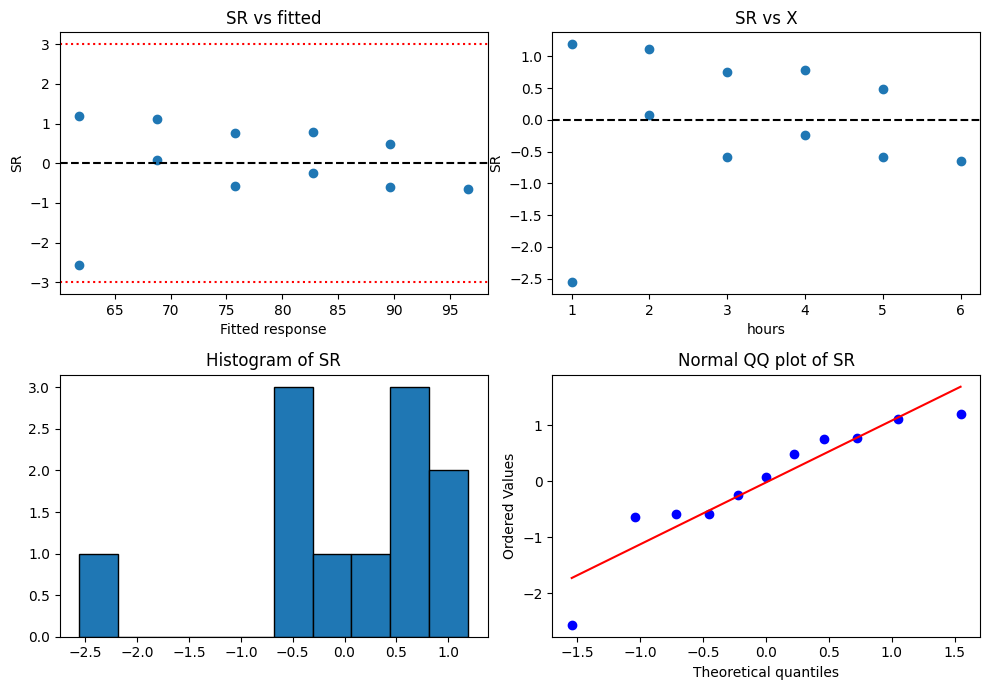

,SR,CooksD
8,-2.559128,1.237059


In [111]:
# EXAMPLE VALUES EXPLAINED: 3 is the course standardised-residual screening
# threshold and 1 the Cook-distance screening threshold. 2-by-2, bins=10 and figsize
# control layout only; plot coordinates/diagnostics come from the fit. The printed
# counts sum Boolean flags for SR outliers, influential points, their union and
# their overlap; they are not supplied data counts.
# REPLACE FOR YOUR QUESTION: Replace fitted model and optional predictor Series,
# keeping fitted-row alignment. Thresholds are investigation rules, not automatic
# deletion instructions.


def regression_diagnostics(fitted_model, predictor=None):
    inf = fitted_model.get_influence()
    fitted = fitted_model.fittedvalues
    sr = pd.Series(inf.resid_studentized_internal, index=fitted.index, name="SR")
    cooks = pd.Series(inf.cooks_distance[0], index=fitted.index, name="CooksD")
    outlier_flags = sr.abs() > 3
    influential_flags = cooks > 1
    print("Number of fitted rows:", len(fitted))
    print("Number with |SR|>3:", int(outlier_flags.sum()))
    print("Number with Cook D>1:", int(influential_flags.sum()))
    print("Number with either flag:", int((outlier_flags | influential_flags).sum()))
    print("Number with both flags:", int((outlier_flags & influential_flags).sum()))
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    axes[0, 0].scatter(fitted, sr)
    axes[0, 0].set(xlabel="Fitted response", ylabel="SR", title="SR vs fitted")
    if predictor is not None:
        aligned = predictor.loc[fitted.index]
        axes[0, 1].scatter(aligned, sr)
        axes[0, 1].set(xlabel=predictor.name or "X", ylabel="SR", title="SR vs X")
        axes[0, 1].axhline(0, color="black", linestyle="--")
    else:
        axes[0, 1].stem(np.arange(len(cooks)), cooks.to_numpy())
        axes[0, 1].axhline(1, color="red", linestyle="--")
        axes[0, 1].set_title("Cook's distance")
    axes[0, 0].axhline(0, color="black", linestyle="--")
    axes[0, 0].axhline(3, color="red", linestyle=":")
    axes[0, 0].axhline(-3, color="red", linestyle=":")
    axes[1, 0].hist(sr, bins=10, edgecolor="black")
    axes[1, 0].set_title("Histogram of SR")
    probplot(sr, plot=axes[1, 1])
    axes[1, 1].set_title("Normal QQ plot of SR")
    plt.tight_layout()
    plt.show()
    diagnostic_table = pd.concat([sr, cooks], axis=1)
    display(diagnostic_table.loc[(sr.abs() > 3) | (cooks > 1)])
    return diagnostic_table


diagnostics = regression_diagnostics(model, reg_df["hours"])


<a id="REG-05"></a>
## REG-05 · Inspect/remove a specified or influential point and refit

**Search:** regression drop influential outlier refit compare original Cook distance remove index slope

**Use when:** The question asks for sensitivity to removal of an observation.

**Remember:** Run REG-01 and REG-04 first to define model, reg_df and diagnostics. Cook D>1 and |SR|>3 are course screening rules, not automatic grounds for deletion.


**Example values explained:** Influential IDs are computed using Cook D>1. Slope and R² are refitted from the retained sample; no particular index is assumed in the live example.

**Replace for your question:** Use the observation(s) specified/justified by the question. Refit and compare with the original model; do not delete just to improve significance.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `smaller = data.drop(columns=["unused"])` | columns lists column labels; index lists row labels. A label is not necessarily a row position.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns data with those labels removed; assign it. Missing requested labels normally raise KeyError. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |


In [112]:
# EXAMPLE VALUES EXPLAINED: Influential IDs are computed using Cook D>1. Slope and
# R² are refitted from the retained sample; no particular index is assumed in the
# live example.
# REPLACE FOR YOUR QUESTION: Use the observation(s) specified/justified by the
# question. Refit and compare with the original model; do not delete just to improve
# significance.

influential_ids = diagnostics.index[diagnostics["CooksD"] > 1]
display(reg_df.loc[influential_ids])
refit_data = reg_df.drop(index=influential_ids)
# Specify response ~ predictors; fit() is needed to estimate coefficients.
refitted = smf.ols("score ~ hours", data=refit_data).fit()
display(
    pd.DataFrame(
        {
            "original": [model.params["hours"], model.rsquared],
            "refit": [refitted.params["hours"], refitted.rsquared],
        },
        index=["slope", "R²"],
    )
)
# To remove a specified label instead: refit_data = reg_df.drop(index=[chosen_label])


,id,group,name,city,score,hours,income,passed,date,tags
8,9,C,Ivy,SG,55.0,1.0,80.0,False,2026-01-09,math


,original,refit
slope,6.958065,6.200
R²,0.939326,0.973


<a id="REG-06"></a>
## REG-06 · Categorical predictors, chosen baseline and group predictions

**Search:** regression categorical C Treatment baseline reference dummy indicator groups coefficients prediction

**Use when:** Include a categorical variable and interpret differences holding other predictors fixed.

**Remember:** Run REG-01 first to define the complete-case reg_df. For ordinary string categories the default baseline is usually sorted first; pandas categorical ordering can change that. Specify Treatment explicitly when baseline matters. A k-level factor contributes k-1 indicators with an intercept.


**Example values explained:** A is the reference category; [3,3,3] keeps study hours fixed at 3 while comparing A/B/C. The three predictions are computed using the same fitted model.

**Replace for your question:** Replace the reference, comparison groups and common predictor value. Keeping numeric predictors equal isolates the adjusted category contrast.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ C(group, Treatment('A'))", data=data).fit()` | Use C(...) INSIDE a formula to encode a category; numerical codes also need C if they represent labels.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | Adds k-1 indicators with an intercept. This is a formula helper, not a DataFrame method. |
| `C(group, Treatment('A'))` | Put this inside the formula; the value specifies the reference category and must match an observed/encoded level.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | The omitted reference group has zero indicators; category coefficients are relative to it, holding other predictors fixed. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `predicted = model.predict(new_rows)` | new_rows is a DataFrame supplying EVERY original predictor and observed category labels; omit response. Formula API builds powers/interactions itself.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns fitted mean response on the model’s response scale. Intervals need get_prediction(...).summary_frame(...). |


In [113]:
# EXAMPLE VALUES EXPLAINED: A is the reference category; [3,3,3] keeps study hours
# fixed at 3 while comparing A/B/C. The three predictions are computed using the
# same fitted model.
# REPLACE FOR YOUR QUESTION: Replace the reference, comparison groups and common
# predictor value. Keeping numeric predictors equal isolates the adjusted category
# contrast.

# Specify response ~ predictors; fit() is needed to estimate coefficients.
categorical_model = smf.ols(
    "score ~ hours + C(group, Treatment('A'))", data=reg_df
).fit()
print(categorical_model.params)
new_groups = pd.DataFrame(
    {
        "hours": [3.0, 3.0, 3.0],
        "group": ["A", "B", "C"],
    }
)
# Return predicted mean on the fitted RESPONSE scale for these new predictor rows.
display(
    pd.concat(
        [new_groups, categorical_model.predict(new_groups).rename("predicted_score")],
        axis=1,
    )
)


Intercept                        57.869301
C(group, Treatment('A'))[T.B]    -1.598784
C(group, Treatment('A'))[T.C]    -4.908055
hours                             6.762918
dtype: float64


,hours,group,predicted_score
0,3.0,A,78.158055
1,3.0,B,76.559271
2,3.0,C,73.250000


<a id="REG-07"></a>
## REG-07 · Interactions: group-specific equations and effects

**Search:** regression interaction multiply colon star different slopes intercept conditional effect categorical

**Use when:** The slope differs by group; derive equations by substituting indicator values.

**Remember:** Run REG-01 first to define the complete-case reg_df. x*C(g) expands to x+C(g)+x:C(g). Main effects alone no longer describe every group/starting value. Keep the relevant main effects when retaining an interaction.


**Example values explained:** A/B are the two groups and x0=3 is the hours value used for their difference. Group B adds its indicator coefficient to the intercept and its interaction coefficient to the slope.

**Replace for your question:** Replace groups/reference/x0 and formula. The fixed 0/1 indicator coding defines group membership, not arbitrary observation values.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ C(group, Treatment('A'))", data=data).fit()` | Use C(...) INSIDE a formula to encode a category; numerical codes also need C if they represent labels.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | Adds k-1 indicators with an intercept. This is a formula helper, not a DataFrame method. |
| `C(group, Treatment('A'))` | Put this inside the formula; the value specifies the reference category and must match an observed/encoded level.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | The omitted reference group has zero indicators; category coefficients are relative to it, holding other predictors fixed. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |


In [114]:
# EXAMPLE VALUES EXPLAINED: A/B are the two groups and x0=3 is the hours value used
# for their difference. Group B adds its indicator coefficient to the intercept and
# its interaction coefficient to the slope.
# REPLACE FOR YOUR QUESTION: Replace groups/reference/x0 and formula. The fixed 0/1
# indicator coding defines group membership, not arbitrary observation values.

two_groups = reg_df.loc[reg_df["group"].isin(["A", "B"])].copy()
# Specify response ~ predictors; fit() is needed to estimate coefficients.
interaction = smf.ols("score ~ hours * C(group, Treatment('A'))", data=two_groups).fit()
p = interaction.params
print(p)
factor = "C(group, Treatment('A'))[T.B]"
interaction_key = "hours:" + factor
print("A intercept/slope:", p["Intercept"], p["hours"])
print("B intercept/slope:", p["Intercept"] + p[factor], p["hours"] + p[interaction_key])
# Question input: starting/new predictor value at which to evaluate the model.
x0 = 3
print("B-A predicted difference at hours=3:", p[factor] + p[interaction_key] * x0)


Intercept                              59.357143
C(group, Treatment('A'))[T.B]           0.414286
hours                                   6.357143
hours:C(group, Treatment('A'))[T.B]    -0.671429
dtype: float64
A intercept/slope: 59.35714285714283 6.357142857142896
B intercept/slope: 59.77142857142857 5.685714285714254
B-A predicted difference at hours=3: -1.6000000000001862


<a id="REG-08"></a>
## REG-08 · Quadratic/cubic terms and exact change x to x+d

**Search:** regression polynomial quadratic cubic I power higher order exact finite change increment slope derivative x+1 x+d

**Use when:** Fit a curved relationship that remains linear in the coefficients.

**Remember:** Run REG-01 first to define the complete-case reg_df. I(...) makes powers arithmetic in formula syntax. A one-unit finite change includes the quadratic +b2 term; it is not just the derivative.


**Example values explained:** x0=3 is the starting hours value; increment=1 is the example change in hours. The general finite-change formula works for any increment d: b1*d+b2*(2*x0*d+d**2). Power 2 creates a quadratic. The separately printed one-unit shortcut assumes d=1.

**Replace for your question:** Replace starting value, increment, dataset and model variables. Use the general finite change or subtract the two predictions for an arbitrary increment; the derivative is a different quantity.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ hours + I(hours**2)", data=data).fit()` | I(...) makes the expression inside arithmetic rather than formula operators; retain the main effect unless instructed otherwise. | Adds an arithmetic term such as a square. Formula ** by itself has a different meaning. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `predicted = model.predict(new_rows)` | new_rows is a DataFrame supplying EVERY original predictor and observed category labels; omit response. Formula API builds powers/interactions itself.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns fitted mean response on the model’s response scale. Intervals need get_prediction(...).summary_frame(...). |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |


In [115]:
# EXAMPLE VALUES EXPLAINED: x0=3 is the starting hours value; increment=1 is the
# example change in hours. The general finite-change formula works for any increment
# d: b1*d+b2*(2*x0*d+d**2). Power 2 creates a quadratic. The separately printed
# one-unit shortcut assumes d=1.
# REPLACE FOR YOUR QUESTION: Replace starting value, increment, dataset and model
# variables. Use the general finite change or subtract the two predictions for an
# arbitrary increment; the derivative is a different quantity.

# Specify response ~ predictors; fit() is needed to estimate coefficients.
quadratic = smf.ols("score ~ hours + I(hours**2)", data=reg_df).fit()
print(quadratic.params)
# Question input: starting/new predictor value at which to evaluate the model.
x0 = 3.0
# Question input: requested change d in hours; the general formula uses this value.
increment = 1.0
new = pd.DataFrame(
    {
        "hours": [x0, x0 + increment],
    }
)
# Return predicted mean on the fitted RESPONSE scale for these new predictor rows.
pred = quadratic.predict(new)
print("Exact change from x to x+increment:", pred.iloc[1] - pred.iloc[0])
b1 = quadratic.params["hours"]
b2 = quadratic.params["I(hours ** 2)"]
finite_change = b1 * increment + b2 * (2 * x0 * increment + increment**2)
print("Same change by formula:", finite_change)
print("One-unit change (only when increment=1):", b1 + b2 * (2 * x0 + 1))
print("Derivative at x (different quantity):", b1 + 2 * b2 * x0)
# Cubic variation: smf.ols('score ~ hours + I(hours**2) + I(hours**3)',data=reg_df).fit()


Intercept        51.224242
hours             9.790909
I(hours ** 2)    -0.424242
dtype: float64
Exact change from x to x+increment: 6.821212121212085
Same change by formula: 6.821212121212086
One-unit change (only when increment=1): 6.821212121212086
Derivative at x (different quantity): 7.245454545454516


<a id="REG-09"></a>
## REG-09 · Transform response: log, square root and reciprocal

**Search:** regression transform response log sqrt reciprocal inverse positivity back transform percent effect

**Use when:** Fit a transformed-response model when justified by diagnostics.

**Remember:** Run REG-01 first to define the complete-case reg_df. For log(Y), the linear predictor models E(log Y|X), not log E(Y|X). Exponentiating its prediction does not generally give the arithmetic conditional mean of Y without a correction. Compare residual patterns on transformed scales; do not compare R² across different responses.


**Example values explained:** The >0 filter ensures valid log/reciprocal inputs. 1 in 1/score defines the reciprocal, and 100 converts a multiplicative effect into percent. The forecast at hours=3 demonstrates exp of the fitted log response; that plug-in result is not automatically the arithmetic mean of score.

**Replace for your question:** Replace response/predictor and choose the justified transformation. Predictions after transformation are on a different scale; do not compare unlike-response R² values.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ hours + I(hours**2)", data=data).fit()` | I(...) makes the expression inside arithmetic rather than formula operators; retain the main effect unless instructed otherwise. | Adds an arithmetic term such as a square. Formula ** by itself has a different meaning. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `predicted = model.predict(new_rows)` | new_rows is a DataFrame supplying EVERY original predictor and observed category labels; omit response. Formula API builds powers/interactions itself.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns fitted mean response on the model’s response scale. Intervals need get_prediction(...).summary_frame(...). |


In [116]:
# EXAMPLE VALUES EXPLAINED: The >0 filter ensures valid log/reciprocal inputs. 1 in
# 1/score defines the reciprocal, and 100 converts a multiplicative effect into
# percent. The forecast at hours=3 demonstrates exp of the fitted log response; that
# plug-in result is not automatically the arithmetic mean of score.
# REPLACE FOR YOUR QUESTION: Replace response/predictor and choose the justified
# transformation. Predictions after transformation are on a different scale; do not
# compare unlike-response R² values.

positive = reg_df.loc[reg_df["score"] > 0].copy()
# Specify response ~ predictors; fit() is needed to estimate coefficients.
log_model = smf.ols("np.log(score) ~ hours", data=positive).fit()
sqrt_model = smf.ols("np.sqrt(score) ~ hours", data=positive).fit()
inverse_model = smf.ols("I(1 / score) ~ hours", data=positive).fit()
print("Log coefficients:", log_model.params)
print("Sqrt coefficients:", sqrt_model.params)
print("Reciprocal coefficients:", inverse_model.params)
beta = log_model.params["hours"]
print(
    "Log-scale fitted multiplicative factor per +1 hour:",
    np.exp(beta),
    "percent:",
    100 * np.expm1(beta),
)
transform_new = pd.DataFrame(
    {
        "hours": [3.0],
    }
)
# Return predicted mean on the fitted RESPONSE scale for these new predictor rows.
log_fitted = log_model.predict(transform_new)
print("Fitted E(log(score)|hours=3):", log_fitted)
print("exp(fitted log response), a plug-in back-transform:", np.exp(log_fitted))
# This is not automatically the arithmetic mean score on the original scale.


Log coefficients: Intercept    4.039434
hours        0.091970
dtype: float64
Sqrt coefficients: Intercept    7.479720
hours        0.399152
dtype: float64
Reciprocal coefficients: Intercept    0.017240
hours       -0.001237
dtype: float64
Log-scale fitted multiplicative factor per +1 hour: 1.0963324656794113 percent: 9.63324656794113
Fitted E(log(score)|hours=3): 0    4.315345
dtype: float64
exp(fitted log response), a plug-in back-transform: 0    74.839468
dtype: float64


<a id="REG-10"></a>
## REG-10 · Compare models on identical rows and response; compute OLS manually

**Search:** regression compare adjusted R2 same rows response OLS SSR SSE slope intercept formula

**Use when:** Compare candidate models fairly or calculate the fitted simple line directly.

**Remember:** Run REG-01 first to define the complete-case reg_df. R² cannot fall when adding predictors to an OLS model with the same response and rows; adjusted R² can. A nonsignificant slope means insufficient evidence of a linear mean relationship, not proof of independence.


**Example values explained:** Simple/multiple/quadratic models use the SAME complete rows. The squares and sums in the manual slope/SSR calculation are formula operations, not chosen data values; [0,1] extracts Pearson correlation.

**Replace for your question:** Replace response/predictors while keeping response scale and rows comparable. Additional regressors can raise ordinary R² even when they add little useful fit.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ hours + I(hours**2)", data=data).fit()` | I(...) makes the expression inside arithmetic rather than formula operators; retain the main effect unless instructed otherwise. | Adds an arithmetic term such as a square. Formula ** by itself has a different meaning. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `matrix = np.corrcoef(x,y)`<br>`r = matrix[0,1]` | Supply matched numeric vectors. Handle missing pairs before this calculation. | Returns a 2-by-2 correlation matrix for two vectors; [0,1] extracts their correlation. |


In [117]:
# EXAMPLE VALUES EXPLAINED: Simple/multiple/quadratic models use the SAME complete
# rows. The squares and sums in the manual slope/SSR calculation are formula
# operations, not chosen data values; [0,1] extracts Pearson correlation.
# REPLACE FOR YOUR QUESTION: Replace response/predictors while keeping response
# scale and rows comparable. Additional regressors can raise ordinary R² even when
# they add little useful fit.

# Specify response ~ predictors; fit() is needed to estimate coefficients.
simple = smf.ols("score ~ hours", data=reg_df).fit()
multiple = smf.ols("score ~ hours + income", data=reg_df).fit()
quad = smf.ols("score ~ hours + I(hours**2)", data=reg_df).fit()
display(
    pd.DataFrame(
        {
            "n": [m.nobs for m in [simple, multiple, quad]],
            "R²": [m.rsquared for m in [simple, multiple, quad]],
            "Adjusted R²": [m.rsquared_adj for m in [simple, multiple, quad]],
        },
        index=["Simple", "Multiple", "Quadratic"],
    )
)
x = reg_df["hours"].to_numpy()
y = reg_df["score"].to_numpy()
# Average values; for a Boolean mask this gives the True proportion.
b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()
residuals = y - (b0 + b1 * x)
print("Manual intercept,slope,SSR:", b0, b1, np.sum(residuals**2))
print(
    "R²=r² for simple regression with intercept:",
    simple.rsquared,
    np.corrcoef(x, y)[0, 1] ** 2,
)


,n,R²,Adjusted R²
Simple,11.0,0.939326,0.932584
Multiple,11.0,0.944665,0.930832
Quadratic,11.0,0.946712,0.933390


Manual intercept,slope,SSR: 54.86451612903225 6.958064516129033 88.13225806451612
R²=r² for simple regression with intercept: 0.9393256453429918 0.9393256453429919


<a id="REG-11"></a>
## REG-11 · Formula syntax, awkward column names and complete new prediction rows

**Search:** regression formula Q quoted name space dot hyphen numeric category C Treatment I power intercept no intercept new data prediction multiple predictors

**Use when:** A regression column name contains spaces/punctuation, a category is numerically coded, or a prediction needs several input columns.

**Remember:** Q("column name") protects spaces/punctuation inside formula strings; ordinary DataFrame indexing still uses the original column name. C(...) treats numeric codes as categories; I(x**2) makes a power arithmetic. + adds terms, x*g includes main effects and interaction, x:g is the interaction alone, and -1 removes the default intercept only when requested. Supply original predictors to predict; Patsy rebuilds squared/interaction terms. New categories absent from training cannot be predicted this way.

**Change these inputs:** Actual column names, categorical reference level, model terms and one complete row per prediction scenario. Q/C/I are Patsy formula helpers; do not overwrite these names.

**Read these outputs:** Exact coefficient keys and prediction-summary columns: mean is fitted mean response, mean_ci_* its confidence interval, obs_ci_* an individual-response interval. No manually added intercept column is needed with the formula API.


**Example values explained:** Exam score and Study hours are renamed demo columns to illustrate spaces in formula names. Category codes 0/1/2 mean groups A/B/C, with 0 as reference; they are not a continuous measurement. Two prediction rows hold hours=3 and income=120 fixed while comparing codes 0/1. alpha=.05 requests 95% intervals.

**Replace for your question:** Use your real column names, category coding/reference and all requested predictor values. Include every original predictor for each new row; keep Q/C/I syntax only where needed. Read exact coefficient names from the fitted model.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `coded = s.map({"Yes": 1, "No": 0})` | Mapping keys must match the original values exactly; values are the replacements. A function is another option.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False) | Returns recoded values; unlisted keys become missing. Assign to a new/existing column. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `smf.ols("score ~ C(group, Treatment('A'))", data=data).fit()` | Use C(...) INSIDE a formula to encode a category; numerical codes also need C if they represent labels.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | Adds k-1 indicators with an intercept. This is a formula helper, not a DataFrame method. |
| `smf.ols('Q("Exam score") ~ Q("Study hours")', data=data).fit()` | Use Q("exact column name") INSIDE the formula for names with spaces, dots or punctuation. | Reads the named column without renaming it; new prediction data uses that original column name. |
| `C(group, Treatment('A'))` | Put this inside the formula; the value specifies the reference category and must match an observed/encoded level.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | The omitted reference group has zero indicators; category coefficients are relative to it, holding other predictors fixed. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `table = model.get_prediction(new_rows).summary_frame(alpha=.05)` | alpha=.05 requests 95% intervals; each output row corresponds to one supplied scenario.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | mean is fitted response; mean_ci_* bounds its mean; obs_ci_* bounds a new individual response. |
| `prediction = model.get_prediction(new_rows)` | Supply a DataFrame of complete predictor scenarios with matching column names/categories.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns a prediction-results object; append .summary_frame(alpha=.05) to obtain numeric estimates and intervals. |
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |


In [118]:
# EXAMPLE VALUES EXPLAINED: Exam score and Study hours are renamed demo columns to
# illustrate spaces in formula names. Category codes 0/1/2 mean groups A/B/C, with 0
# as reference; they are not a continuous measurement. Two prediction rows hold
# hours=3 and income=120 fixed while comparing codes 0/1. alpha=.05 requests 95%
# intervals.
# REPLACE FOR YOUR QUESTION: Use your real column names, category coding/reference
# and all requested predictor values. Include every original predictor for each new
# row; keep Q/C/I syntax only where needed. Read exact coefficient names from the
# fitted model.

# This independent demo uses SETUP-01 data; it does not require REG-01.
formula_data = df.rename(
    columns={
        "score": "Exam score",
        "hours": "Study hours",
    }
).copy()
# Recode matching values; unlisted mapping keys become missing.
formula_data["group_code"] = formula_data["group"].map(
    {
        "A": 0,
        "B": 1,
        "C": 2,
    }
)
# Return rows complete in the stated columns; save the returned table.
formula_data = formula_data.dropna(
    subset=["Exam score", "Study hours", "income", "group_code"]
)
safe_formula = (
    'Q("Exam score") ~ Q("Study hours") + income + ' "C(group_code, Treatment(0))"
)
# Specify response ~ predictors; fit() is needed to estimate coefficients.
formula_model = smf.ols(safe_formula, data=formula_data).fit()
print("Actual coefficient names:", formula_model.params.index.tolist())
display(formula_model.params)

# Each row is ONE scenario; every predictor in the fitted formula is supplied.
formula_new = pd.DataFrame(
    {
        "Study hours": [3.0, 3.0],
        "income": [120.0, 120.0],
        "group_code": [0, 1],
    }
)
# Prediction table: mean_ci is for mean response, obs_ci for one new observation.
# Supply all original predictor columns; summary_frame provides estimates/intervals.
formula_predictions = formula_model.get_prediction(formula_new).summary_frame(
    alpha=0.05
)
display(pd.concat([formula_new, formula_predictions], axis=1))


Actual coefficient names: ['Intercept', 'C(group_code, Treatment(0))[T.1]', 'C(group_code, Treatment(0))[T.2]', 'Q("Study hours")', 'income']


Intercept                           46.201459
C(group_code, Treatment(0))[T.1]    -1.328260
C(group_code, Treatment(0))[T.2]    -5.007296
Q("Study hours")                     2.381596
income                               0.193484
dtype: float64

,Study hours,income,group_code,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,3.0,120.0,0,76.564312,1.774446,72.222400,80.906224,69.375081,83.753544
1,3.0,120.0,1,75.236053,1.494183,71.579918,78.892187,68.438982,82.033124


<a id="extra-recipes"></a>
# 12B · Extra Python, NumPy and pandas variations

Additional lookup recipes for common data-manipulation questions. These extend the core course examples without requiring additional packages.


<a id="PY-01"></a>
## PY-01 · Dictionaries, list comprehensions, enumerate, zip and while

**Search:** python dictionary dict keys values items get update list comprehension for while break enumerate zip loop

**Use when:** Use the basic Python patterns commonly needed for DataCamp and simulation.

**Remember:** List concatenation repeats/joins elements; NumPy arithmetic is elementwise. dict[key] raises if absent; dict.get supplies a default.


**Example values explained:** A/B labels and 10/20/30 values are demonstration dictionary/list entries. The list-comprehension condition >1 and loop counter limit 3 are chosen examples; range(1,5) yields 1–4.

**Replace for your question:** Replace entries, condition and iteration limits. Counter updates control a loop; they are not statistical formulas.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `value = mapping.get(key,default)` | Supply the dictionary key and fallback value; mapping[key] raises when the key is absent.<br><br>**Parameter choices and examples:**<br><br>**default:** Any fallback object when a key is absent: None, 0, a string, list, etc. The fallback is not added to the dictionary. **Default:** None.<br>**Examples:** lookup.get("A"); lookup.get("C","Unknown"); lookup.get("C",0) | Returns the stored value or default without adding a new dictionary entry. |
| `items = list(iterable)`<br>`settings = dict(color="blue")` | list converts an iterable; dict builds key/value associations. | Returns a Python container, not a pandas table or a NumPy array. |
| `mapping.keys()`<br>**OR**<br>`mapping.values()`<br>**OR**<br>`mapping.items()` | Call on a Python dictionary; items gives key/value pairs. | Returns iterable views; use list(...) for a list, or loop directly over them. |
| `mapping.keys()`<br>**OR**<br>`mapping.values()`<br>**OR**<br>`mapping.items()` | Call on a Python dictionary; items gives key/value pairs. | Returns iterable views; use list(...) for a list, or loop directly over them. |
| `mapping.keys()`<br>**OR**<br>`mapping.values()`<br>**OR**<br>`mapping.items()` | Call on a Python dictionary; items gives key/value pairs. | Returns iterable views; use list(...) for a list, or loop directly over them. |
| `for position,value in enumerate(items): ...` | Default first position is 0; start=1 changes numbering.<br><br>**Parameter choices and examples:**<br><br>**start:** Any integer starting index, usually 0 (Python positions) or 1 (human numbering). **Default:** 0.<br>**Examples:** enumerate(items); enumerate(items,start=1) | Yields an index/value pair each iteration; unpack both variables. |
| `for first,second in zip(values,weights): ...` | Supply matching ordered collections; ordinary zip stops at the shortest. | Pairs same-position items; it does not align pandas labels or verify equal lengths. |


In [119]:
# EXAMPLE VALUES EXPLAINED: A/B labels and 10/20/30 values are demonstration
# dictionary/list entries. The list-comprehension condition >1 and loop counter
# limit 3 are chosen examples; range(1,5) yields 1–4.
# REPLACE FOR YOUR QUESTION: Replace entries, condition and iteration limits.
# Counter updates control a loop; they are not statistical formulas.

lookup = {
    "A": "Control",
    "B": "Treatment",
}
print(lookup["A"], lookup.get("C", "Unknown"))
print(list(lookup.keys()), list(lookup.values()))
for key, value in lookup.items():
    print(key, value)
print([value**2 for value in [1, 2, 3] if value > 1])
for index, value in enumerate([10, 20, 30]):
    print(index, value)
for label, value in zip(["A", "B"], [10, 20]):
    print(label, value)
counter = 0
while counter < 3:
    counter += 1
print("Counter:", counter)


Control Unknown
['A', 'B'] ['Control', 'Treatment']
A Control
B Treatment
[4, 9]
0 10
1 20
2 30
A 10
B 20
Counter: 3


<a id="NP-16"></a>
## NP-16 · Weighted averages and counts of integer categories

**Search:** numpy average weighted weights frequency bincount histogram count_nonzero | numpy array ndarray

**Use when:** Calculate a mean from frequencies or tally integer-coded categories.

**Remember:** For probabilities summing to 1 use sum(x*p). Arbitrary weights/frequencies need division by their sum. bincount requires nonnegative integers.


**Example values explained:** Possible values 1/2/3 have frequencies 2/5/3 respectively: e.g. five observations equal 2. codes=[0,1,1,2,2,2] demonstrates integer category counts; minlength=4 includes a fourth unused code.

**Replace for your question:** Replace values and matching frequencies together. For arbitrary weights divide by their sum; normalised probabilities already sum to 1.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `weighted_mean = np.average(values,weights=weights)` | values and weights must match; weights need not sum to 1 because the function divides by their sum.<br><br>**Parameter choices and examples:**<br><br>**weights / axis:** weights may be None (equal weights) or a compatible numeric array with nonzero sum. axis chooses which dimension is averaged. Frequency/probability weights are normally nonnegative.<br>**Examples:** np.average([10,20],weights=[1,3]) -> 17.5; np.average(matrix,axis=0) | Returns sum(values*weights)/sum(weights). When weights are probabilities, sum(values*weights) is expectation. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `counts = np.bincount(codes,minlength=4)` | codes must be nonnegative integers; minlength includes absent codes up to the requested length.<br><br>**Parameter choices and examples:**<br><br>**weights / minlength:** codes must be nonnegative integers. weights=None counts entries, or numeric weights sums weights per code. minlength is a nonnegative minimum output length.<br>**Examples:** np.bincount([0,1,1],minlength=3) -> [1,2,0]; np.bincount([0,1,1],weights=[2,3,4]) -> [2,7]. | Returns counts indexed by code: counts[2] is the number of observations with code 2. |
| `count = np.count_nonzero(values > cutoff)` | Supply a Boolean condition, or nonzero numeric values; optional axis summarises by dimension.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the number of True/nonzero entries. |


In [120]:
# EXAMPLE VALUES EXPLAINED: Possible values 1/2/3 have frequencies 2/5/3
# respectively: e.g. five observations equal 2. codes=[0,1,1,2,2,2] demonstrates
# integer category counts; minlength=4 includes a fourth unused code.
# REPLACE FOR YOUR QUESTION: Replace values and matching frequencies together. For
# arbitrary weights divide by their sum; normalised probabilities already sum to 1.

values = np.array([1, 2, 3])
frequencies = np.array([2, 5, 3])
print("Weighted mean:", np.average(values, weights=frequencies))
print("Same by formula:", np.sum(values * frequencies) / frequencies.sum())
codes = np.array([0, 1, 1, 2, 2, 2])
print("Category counts:", np.bincount(codes, minlength=4))
print("Count entries above 2:", np.count_nonzero(arr > 2))


Weighted mean: 2.1
Same by formula: 2.1
Category counts: [1 2 3 0]
Count entries above 2: 5


<a id="NP-17"></a>
## NP-17 · Set operations and search in sorted arrays

**Search:** numpy union intersection difference setdiff intersect union1d unique searchsorted membership | numpy array ndarray

**Use when:** Compare value sets or find where a threshold belongs in sorted data.

**Remember:** Set functions return distinct values, usually sorted; they do not preserve multiplicities like a row filter does.


**Example values explained:** left/right arrays are arbitrary value sets containing a repeated 2. searchsorted target 1 shows the insertion locations before/after ties in sorted data.

**Replace for your question:** Replace sets/target. Set operations remove multiplicities; searchsorted returns POSITIONS, not probability values.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `np.intersect1d(a,b)`<br>**OR**<br>`np.union1d(a,b)`<br>**OR**<br>`np.setdiff1d(a,b)` | Supply the two value collections; setdiff1d means values in a but not b. | Returns distinct set-operation results, generally sorted; repeated observations are not preserved. |
| `np.intersect1d(a,b)`<br>**OR**<br>`np.union1d(a,b)`<br>**OR**<br>`np.setdiff1d(a,b)` | Supply the two value collections; setdiff1d means values in a but not b. | Returns distinct set-operation results, generally sorted; repeated observations are not preserved. |
| `np.intersect1d(a,b)`<br>**OR**<br>`np.union1d(a,b)`<br>**OR**<br>`np.setdiff1d(a,b)` | Supply the two value collections; setdiff1d means values in a but not b. | Returns distinct set-operation results, generally sorted; repeated observations are not preserved. |
| `np.sort(values)`<br>**OR**<br>`sorted(items,reverse=True)` | np.sort returns sorted array values; Python sorted returns a list. Descending NumPy form: np.sort(values)[::-1].<br><br>**Parameter choices and examples:**<br><br>**axis / kind:** For NumPy, axis=-1 uses the last dimension; axis=0 sorts within each column; axis=1 within each row; axis=None sorts flattened values. kind can be "quicksort", "mergesort", "heapsort", "stable". **Default:** axis=-1; kind="quicksort".<br>**Examples:** np.argsort(values,kind="stable"); np.sort(matrix,axis=1) | Returns sorted values without sorting the original in place; preserve paired row alignment when ordering data. |
| `positions = np.searchsorted(sorted_values,target,side="left")` | Input must already be sorted. side="left" inserts before equal values; "right" inserts after ties.<br><br>**Parameter choices and examples:**<br><br>**side:** "left" inserts before ties; "right" after ties. a must be sorted; v can be one target or several targets. **Default:** "left".<br>**Examples:** np.searchsorted([1,2,2,4],2,side="left") gives 1; side="right" gives 3. | Returns insertion POSITIONS that preserve sorting, not a Boolean membership test. |


In [121]:
# EXAMPLE VALUES EXPLAINED: left/right arrays are arbitrary value sets containing a
# repeated 2. searchsorted target 1 shows the insertion locations before/after ties
# in sorted data.
# REPLACE FOR YOUR QUESTION: Replace sets/target. Set operations remove
# multiplicities; searchsorted returns POSITIONS, not probability values.

left = np.array([1, 2, 2, 3])
right = np.array([2, 4])
print("Union:", np.union1d(left, right))
print("Intersection:", np.intersect1d(left, right))
print("Left only:", np.setdiff1d(left, right))
sorted_values = np.sort(arr)
print(
    "Insertion before/after ties of 1:",
    np.searchsorted(sorted_values, 1, side="left"),
    np.searchsorted(sorted_values, 1, side="right"),
)


Union: [1 2 3 4]
Intersection: [2]
Left only: [1 3]
Insertion before/after ties of 1: 0 2


<a id="NP-18"></a>
## NP-18 · Rounding, floor/ceiling and tolerant equality

**Search:** numpy round around floor ceil trunc allclose array_equal floating point tolerance decimal format | numpy array ndarray

**Use when:** Round displayed answers or compare floating-point results safely.

**Remember:** Keep full precision until the final answer. Standard rounding uses ties-to-even and binary floats can affect apparent decimal ties; sample-size calculations require ceil.


**Example values explained:** 1.2345,-1.2345,2.5 are rounding examples; .1+.2 versus .3 illustrates floating-point comparison; .4f means display four decimal places. 2 in round(...,2) requests two decimal places.

**Replace for your question:** Replace displayed values/precision as requested, but keep full-precision values for calculations. floor/ceil/trunc are different operations.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `mask = np.isclose(values, target, rtol=0, atol=1e-8)` | atol is absolute tolerance; rtol is relative tolerance. Test is abs(values-target)<=atol+rtol*abs(target); set rtol=0 for only the stated absolute tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns approximate-equality flags. 1e-8 means 0.00000001; default rtol is nonzero if omitted. |
| `np.array_equal(a,b)`<br>**OR**<br>`np.allclose(a,b)` | array_equal checks same shape and exact entries; allclose allows relative/absolute floating-point tolerance.<br><br>**Parameter choices and examples:**<br><br>**atol / rtol / equal_nan:** Nonnegative tolerance settings: abs(a-b)<=atol+rtol*abs(b). rtol=0 gives absolute tolerance only. equal_nan=True treats matching NaNs as equal; False does not. **Default:** atol=1e-8; rtol=1e-5; equal_nan=False.<br>**Examples:** np.isclose(values,3,atol=1e-8,rtol=0); np.allclose(a,b,rtol=1e-5,equal_nan=True) | Returns one Boolean; use elementwise isclose if you need a per-position mask. |
| `np.array_equal(a,b)`<br>**OR**<br>`np.allclose(a,b)` | array_equal checks same shape and exact entries; allclose allows relative/absolute floating-point tolerance.<br><br>**Parameter choices and examples:**<br><br>**equal_nan:** True regards matching NaN entries as equal; False does not. This is exact equality rather than tolerant closeness. **Default:** False.<br>**Examples:** np.array_equal(a,b,equal_nan=True) | Returns one Boolean; use elementwise isclose if you need a per-position mask. |


In [122]:
# EXAMPLE VALUES EXPLAINED: 1.2345,-1.2345,2.5 are rounding examples; .1+.2 versus
# .3 illustrates floating-point comparison; .4f means display four decimal places. 2
# in round(...,2) requests two decimal places.
# REPLACE FOR YOUR QUESTION: Replace displayed values/precision as requested, but
# keep full-precision values for calculations. floor/ceil/trunc are different
# operations.

values = np.array([1.2345, -1.2345, 2.5])
print(
    "Rounded:",
    np.round(values, 2),
    "floor:",
    np.floor(values),
    "ceil:",
    np.ceil(values),
    "truncated:",
    np.trunc(values),
)
# Approximate equality; with rtol=0, atol is the entire allowed absolute difference.
print(
    "Close?",
    np.isclose(0.1 + 0.2, 0.3),
    "All close?",
    np.allclose([0.1 + 0.2, 1], [0.3, 1]),
)
print("Exact array equality:", np.array_equal([1, 2], [1, 2]))
print("Display only:", f"{1/3:.4f}")


Rounded: [ 1.23 -1.23  2.5 ] floor: [ 1. -2.  2.] ceil: [ 2. -1.  3.] truncated: [ 1. -1.  2.]
Close? True All close? True
Exact array equality: True
Display only: 0.3333


<a id="PD-05"></a>
## PD-05 · Create tables/Series and convert to arrays, lists or dictionaries

**Search:** pandas DataFrame Series dict records from_dict to_numpy to_list to_dict index alignment | pandas dataframe series table

**Use when:** Enter small supplied datasets or convert between pandas and NumPy/Python structures.

**Remember:** pandas arithmetic aligns index labels. Use to_numpy only when you intentionally want positional arithmetic and have verified row ordering.


**Example values explained:** x=[1,2,3] and y=[4,6,8] are paired example measurements. A/B-indexed values 10/20 illustrate labelled Series. Reversed A/B labels in the final example show index alignment.

**Replace for your question:** Replace data values, column labels and index labels consistently. Arithmetic on pandas Series aligns labels, not row positions.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `mapping = s.to_dict()`<br>**OR**<br>`data.to_dict("records")` | Series maps labels to values; DataFrame orient="records" makes one dictionary per row.<br><br>**Parameter choices and examples:**<br><br>**orient:** For a DataFrame: "dict" (column -> row/value mapping), "list", "series", "split", "tight", "records" (list of row dictionaries), "index" (row -> column/value mapping). Series.to_dict always maps its index to values. **Default:** DataFrame "dict".<br>**Examples:** data.to_dict("records"); data.to_dict("list"); data.to_dict("index") | Returns a Python dictionary or list of dictionaries, depending on the selected form. |


In [123]:
# EXAMPLE VALUES EXPLAINED: x=[1,2,3] and y=[4,6,8] are paired example measurements.
# A/B-indexed values 10/20 illustrate labelled Series. Reversed A/B labels in the
# final example show index alignment.
# REPLACE FOR YOUR QUESTION: Replace data values, column labels and index labels
# consistently. Arithmetic on pandas Series aligns labels, not row positions.

small = pd.DataFrame(
    {
        "x": [1, 2, 3],
        "y": [4, 6, 8],
    }
)
series = pd.Series([10, 20], index=["A", "B"], name="value")
print(small.to_numpy(), small["x"].tolist(), small.to_dict("records"), sep="\n")
print(
    pd.DataFrame(
        [
            {
                "x": 1,
                "y": 2,
            },
            {
                "x": 3,
                "y": 4,
            },
        ]
    )
)
print(series)
print(
    "Label alignment:",
    pd.Series([1, 2], index=["A", "B"]) + pd.Series([10, 20], index=["B", "A"]),
)


[[1 4]
 [2 6]
 [3 8]]
[1, 2, 3]
[{'x': 1, 'y': 4}, {'x': 2, 'y': 6}, {'x': 3, 'y': 8}]
   x  y
0  1  2
1  3  4
A    10
B    20
Name: value, dtype: int64
Label alignment: A    21
B    12
dtype: int64


<a id="CLEAN-08"></a>
## CLEAN-08 · where/mask replacement while keeping table shape

**Search:** pandas where mask keep shape condition replacement clip numeric align | pandas dataframe series table

**Use when:** Replace values rather than drop rows; preserve the original shape.

**Remember:** df.loc[mask] reduces rows; where keeps matching values and replaces nonmatches. mask does the reverse. Think separately about existing missing values.


**Example values explained:** 80 is a keep-value cut-off; 70 replaces low scores; clipping limits 60/90 are chosen example limits. other=0 fills entries that fail the condition.

**Replace for your question:** Replace cut-offs/replacements only when justified. where/mask preserve shape; they do not select a smaller sample the way loc[mask] does.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `replaced = s.where(condition, other=0)` | Keeps True positions and replaces False positions. Default replacement is missing; s.mask instead replaces True positions.<br><br>**Parameter choices and examples:**<br><br>**condition / replacements:** For np.where: condition plus true/false choices, each scalar or broadcast-compatible array. pandas.where keeps True positions and uses other for False; mask does the reverse. other defaults to missing in pandas.<br>**Examples:** np.where(s>=70,"Pass","Fail"); s.where(s>=70,other=0); s.mask(s<70,other=0)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns the SAME shape. It is not the three-argument np.where function or a row filter. |
| `replaced = s.mask(condition, other=0)` | Replaces True positions and keeps False positions. Default replacement is missing; s.where instead keeps True positions.<br><br>**Parameter choices and examples:**<br><br>**condition / replacements:** For np.where: condition plus true/false choices, each scalar or broadcast-compatible array. pandas.where keeps True positions and uses other for False; mask does the reverse. other defaults to missing in pandas.<br>**Examples:** np.where(s>=70,"Pass","Fail"); s.where(s>=70,other=0); s.mask(s<70,other=0)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns the SAME shape. For fewer rows use data.loc[condition], not where/mask. |
| `np.clip(values,low,high)`<br>**OR**<br>`s.clip(lower=low,upper=high)` | Choose the lowest and highest permitted replacement values.<br><br>**Parameter choices and examples:**<br><br>**bounds:** Numeric lower/upper, or None for an unbounded side; NumPy uses positional bounds, pandas lower=/upper=.<br>**Examples:** np.clip(values,0,100); np.clip(values,0,None); s.clip(upper=100)<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns values capped at bounds; it replaces extremes instead of deleting rows. |


In [124]:
# EXAMPLE VALUES EXPLAINED: 80 is a keep-value cut-off; 70 replaces low scores;
# clipping limits 60/90 are chosen example limits. other=0 fills entries that fail
# the condition.
# REPLACE FOR YOUR QUESTION: Replace cut-offs/replacements only when justified.
# where/mask preserve shape; they do not select a smaller sample the way loc[mask]
# does.

s = df["score"]
print("Keep >=80; others missing:", s.where(s >= 80))
print("Replace values <70 with 70:", s.mask(s < 70, 70))
print("Clip scores to [60,90]:", s.clip(lower=60, upper=90))
numeric = df[["score", "income"]]
display(numeric.where(numeric >= 80, other=0))


Keep >=80; others missing: 0      NaN
1     85.0
2      NaN
3     91.0
4      NaN
5      NaN
6     82.0
7     88.0
8      NaN
9      NaN
10     NaN
11    95.0
Name: score, dtype: float64
Replace values <70 with 70: 0     72.0
1     85.0
2      NaN
3     91.0
4     70.0
5     78.0
6     82.0
7     88.0
8     70.0
9     70.0
10    74.0
11    95.0
Name: score, dtype: float64
Clip scores to [60,90]: 0     72.0
1     85.0
2      NaN
3     90.0
4     65.0
5     78.0
6     82.0
7     88.0
8     60.0
9     69.0
10    74.0
11    90.0
Name: score, dtype: float64


,score,income
0,0.0,100.0
1,85.0,150.0
2,0.0,120.0
3,91.0,180.0
4,0.0,90.0
5,0.0,130.0
6,82.0,140.0
7,88.0,170.0
8,0.0,80.0
9,0.0,110.0


<a id="GROUP-09"></a>
## GROUP-09 · Get one group, within-group row numbers and percentages

**Search:** groupby get_group cumcount ngroup value_counts normalize group proportions as_index observed | pandas dataframe series table

**Use when:** Extract one group or calculate within-group category proportions.

**Remember:** With categorical groupers, observed=True keeps only observed category combinations; observed=False can include unused categories. Choose deliberately.


**Example values explained:** B is the selected group. cumcount()+1 numbers each group's observations starting at 1 rather than 0. Summary means/counts and passed proportions are computed from data.

**Replace for your question:** Replace group/measurement columns and group label. The +1 is only a display numbering choice.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `one_group = data.groupby("group").get_group("A")` | Supply an existing group key; a multi-column grouping may need a tuple key. | Returns the original rows belonging to that group. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `number = data.groupby("group").cumcount() + 1` | Uses current row order within each group; ascending=False reverses counting.<br><br>**Parameter choices and examples:**<br><br>**ascending:** True numbers within each group from 0 upward; False numbers backward from group size-1. **Default:** True.<br>**Examples:** data.groupby("g").cumcount(ascending=False) | Returns within-group numbers starting at 0; add 1 if numbering should start at 1. |
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `data.groupby("group").agg(avg=("score", "mean"), n=("id", "size"))` | Named tuples are (input column, aggregation). For selected columns, .agg(["mean", "std"]) requests several summaries.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum")<br><br>**named output columns:** Names before = are your chosen output names; each tuple supplies an existing input column and aggregation string/function.<br>**Examples:** data.groupby("g").agg(mean_x=("x","mean"), n=("id","size")) | Returns group-level summaries, usually one row per group; size counts rows, count counts nonmissing values. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `group_n = data.groupby("group").size()` | size counts every row in a group, including rows with a missing measurement. count on a selected column counts its observed values instead. | Returns one row count per group. In named agg, n=("id","size") requests this row count. |


In [125]:
# EXAMPLE VALUES EXPLAINED: B is the selected group. cumcount()+1 numbers each
# group's observations starting at 1 rather than 0. Summary means/counts and passed
# proportions are computed from data.
# REPLACE FOR YOUR QUESTION: Replace group/measurement columns and group label. The
# +1 is only a display numbering choice.

# Choose groups first, then append the required summary or row-aligned transform.
print(df.groupby("group").get_group("B"))
print("Within-group row numbers:", df.groupby("group").cumcount() + 1)
# Count categories; normalize=True changes counts to proportions.
print(
    "Within-group passed proportions:",
    df.groupby("group")["passed"].value_counts(normalize=True),
)
display(
    df.groupby("group", as_index=False).agg(
        mean_score=("score", "mean"), n=("id", "size")
    )
)


   id group   name city  score  hours  income  passed       date          tags
4   5     B    Eva   SG   65.0    1.0    90.0   False 2026-01-05  stats,python
5   6     B   Finn   KL   78.0    3.0   130.0    True 2026-01-06          math
6   7     B  Grace   SG   82.0    4.0   140.0    True 2026-01-07        python
7   8     B   Hari   KL   88.0    5.0   170.0    True 2026-01-08         stats
Within-group row numbers: 0     1
1     2
2     3
3     4
4     1
5     2
6     3
7     4
8     1
9     2
10    3
11    4
dtype: int64
Within-group passed proportions: group  passed
A      True      0.75
       False     0.25
B      True      0.75
       False     0.25
C      False     0.50
       True      0.50
Name: proportion, dtype: float64


,group,mean_score,n
0,A,82.666667,4
1,B,78.250000,4
2,C,73.250000,4


<a id="audit-helpers"></a>
# 12C · Additional variations found in the course audit

These recipes fill gaps found by checking all lecture notebooks and tutorial solution code. They run after SETUP-01 without needing the earlier regression examples.


<a id="SETUP-02"></a>
## SETUP-02 · Check the active interpreter and packages without changing anything

**Search:** kernel interpreter sys executable offline packages versions environment installation check

**Use when:** Confirm which Python is actually running and check the installed package versions.

**Remember:** Selecting a different VS Code kernel selects a different installed package set. This check never installs, updates or modifies an environment.


**Example values explained:** No artificial data values are supplied: the interpreter path and package versions are read from the currently running Python.

**Replace for your question:** Choose the correct kernel outside this code. Do not copy version numbers as exam inputs or install packages during an offline exam.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `path = Path("data")`<br>**OR**<br>`"exam.csv"` | Import Path from pathlib; / joins path components. | Returns a path object. pd.read_csv accepts it; constructing a path does not read/write a file. |
| `s.str.split(",")`<br>**OR**<br>`text.split(",")` | sep chooses the delimiter. pandas expand=True makes separate columns; default gives lists in each row.<br><br>**Parameter choices and examples:**<br><br>**pat / n / expand:** Delimiter can be a string or None (whitespace). n=-1 splits all, positive n limits splits. pandas expand=False gives lists per row; True gives columns. Python str.split returns a list and has no expand option.<br>**Examples:** s.str.split(",",expand=True); "A,B,C".split(",",1) gives ["A","B,C"]. | Returns split components; Python str.split returns one list. |
| `hasattr(object,"name")`<br>**OR**<br>`importlib.metadata.version("pandas")` | hasattr checks an attribute; __import__ loads a named module; version reads installed package metadata. | Supports interpreter/package checking; it does not install or update anything. |


In [126]:
# EXAMPLE VALUES EXPLAINED: No artificial data values are supplied: the interpreter
# path and package versions are read from the currently running Python.
# REPLACE FOR YOUR QUESTION: Choose the correct kernel outside this code. Do not
# copy version numbers as exam inputs or install packages during an offline exam.

import sys
import importlib.metadata

print("Active Python:", sys.executable)
print("Interpreter path:", Path(sys.executable))
print("Version:", sys.version.split()[0])
for package in ["numpy", "pandas", "scipy", "matplotlib", "statsmodels", "ipykernel"]:
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, "NOT INSTALLED IN THIS INTERPRETER")


Active Python: /Users/ananya/st1131_tutorials/venv-st1131/bin/python
Interpreter path: /Users/ananya/st1131_tutorials/venv-st1131/bin/python
Version: 3.8.1
numpy 1.24.4
pandas 2.0.3
scipy 1.10.1
matplotlib 3.7.5
statsmodels 0.14.1
ipykernel 6.29.5


<a id="PY-02"></a>
## PY-02 · Basic types, list/string methods, nested lists and loops

**Search:** python bool int str float type list append remove index count nested list copy range for enumerate

**Use when:** Read or write basic Python expressions as practised in the introductory material.

**Remember:** append/remove return None, so do not assign their return values to your list. A list slice copies the outer list only; use deepcopy when nested mutable objects also need independent copies.


**Example values explained:** 3.9 demonstrates truncating conversion to int; 0 versus string '0' demonstrates truthiness. Lists and nested-list numbers are arbitrary examples; 999 makes a copied-list change easy to see; range(1,5) produces 1–4.

**Replace for your question:** Replace demonstration data/positions/loop bounds as required. Do not use 999 as a default missing-value replacement.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `items.append(value)`<br>**OR**<br>`items.remove(value)` | append adds one item at the end; remove deletes the FIRST matching item and raises if it is absent. | Changes the Python list in place and returns None; do not write items = items.append(...). |
| `position = items.index(value)`<br>**OR**<br>`text.index("r")` | Supply the value/substring to find; this is a Python list/string method. | Returns the first POSITION and raises if absent. A pandas .index attribute instead holds all row labels. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |
| `items.append(value)`<br>**OR**<br>`items.remove(value)` | append adds one item at the end; remove deletes the FIRST matching item and raises if it is absent. | Changes the Python list in place and returns None; do not write items = items.append(...). |
| `s.str.lower()`<br>**OR**<br>`s.str.upper()`<br>**OR**<br>`s.str.casefold()` | lower/upper standardise case; casefold is useful for caseless matching. Python text.lower() etc. work on one string. | Returns transformed text. Assign the cleaned values or compare the returned Series directly. |
| `independent = copy.deepcopy(nested_list)` | Import copy; supply the nested mutable object. | Copies nested lists too. A simple outer-list slice would still share the inner lists. |
| `range(start,stop,step)` | start included, stop EXCLUDED; defaults start=0 and step=1.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Integer bounds; stop excluded; step cannot be zero. Positive step increases, negative decreases.<br>**Examples:** range(5); range(1,5); range(5,0,-1) | Produces integer loop positions; range(1,5) visits 1,2,3,4. |


In [127]:
# EXAMPLE VALUES EXPLAINED: 3.9 demonstrates truncating conversion to int; 0 versus
# string '0' demonstrates truthiness. Lists and nested-list numbers are arbitrary
# examples; 999 makes a copied-list change easy to see; range(1,5) produces 1–4.
# REPLACE FOR YOUR QUESTION: Replace demonstration data/positions/loop bounds as
# required. Do not use 999 as a default missing-value replacement.

print(int(3.9), float(2), str(10), bool(0), bool("0"))
items = [5, 6, 6, 2, 3]
items.append(9)
print("First position of 6:", items.index(6), "Count of 6:", items.count(6))
items.remove(6)  # removes FIRST matching value; mutates the list
print(items)
text = "aaron"
print(text.count("a"), text.index("r"), text.upper())
matrix_list = [
    [1, 2],  # Row 1
    [3, 4],  # Row 2
]
print(matrix_list[1][0])
import copy

independent_nested = copy.deepcopy(matrix_list)
independent_nested[0][0] = 999
print("Original nested list:", matrix_list)
totals = []
for value in range(1, 5):
    totals.append(value**2)
print(totals)


3 2.0 10 False True
First position of 6: 1 Count of 6: 2
[5, 6, 2, 3, 9]
2 2 AARON
3
Original nested list: [[1, 2], [3, 4]]
[1, 4, 9, 16]


<a id="NP-19"></a>
## NP-19 · Minimum/maximum aliases and all NaN-aware summaries

**Search:** numpy amin amax min max nanvar nanstd nanmedian nanquantile sample missing | numpy array ndarray

**Use when:** Recognise the alternative NumPy function names appearing in the lecture code.


**Example values explained:** [1,2,NaN,4] is an example sample with one missing entry; .25/.5/.75 request quartiles. ddof=1 chooses SAMPLE variance/SD.

**Replace for your question:** Replace the data, retaining the appropriate missing-value and sample/population convention.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.amin(values)`<br>**OR**<br>`np.amax(values)` | Optional axis chooses the dimension to reduce; aliases for NumPy min/max.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns the smallest/largest value, not its position. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.amin(values)`<br>**OR**<br>`np.amax(values)` | Optional axis chooses the dimension to reduce; aliases for NumPy min/max.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns the smallest/largest value, not its position. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |
| `np.nanmean(values)`<br>**OR**<br>`np.nanstd(values,ddof=1)`<br>**OR**<br>`np.nanquantile(values,.5)` | These versions ignore NaNs; ddof and quantile probabilities retain their ordinary meanings.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns summaries using observed entries. Infinity is not ignored merely because a function name starts with nan. |


In [128]:
# EXAMPLE VALUES EXPLAINED: [1,2,NaN,4] is an example sample with one missing entry;
# .25/.5/.75 request quartiles. ddof=1 chooses SAMPLE variance/SD.
# REPLACE FOR YOUR QUESTION: Replace the data, retaining the appropriate
# missing-value and sample/population convention.

print("Minimum aliases:", np.min(arr), np.amin(arr))
print("Maximum aliases:", np.max(arr), np.amax(arr))
missing_array = np.array([1.0, 2.0, np.nan, 4.0])
print("Mean/median:", np.nanmean(missing_array), np.nanmedian(missing_array))
print(
    "Sample variance/SD:",
    np.nanvar(missing_array, ddof=1),
    np.nanstd(missing_array, ddof=1),
)
print("NaN-aware quartiles:", np.nanquantile(missing_array, [0.25, 0.5, 0.75]))


Minimum aliases: 1.0 1.0
Maximum aliases: 9.0 9.0
Mean/median: 2.3333333333333335 2.0
Sample variance/SD: 2.333333333333333 1.5275252316519465
NaN-aware quartiles: [1.5 2.  3. ]


<a id="NP-20"></a>
## NP-20 · SciPy random draws and gamma/exponential parameterisation

**Search:** numpy scipy rvs binom.rvs gamma shape scale rate exponential random simulation | numpy array ndarray

**Use when:** Recognise the lecture’s alternative random-draw APIs and right-skewed population generator.

**Remember:** NumPy exponential scale is its mean, which is 1/rate. NumPy gamma scale is not a rate. These are simulation APIs used to illustrate sampling distributions, not additional required inference tests.


**Example values explained:** 1131 is a seed; binomial(10,.25,size=5) gives five counts from ten trials with success probability .25. Gamma shape=3/scale=2900 describes a skewed example population; 10000 is simulation size. Exponential rate .2 corresponds to scale=5.

**Replace for your question:** Replace generating distribution parameters/sample counts and seed. Gamma/exponential SCALE is not the same as a rate.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `draws = binom.rvs(n,p,size=N)` | Provide the distribution parameters and desired number/shape of draws. Normal rvs uses loc/scale.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample. | Returns random draws; size is simulation output count, while binomial n is trials per draw. |
| `counts = np.random.binomial(n,p,size=N)` | n trials per experiment, p success probability, N simulated experiments.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns success COUNTS; divide by n to obtain simulated sample proportions. |
| `draws = np.random.gamma(shape=3,scale=2900,size=n)` | shape and scale are population parameters; gamma mean=shape*scale and variance=shape*scale**2.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**shape / scale:** Nonnegative numeric shape/scale for NumPy draws; use positive values for a nondegenerate gamma distribution. Mean=shape*scale; variance=shape*scale**2.<br>**Examples:** np.random.gamma(shape=3,scale=2900,size=25) | Returns right-skewed observations in these simulation examples; do not substitute rate for scale. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `draws = np.random.exponential(scale=1/rate,size=(N,n))` | scale is MEAN (also SD), not rate; if mean is given use scale=mean directly.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**scale:** Nonnegative numeric mean (also SD); positive gives the ordinary exponential distribution. If rate r is given use scale=1/r, requiring r>0.<br>**Examples:** np.random.exponential(scale=5,size=25); np.random.exponential(scale=1/.2,size=25) | Returns positive right-skewed draws; each row is one sample when size=(N,n). |


In [129]:
# EXAMPLE VALUES EXPLAINED: 1131 is a seed; binomial(10,.25,size=5) gives five
# counts from ten trials with success probability .25. Gamma shape=3/scale=2900
# describes a skewed example population; 10000 is simulation size. Exponential rate
# .2 corresponds to scale=5.
# REPLACE FOR YOUR QUESTION: Replace generating distribution parameters/sample
# counts and seed. Gamma/exponential SCALE is not the same as a rate.

np.random.seed(1131)
print("SciPy binomial draws:", binom.rvs(10, 0.25, size=5))
print("NumPy binomial draws:", np.random.binomial(10, 0.25, size=5))
# Distribution input: gamma shape parameter.
shape = 3
# Distribution input: gamma scale parameter, not rate.
scale = 2900
gamma_population = np.random.gamma(shape, scale, size=10000)
print("Gamma theoretical mean/SD:", shape * scale, np.sqrt(shape) * scale)
# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print("Simulated mean/SD:", gamma_population.mean(), gamma_population.std(ddof=1))
# Distribution input: exponential rate; scale = 1/rate.
rate = 0.2
print("Exponential with rate .2:", np.random.exponential(scale=1 / rate, size=5))


SciPy binomial draws: [2 1 4 5 2]
NumPy binomial draws: [3 1 2 1 4]
Gamma theoretical mean/SD: 8700 5022.9473419497435
Simulated mean/SD: 8753.386039245357 5023.432910086688
Exponential with rate .2: [ 1.20542611  1.19585657  7.30217695  0.97089515 17.17211284]


<a id="GROUP-10"></a>
## GROUP-10 · Normalise an existing count table by row/column totals

**Search:** pandas div divide table row column percentages axis sum conditional normalization existing counts | pandas dataframe series table

**Use when:** The question supplies a frequency table rather than individual records.

**Remember:** div(...,axis=0) aligns the denominator Series with ROW LABELS. div(...,axis=1) aligns it with COLUMN LABELS. The sum axis selects the totals; the div axis selects label alignment.


**Example values explained:** On-campus counts are 20 public,55 walk/cycle,5 private; off-campus counts are 75,15,30 in that SAME column order. Totals/percentages are calculated from the table, not entered probabilities.

**Replace for your question:** Replace every cell count and the corresponding row/column labels. Choose row/column/overall normalisation according to the conditioning in the question.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `table.div(row_totals, axis=0)` | axis=0 aligns a denominator Series to row labels; axis=1 aligns it to column labels.<br><br>**Parameter choices and examples:**<br><br>**axis:** 0/"index" aligns a denominator Series to ROW labels; 1/"columns" aligns to COLUMN labels. This differs from reduction axis, which identifies the dimension being removed. **Default:** "columns" for DataFrame.div.<br>**Examples:** tab.div(tab.sum(axis=1),axis=0); tab.div(tab.sum(axis=0),axis=1) | Returns elementwise quotients. For row percentages: table.div(table.sum(axis=1), axis=0)*100. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values = data["score"].to_numpy()` | Use on a Series for 1D values or a DataFrame for a 2D array. | Returns a NumPy array without index/column labels; verify row ordering before positional arithmetic. |


In [130]:
# EXAMPLE VALUES EXPLAINED: On-campus counts are 20 public,55 walk/cycle,5 private;
# off-campus counts are 75,15,30 in that SAME column order. Totals/percentages are
# calculated from the table, not entered probabilities.
# REPLACE FOR YOUR QUESTION: Replace every cell count and the corresponding
# row/column labels. Choose row/column/overall normalisation according to the
# conditioning in the question.

counts_table = pd.DataFrame(
    [
        [20, 55, 5],  # On campus: Public, Walk/Cycle, Private
        [75, 15, 30],  # Off campus: Public, Walk/Cycle, Private
    ],
    index=["On campus", "Off campus"],
    columns=["Public", "Walk/Cycle", "Private"],
)
row_percent = counts_table.div(counts_table.sum(axis=1), axis=0) * 100
column_percent = counts_table.div(counts_table.sum(axis=0), axis=1) * 100
overall_percent = counts_table / counts_table.to_numpy().sum() * 100
display(row_percent)
display(column_percent)
display(overall_percent)


,Public,Walk/Cycle,Private
On campus,25.0,68.75,6.25
Off campus,62.5,12.50,25.00


,Public,Walk/Cycle,Private
On campus,21.052632,78.571429,14.285714
Off campus,78.947368,21.428571,85.714286


,Public,Walk/Cycle,Private
On campus,10.0,27.5,2.5
Off campus,37.5,7.5,15.0


<a id="PLOT-09"></a>
## PLOT-09 · Manually position grouped bars, add heights and customise axes

**Search:** matplotlib manual grouped bar width get_height get_width get_x set_xticks xlim ylim labels annotation

**Use when:** Use the alternative manual bar-positioning method shown in Tutorial 2.


**Example values explained:** The two count rows are the transport example in GROUP-10; denominators 80 and 120 are their ROW TOTALS. 100 converts to percent. width=.35 and offsets are only bar spacing; axis limits 0–80 fit this display.

**Replace for your question:** Replace counts/labels and recompute row totals from your data. Bar width, figure size and plotting limits are presentation choices, not population parameters.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `ax.bar(positions,heights,width=.35)`<br>**OR**<br>`counts.plot.bar(rot=0)` | Manual bar uses x positions and heights; pandas plot.bar uses index labels and values. stacked=True stacks multiple series.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**width:** For plt.bar/ax.bar, a positive scalar or compatible array gives bar width in x-coordinate units. For pandas .plot.bar, width controls bar/group allocation.<br>**Examples:** ax.bar(positions,heights,width=.35); ax.bar(positions+.35,other_heights,width=.35)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Returns plot artists/Axes. Counts, proportions and percentages are different inputs; choose the intended denominator first. |
| `ax.text(x,y,"label")`<br>**OR**<br>`plt.annotate("name",(x,y))` | Supply the data-coordinate location and text; ha/va control alignment and fontsize size.<br><br>**Parameter choices and examples:**<br><br>**ha / va / fontsize:** ha: "left", "center", "right". va: "bottom", "baseline", "center", "center_baseline", "top". fontsize can be a positive number (points) or a named size such as "small"/"large".<br>**Examples:** ax.text(x,y,"label",ha="center",va="bottom",fontsize=9) | Adds labels to a plot. Use the same row as the plotted point when labelling observations. |
| `bar.get_x()`<br>**OR**<br>`bar.get_width()`<br>**OR**<br>`bar.get_height()` | Call on one rectangle returned by a bar plot. | Returns bar geometry; x+width/2 locates its centre, height gives the value to label. |
| `bar.get_x()`<br>**OR**<br>`bar.get_width()`<br>**OR**<br>`bar.get_height()` | Call on one rectangle returned by a bar plot. | Returns bar geometry; x+width/2 locates its centre, height gives the value to label. |
| `bar.get_x()`<br>**OR**<br>`bar.get_width()`<br>**OR**<br>`bar.get_height()` | Call on one rectangle returned by a bar plot. | Returns bar geometry; x+width/2 locates its centre, height gives the value to label. |
| `ax.set_xticks(positions,labels)`<br>**OR**<br>`plt.yticks(positions,labels)` | positions and labels must match in length; rotation adjusts text angle.<br><br>**Parameter choices and examples:**<br><br>**positions / labels / rotation:** positions are numeric tick locations; labels are an equal-length text list. rotation can be numeric degrees or "horizontal"/"vertical".<br>**Examples:** ax.set_xticks([0,1],["A","B"]); plt.xticks(rotation=45) | Changes tick positions/text; label order should match the plotted categories. |
| `plt.xlim(low,high)`<br>**OR**<br>`plt.ylim(low,high)`<br>**OR**<br>`ax.set_xlim(low,high)` | Supply displayed axis limits; these are not a filter or a statistical confidence interval.<br><br>**Parameter choices and examples:**<br><br>**limits:** Two numeric endpoints; None for an unchanged endpoint. Reversing limits reverses the axis. These limits affect the graph, not which rows enter the calculation.<br>**Examples:** plt.xlim(0,10); plt.ylim(bottom=0); ax.set_xlim(10,0) | Changes the displayed range; observations outside it remain in the data/analysis. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `plt.xlim(low,high)`<br>**OR**<br>`plt.ylim(low,high)`<br>**OR**<br>`ax.set_xlim(low,high)` | Supply displayed axis limits; these are not a filter or a statistical confidence interval.<br><br>**Parameter choices and examples:**<br><br>**limits:** Two numeric endpoints; None for an unchanged endpoint. Reversing limits reverses the axis. These limits affect the graph, not which rows enter the calculation.<br>**Examples:** plt.xlim(0,10); plt.ylim(bottom=0); ax.set_xlim(10,0) | Changes the displayed range; observations outside it remain in the data/analysis. |
| `plt.xlim(low,high)`<br>**OR**<br>`plt.ylim(low,high)`<br>**OR**<br>`ax.set_xlim(low,high)` | Supply displayed axis limits; these are not a filter or a statistical confidence interval.<br><br>**Parameter choices and examples:**<br><br>**limits:** Two numeric endpoints; None for an unchanged endpoint. Reversing limits reverses the axis. These limits affect the graph, not which rows enter the calculation.<br>**Examples:** plt.xlim(0,10); plt.ylim(bottom=0); ax.set_xlim(10,0) | Changes the displayed range; observations outside it remain in the data/analysis. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


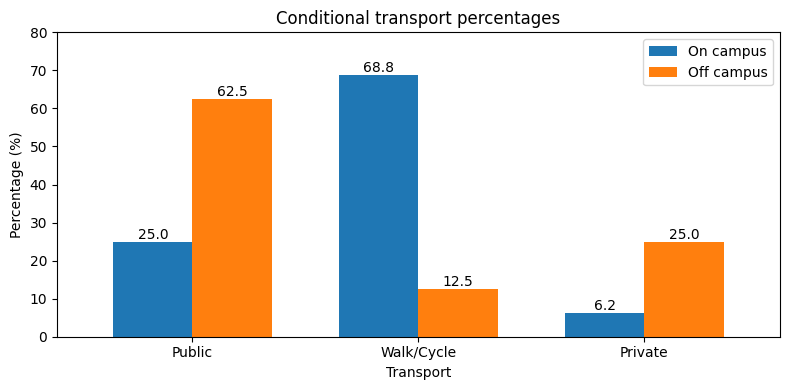

In [131]:
# EXAMPLE VALUES EXPLAINED: The two count rows are the transport example in
# GROUP-10; denominators 80 and 120 are their ROW TOTALS. 100 converts to percent.
# width=.35 and offsets are only bar spacing; axis limits 0–80 fit this display.
# REPLACE FOR YOUR QUESTION: Replace counts/labels and recompute row totals from
# your data. Bar width, figure size and plotting limits are presentation choices,
# not population parameters.

modes = ["Public", "Walk/Cycle", "Private"]
on_pct = np.array([20, 55, 5]) / 80 * 100
off_pct = np.array([75, 15, 30]) / 120 * 100
positions = np.arange(len(modes))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
for offset, values, label in [
    (-width / 2, on_pct, "On campus"),  # Row 1
    (width / 2, off_pct, "Off campus"),  # Row 2
]:
    bars = ax.bar(positions + offset, values, width=width, label=label)
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.1f}",
            ha="center",
            va="bottom",
        )
ax.set_xticks(positions, modes)
ax.set_xlim(-0.6, 2.6)
ax.set(
    xlabel="Transport",
    ylabel="Percentage (%)",
    title="Conditional transport percentages",
)
plt.ylim(0, 80)
plt.xlim(-0.6, 2.6)
plt.legend()
plt.tight_layout()
plt.show()


<a id="PLOT-10"></a>
## PLOT-10 · Annotate scatter points and colour individual boxplot groups

**Search:** matplotlib annotate labels iterrows point names outlier box facecolor set_facecolor

**Use when:** Identify points by name or assign different colours to boxes.


**Example values explained:** Point labels come from animal names. fontsize=7 and figure sizes control readability; A/B/C are the demo groups; three colours match those three boxes in order.

**Replace for your question:** Replace dataset/columns/group labels. Annotation names should come from the same row as the plotted coordinates.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `for row_label,row in data.iterrows(): ...` | Each iteration gives an index label and a Series of that row’s values. | Read row["column"]. Do not rely on modifying row to change the original table; use loc for assignment. |
| `ax.text(x,y,"label")`<br>**OR**<br>`plt.annotate("name",(x,y))` | Supply the data-coordinate location and text; ha/va control alignment and fontsize size.<br><br>**Parameter choices and examples:**<br><br>**ha / va / fontsize:** ha: "left", "center", "right". va: "bottom", "baseline", "center", "center_baseline", "top". fontsize can be a positive number (points) or a named size such as "small"/"large".<br>**Examples:** ax.text(x,y,"label",ha="center",va="bottom",fontsize=9) | Adds labels to a plot. Use the same row as the plotted point when labelling observations. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `course_boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Run SETUP-01 for the portable helper. Supply one numeric array per box; horizontal=True changes orientation. boxprops={"facecolor":"lightblue"} styles filled boxes.<br><br>**Parameter choices and examples:**<br><br>**horizontal / labels / patch_artist / boxprops:** horizontal=True gives horizontal boxes, False vertical. labels is one label per box or None. patch_artist=True enables filled patches, False lines. boxprops is a styling dictionary. **Default:** horizontal=False; patch_artist=False.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True,patch_artist=True,boxprops={"facecolor":"lightblue"}) | Returns artists; fliers contains flagged points. &#124;SR&#124;>3 regression outliers are a different rule from boxplot IQR fliers. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `for first,second in zip(values,weights): ...` | Supply matching ordered collections; ordinary zip stops at the shortest. | Pairs same-position items; it does not align pandas labels or verify equal lengths. |
| `box.set_facecolor("lightblue")` | Supply a colour; boxes need patch_artist=True to be filled.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Changes the chosen box/patch colour, retaining all measured values. |


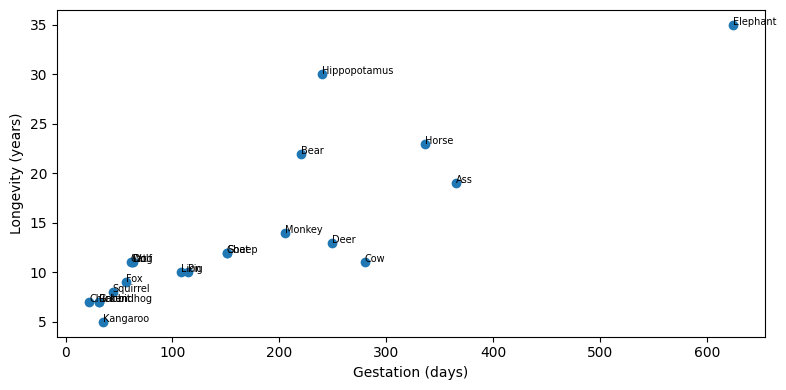

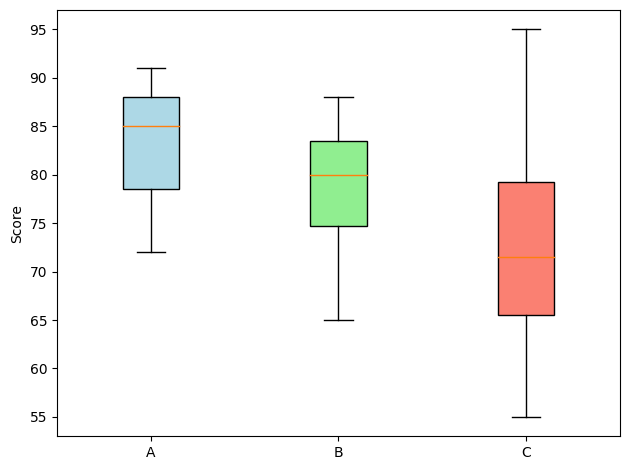

In [132]:
# EXAMPLE VALUES EXPLAINED: Point labels come from animal names. fontsize=7 and
# figure sizes control readability; A/B/C are the demo groups; three colours match
# those three boxes in order.
# REPLACE FOR YOUR QUESTION: Replace dataset/columns/group labels. Annotation names
# should come from the same row as the plotted coordinates.

animals_plot = pd.read_csv(DATA_DIR / "Animals.csv")
plt.figure(figsize=(8, 4))
plt.scatter(animals_plot["gestation"], animals_plot["longevity"])
for _, row in animals_plot.iterrows():
    plt.annotate(row["animal"], (row["gestation"], row["longevity"]), fontsize=7)
plt.xlabel("Gestation (days)")
plt.ylabel("Longevity (years)")
plt.tight_layout()
plt.show()
plt.figure()
# Return rows complete in the stated columns; save the returned table.
boxes = course_boxplot(
    [df.loc[df["group"].eq(g), "score"].dropna() for g in ["A", "B", "C"]],
    labels=["A", "B", "C"],
    patch_artist=True,
)
for box, colour in zip(boxes["boxes"], ["lightblue", "lightgreen", "salmon"]):
    box.set_facecolor(colour)
plt.ylabel("Score")
plt.tight_layout()
plt.show()


<a id="PLOT-11"></a>
## PLOT-11 · Draw confidence intervals as error bars

**Search:** confidence interval plot errorbar xerr yerr capsize yticks different confidence levels

**Use when:** Visualise interval estimates or the effect of changing confidence level.


**Example values explained:** estimate=.58 means a 58% sample proportion based on n=600; [.80,.95,.99] are compared confidence levels. .5 is the reference line, not automatically a null for every question.

**Replace for your question:** Replace estimate,n,confidence levels/reference. xerr contains COMPUTED margins of error; capsize and figsize are graphical settings.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.errorbar(estimates,positions,xerr=margins,fmt="o",capsize=5)` | xerr is distance from point to endpoint (MOE), not the endpoint itself. yerr creates vertical bars.<br><br>**Parameter choices and examples:**<br><br>**xerr / yerr / fmt / capsize:** Errors may be a nonnegative scalar, one value per point, or 2-by-N lower/upper errors. fmt="o" draws points, "none" only bars; capsize is nonnegative cap length in points.<br>**Examples:** plt.errorbar(x,y,xerr=.1,fmt="o",capsize=5); plt.errorbar(x,y,yerr=[lower_errors,upper_errors],fmt="none") | Draws estimates with error bars; compute statistically correct intervals before plotting. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `plt.axhline(0)`<br>**OR**<br>`plt.axvline(cutoff)` | axhline takes a y value, axvline an x value; color/linestyle are display settings.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Adds a reference line to the current axes; use ax.axhline/axvline for a chosen subplot. |
| `ax.set_xticks(positions,labels)`<br>**OR**<br>`plt.yticks(positions,labels)` | positions and labels must match in length; rotation adjusts text angle.<br><br>**Parameter choices and examples:**<br><br>**positions / labels / rotation:** positions are numeric tick locations; labels are an equal-length text list. rotation can be numeric degrees or "horizontal"/"vertical".<br>**Examples:** ax.set_xticks([0,1],["A","B"]); plt.xticks(rotation=45) | Changes tick positions/text; label order should match the plotted categories. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


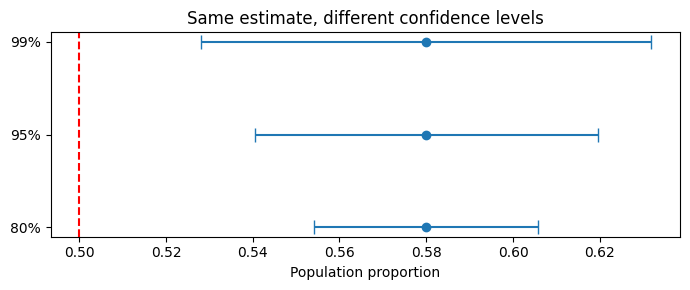

In [133]:
# EXAMPLE VALUES EXPLAINED: estimate=.58 means a 58% sample proportion based on
# n=600; [.80,.95,.99] are compared confidence levels. .5 is the reference line, not
# automatically a null for every question.
# REPLACE FOR YOUR QUESTION: Replace estimate,n,confidence levels/reference. xerr
# contains COMPUTED margins of error; capsize and figsize are graphical settings.

estimate, se = 0.58, np.sqrt(0.58 * 0.42 / 600)
levels = np.array([0.80, 0.95, 0.99])
moes = norm.ppf((1 + levels) / 2) * se
plt.figure(figsize=(7, 3))
plt.errorbar([estimate] * 3, np.arange(3), xerr=moes, fmt="o", capsize=5)
plt.axvline(0.5, color="red", linestyle="--")
plt.yticks(np.arange(3), ["80%", "95%", "99%"])
plt.xlabel("Population proportion")
plt.title("Same estimate, different confidence levels")
plt.tight_layout()
plt.show()


<a id="PLOT-12"></a>
## PLOT-12 · Compare t densities and normal empirical-rule probabilities

**Search:** t distribution pdf normal degrees freedom heavy tails empirical rule 68 95 99.7

**Use when:** See why a t multiplier differs from a normal multiplier and calculate the empirical-rule areas.

**Remember:** The approximately 68%,95%,99.7% rule applies to normal/bell-shaped distributions, not every symmetric distribution. A uniform distribution can be symmetric without being normal.


**Example values explained:** 2/11/199 are example t degrees of freedom; k=1/2/3 requests normal areas within 1/2/3 SD. -5..5 and 400 points define the displayed grid only.

**Replace for your question:** Choose the desired df and SD ranges. The normal curve here is standard N(0,1); approximately 68/95/99.7% is a normal-distribution rule.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `height = norm.pdf(x,loc=mu,scale=sigma)` | x can be one point or a plotting grid; scale is population SD.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns density HEIGHT, not probability. Use cdf differences or sf for areas. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |


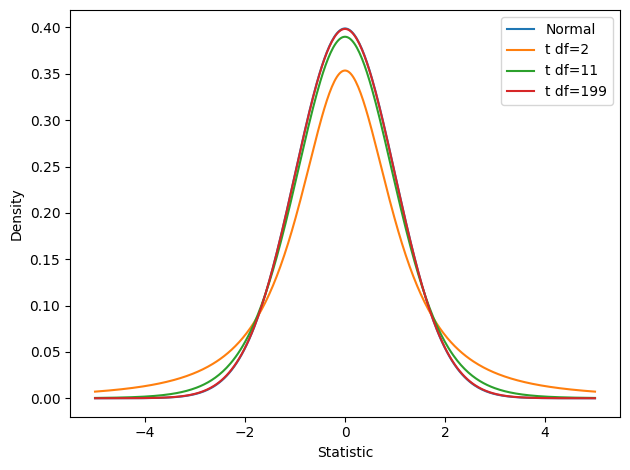

Normal probability within 1 SD: 0.6826894921370859
Normal probability within 2 SD: 0.9544997361036416
Normal probability within 3 SD: 0.9973002039367398


In [134]:
# EXAMPLE VALUES EXPLAINED: 2/11/199 are example t degrees of freedom; k=1/2/3
# requests normal areas within 1/2/3 SD. -5..5 and 400 points define the displayed
# grid only.
# REPLACE FOR YOUR QUESTION: Choose the desired df and SD ranges. The normal curve
# here is standard N(0,1); approximately 68/95/99.7% is a normal-distribution rule.

grid = np.linspace(-5, 5, 400)
plt.figure()
plt.plot(grid, norm.pdf(grid), label="Normal")
for degrees in [2, 11, 199]:
    plt.plot(grid, t.pdf(grid, df=degrees), label=f"t df={degrees}")
plt.xlabel("Statistic")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
for k in [1, 2, 3]:
    print(f"Normal probability within {k} SD:", norm.cdf(k) - norm.cdf(-k))


<a id="PLOT-13"></a>
## PLOT-13 · Construct the course QQ plot by hand

**Search:** QQ quantile theoretical observed manual standardise sort normal ppf plotting positions

**Use when:** Reproduce the sorted standardised values and theoretical quantiles in the lecture.

**Remember:** probplot uses its own plotting-position convention, so its point coordinates can differ slightly from this hand construction. Both check approximate linearity.


**Example values explained:** [14,13,1,20,7,14,2,19,8,10] is the lecture's sample of ten observations. .5 is the plotting-position half-step; [-2,2] gives endpoints for the reference LINE, not a data filter.

**Replace for your question:** Replace observations if checking another sample. Standardisation, sorting and theoretical quantiles are computed from those data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `np.sort(values)`<br>**OR**<br>`sorted(items,reverse=True)` | np.sort returns sorted array values; Python sorted returns a list. Descending NumPy form: np.sort(values)[::-1].<br><br>**Parameter choices and examples:**<br><br>**axis / kind:** For NumPy, axis=-1 uses the last dimension; axis=0 sorts within each column; axis=1 within each row; axis=None sorts flattened values. kind can be "quicksort", "mergesort", "heapsort", "stable". **Default:** axis=-1; kind="quicksort".<br>**Examples:** np.argsort(values,kind="stable"); np.sort(matrix,axis=1) | Returns sorted values without sorting the original in place; preserve paired row alignment when ordering data. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


,theoretical,observed
0,-1.644854,-1.521051
1,-1.036433,-1.365842
2,-0.674490,-0.589795
3,-0.385320,-0.434586
4,-0.125661,-0.124167
5,0.125661,0.341461
6,0.385320,0.496670
7,0.674490,0.496670
8,1.036433,1.272716
9,1.644854,1.427926


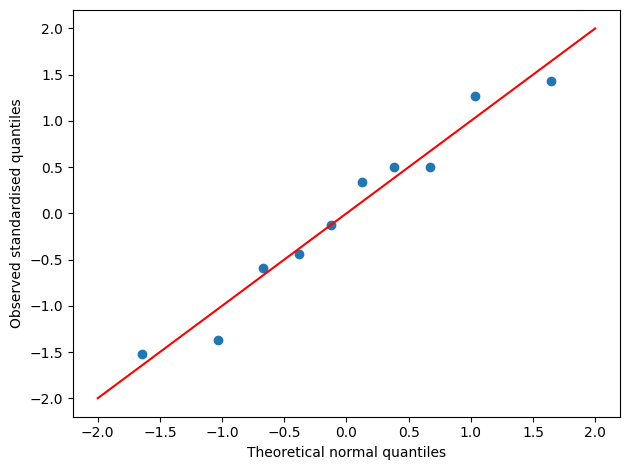

In [135]:
# EXAMPLE VALUES EXPLAINED: [14,13,1,20,7,14,2,19,8,10] is the lecture's sample of
# ten observations. .5 is the plotting-position half-step; [-2,2] gives endpoints
# for the reference LINE, not a data filter.
# REPLACE FOR YOUR QUESTION: Replace observations if checking another sample.
# Standardisation, sorting and theoretical quantiles are computed from those data.

qq_values = np.array([14, 13, 1, 20, 7, 14, 2, 19, 8, 10], dtype=float)
# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
z_values = (qq_values - qq_values.mean()) / qq_values.std(ddof=1)
observed = np.sort(z_values)
plotting_positions = (np.arange(1, len(qq_values) + 1) - 0.5) / len(qq_values)
theoretical = norm.ppf(plotting_positions)
display(
    pd.DataFrame(
        {
            "theoretical": theoretical,
            "observed": observed,
        }
    )
)
plt.figure()
plt.scatter(theoretical, observed)
plt.plot([-2, 2], [-2, 2], color="red")
plt.xlabel("Theoretical normal quantiles")
plt.ylabel("Observed standardised quantiles")
plt.tight_layout()
plt.show()


<a id="PROB-09"></a>
## PROB-09 · Translate a budget or cost threshold into a success count

**Search:** binomial budget exceed cost per event successes floor ceil risk diagnostic confirmatory testing

**Use when:** A monetary threshold applies to the number of positive tests or other successes.

**Remember:** Strictly exceeding and at least reaching a budget have different boundaries. For cost>=budget use binom.sf(ceil(budget/cost_each)-1,n,p).


**Example values explained:** sens=.993,spec=.903,prev=.05 are screening probabilities. n=12 people are tested; each positive costs 10000 monetary units; budget=100000 is the spending limit.

**Replace for your question:** Replace rates, number tested, cost per positive and budget. The largest affordable count is computed with floor; exceeding uses a strict tail.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |


In [136]:
# EXAMPLE VALUES EXPLAINED: sens=.993,spec=.903,prev=.05 are screening
# probabilities. n=12 people are tested; each positive costs 10000 monetary units;
# budget=100000 is the spending limit.
# REPLACE FOR YOUR QUESTION: Replace rates, number tested, cost per positive and
# budget. The largest affordable count is computed with floor; exceeding uses a
# strict tail.

# Question input: sensitivity P(positive | disease).
sens = 0.993
# Question input: specificity P(negative | no disease).
spec = 0.903
# Question input: prevalence P(disease), as a proportion.
prev = 0.05
p_positive = sens * prev + (1 - spec) * (1 - prev)
# Question input: number of people tested.
n = 12
# Question input: cost of each positive result in monetary units.
cost_each = 10000
# Question input: total available budget in the same units.
budget = 100000
# Cost = cost_each*X; exceeding means X > budget/cost_each.
largest_affordable = math.floor(budget / cost_each)
print(
    "Must have at least", largest_affordable + 1, "positive results to exceed budget."
)
print("Probability:", binom.sf(largest_affordable, n, p_positive))
print("Expected total confirmatory cost:", cost_each * n * p_positive)


Must have at least 11 positive results to exceed budget.
Probability: 4.865722734553222e-09
Expected total confirmatory cost: 17015.999999999996


<a id="TEST-10"></a>
## TEST-10 · Critical values and rejection regions for Z/t tests

**Search:** critical value rejection region left right two sided alpha quantile cutoff hypothesis test

**Use when:** The question asks for shaded rejection regions or critical cut-offs rather than only a p-value.

**Remember:** For a fixed dataset/test/alternative, changing alpha changes the decision threshold but not the p-value. Do not halve a two-sided p-value for a one-sided alternative pointing opposite to the observed effect.


**Example values explained:** alpha=.05 is significance, degrees=11 is the example t df, and observed_stat=2 is a made-up statistic to compare with critical values. Critical cut-offs are calculated quantiles.

**Replace for your question:** Replace alpha, relevant df and observed statistic. The division by 2 allocates two-sided tail probability; it is not an arbitrary tuning value.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `distribution = t(df=degrees)` | Supply degrees of freedom; this creates a frozen t distribution with those parameters stored.<br><br>**Parameter choices and examples:**<br><br>**df:** Positive degrees of freedom; may be a non-integer Welch df. For a one-sample or paired t calculation use n-1; pooled uses n1+n2-2.<br>**Examples:** distribution=t(df=11); distribution.sf(2); t.ppf(.975,df=29) | You can call distribution.cdf(statistic) or distribution.sf(statistic) without passing df again. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [137]:
# EXAMPLE VALUES EXPLAINED: alpha=.05 is significance, degrees=11 is the example t
# df, and observed_stat=2 is a made-up statistic to compare with critical values.
# Critical cut-offs are calculated quantiles.
# REPLACE FOR YOUR QUESTION: Replace alpha, relevant df and observed statistic. The
# division by 2 allocates two-sided tail probability; it is not an arbitrary tuning
# value.

# Decision/input level: .05 means 5% significance (or 1-confidence for a CI).
alpha = 0.05
# Example degrees of freedom; use the df for the actual test.
degrees = 11
# Example observed test-statistic value; replace with your statistic.
observed_stat = 2.0
for label, distribution in [
    ("Z", norm),  # Row 1
    ("t", t(df=degrees)),  # Row 2
]:
    left = distribution.ppf(alpha)
    right = distribution.ppf(1 - alpha)
    two = distribution.ppf(1 - alpha / 2)
    print(
        label,
        "Left reject if stat<=",
        left,
        "Right reject if stat>=",
        right,
        "Two-sided reject if |stat|>=",
        two,
    )
    print("Two-sided decision for stat=2:", abs(observed_stat) >= two)


Z Left reject if stat<= -1.6448536269514729 Right reject if stat>= 1.6448536269514722 Two-sided reject if |stat|>= 1.959963984540054
Two-sided decision for stat=2: True
t Left reject if stat<= -1.7958848187036696 Right reject if stat>= 1.7958848187036691 Two-sided reject if |stat|>= 2.200985160082949
Two-sided decision for stat=2: False


<a id="course-workflows"></a>
# 12D · Complete workflows on actual tutorial datasets

These examples use the real course column names and run after SETUP-01. They provide complete starting points for the most connected tutorial question types; change filenames, columns and hypotheses for the exam.


<a id="WF-01"></a>
## WF-01 · Animals: two-variable outliers, names and before/after correlation

**Search:** tutorial2 Animals Elephant correlation outliers both variables intersection union IQR remove named row

**Use when:** Tutorial 2 Q5: check a point against the IQR rule in each of two variables.

**Remember:** A scatterplot outlier, a univariate IQR outlier and an influential regression observation are three different concepts.


**Example values explained:** .25/.75 and 1.5 are quartile/fence conventions. Elephant is the named observation excluded in this tutorial comparison; values come from Animals.csv.

**Replace for your question:** Change file/columns and exclusion label only if your question asks for a different comparison. Do not assume the same animal is unusual in other data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `r = first.corr(second,method="pearson")` | Pearson is default; method="spearman" uses ranks. Series align by index and pairwise remove missing values.<br><br>**Parameter choices and examples:**<br><br>**method:** "pearson" linear correlation; "spearman" rank correlation; "kendall" Kendall rank correlation; a compatible callable is also allowed. **Default:** "pearson".<br>**Examples:** data["x"].corr(data["y"],method="pearson"); data["x"].corr(data["y"],method="spearman") | Returns correlation; for a DataFrame .corr() returns the matrix. Preserve correct pairs. |


In [138]:
# EXAMPLE VALUES EXPLAINED: .25/.75 and 1.5 are quartile/fence conventions. Elephant
# is the named observation excluded in this tutorial comparison; values come from
# Animals.csv.
# REPLACE FOR YOUR QUESTION: Change file/columns and exclusion label only if your
# question asks for a different comparison. Do not assume the same animal is unusual
# in other data.

animals_data = pd.read_csv(DATA_DIR / "Animals.csv")
measurement_cols = ["gestation", "longevity"]
# Return rows complete in the stated columns; save the returned table.
animals_complete = animals_data.dropna(subset=measurement_cols).copy()
q1 = animals_complete[measurement_cols].quantile(0.25)
q3 = animals_complete[measurement_cols].quantile(0.75)
iqr = q3 - q1
flags = animals_complete[measurement_cols].lt(q1 - 1.5 * iqr) | animals_complete[
    measurement_cols
].gt(q3 + 1.5 * iqr)
display(animals_complete.loc[flags.any(axis=1)])  # outlier in EITHER variable
display(animals_complete.loc[flags.all(axis=1)])  # outlier in BOTH variables
without_elephant = animals_complete.loc[
    animals_complete["animal"].ne("Elephant")
].copy()
print(
    "Original correlation:",
    animals_complete["gestation"].corr(animals_complete["longevity"]),
)
print(
    "Without Elephant:",
    without_elephant["gestation"].corr(without_elephant["longevity"]),
)


,animal,gestation,longevity
1,Bear,220,22
7,Elephant,624,35
11,Hippopotamus,240,30
12,Horse,336,23


,animal,gestation,longevity
7,Elephant,624,35


Original correlation: 0.8563872167705392
Without Elephant: 0.7520061783578592


<a id="WF-02"></a>
## WF-02 · App clicks: binary data to a one-proportion test

**Search:** tutorial8 AppClicks clicked binary success count sample proportion z test 0.12 device

**Use when:** Tutorial 8 Q4: obtain successes from a dataset, test against the old banner rate and report the right tail.

**Remember:** Do not count a missing response as failure unless that is how the question defines it. A subgroup question needs filtering BEFORE you compute both successes and n.


**Example values explained:** clicked is coded 0/1 for failure/success; p0=.12 is the OLD banner rate and alpha=.05 the decision level. The tiny Yes/No sequence is a separate three-observed-response demo.

**Replace for your question:** Replace dataset, success coding, null rate and significance level. Sample size is the observed response count, not the user_id magnitude.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `mask.any(axis=1)`<br>**OR**<br>`mask.all(axis=1)` | any means at least one True; all means every entry True. For row conditions in a matrix/DataFrame use axis=1; per-column use axis=0.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns a Boolean summary per selected axis. On a Series, .any()/.all() return one Boolean. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |


In [139]:
# EXAMPLE VALUES EXPLAINED: clicked is coded 0/1 for failure/success; p0=.12 is the
# OLD banner rate and alpha=.05 the decision level. The tiny Yes/No sequence is a
# separate three-observed-response demo.
# REPLACE FOR YOUR QUESTION: Replace dataset, success coding, null rate and
# significance level. Sample size is the observed response count, not the user_id
# magnitude.

app_data = pd.read_csv(DATA_DIR / "AppClicks.csv")
# Return rows complete in the stated columns; save the returned table.
clicks = app_data["clicked"].dropna()
if not clicks.isin([0, 1]).all():
    raise ValueError("Recode clicked to 0/1 before summing successes.")
n_clicks = len(clicks)
successes = int(clicks.sum())
p_hat_clicks = successes / n_clicks
p0_clicks = 0.12
alpha_clicks = 0.05
z_clicks = (p_hat_clicks - p0_clicks) / np.sqrt(p0_clicks * (1 - p0_clicks) / n_clicks)
p_clicks = norm.sf(z_clicks)
print("n, successes, p_hat:", n_clicks, successes, p_hat_clicks)
print("z, p-value:", z_clicks, p_clicks, "Reject?", p_clicks <= alpha_clicks)
print("Right critical Z:", norm.ppf(1 - alpha_clicks))
# For Yes/No labels instead of 0/1:
responses = pd.Series(["Yes", "No", "Yes", None]).dropna()
print(
    "Successes in Yes/No example:",
    responses.eq("Yes").sum(),
    "observed n:",
    len(responses),
)


n, successes, p_hat: 600 93 0.155
z, p-value: 2.638224265055432 0.004167072288908683 Reject? True
Right critical Z: 1.6448536269514722
Successes in Yes/No example: 2 observed n: 3


<a id="WF-03"></a>
## WF-03 · Internet hours: actual genders, two Levene levels and 99% CIs

**Search:** tutorial9 internet_hours female male levene .05 .15 mean .01 confidence99 pooled Welch

**Use when:** Tutorial 9 Q2: changing the variance-test level can change the selected mean test.


**Example values explained:** Female minus male defines the contrast. .05 and .15 are two alternative Levene levels; .01 is the mean-test level; .99 is its matching two-sided CI confidence.

**Replace for your question:** Replace labels and levels independently. This workflow deliberately shows how changing the variance-test rule can select pooled versus Welch.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `res = levene(first,second)` | Supply the two independent numeric samples. Compare its p-value with the VARIANCE-test alpha.<br><br>**Parameter choices and examples:**<br><br>**center:** "median" (default Brown-Forsythe form), "mean" (classical Levene), "trimmed" (trimmed centre). Follow the course’s default unless another form is requested. **Default:** "median".<br>**Examples:** levene(a,b); levene(a,b,center="mean") | H0: equal population variances. Small p rejects; large p does not prove equality. Course workflow then selects pooled/Welch. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |
| `degrees,ci = independent_t_interval(first,second,.95,equal_var=False)` | Run SETUP-01 to define the helper. Use the SAME samples and equal_var choice as ttest_ind; .95 is confidence.<br><br>**Parameter choices and examples:**<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Returns df and a TWO-sided CI with ci.low/ci.high, including on SciPy 1.10. It does not calculate the p-value. |


In [140]:
# EXAMPLE VALUES EXPLAINED: Female minus male defines the contrast. .05 and .15 are
# two alternative Levene levels; .01 is the mean-test level; .99 is its matching
# two-sided CI confidence.
# REPLACE FOR YOUR QUESTION: Replace labels and levels independently. This workflow
# deliberately shows how changing the variance-test rule can select pooled versus
# Welch.

internet_data = pd.read_csv(DATA_DIR / "internet_hours.csv")
# Return rows complete in the stated columns; save the returned table.
female_hours = internet_data.loc[internet_data["gender"].eq("female"), "hours"].dropna()
male_hours = internet_data.loc[internet_data["gender"].eq("male"), "hours"].dropna()
for label, values in [
    ("Female", female_hours),  # Row 1
    ("Male", male_hours),  # Row 2
]:
    # Average values; for a Boolean mask this gives the True proportion.
    # Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
    print(label, "n=", len(values), "mean=", values.mean(), "SD=", values.std(ddof=1))
variance_p = levene(female_hours, male_hours).pvalue
for variance_alpha in [0.05, 0.15]:
    use_equal = variance_p > variance_alpha
    # Test first-minus-second independent means; False=Welch, True=pooled.
    test = ttest_ind(
        female_hours, male_hours, equal_var=use_equal, alternative="two-sided"
    )
    # Get df and a two-sided independent-means CI; define in SETUP-01 first.
    test_df, test_ci99 = independent_t_interval(
        female_hours, male_hours, 0.99, equal_var=use_equal
    )
    print(
        "Variance alpha:",
        variance_alpha,
        "Levene p:",
        variance_p,
        "equal_var:",
        use_equal,
    )
    print(
        "Mean test t,df,p:",
        test.statistic,
        test_df,
        test.pvalue,
        "Reject at .01?",
        test.pvalue <= 0.01,
    )
    print("99% CI for female minus male:", test_ci99)


Female n= 778 mean= 11.241645244215938 SD= 13.661968494059472
Male n= 621 mean= 12.090177133655395 SD= 16.56906124234092
Variance alpha: 0.05 Levene p: 0.10990773686093515 equal_var: True
Mean test t,df,p: -1.0497216667171758 1397 0.2940276570183755 Reject at .01? False
99% CI for female minus male: CI(low=-2.9335259506557123, high=1.236462171776799)
Variance alpha: 0.15 Levene p: 0.10990773686093515 equal_var: False
Mean test t,df,p: -1.0274917119980245 1194.7523861776435 0.3043969582325586 Reject at .01? False
99% CI for female minus male: CI(low=-2.9791285135563617, high=1.2820647346774483)


<a id="WF-04"></a>
## WF-04 · Corneal thickness: paired versus deliberately unpaired analysis

**Search:** tutorial9 corneal glaucoma unaffected paired left less Shapiro normality differences ignore pairing

**Use when:** Tutorial 9 Q3: test a decrease, then compare with the analysis that incorrectly ignores matching.

**Remember:** The unpaired result is shown only because the tutorial explicitly asks for that comparison; the matched study design calls for the paired analysis.


**Example values explained:** The two eight-entry arrays are supplied corneal-thickness measurements: entries in the SAME POSITION belong to the SAME participant. The difference is affected minus unaffected; 'less' tests a decrease; .95 requests a 95% two-sided CI.

**Replace for your question:** Replace paired observations together, preserve pair order and choose the requested direction/CI level. The unpaired test is only the tutorial's deliberately incorrect comparison.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `res = shapiro(values)` | Use the relevant data: paired differences for paired t, residuals for regression; remove missing values first. | Returns statistic/pvalue for H0 normality. Small p is evidence against normality; large p is not proof. |
| `res = ttest_rel(after,before,alternative="less")` | Supply matching observations in identical pair order, after jointly removing missing pairs. Tests mean(after-before).<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read statistic/pvalue/df. less means mean(first-second)<0; it does not automatically mean an after decrease unless order matches. |
| `res = ttest_1samp(values,popmean=mu0,alternative="two-sided")` | values are observed numeric data; popmean is the NULL mean. alternative: "greater", "less", "two-sided".<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**popmean / axis:** popmean is any real hypothesised mean, not the observed mean. axis=0 tests columns; axis=1 tests each row of a simulated matrix; None flattens all data into one test. **Default:** axis=0.<br>**Examples:** ttest_1samp(x,popmean=3.3); ttest_1samp(samples,popmean=70,axis=1)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Returns a result; read res.statistic, res.pvalue, res.df. It tests population mean minus mu0. |
| `ci = res.confidence_interval(confidence_level=.95)` | Use the desired confidence level. The result’s alternative determines one- versus two-sided bounds; use a two-sided result for two finite endpoints.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Read ci.low and ci.high. SciPy 1.10 independent-test results lack this method; use independent_t_interval instead. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |


In [141]:
# EXAMPLE VALUES EXPLAINED: The two eight-entry arrays are supplied
# corneal-thickness measurements: entries in the SAME POSITION belong to the SAME
# participant. The difference is affected minus unaffected; 'less' tests a decrease;
# .95 requests a 95% two-sided CI.
# REPLACE FOR YOUR QUESTION: Replace paired observations together, preserve pair
# order and choose the requested direction/CI level. The unpaired test is only the
# tutorial's deliberately incorrect comparison.

glaucoma_values = np.array([488, 468, 480, 426, 440, 402, 458, 460])
unaffected_values = np.array([484, 478, 492, 444, 436, 398, 464, 476])
eye_differences = glaucoma_values - unaffected_values
# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print(
    "Differences:",
    eye_differences,
    "mean:",
    eye_differences.mean(),
    "SD:",
    eye_differences.std(ddof=1),
)
print("Shapiro on differences:", shapiro(eye_differences))
# Test matched first-minus-second measurements; keep complete pairs together.
paired_eye_test = ttest_rel(glaucoma_values, unaffected_values, alternative="less")
# Test this sample mean against popmean; alternative sets the tail.
same_eye_test = ttest_1samp(eye_differences, 0, alternative="less")
print(
    "Correct paired result:",
    paired_eye_test,
    "Equivalent difference test:",
    same_eye_test,
)
# Read ci.low/ci.high; the test alternative controls one- versus two-sided bounds.
print(
    "95% two-sided difference CI:",
    ttest_1samp(eye_differences, 0).confidence_interval(0.95),
)
# Test first-minus-second independent means; False=Welch, True=pooled.
print(
    "Comparison requested when ignoring pairing:",
    ttest_ind(glaucoma_values, unaffected_values, equal_var=True, alternative="less"),
)


Differences: [  4 -10 -12 -18   4   4  -6 -16] mean: -6.25 SD: 9.223417401995237
Shapiro on differences: ShapiroResult(statistic=0.8626471757888794, pvalue=0.12757709622383118)
Correct paired result: TtestResult(statistic=-1.9166073440240927, pvalue=0.04840593557928428, df=7) Equivalent difference test: TtestResult(statistic=-1.9166073440240927, pvalue=0.04840593557928428, df=7)
95% two-sided difference CI: ConfidenceInterval(low=-13.96096991509211, high=1.4609699150921092)
Comparison requested when ignoring pairing: Ttest_indResult(statistic=-0.41641061980739086, pvalue=0.34171155306419165)


<a id="WF-05"></a>
## WF-05 · Anorexia: treatment/control changes and independent test

**Search:** tutorial9 Anorexia therapy cog cont change treatment control independent before after changes

**Use when:** Tutorial 9 Q4: compare weight CHANGE across two independent treatment groups.

**Remember:** Each person’s change may have come from before/after measurements, but the supplied change values belong to different people in the treatment and control groups. Comparing those group means is an independent-samples problem.


**Example values explained:** cog/cont label two independent groups of people; each value is an individual's weight CHANGE. .05 is Levene's example decision level and .95 the CI confidence.

**Replace for your question:** Replace group labels/outcome/levels as required. Having before-after changes does not make the two different groups paired.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `course_boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Run SETUP-01 for the portable helper. Supply one numeric array per box; horizontal=True changes orientation. boxprops={"facecolor":"lightblue"} styles filled boxes.<br><br>**Parameter choices and examples:**<br><br>**horizontal / labels / patch_artist / boxprops:** horizontal=True gives horizontal boxes, False vertical. labels is one label per box or None. patch_artist=True enables filled patches, False lines. boxprops is a styling dictionary. **Default:** horizontal=False; patch_artist=False.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True,patch_artist=True,boxprops={"facecolor":"lightblue"}) | Returns artists; fliers contains flagged points. &#124;SR&#124;>3 regression outliers are a different rule from boxplot IQR fliers. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `res = levene(first,second)` | Supply the two independent numeric samples. Compare its p-value with the VARIANCE-test alpha.<br><br>**Parameter choices and examples:**<br><br>**center:** "median" (default Brown-Forsythe form), "mean" (classical Levene), "trimmed" (trimmed centre). Follow the course’s default unless another form is requested. **Default:** "median".<br>**Examples:** levene(a,b); levene(a,b,center="mean") | H0: equal population variances. Small p rejects; large p does not prove equality. Course workflow then selects pooled/Welch. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |
| `degrees,ci = independent_t_interval(first,second,.95,equal_var=False)` | Run SETUP-01 to define the helper. Use the SAME samples and equal_var choice as ttest_ind; .95 is confidence.<br><br>**Parameter choices and examples:**<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Returns df and a TWO-sided CI with ci.low/ci.high, including on SciPy 1.10. It does not calculate the p-value. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |


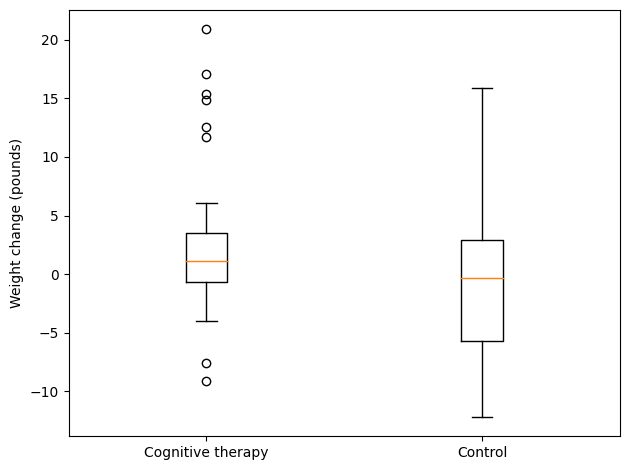

Treatment mean: 2.6827272727272726 Control mean: -0.48374999999999985
equal_var: True t,df,p: 1.812088058329836 63 0.0747386672060797
95% CI treatment minus control: CI(low=-0.32546114583019614, high=6.658415691284741)


In [142]:
# EXAMPLE VALUES EXPLAINED: cog/cont label two independent groups of people; each
# value is an individual's weight CHANGE. .05 is Levene's example decision level and
# .95 the CI confidence.
# REPLACE FOR YOUR QUESTION: Replace group labels/outcome/levels as required. Having
# before-after changes does not make the two different groups paired.

anorexia_data = pd.read_csv(DATA_DIR / "Anorexia.csv")
# Return rows complete in the stated columns; save the returned table.
therapy_change = anorexia_data.loc[
    anorexia_data["therapy"].eq("cog"), "change"
].dropna()
control_change = anorexia_data.loc[
    anorexia_data["therapy"].eq("cont"), "change"
].dropna()
plt.figure()
course_boxplot(
    [therapy_change, control_change], labels=["Cognitive therapy", "Control"]
)
plt.ylabel("Weight change (pounds)")
plt.tight_layout()
plt.show()
equal_change_var = levene(therapy_change, control_change).pvalue > 0.05
# Test first-minus-second independent means; False=Welch, True=pooled.
change_test = ttest_ind(
    therapy_change, control_change, equal_var=equal_change_var, alternative="two-sided"
)
# Get df and a two-sided independent-means CI; define in SETUP-01 first.
change_test_df, change_ci = independent_t_interval(
    therapy_change, control_change, 0.95, equal_var=equal_change_var
)
# Average values; for a Boolean mask this gives the True proportion.
print("Treatment mean:", therapy_change.mean(), "Control mean:", control_change.mean())
print(
    "equal_var:",
    equal_change_var,
    "t,df,p:",
    change_test.statistic,
    change_test_df,
    change_test.pvalue,
)
print("95% CI treatment minus control:", change_ci)


<a id="WF-06"></a>
## WF-06 · House prices: complete simple regression, diagnostics and prediction

**Search:** tutorial10 house_selling_prices_FL price size House64 slope intercept confidence99 residual cooks mean prediction extrapolation

**Use when:** Tutorial 10 Q1: perform the complete analysis using the actual house data.

**Remember:** House=64 is an ID VALUE, not necessarily row index 64. Filter the House column. A fitted intercept at size=0 may lack practical meaning if 0 is outside the observed domain.


**Example values explained:** 2000 and 6000 are new house SIZE values in square feet; House=64 is an observation ID specified for the refit comparison. .01 requests a 99% slope CI and .05 a 95% prediction-summary CI. 3/1 are SR/Cook screening thresholds.

**Replace for your question:** Replace forecast sizes, named ID and interval levels. Plot grids/bin counts affect display only; do not confuse House ID 64 with row index 64.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `print(model.summary())` | Call on a fitted model, not the unfitted ols specification. | Returns the formatted regression table; use named model attributes for exact numeric answers. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `r = first.corr(second,method="pearson")` | Pearson is default; method="spearman" uses ranks. Series align by index and pairwise remove missing values.<br><br>**Parameter choices and examples:**<br><br>**method:** "pearson" linear correlation; "spearman" rank correlation; "kendall" Kendall rank correlation; a compatible callable is also allowed. **Default:** "pearson".<br>**Examples:** data["x"].corr(data["y"],method="pearson"); data["x"].corr(data["y"],method="spearman") | Returns correlation; for a DataFrame .corr() returns the matrix. Preserve correct pairs. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `ci = model.conf_int(alpha=.05)` | alpha=.05 means 95% intervals; this method takes alpha, not .95 confidence.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | Returns coefficient CI rows. .loc["hours"] selects the slope interval; it is not a response prediction interval. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `influence = model.get_influence()` | Call on a fitted OLS model. Diagnostics refer only to rows actually fitted. | Use .resid_studentized_internal for SR and .cooks_distance[0] for Cook D. Align masks to fitted row labels. |
| `s = pd.Series([10, 20, None])` | Supply one list/array; optional index=[...] supplies matching labels and dtype=... sets the type.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns one labelled column; use s in the remaining operations. |
| `influence.resid_studentized_internal`<br>**OR**<br>`influence.cooks_distance[0]` | Create influence = model.get_influence() first. Internal studentized residuals are the course SR values; [0] extracts the Cook-distance array. | Compare abs(SR)>3 and Cook D>1 to flag observations. Flags warrant investigation, not automatic deletion. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `predicted = model.fittedvalues`<br>`residuals = model.resid` | Use a fitted model; fittedvalues/resid contain only the rows used in the fit, and row_labels identifies those fitted labels. | Residual is observed minus fitted. Align diagnostic masks to these fitted-row labels before selecting observations. |
| `new = data.assign(high=data["score"] >= cutoff)` | Each keyword names a new/replaced column; its value must align with the table rows. | Returns a DataFrame with these columns; it does not update data unless you save it. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `plt.axhline(0)`<br>**OR**<br>`plt.axvline(cutoff)` | axhline takes a y value, axvline an x value; color/linestyle are display settings.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Adds a reference line to the current axes; use ax.axhline/axvline for a chosen subplot. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `probplot(values,dist="norm",plot=plt)` | Use the relevant sample/differences/residuals. plot can be plt or an Axes from subplots.<br><br>**Parameter choices and examples:**<br><br>**dist / plot:** dist="norm" is the course normal QQ comparison; another supported scipy distribution can be specified for a different theoretical reference. plot=plt or an Axes draws a graph; plot=None returns calculations only. **Default:** dist="norm"; plot=None.<br>**Examples:** probplot(x,dist="norm",plot=plt); probplot(x,dist="norm",plot=axes[1]) | Draws a QQ plot when plot is supplied and returns plotting quantities. Approximate straightness supports normality. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `combined = pd.concat([first, second], ignore_index=True)` | axis=0 stacks rows (default); axis=1 places columns side by side and aligns row labels. ignore_index resets the concatenation axis.<br><br>**Parameter choices and examples:**<br><br>**axis / ignore_index / join:** axis=0 stacks rows, 1 places columns side by side. ignore_index=True renumbers the concatenation axis; False retains labels. join="outer" keeps all other-axis labels, "inner" only shared labels. **Default:** axis=0; ignore_index=False; join="outer".<br>**Examples:** pd.concat([a,b],axis=0,ignore_index=True); pd.concat([a,b],axis=1,join="inner") | Returns the combined table; source tables remain available. |
| `table = model.get_prediction(new_rows).summary_frame(alpha=.05)` | alpha=.05 requests 95% intervals; each output row corresponds to one supplied scenario.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | mean is fitted response; mean_ci_* bounds its mean; obs_ci_* bounds a new individual response. |
| `prediction = model.get_prediction(new_rows)` | Supply a DataFrame of complete predictor scenarios with matching column names/categories.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns a prediction-results object; append .summary_frame(alpha=.05) to obtain numeric estimates and intervals. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `s.eq(value)`<br>**OR**<br>`s.ne(value)`<br>**OR**<br>`s.gt(value)`<br>**OR**<br>`s.ge(value)`<br>**OR**<br>`s.lt(value)`<br>**OR**<br>`s.le(value)` | Respectively ==, !=, >, >=, <, <=. value can be a scalar or an aligned Series. | Returns True/False per element; use data.loc[mask] to keep matching rows. |


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.580
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     135.1
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           3.84e-20
Time:                        13:46:53   Log-Likelihood:                -1192.0
No. Observations:                 100   AIC:                             2388.
Df Residuals:                      98   BIC:                             2393.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   9161.1589   1.08e+04      0.851      0.3

,House,price,size,SR,CooksD
63,64,225000,4050,-2.955526,1.212387


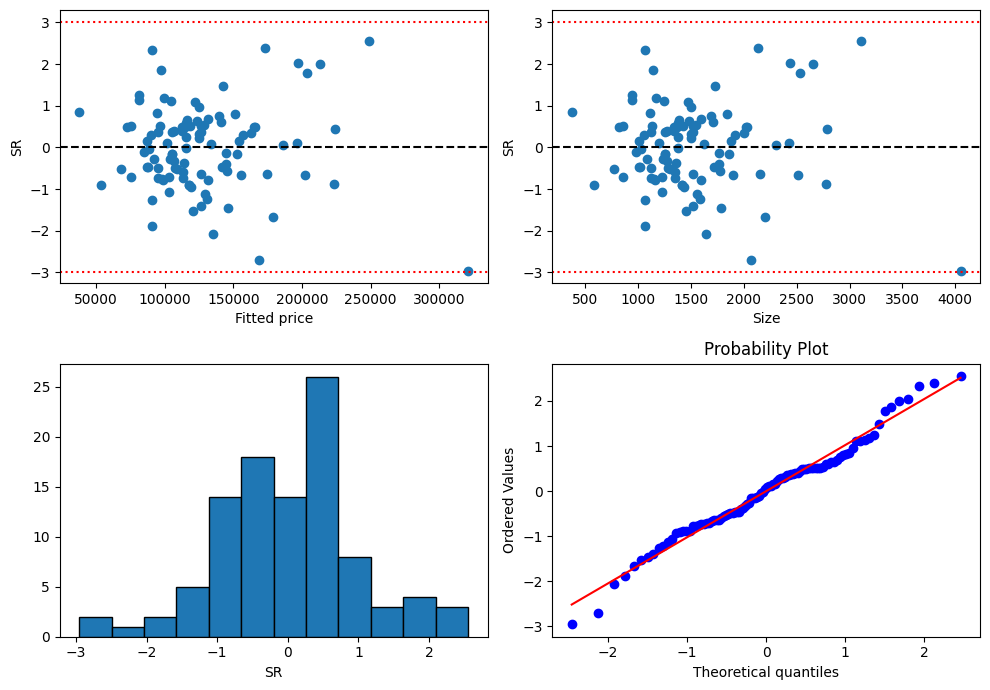

,size,mean,mean_ci_lower,mean_ci_upper
0,2000,163176.543960,153588.646934,172764.440985
1,6000,471207.314151,411931.312754,530483.315547


Observed size range: 370 4050
Slope/R² with 64: 77.00769254776766 0.5795200025465514
Slope/R² without 64: 87.08544532134246 0.6047287110463073


In [143]:
# EXAMPLE VALUES EXPLAINED: 2000 and 6000 are new house SIZE values in square feet;
# House=64 is an observation ID specified for the refit comparison. .01 requests a
# 99% slope CI and .05 a 95% prediction-summary CI. 3/1 are SR/Cook screening
# thresholds.
# REPLACE FOR YOUR QUESTION: Replace forecast sizes, named ID and interval levels.
# Plot grids/bin counts affect display only; do not confuse House ID 64 with row
# index 64.

house_data = pd.read_csv(DATA_DIR / "house_selling_prices_FL.csv")
# Return rows complete in the stated columns; save the returned table.
house_complete = house_data.dropna(subset=["price", "size"]).copy()
# Specify response ~ predictors; fit() is needed to estimate coefficients.
house_slr = smf.ols("price ~ size", data=house_complete).fit()
print(house_slr.summary())
print(
    "Fitted equation: price_hat =",
    house_slr.params["Intercept"],
    "+",
    house_slr.params["size"],
    "* size",
)
print("Correlation:", house_complete["price"].corr(house_complete["size"]))
# Coefficient intervals: alpha=.05 requests 95% confidence.
print("99% slope CI:", house_slr.conf_int(alpha=0.01).loc["size"].tolist())
print(
    "Overall F,p:",
    house_slr.fvalue,
    house_slr.f_pvalue,
    "Slope t,p:",
    house_slr.tvalues["size"],
    house_slr.pvalues["size"],
)
print("R²:", house_slr.rsquared, "sqrt(R²):", np.sqrt(house_slr.rsquared))
house_influence = house_slr.get_influence()
house_sr = pd.Series(
    house_influence.resid_studentized_internal, index=house_slr.fittedvalues.index
)
house_cooks = pd.Series(
    house_influence.cooks_distance[0], index=house_slr.fittedvalues.index
)
display(
    house_complete.loc[
        (house_sr.abs() > 3) | (house_cooks > 1), ["House", "price", "size"]
    ].assign(SR=house_sr, CooksD=house_cooks)
)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].scatter(house_slr.fittedvalues, house_sr)
axes[0, 0].set(xlabel="Fitted price", ylabel="SR")
axes[0, 1].scatter(house_complete["size"], house_sr)
axes[0, 1].set(xlabel="Size", ylabel="SR")
for ax in axes[0]:
    ax.axhline(0, color="black", linestyle="--")
    ax.axhline(3, color="red", linestyle=":")
    ax.axhline(-3, color="red", linestyle=":")
axes[1, 0].hist(house_sr, bins=12, edgecolor="black")
axes[1, 0].set_xlabel("SR")
probplot(house_sr, plot=axes[1, 1])
plt.tight_layout()
plt.show()
new_sizes = pd.DataFrame(
    {
        "size": [2000, 6000],
    }
)
# Prediction table: mean_ci is for mean response, obs_ci for one new observation.
# Supply all original predictor columns; summary_frame provides estimates/intervals.
display(
    pd.concat(
        [
            new_sizes,
            house_slr.get_prediction(new_sizes).summary_frame(alpha=0.05)[
                ["mean", "mean_ci_lower", "mean_ci_upper"]
            ],
        ],
        axis=1,
    )
)
print(
    "Observed size range:", house_complete["size"].min(), house_complete["size"].max()
)
without_house64 = house_complete.loc[house_complete["House"].ne(64)].copy()
house_slr_no64 = smf.ols("price ~ size", data=without_house64).fit()
print("Slope/R² with 64:", house_slr.params["size"], house_slr.rsquared)
print("Slope/R² without 64:", house_slr_no64.params["size"], house_slr_no64.rsquared)


<a id="WF-07"></a>
## WF-07 · House models: NW indicator, quadrant baseline, quadratic and comparisons

**Search:** tutorial10 house categorical NW Quadrant four categories reference SW quadratic size change1500 compare adjustedR2 within group extrapolation

**Use when:** Tutorial 10 Q2–4: fit extended models and interpret categorical and curved effects.

**Remember:** A new predictor value can be inside the overall range but outside the range for its category. Assess extrapolation within the relevant group too. The model with a quadratic term is still linear in its coefficients.


**Example values explained:** 4000 is a forecast size; NW=1 is a category code. [1500,1501] defines a one-square-foot change; four copies of 1500 compare quadrants at the SAME size. 10000/80 and offsets 25000/30000/-5000/0 belong ONLY to the tutorial's supplied hypothetical equation.

**Replace for your question:** Replace new predictor values/categories or supplied-equation coefficients. Do not copy the hypothetical coefficients into a model fitted to unrelated data.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ C(group, Treatment('A'))", data=data).fit()` | Use C(...) INSIDE a formula to encode a category; numerical codes also need C if they represent labels.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | Adds k-1 indicators with an intercept. This is a formula helper, not a DataFrame method. |
| `smf.ols("score ~ hours + I(hours**2)", data=data).fit()` | I(...) makes the expression inside arithmetic rather than formula operators; retain the main effect unless instructed otherwise. | Adds an arithmetic term such as a square. Formula ** by itself has a different meaning. |
| `C(group, Treatment('A'))` | Put this inside the formula; the value specifies the reference category and must match an observed/encoded level.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | The omitted reference group has zero indicators; category coefficients are relative to it, holding other predictors fixed. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `predicted = model.predict(new_rows)` | new_rows is a DataFrame supplying EVERY original predictor and observed category labels; omit response. Formula API builds powers/interactions itself.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns fitted mean response on the model’s response scale. Intervals need get_prediction(...).summary_frame(...). |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `data.groupby("group").agg(avg=("score", "mean"), n=("id", "size"))` | Named tuples are (input column, aggregation). For selected columns, .agg(["mean", "std"]) requests several summaries.<br><br>**Parameter choices and examples:**<br><br>**function / aggfunc:** Common strings: "mean", "median", "sum", "min", "max", "std", "var", "count", "size", "nunique"; or a callable. agg accepts a list or mapping for multiple summaries; transform must return/broadcast back to the original rows.<br>**Examples:** data.groupby("g")["x"].agg(["mean","std"]); data.groupby("g")["x"].transform("max"); pd.pivot_table(data,index="g",values="x",aggfunc="sum")<br><br>**named output columns:** Names before = are your chosen output names; each tuple supplies an existing input column and aggregation string/function.<br>**Examples:** data.groupby("g").agg(mean_x=("x","mean"), n=("id","size")) | Returns group-level summaries, usually one row per group; size counts rows, count counts nonmissing values. |
| `s.count()`<br>**OR**<br>`items.count(value)` | pandas count counts nonmissing entries; Python list.count(value) counts occurrences of that specified value. | Returns counts. Use len(data) for total rows including missing observations. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `group_n = data.groupby("group").size()` | size counts every row in a group, including rows with a missing measurement. count on a selected column counts its observed values instead. | Returns one row count per group. In named agg, n=("id","size") requests this row count. |
| `groups = data.groupby("group", dropna=False)` | Use one column or a list. dropna=False includes missing group keys; observed=True limits categorical combinations to those observed. as_index=False keeps group names as columns after aggregation; sort=False keeps group appearance order; group_keys=False avoids extra group-key index levels in apply results.<br><br>**Parameter choices and examples:**<br><br>**by / as_index:** by may be one label or a list of labels; as_index=True uses group keys as the aggregated index, False leaves them as columns. **Default:** as_index=True.<br>**Examples:** data.groupby("group")["score"].mean(); data.groupby(["group","city"],as_index=False)["score"].mean()<br><br>**dropna / observed / sort / group_keys:** All accept True/False. dropna=False includes missing group keys. observed=True keeps observed categorical combinations; False includes unused levels/combinations. sort=False keeps group appearance order. group_keys=False avoids extra group-key index levels in apply results. Defaults for observed/group_keys vary by pandas version: set them explicitly if relevant.<br>**Examples:** data.groupby("group",dropna=False,observed=True,sort=False); data.groupby("group",group_keys=False).apply(function) | Returns a GroupBy object; append ["value"].mean(), .agg(...), .transform(...), etc. to calculate something. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `coded = s.map({"Yes": 1, "No": 0})` | Mapping keys must match the original values exactly; values are the replacements. A function is another option.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False) | Returns recoded values; unlisted keys become missing. Assign to a new/existing column. |


In [144]:
# EXAMPLE VALUES EXPLAINED: 4000 is a forecast size; NW=1 is a category code.
# [1500,1501] defines a one-square-foot change; four copies of 1500 compare
# quadrants at the SAME size. 10000/80 and offsets 25000/30000/-5000/0 belong ONLY
# to the tutorial's supplied hypothetical equation.
# REPLACE FOR YOUR QUESTION: Replace new predictor values/categories or
# supplied-equation coefficients. Do not copy the hypothetical coefficients into a
# model fitted to unrelated data.

# Return rows complete in the stated columns; save the returned table.
house_models_data = (
    pd.read_csv(DATA_DIR / "house_selling_prices_FL.csv")
    .dropna(subset=["price", "size", "NW", "Quadrant"])
    .copy()
)
# Specify response ~ predictors; fit() is needed to estimate coefficients.
house_model1 = smf.ols("price ~ size", data=house_models_data).fit()
house_model2 = smf.ols("price ~ size + C(NW)", data=house_models_data).fit()
house_model3 = smf.ols("price ~ size + I(size**2)", data=house_models_data).fit()
house_quadrants = smf.ols(
    "price ~ size + C(Quadrant, Treatment('SW'))", data=house_models_data
).fit()
print(
    "NW coefficient estimates:",
    house_model2.params,
    "p-values:",
    house_model2.pvalues,
    sep="\n",
)
# Return predicted mean on the fitted RESPONSE scale for these new predictor rows.
print(
    "Prediction size=4000,NW=1:",
    house_model2.predict(
        pd.DataFrame(
            {
                "size": [4000],
                "NW": [1],
            }
        )
    ).iloc[0],
)
print("Size range within each NW group:")
# Choose groups first, then append the required summary or row-aligned transform.
display(house_models_data.groupby("NW")["size"].agg(["count", "min", "max"]))
print("Quadrant coefficients with SW baseline:", house_quadrants.params)
display(
    house_quadrants.predict(
        pd.DataFrame(
            {
                "size": [1500] * 4,
                "Quadrant": ["NE", "NW", "SE", "SW"],
            }
        )
    )
)
quad_prediction = house_model3.predict(
    pd.DataFrame(
        {
            "size": [1500, 1501],
        }
    )
)
print(
    "Exact quadratic change 1500->1501:",
    quad_prediction.iloc[1] - quad_prediction.iloc[0],
)
print("Quadratic term p-value:", house_model3.pvalues["I(size ** 2)"])
display(
    pd.DataFrame(
        {
            "R²": [m.rsquared for m in [house_model1, house_model2, house_model3]],
            "Adjusted R²": [
                m.rsquared_adj for m in [house_model1, house_model2, house_model3]
            ],
        },
        index=["Simple", "NW", "Quadratic"],
    )
)
# Tutorial 10 Q4 gives a hypothetical equation; evaluate that equation, not the fitted coefficients above.
hypothetical = pd.DataFrame(
    {
        "Quadrant": ["NE", "NW", "SE", "SW"],
        "size": [1500] * 4,
    }
)
# Recode matching values; unlisted mapping keys become missing.
offsets = hypothetical["Quadrant"].map(
    {
        "NE": 25000,
        "NW": 30000,
        "SE": -5000,
        "SW": 0,
    }
)
hypothetical["predicted_price"] = 10000 + 80 * hypothetical["size"] + offsets
display(hypothetical)
print("Hypothetical same-size NW minus NE:", 30000 - 25000)


NW coefficient estimates:
Intercept    -15257.513854
C(NW)[T.1]    30569.087289
size             77.985126
dtype: float64
p-values:
Intercept     2.031602e-01
C(NW)[T.1]    2.149752e-04
size          4.690632e-22
dtype: float64
Prediction size=4000,NW=1: 327252.0789388059
Size range within each NW group:


,count,min,max
NW,,,
0,25,1020,4050
1,75,370,3110


Quadrant coefficients with SW baseline: Intercept                              6325.910934
C(Quadrant, Treatment('SW'))[T.NE]   -26313.137341
C(Quadrant, Treatment('SW'))[T.NW]    10009.780207
C(Quadrant, Treatment('SW'))[T.SE]   -65772.748138
size                                     77.308337
dtype: float64


0     95975.279070
1    132298.196618
2     56515.668273
3    122288.416411
dtype: float64

Exact quadratic change 1500->1501: 82.41385759820696
Quadratic term p-value: 0.3243016944828656


,R²,Adjusted R²
Simple,0.579520,0.575229
NW,0.635150,0.627628
Quadratic,0.583732,0.575149


,Quadrant,size,predicted_price
0,NE,1500,155000
1,NW,1500,160000
2,SE,1500,125000
3,SW,1500,130000


Hypothetical same-size NW minus NE: 5000


<a id="decisions"></a>
# 13 · Decision cards and conceptual checks

Python calculates the output. These decisions determine whether that output answers the question.


## Quick method selector

| Question target | First choice in this course | Search ID |
|---|---|---|
| Count successes in fixed independent trials | Binomial | PROB-01 |
| Normal probability or cut-off | cdf/sf or ppf | PROB-02 |
| Mean of n observations | Sampling mean, SD sigma/sqrt(n) | SIM-01 |
| Fraction of n observations | Sampling proportion, SD sqrt(p(1-p)/n) | SIM-02 |
| CI for one proportion | Normal/Wald CI using p_hat | CI-01 |
| CI for one mean, unknown population SD | t CI | CI-02 |
| Test one proportion | Proportion Z-test using p0 | TEST-01 |
| Test one mean | One-sample t | TEST-02, TEST-03 |
| Compare independent means | Pooled/Welch following requested assumptions | TEST-04 through TEST-06 |
| Compare matched/before-after measurements | Paired t on differences | TEST-07, TEST-08 |
| Model a mean response using predictors | OLS + diagnostics | REG-01 through REG-10 |
| Count rows, columns, cells, missing values or column names | Choose the counting unit first | COUNT-01 |
| Count x/y/z values across rows or columns | Membership mask, any/all, then sum | COUNT-02 |
| Count at least/exactly/at most k conditions | Sum Boolean matches per item | COUNT-03 |
| Count rows/columns removed at a cleaning step | Before-shape minus after-shape | COUNT-04 |
| Combine overlapping removal rules | Union and step counts without double-counting | COUNT-05 |

## Interpretation cards — search these terms

- **SD versus SE:** SD describes spread of individual observations. SE describes sampling variability of an estimator. For an iid mean, theoretical SD of the mean is sigma/sqrt(n); estimated SE is s/sqrt(n).
- **Parameter versus statistic:** mu, sigma and p describe a population; x_bar, s and p_hat are computed from a sample. Hypotheses are about population parameters.
- **CLT versus raw-data shape:** large n can make the sampling mean approximately normal; it does not make the population or the individual observations normal.
- **95% confidence:** across repeated samples, the interval procedure covers the fixed parameter about 95% of the time. It does not say 95% of individuals lie inside the interval or that the realised fixed parameter has a 95% frequentist probability of being inside.
- **p-value:** probability, assuming H0, of a statistic as extreme as observed in the direction(s) of H1. It is not P(H0 true).
- **Decision:** reject when p<=alpha; otherwise do not reject. Failure to reject is insufficient evidence of an effect; it does not prove equality/no effect.
- **Type I / II / power:** reject a true H0 / fail to reject a false H0 / reject a false H0. Holding the design and alternative fixed, lowering alpha generally reduces power. Larger n can improve power without raising alpha.
- **Association versus causation:** observational association may reflect confounding. Random assignment helps causal attribution; random sampling supports generalisation. An experiment assigns treatments; randomisation is a feature of a good experiment, not the definition of every experiment.
- **Bias:** undercoverage/convenience/volunteer sampling affects who is sampled; nonresponse affects who provides data; response bias affects measurement/answers. A large sample alone does not remove systematic bias.
- **Confounding/lurking:** a third variable may distort the exposure–response relationship. A lurking variable is typically unrecorded. Stratify by recorded confounders or model appropriately; a raw correlation cannot establish a causal effect.
- **Residual diagnostics:** curvature suggests a missing nonlinear mean term; a funnel suggests nonconstant error variance; systematic QQ departures suggest nonnormal errors. Independence/randomisation is assessed from data collection as well as any order patterns, not a histogram alone.
- **Regression normality:** normality concerns errors/conditional response about its mean, not necessarily the marginal histogram of Y. Predictors need not be mutually uncorrelated; exact collinearity prevents unique coefficient estimates and strong collinearity harms precision.
- **Outlier versus influence:** an unusual response residual differs from a point that materially changes the fit. Course screening: |SR|>3 and Cook D>1; neither automatically requires removal.
- **Categorical and interaction coefficients:** interpret relative to the stated reference and hold other predictors fixed. Interaction effects depend on group or starting predictor value.
- **Multiple-choice traps:** variance versus SD; p0 versus p_hat; two-sided versus one-sided; first minus second; width versus MOE; label versus position; proportion versus percent; density versus probability; table index alignment; missing pairs.

**Slide correction:** Topic 9 Part 2 slide 9 has an inequality/significance typo: p<alpha in the overall F-test indicates a statistically significant model. Follow the correct rejection rule.


## Assumptions — what actually needs to be checked

| Method | Relevant condition | Common mistake |
|---|---|---|
| Binomial count | Fixed integer n, independent binary trials, same success probability p | Sampling without replacement from a small finite population generally creates dependence. |
| Mean sampling distribution | Independent observations with a common mean and finite variance; exactly normal if the population is normal | n>=30 is only a course rule of thumb for a CLT approximation; the raw observations do not become normal. |
| Proportion CI / null test | Appropriate independent random sample; course check n*p*(1-p)>=5 | Use p_hat for the CI check and SE; p0 for the null-test check and SE. The separate expected-success/failure checks are not identical to the course condition. |
| One-mean t inference | Independent random sample; normal population for exact small-sample t inference, or an adequate large-sample approximation | Symmetry alone does not make the t distribution exact; severe skew/outliers are especially concerning in small samples. |
| Independent two-mean t | Independent groups and independent people within each group; appropriate normal/large-sample conditions within each group | Do not pool all data to assess normality; pooled t also assumes equal population variances. Welch relaxes that variance assumption. |
| Paired t | Independent pairs; analyse the within-pair differences, approximately normal for small-sample inference | The two measurements within a pair are allowed to be dependent; never drop missing before/after entries separately. |
| Regression inference | Correct conditional mean form, independent errors, constant error variance and normal errors for exact classical inference | A normal histogram of Y does not check normal errors; a large overall F does not validate residual assumptions. |

Shapiro tests normality; Levene tests equality of group variances. Their p-values answer different questions. A large p-value means insufficient evidence against the relevant null, not proof that it is true.

## One-sided bounds, transformed predictions and exact answer blanks

- **One-sided CI:** `alternative="greater"` returns a finite lower bound and infinite upper bound; `"less"` returns an infinite lower bound and finite upper bound. For a requested two-sided CI, create a separate `alternative="two-sided"` result even if the hypothesis test is directional. See TEST-02 and TEST-07.
- **Transformed response:** if the model is `log(Y) ~ X`, its fitted mean is on the log scale. `exp(fitted)` is a plug-in back-transform, not automatically the arithmetic conditional mean of Y. Squaring a fitted sqrt(Y) response and inverting a fitted 1/Y response have the same general mean-versus-back-transform issue. A reciprocal inverse reverses interval endpoints on a positive interval, and cannot cross zero. Do not invent a bias correction unless the question supplies/requires the relevant method. See REG-09.
- **Numerical answer:** extract the requested scalar, then round only for the final answer. `f"{p_value:.4f}"` displays four decimals including trailing zeros; scientific notation may hide the requested decimal format. Small nonzero p-values can display as `0.0000`; that is rounding, not an exact probability of zero.
- **Code-answer blank:** submit valid Python syntax. Strings need quotes (`"coerce"`, `"less"`); booleans are `True`/`False`; a simulation shape is a tuple such as `(N, n)`; a method name alone is appropriate only if the surrounding code already supplies the object and parentheses.
- **Regression output:** `model.params["Intercept"]` is the intercept; `model.params["predictor"]` a numeric slope; `model.rsquared` versus `model.rsquared_adj` are different outputs; `model.df_model` is numerator F df and `model.df_resid` is residual/denominator df. For category/interaction keys, first inspect `model.params.index.tolist()`. `model.ssr` is SUM of squared residuals in statsmodels (some other texts use SSR for explained sum of squares).
- **SciPy 1.10 independent tests:** `ttest_ind` still returns the correct statistic and p-value, but its result lacks `.df` and `.confidence_interval()`. Run SETUP-01 and use `degrees, ci = independent_t_interval(first, second, confidence=.95, equal_var=False)` for a Welch two-sided CI (True for pooled); read `ci.low`/`ci.high`. This helper uses the same manual formulas as TEST-06 and does not change your packages or replace `ttest_ind`. A function-name answer blank still uses `ttest_ind`.

## Quick fixes when copied code fails

| Error or symptom | Check and fix |
|---|---|
| FileNotFoundError | `print(DATA_DIR)` and `print(list(DATA_DIR.glob("*.csv")))`; use the exact supplied filename and correct working folder. |
| KeyError for a column/category | `print(data.columns.tolist())` and `print(data["column"].value_counts(dropna=False))`; spaces/case/codes matter. Clean labels only as instructed. |
| NameError for model, df or helper | Run SETUP-01 and the prerequisite recipe named in the template; adapt its data-loading/fit step to the question. Restarting the kernel clears definitions. |
| Formula SyntaxError / PatsyError | Quote awkward names with Q("name"), wrap categorical codes in C(...), provide all original predictors at prediction time, and use categories observed in training. See REG-11. |
| NaN statistic or CI | Check nonmissing n, constant/all-identical samples, zero SE and missing paired rows; fix the data-selection issue rather than replacing NaN by zero. |
| Same code, different numerical answer | Check cleaning order, current dataset, denominator, group subtraction order, alternative, level, SD versus variance and prescribed random seed before changing the method. |

Keep all branches within one example together. Examples reuse short variable names such as n, p and values: recreate the relevant sample and its n when switching datasets.


<a id="coverage"></a>
# 14 · Course question map and lookup drill

Use this map to rehearse retrieval: open the tutorial, hide its solution, find the relevant recipe and adapt it to the actual dataset.


## Audit additions: interpretation lookup tables

### QQ tails — theoretical quantiles on x, observed quantiles on y

| End of QQ plot | Departure from reference line | Interpretation |
|---|---|---|
| Left tail | Below | Longer/heavier left tail than normal |
| Left tail | Above | Shorter/lighter left tail than normal |
| Right tail | Above | Longer/heavier right tail than normal |
| Right tail | Below | Shorter/lighter right tail than normal |

Left-below and right-above together indicate heavier tails at both ends. Reverse-axis QQ plots require rethinking these directions. Approximate straightness supports normality; it does not establish that all other assumptions hold.

### Plot interpretation and study-design checklist

| Question | What the answer should refer to |
|---|---|
| Describe histogram | Clustering/gaps/outliers, number of peaks, symmetry/skewness; right-skew means the long tail is on the right |
| Compare boxplots | Medians, IQR/spread, tails/outliers, which group tends to have higher values; a boxplot does not show every distributional feature |
| Describe scatterplot | Direction, strength, form/linearity, unusual observations and changing vertical spread |
| Pick a graph | One categorical: bar; one quantitative: histogram/boxplot; two categorical: conditional table/bars; categorical+quantitative: grouped boxplots; two quantitative: scatter |
| Simple random sample | Every possible subset of the given size is equally likely; equal individual inclusion probabilities alone do not fully define SRS |
| Sampling frame | Accessible list of population units from which sampling takes place; check who is omitted |
| Stratified sampling | Divide population into strata and sample within every stratum |
| Cluster sampling | Randomly select clusters, then collect data from those clusters according to the design |
| Random sampling versus assignment | Sampling concerns representativeness/generalisation; assignment concerns comparing treatments and causal attribution |
| Controlled experiment | Define experimental units, treatment/control, random assignment, replication and control of other factors |

### Regression reading checklist

- **Coefficient:** estimated change in mean response per unit of that predictor, holding other predictors fixed, unless interactions/polynomials change that interpretation. Include units and baseline group.
- **Intercept:** fitted mean at zero numeric predictors and reference categories; it may have no practical meaning if that combination is outside the data.
- **R²:** fraction of observed response variation about its mean explained by the fitted model; not prediction accuracy and not the percentage of outcomes predicted exactly.
- **Overall F:** rejection supports at least one nonzero slope; it does not say that every predictor is significant. Individual t-tests assess coefficients conditional on the other model terms.
- **Degrees of freedom:** with an intercept and k encoded non-intercept regressors, model df=k and residual df=n-k-1. A four-level category uses three regressors, and an interaction or squared term counts as an additional regressor.
- **Simple regression identities:** with an intercept and the same rows, R²=r² and the overall F=t_slope²; sqrt(R²)=|r|, so it equals r only when r>=0.
- **Mean change for a quadratic:** from x to x+d, change=b1*d+b2*(2*x*d+d²); the one-unit change is b1+b2*(2*x+1).
- **Transformations:** a funnel can motivate a response transformation; a curved mean pattern can motivate polynomial terms. A transformation is not automatically a cure for every assumption failure.
- **Data missingness:** comparisons of fit require the same response and rows. Filtering a diagnostic mask must use the labels/rows that were actually fitted.

### Probability and inference micro-rules

- A finite sample space need not have equally likely outcomes: two-dice sums are not uniform. Counting favourable/total outcomes requires equally likely elementary outcomes.
- A continuous point probability P(X=c)=0; a density can exceed 1 because area, not height, is probability.
- Independent positive-probability events cannot be mutually exclusive. Mutual exclusivity means intersection probability zero; independence means product probability.
- A higher confidence level widens a CI, larger n narrows it and larger variability usually widens it. Under the usual fixed-variance formula, quadrupling n halves SE/MOE.
- In a two-sided mean test, use confidence level 1-alpha for a matching CI. Do not apply that equivalence automatically to one-sided tests or proportion procedures using different SEs.
- The course proportion normal-approximation check is np(1-p)>=5 (replace p by p_hat for the CI and p0 for the test). Other textbooks' separate np/n(1-p) checks are related but not identical conditions.


| Material | Question patterns | Main recipe IDs |
|---|---|---|
| Tutorial 1 Q1/Q5 | summaries, transformations, outliers, plots, loading/renaming | DATA-01, PD-04, NP-08, PLOT-02/03/04 |
| Tutorial 1 Q2–4 | variable types; histogram/boxplot shapes | Decision cards, original Topic 2 notes |
| Tutorial 2 Q1–5 | plot selection, group percentages, RR, correlation, remove unusual point | GROUP-05/08/10, PROB-08, PLOT-04/05/06/09/10, WF-01 |
| Tutorial 3 Q1–6 | confounding, bias, sampling and experimental design | Decision cards, original Topics 3–4 |
| Tutorial 4 Q1–5 | events, conditional probability, independence, screening Bayes | PROB-05/08, original Topics 3–4 |
| Tutorial 5 Q1–2 | Bayes, cost RV, discrete moments and linear transformation | PROB-01/03/05/09 |
| Tutorial 5 Q3–5 | diagnostic cut-offs, normal differences, binomial approximation | PROB-01/02/04/06/07 |
| Tutorial 6 Q1–3 | sampling mean/proportion, changing n | SIM-01/02 |
| Tutorial 6 Q4–5 | repeated normal samples, dice, empirical vs theoretical probabilities | SIM-03/04, NP-09/15 |
| Tutorial 7 Q1–4 | proportion/mean CIs, width, sample-size planning and friend’s shortcut functions | CI-01 through CI-06 |
| Tutorial 7 Q5 | repeated CI coverage | SIM-05 |
| Tutorial 8 Q1/Q4 | one-proportion test, rejection region, errors | TEST-01/09/10, PLOT-07, WF-02, Decision cards |
| Tutorial 8 Q2–3 | raw-data mean test and CI consistency | TEST-02/03, CI-02/04 |
| Tutorial 9 Q1–4 | error/CI interpretation, independent vs paired, Levene selection | TEST-04 through TEST-08, WF-03/04/05 |
| Tutorial 10 Q1 | full simple regression, prediction and diagnostics | REG-01 through REG-05, REG-10, WF-06 |
| Tutorial 10 Q2–4 | multiple/categorical/quadratic models and interpretation | REG-06 through REG-10, WF-07 |
| DataCamp: Introduction/Intermediate Python | arrays, slicing, masks, plotting and control flow | NP-01 through NP-15, CLEAN-06, PLOT section |
| DataCamp: Data Manipulation with pandas | inspection, filtering, grouping and transformations; full cleaning audit | PD, FILTER, CLEAN (including CLEAN-09), GROUP and TIME sections |
| DataCamp: Probability Ch1–2 | named skill area; exact exercises not available | PROB and SIM sections; verify assigned chapter scope |
| DataCamp: Regression Ch1–3 | named skill area; exact exercises not available | REG section; verify assigned chapter scope |

**Lookup drill:** choose a question, find the right template within a minute, replace dataset/columns/parameters, run, and compare to the tutorial solution. If the template is correct but the answer differs, inspect filtering, missing values, group order, alternative, alpha, SD/variance, and rounding before changing methods.


<a id="original-appendix"></a>
# 15 · Merged consolidated course notes and dataset examples

Your friend’s updated topic-by-topic notes follow, with the earlier worked CI example also retained. This copy uses corrected data-folder lookup, portable boxplots, validated shortcut functions and aligned diagnostic rows. Both source versions remain unchanged. These examples depend on earlier appendix cells; use the cookbook above for shorter task-based recipes.


# ST1131 Consolidated Master Notes & Function Reference

This notebook consolidates **Topics 1 to 9** of **ST1131 (Introduction to Statistics and Statistical Computing)** into the original topic-by-topic reference retained below. Each topic starts with a **Function & Argument Summary Table** so you can quickly look up exact syntax and required inputs, followed by key concepts, exam pitfalls, and runnable examples using the course datasets in the resolved `DATA_DIR`.

### Table of Contents
1. [Master Imports & Global Pitfalls](#master-imports)
2. [Topic 1: Introduction to Python & NumPy](#topic-1)
3. [Topic 2: Exploratory Data Analysis (`pandas` & `matplotlib`)](#topic-2)
4. [Topics 3 & 4: Study Design, Confounding & Probability Foundations](#topics-3-4)
5. [Topic 5: Random Variables & Probability Distributions (`scipy.stats`)](#topic-5)
6. [Topic 6: Sampling Distributions & Central Limit Theorem (CLT)](#topic-6)
7. [Topic 7: Confidence Intervals](#topic-7)
8. [Topic 8: Hypothesis Testing](#topic-8)
9. [Topic 9: Linear Regression (`statsmodels`)](#topic-9)

---
<a id="master-imports"></a>
## Master Imports & Global Pitfalls

Copy and run the import cell below at the top of any practice or exam notebook so every tool across Topics 1–9 is ready.

> **Top 5 Exam Pitfalls to Watch Out For:**
> 1. **Never overwrite `t` or Python built-ins:** Do **not** assign variables named `t` (overwrites `scipy.stats.t`), `list`, `sum`, `min`, `max`, or `lambda` (reserved keyword — use `lam` instead). Use `t_stat` or `t_mult`.
> 2. **Standard Deviation vs Variance in `scipy` / `numpy`:** In `norm(..., loc=mu, scale=sigma)` and `np.random.normal(mu, sigma, size)`, the second argument is always the **standard deviation $\sigma = \sqrt{\sigma^2}$**, **never** the variance $\sigma^2$!
> 3. **Sample vs Population SD (`ddof`):** `np.std(x)` and `np.var(x)` default to `ddof=0` (**population**). Always pass `ddof=1` in NumPy for **sample** $s$ and $s^2$! In contrast, `pandas` `s.std()` and `s.var()` already default to `ddof=1` (**sample**).
> 4. **Discrete "At Least" Probabilities:** For integer random variables like $X \sim \text{Bin}(n, p)$, $P(X \ge 5) = P(X > 4) = 1 - P(X \le 4)$, so use `binom.sf(4, n, p)` or `1 - binom.cdf(4, n, p)` (using `5` leaves out $P(X=5)$!).
> 5. **Confidence Level vs Significance Level $\alpha$:** `norm.interval(0.95, ...)`, `t.interval(0.95, ...)`, and `result.confidence_interval(0.95)` take the **confidence level (`0.95`)**, whereas `statsmodels` `model.conf_int(alpha=0.05)` and `summary_frame(alpha=0.05)` take **`alpha = 0.05`**!

**APPENDIX-01 · Example values explained:** Imports only: no example measurements. Run imports before the retained course examples.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `print(value)`<br>**OR**<br>`display(table)` | print formats text/scalars; display renders tables or other rich output.<br><br>**Parameter choices and examples:**<br><br>**sep / end:** sep is a string between printed items, default one space; end is a string after the output, default newline.<br>**Examples:** print(a,b,sep=" &#124; "); print(a,b,sep="\n") | Shows a result; does not save it as data. Assign the calculation separately if needed later. |


In [145]:
# EXAMPLE VALUES EXPLAINED: Imports only: no example measurements. Run imports
# before the retained course examples.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import stats
from scipy.stats import (
    bernoulli,
    binom,
    norm,
    t,
    ttest_1samp,
    ttest_ind,
    ttest_rel,
    levene,
    shapiro,
    probplot,
)
import statsmodels.formula.api as smf

print("All ST1131 packages imported successfully!")


All ST1131 packages imported successfully!


---
<a id="topic-1"></a>
# Topic 1: Introduction to Python & NumPy

## Summary of Functions & Arguments (Topic 1)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `len(x)` | `x`: list, string, 1D array, `Series`, or `DataFrame` | Number of elements (for a `DataFrame` or 2D array, returns number of **rows**) |
| `sorted(iterable, reverse=False)` | `iterable`: list/sequence to sort<br>`reverse`: `False` = ascending (default), `True` = descending | Returns a **new** sorted list without modifying the original |
| `round(number, ndigits=None)` | `number`: float value (use `np.round(arr, k)` for arrays)<br>`ndigits`: decimal places (omit for nearest `int`) | Rounds number to `ndigits` decimal places |
| `int(x)`, `float(x)`, `str(x)`, `bool(x)` | `x`: value to convert | Type casting (`int(3.9)` truncates toward zero $\to$ `3`; `bool(0)` $\to$ `False`, non-zero/non-empty string $\to$ `True`) |
| `lst[start:end]` | `start`: starting index (`0`-based, **inclusive**; omit for `0`)<br>`end`: stopping index (**exclusive**; omit for end; `-1` = last item) | Slices a list. Use `new_lst = old_lst[:]` to copy a list safely without shared references |
| `lst.append(val)` | `val`: single element to add at the end | Mutates `lst` in-place (returns `None`). Use `lst1 + lst2` to concatenate two lists |
| `lst.remove(val)` | `val`: exact value to delete (removes **first** match only) | Mutates `lst` in-place. Use `del lst[idx]` to delete by index position |
| `lst.count(val)` / `lst.index(val)` | `val`: value (or substring for `str`) to search for | `.count(val)` returns frequency of `val`; `.index(val)` returns `0`-based index of first match |
| `np.array(object)` | `object`: list (creates 1D array) or list of lists (creates 2D array) | Creates a homogeneous NumPy `ndarray` supporting element-wise math (`arr * 5`, `arr - 1`) |
| `arr.shape` | *(Attribute — no parentheses `()`)* | Tuple of dimensions: `(n,)` for 1D array, `(rows, cols)` for 2D array |
| `arr[row, col]` | `row`: row index or slice (`start:end` or `:`)<br>`col`: column index or slice (`start:end` or `:`) | Subsets a 2D NumPy array (unlike nested lists which use `lst[row][col]`) |
| `np.arange(start, stop, step=1)` | `start`: inclusive start (default `0`)<br>`stop`: **exclusive** upper bound<br>`step`: increment size | Evenly spaced values with fixed step (e.g. `np.arange(10, 36, 5)` gives `10, 15, 20, 25, 30, 35`) |
| `np.linspace(start, stop, num=50)` | `start`: inclusive start<br>`stop`: **inclusive** end<br>`num`: how many evenly spaced points to generate | Smooth grid of `num` points across `[start, stop]` (ideal for plotting continuous PDF curves) |
| `np.mean(a, axis=None)`<br>`np.median(a, axis=None)` | `a`: array or list<br>`axis`: `None` (overall), `0` (**down columns**), `1` (**across rows**) | Arithmetic mean or median |
| `np.amin(a)` / `np.amax(a)` / `np.ptp(a)` | `a`: array or list (optional `axis=0` or `1`) | Minimum (`np.min`), maximum (`np.max`), and peak-to-peak range ($\max - \min$) |
| `np.percentile(a, q, axis=None)` | `a`: array or list<br>`q`: number in **`[0, 100]`** (e.g. `60` for 60th percentile) | Value below which `q`% of observations fall |
| `np.quantile(a, q, axis=None)` | `a`: array or list<br>`q`: proportion in **`[0, 1]`** (e.g. `0.6` for 60th percentile) | Quantile at proportion `q` (same result as `percentile` with `q * 100`) |
| `np.var(a, ddof=1, axis=None)`<br>`np.std(a, ddof=1, axis=None)` | `a`: array or list<br>`ddof`: **`0` (default) = population** ($\div N$), **`1` = sample** ($\div (n-1)$)<br>`axis`: optional `0` or `1` | Variance and standard deviation. **Always set `ddof=1` for sample statistics!** |
| `np.nanmean(a)`, `np.nanmedian(a)`,<br>`np.nanvar(a, ddof=1)`, `np.nanstd(a, ddof=1)` | `a`: array containing `np.nan` missing values<br>`ddof`, `axis`: same as above | Computes mean, median, variance, or SD while **ignoring `NaN` entries** (regular `np.mean` returns `nan`) |

### Key Concepts & Runnable Examples (Topic 1)
- **Operators:** `+`, `-`, `*`, `/` (true division, always returns `float`), `//` (integer quotient), `%` (remainder/modulo), `**` (exponentiation).
- **Copying Lists Safely:** `new_list = old_list` points both names to the **same** underlying list in memory. Use `new_list = old_list[:]` (or `.copy()`) so edits to `new_list` do not mutate `old_list`.
- **2D NumPy `axis` Rule:** `axis=0` collapses **down rows** (gives one summary per **column**); `axis=1` collapses **across columns** (gives one summary per **row** — used heavily in Topic 6 to average each simulated sample!).

**APPENDIX-02 · Example values explained:** The list [5,6,6,2,3] is arbitrary data; 99 is an obvious replacement in a COPY. Matrix [[10,20,30],[40,50,60]] has two rows and three columns, not six counts in a probability table. Quantiles .60/60 mean the 60th percentile; ddof=1 is sample SD.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sort(values)`<br>**OR**<br>`sorted(items,reverse=True)` | np.sort returns sorted array values; Python sorted returns a list. Descending NumPy form: np.sort(values)[::-1].<br><br>**Parameter choices and examples:**<br><br>**reverse:** False sorts increasing; True decreasing. key can be a function such as len to sort by a derived value. **Default:** reverse=False; key=None.<br>**Examples:** sorted([3,1,2],reverse=True); sorted(["Bob","Ananya"],key=len) | Returns sorted values without sorting the original in place; preserve paired row alignment when ordering data. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `middle = np.median(values)`<br>**OR**<br>`s.median()` | Use the required sample; choose axis explicitly for a matrix.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the middle value/average of two central values. pandas skips missing; np.median does not. |
| `spread = np.ptp(values)` | Supply the required sample; optional axis chooses a matrix direction.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns max minus min, the range. This is not SD or IQR. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |


In [146]:
# EXAMPLE VALUES EXPLAINED: The list [5,6,6,2,3] is arbitrary data; 99 is an obvious
# replacement in a COPY. Matrix [[10,20,30],[40,50,60]] has two rows and three
# columns, not six counts in a probability table. Quantiles .60/60 mean the 60th
# percentile; ddof=1 is sample SD.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. Lists, slicing, and safe copying
raw_list = [5, 6, 6, 2, 3]
copy_list = raw_list[:]  # independent copy (not shared reference)
copy_list[0] = 99
print("Original list:", raw_list, "| Modified copy:", copy_list)
print("Slice [1:4] (index 4 excluded):", raw_list[1:4])
print("Sorted descending:", sorted(raw_list, reverse=True))

# 2. 1D NumPy statistics (watch ddof=0 vs ddof=1!)
arr = np.array(raw_list)
# Average values; for a Boolean mask this gives the True proportion.
print(f"\nMean: {np.mean(arr)}, Median: {np.median(arr)}, Range (ptp): {np.ptp(arr)}")
print(
    f"60th Percentile: {np.percentile(arr, 60)} == 0.6 Quantile: {np.quantile(arr, 0.6)}"
)
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print(
    f"Population SD (ddof=0): {np.std(arr):.4f} | Sample SD (ddof=1): {np.std(arr, ddof=1):.4f}"
)

# 3. 2D NumPy indexing & axis summaries
mat = np.array(
    [
        [10, 20, 30],  # Row 1
        [40, 50, 60],  # Row 2
    ]
)
print("\nElement at row 1, col 2:", mat[1, 2])
print("Column means (axis=0):", np.mean(mat, axis=0))
print("Row means (axis=1):   ", np.mean(mat, axis=1))


Original list: [5, 6, 6, 2, 3] | Modified copy: [99, 6, 6, 2, 3]
Slice [1:4] (index 4 excluded): [6, 6, 2]
Sorted descending: [6, 6, 5, 3, 2]

Mean: 4.4, Median: 5.0, Range (ptp): 4
60th Percentile: 5.4 == 0.6 Quantile: 5.4
Population SD (ddof=0): 1.6248 | Sample SD (ddof=1): 1.8166

Element at row 1, col 2: 60
Column means (axis=0): [25. 35. 45.]
Row means (axis=1):    [20. 50.]


## Data cleaning workflow

Run the Python cell below to reload the original dataset and create a
cleaned copy. This makes it safe to rerun without repeatedly modifying
already-cleaned data.

Steps:
1. Load the original dataset.
2. Create a separate copy for cleaning.
3. Remove rows containing missing values.
4. Remove invalid observations according to the question.
5. Create any required categorical variables.
6. Reset the index and report the number of rows removed.

Edit the filename and uncomment/adapt the example rules as needed.
Use `df_clean` for subsequent analysis.

**APPENDIX-03 · Example values explained:** lung_cancer.csv is the example source file. Replace it with your original raw file when using this workflow.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |


In [147]:
# EXAMPLE VALUES EXPLAINED: lung_cancer.csv is the example source file. Replace it
# with your original raw file when using this workflow.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. Reload the original data on every run.
# Change this path to your CSV file.
df_raw = pd.read_csv(DATA_DIR / "lung_cancer.csv")  # Change filename for your question.


**APPENDIX-04 · Example values explained:** This workflow computes row-removal counts from the data. In commented optional rules, Hours 0–24 is a daily-hours validity example and Score>=80 an example category boundary; adapt those rules before uncommenting.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `work = data.copy()`<br>**OR**<br>`values.copy()` | Call before editing a table/array if you want to retain the source. Nested Python lists need deepcopy for independent inner lists. | Returns an independent data container for ordinary numeric examples; changes to work need not change the source. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `flat = data.reset_index()` | Default drop=False stores old index/group labels as columns; add drop=True only when those old labels should be discarded.<br><br>**Parameter choices and examples:**<br><br>**drop / level:** drop=False stores old index levels as columns; True discards them. level=None resets all levels; a name/position or list resets selected MultiIndex levels. **Default:** drop=False; level=None.<br>**Examples:** data.reset_index(drop=True); grouped.reset_index(); multi.reset_index(level="group")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a table numbered 0,1,...; save the result. After groupby, retain group labels if later code needs them. |
| `data.head(3)`<br>**OR**<br>`data.tail(3)` | n is the number of first/last rows; default is 5. It is not an index label.<br><br>**Parameter choices and examples:**<br><br>**n:** Any integer: positive n selects up to n rows; 0 returns no rows; negative n excludes the last abs(n) rows for head or first abs(n) for tail. **Default:** 5.<br>**Examples:** data.head(3); data.tail(2); data.head(-1) excludes the final row. | Returns a preview without changing data; display(...) shows it. |


In [148]:
# EXAMPLE VALUES EXPLAINED: This workflow computes row-removal counts from the data.
# In commented optional rules, Hours 0–24 is a daily-hours validity example and
# Score>=80 an example category boundary; adapt those rules before uncommenting.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 2. Start with a fresh copy.
df_clean = df_raw.copy()
original_n = len(df_clean)

# 3. Remove rows containing any missing values.
# Return rows complete in the stated columns; save the returned table.
df_clean = df_clean.dropna()
after_missing_n = len(df_clean)

# 4. Keep valid observations.
# Example: keep Hours between 0 and 24 inclusive.
# Uncomment and adapt ONLY if required by the question.
# df_clean = df_clean[
#     (df_clean["Hours"] >= 0) & (df_clean["Hours"] <= 24)
# ].copy()

after_filter_n = len(df_clean)

# 5. Create categories if required.
# Example: High_Score is Yes for scores of at least 80.
# df_clean["High_Score"] = df_clean["Score"].apply(
#     lambda x: "Yes" if x >= 80 else "No"
# )

# 6. Reset row labels without keeping the old index as a column.
df_clean = df_clean.reset_index(drop=True)

# Report the cleaning results.
print("Original rows:", original_n)
print("Removed for missing values:", original_n - after_missing_n)
print("Removed by validity filters:", after_missing_n - after_filter_n)
print("Total rows removed:", original_n - len(df_clean))
print("Remaining rows:", len(df_clean))

display(df_clean.head())


Original rows: 34
Removed for missing values: 0
Removed by validity filters: 0
Total rows removed: 0
Remaining rows: 34


,Cancer,Age,Gender,Smoke
0,1,68,1,1
1,1,69,0,1
2,1,55,1,1
3,1,48,1,1
4,1,73,0,1


---
<a id="topic-2"></a>
# Topic 2: Exploratory Data Analysis (`pandas` & `matplotlib`)

## Summary of Functions & Arguments — Part 2A: `pandas` Data Manipulation & Summaries

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `pd.read_csv(filepath, sep=",", index_col=None)` | `filepath`: string path (e.g. `"../data/lung_cancer.csv"`)<br>`sep`: delimiter (`"\t"`, `";"`, `r"\s+"` for spaces)<br>`index_col`: column index (e.g. `0`) to treat as row labels | Loads tabular text/CSV file into a `DataFrame` |
| `df.to_csv(filepath, index=False)` | `filepath`: destination CSV path<br>`index`: set **`False`** so row numbers aren't saved as an extra `Unnamed: 0` column | Saves / overwrites a `DataFrame` back to a `.csv` file on disk |
| `df.head(n=5)` | `n`: number of rows from the top (default `5`) | Previews the first `n` rows |
| `df.info()` | *(No arguments)* | Prints row count, column names, non-null counts, and data types (`dtypes`) |
| `df.describe(include=None)` | `include`: omit for numeric columns only, or `"all"` to include categorical columns | Count, mean, **sample** std, min, $Q_1$ (25%), median (50%), $Q_3$ (75%), max |
| `df.shape`, `df.columns`, `df.index` | *(Attributes — no parentheses `()`)* | `(n_rows, n_cols)`, column labels, and row index |
| `df.isna().sum()` | *(Chained — no arguments)* | Count of missing (`NaN`) values in each column |
| `df.sort_values(by, ascending=True)` | `by`: column string `"Age"` or list `["Gender", "Age"]`<br>`ascending`: bool or list `[True, False]` matching `by` | Returns DataFrame sorted by chosen column(s) |
| `df[col]` / `df[[col1, col2]]` | Single column string $\to$ `Series`; list of strings $\to$ `DataFrame` | Selects one or multiple columns |
| `df.iloc[row_idx, col_idx]` | `row_idx`, `col_idx`: `0`-based integer positions or slices (`0:5`, `:`) | Position-based indexing (end of slice `a:b` is **exclusive**) |
| `df.loc[row_cond, col_names]` | `row_cond`: boolean mask or index label(s)<br>`col_names`: column name or list of names (optional) | Label / boolean condition filtering. **Wrap multiple conditions in `()`** with `&` (AND), `\|` (OR), `~` (NOT)! |
| `s.isin(values)` | `values`: list/set of target values (e.g. `[46, 49, 66]`) | Boolean `Series` that is `True` wherever `s` matches any item in `values` |
| `df.drop(index=..., columns=...)` | `index`: row index label(s) to remove (e.g. outlier row `86`)<br>`columns`: column name(s) to remove | Returns a copy of `df` with specified rows/columns dropped |
| `df = df.rename(columns={"old": "new"})`<br>`s.rename(name)` | `columns`: dict `{"old_col": "new_col"}` (optional `inplace=True`)<br>`name`: new string name for a `Series` | Renames DataFrame column(s) — **reassign `df = ...` (or pass `inplace=True`)** because `.rename()` returns a copy by default! |
| `s.map(mapping_dict)` | `mapping_dict`: `{old_val: new_label}` (e.g. `{0: "Female", 1: "Male"}`) | Recodes exact discrete values to readable labels (**unlisted values become `NaN`**!) |
| `s.apply(func)` | `func`: function or `lambda x: "Female" if x == 0 else "Male"` | Applies custom logic to every element in `Series` `s` |
| `pd.Categorical(values, categories, ordered=False)` | `values`: `Series`/list<br>`categories`: list in desired display order `["No", "Yes"]`<br>`ordered`: `True` for ordinal categories | Converts data to categorical type with fixed category ordering for tables & plots |
| `pd.cut(x, bins, labels=None, include_lowest=False)` | `x`: numeric `Series`<br>`bins`: cut points `[25, 45, 65, float("inf")]` (forms `(a, b]` right-closed intervals)<br>`labels`: list of `len(bins)-1` names<br>`include_lowest`: `True` to include leftmost edge (`[25, 45]`) | Bins a continuous variable into ordered categorical intervals |
| `s.mean()`, `s.median()`, `s.min()`, `s.max()`,<br>`s.var()`, `s.std()`, `s.quantile(q)` | Mostly no required args (`NaN` skipped automatically).<br>For `.quantile(q)`, pass `q` in **`[0, 1]`** (`0.25` = $Q_1$, `0.75` = $Q_3$) | Summary statistics on a `Series`. **Note:** `s.var()` and `s.std()` return **sample** $s^2$ and $s$ (`ddof=1`) by default! |
| `s.value_counts(normalize=False, sort=True, ascending=False, dropna=True)` | `normalize`: `True` returns proportions (`* 100` for %)<br>`sort`: `False` keeps category order instead of sorting by count<br>`ascending`: `True` sorts smallest count first<br>`dropna`: `False` includes `NaN` counts | Frequency / proportion table for a single categorical variable |
| `pd.crosstab(index, columns, normalize=False)` | `index`: row `Series` (put **explanatory** variable here for row %)<br>`columns`: column `Series` (**response** variable)<br>`normalize`: `False` (counts), `True` (overall proportion), `"index"` (**row proportions**, rows sum to 1), `"columns"` (**column proportions**, cols sum to 1) | $2 \times 2$ (or $r \times c$) contingency table; multiply by `100` for percentages |
| `df.groupby(by, observed=False)[col].agg(funcs)` | `by`: categorical column(s) to group by<br>`observed`: `False` silences pandas categorical warning<br>`col`: numeric column<br>`funcs`: list e.g. `["count", "mean", "median", "std"]` | Summary statistics of `col` broken down by each group |
| `s1.corr(s2)` / `df[cols].corr()` / `np.corrcoef(x, y)` | `s1.corr(s2)`: pass second numeric `Series` `s2`<br>`df[cols].corr()`: numeric DataFrame<br>`np.corrcoef(x, y)`: two 1D arrays (extract `[0, 1]`) | Pearson correlation coefficient $r \in [-1, 1]$ measuring linear association |

---

## Summary of Functions & Arguments — Part 2B: `matplotlib` & `pandas` Plotting

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `plt.figure(figsize=None)` | `figsize`: optional `(width, height)` in inches, e.g. `(8, 4)` | Starts a fresh figure canvas so plots do not draw on top of each other |
| `fig, axes = plt.subplots(nrows, ncols, figsize=..., sharex=False, sharey=False)` | `nrows`, `ncols`: subplot grid layout (e.g. `1, 2`)<br>`sharex`, `sharey`: `True` forces identical axis scales across subplots | Creates side-by-side or grid subplots (`axes[i]` for 1D, `axes[r, c]` for 2D; use `ax.set_xlabel(...)`, `ax.set_title(...)`) |
| `counts.plot(kind="bar", stacked=False, color=..., edgecolor="black")` | Called on a `Series` (`value_counts`) or `DataFrame` (`crosstab`)<br>`kind`: `"bar"`, `"hist"`, `"box"`<br>`stacked`: `True` for **stacked** bar plot, `False` for **clustered** | Quick bar plot directly from `pandas` frequency or row-percentage contingency tables |
| `plt.bar(x, height, color=..., edgecolor="black")` | `x`: category names or discrete $x$ values<br>`height`: counts, proportions, or PMF probabilities<br>`color`, `edgecolor`: fill and border colors | General bar plot (works with lists, NumPy arrays, or `Series`) |
| `plt.pie(x, labels=..., colors=..., autopct="%1.1f%%")` | `x`: category counts/proportions<br>`labels`: category names (`counts.index`)<br>`autopct`: `"%1.1f%%"` = 1 d.p. with `%` sign (`"%1.0f%%"` = 0 d.p.) | Pie chart showing relative proportions of categories |
| `plt.hist(x, bins=10, density=False, color=..., edgecolor="black")` | `x`: quantitative values<br>`bins`: integer number of bins **or** explicit array `np.arange(start, stop, step)`<br>`density`: `False` = Frequency, `True` = **Density** (area sums to 1; required when overlaying a PDF curve!) | Histogram of a single quantitative variable |
| `bp = plt.boxplot(x, orientation="vertical", tick_labels=..., patch_artist=False, boxprops=...)` | `x`: 1D numeric data **or** list of Series `[grp1.dropna(), grp2.dropna()]`<br>`orientation`: `"vertical"` or `"horizontal"`<br>`tick_labels`: list of group names<br>`patch_artist`: `True` enables fill color via `boxprops=dict(facecolor="tab:cyan")` | Single or side-by-side boxplots. Extract plotted outliers via `bp["fliers"][i].get_data()[1]` (use `[0]` if horizontal) |
| `df.boxplot(column, by=None, grid=False, patch_artist=True)` | `column`: numeric column name string<br>`by`: grouping column name string | Side-by-side boxplots directly from a `DataFrame` (add `plt.suptitle("")` to clear automatic title) |
| `plt.scatter(x, y, color=..., alpha=1.0, s=20, label=...)` | `x`: horizontal (**explanatory**) numeric variable<br>`y`: vertical (**response**) numeric variable<br>`alpha`: opacity `0`–`1` (e.g. `0.4` for dense data)<br>`s`: dot size (e.g. `5` or `20`) | Scatterplot of two quantitative variables |
| `plt.xlabel(s)`, `plt.ylabel(s)`, `plt.title(s)`,<br>`plt.xticks(ticks, rotation=0)`, `plt.xlim(a, b)`, `plt.ylim(a, b)`,<br>`plt.legend(title=...)`, `plt.tight_layout()`, `plt.show()` | Axis titles, tick rotation (e.g. `rotation=0` to keep bar labels horizontal), axis bounds, legend, auto-spacing, and display | Plot labelling and formatting utilities |

### 2.1 Loading Data, Renaming Columns, Subsetting, Recoding & Frequency Tables

**APPENDIX-05 · Example values explained:** Age>70 and ages [46,49,66] are example age selections. In this dataset Gender 0/1 means Female/Male. Age-bin edges 25/45/65 split the example into [25,45],(45,65],(65,infinity); these are selected age boundaries, not universal statistical constants.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `n_rows,n_columns = data.shape` | No parentheses: shape is an attribute. Array shape is its dimension tuple. | Reports dimensions; Series.shape has one entry. Array .size is total elements and .ndim is number of dimensions. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `mask = data["group"].isin(["A", "B"])` | Supply an allowed-values list. NumPy form: np.isin(values, allowed_values). ~mask means not in. | Returns membership flags. Filter rows with data.loc[mask] or values[mask]. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `pd.Categorical(s, categories=["Low", "High"], ordered=True)` | categories supplies all permitted levels in the intended order; ordered=True gives them an ordering.<br><br>**Parameter choices and examples:**<br><br>**categories / ordered:** categories is the complete allowed label order, or None to infer. ordered=True makes the order meaningful for comparisons/sorting; False is unordered. Values outside categories become missing. **Default:** ordered=False.<br>**Examples:** pd.Categorical(s,categories=["Low","Medium","High"],ordered=True) | Returns categorical values; observations outside the listed categories become missing. |
| `coded = s.map({"Yes": 1, "No": 0})` | Mapping keys must match the original values exactly; values are the replacements. A function is another option.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False) | Returns recoded values; unlisted keys become missing. Assign to a new/existing column. |
| `bands = pd.cut(s, bins=[0, 70, 100], labels=["Low", "High"], include_lowest=True)` | bins are edges; labels has one fewer entry. right=True (default) means (a,b]; include_lowest includes the first lower edge.<br><br>**Parameter choices and examples:**<br><br>**bins / labels:** bins can be a positive integer count or an increasing edge sequence. labels=None uses interval labels; a list names each interval; labels=False returns integer bin codes. **Default:** labels=None.<br>**Examples:** pd.cut(s,bins=3); pd.cut(s,bins=[0,70,100],labels=["Low","High"]); pd.cut(s,bins=[0,70,100],labels=False)<br><br>**right / include_lowest / duplicates:** right=True gives (a,b], False gives [a,b). include_lowest=True includes the lowest edge. duplicates="raise" rejects repeated edges, "drop" removes them; adjust labels accordingly. **Default:** right=True; include_lowest=False; duplicates="raise".<br>**Examples:** pd.cut(s,[0,70,100],right=False); pd.cut(s,[0,70,100],right=True,include_lowest=True) | Returns a category for each value; out-of-range and missing values become missing. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `data.to_csv(DATA_DIR`<br>**OR**<br>`"new_output.csv", index=False)` | Choose a NEW filename; index=False omits row labels from the saved CSV.<br><br>**Parameter choices and examples:**<br><br>**index / sep / header:** index=True writes row labels, False omits them. sep is delimiter text, e.g. "," or tab. header=True writes column names; False omits them or a list supplies aliases. **Default:** index=True; sep=","; header=True.<br>**Examples:** data.to_csv("new_output.csv",index=False); data.to_csv("new_output.tsv",sep="\t",index=False) | Writes a file and normally returns None. The reference leaves export commented out so examples do not overwrite files. |


In [149]:
# EXAMPLE VALUES EXPLAINED: Age>70 and ages [46,49,66] are example age selections.
# In this dataset Gender 0/1 means Female/Male. Age-bin edges 25/45/65 split the
# example into [25,45],(45,65],(65,infinity); these are selected age boundaries, not
# universal statistical constants.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

lung = pd.read_csv(DATA_DIR / "lung_cancer.csv")
print("Shape:", lung.shape, "| Columns:", lung.columns.tolist())

# Renaming column(s) & keeping the change in the DataFrame (reassign `df = ...` or use `inplace=True`)
# lung = lung.rename(columns={"Smoke": "Smoker"})        # updates DataFrame in Python
# lung.to_csv("../data/lung_cancer.csv", index=False)    # optional: overwrites CSV file on disk

# Boolean row filtering: ALWAYS wrap each condition in parentheses (...)
old_female = lung[(lung["Age"] > 70) & (lung["Gender"] == 0)]
exact_ages = lung[lung["Age"].isin([46, 49, 66])]
print(
    f"Females > 70: {len(old_female)} rows | Ages in {{46, 49, 66}}: {len(exact_ages)} rows"
)

# Ordered categorical recoding (.map + pd.Categorical) & numeric binning (pd.cut)
# Recode matching values; unlisted mapping keys become missing.
lung["gender"] = pd.Categorical(
    lung["Gender"].map(
        {
            0: "Female",
            1: "Male",
        }
    ),
    categories=["Female", "Male"],
    ordered=True,
)
lung["age_grp"] = pd.cut(
    lung["Age"],
    bins=[25, 45, 65, float("inf")],
    labels=["25-45", "46-65", "more than 65"],
    include_lowest=True,
)

# Combined Frequency + Proportion + Percentage Table (sort=False respects category order!)
# Count categories; normalize=True changes counts to proportions.
freq_tab = pd.DataFrame(
    {
        "Count": lung["age_grp"].value_counts(sort=False),
        "Proportion": lung["age_grp"].value_counts(normalize=True, sort=False).round(4),
        "Percentage (%)": (
            lung["age_grp"].value_counts(normalize=True, sort=False) * 100
        ).round(2),
    }
)
display(freq_tab)


Shape: (34, 4) | Columns: ['Cancer', 'Age', 'Gender', 'Smoke']
Females > 70: 2 rows | Ages in {46, 49, 66}: 5 rows


,Count,Proportion,Percentage (%)
age_grp,,,
25-45,10,0.2941,29.41
46-65,15,0.4412,44.12
more than 65,9,0.2647,26.47


### 2.2 Numerical Summaries, $1.5 \times \text{IQR}$ Outliers & Single-Variable Visualisation
- **Outlier Fences:** $\text{IQR} = Q_3 - Q_1$, $\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}$, $\text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$. Any observation strictly below the lower fence or strictly above the upper fence is flagged as an outlier on a boxplot.
- **Mean vs Median & Skewness:** Symmetric $\implies \text{mean} \approx \text{median}$ (use mean & SD); Skewed or extreme outliers $\implies$ use median & IQR (resistant/robust to outliers).

**APPENDIX-06 · Example values explained:** The second column (position 1) contains marks in this example file. .25/.75 are quartiles; 1.5 defines conventional IQR fences. The fence values and outlier observations are calculated from this data.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `selected = data.iloc[1:4, [0,2]]` | Use zero-based POSITIONS; the slice stop 4 is excluded. -1 means last position. | Returns selected rows/columns; positions do not depend on the row index labels. |
| `np.quantile(values,[.25,.5,.75])`<br>**OR**<br>`np.percentile(values,90)` | quantile takes probabilities 0–1; percentile takes percentages 0–100. Series.quantile also uses 0–1.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**q:** quantile/nanquantile take one probability or a list in [0,1]; percentile takes one percentage or list in [0,100].<br>**Examples:** np.quantile(values,.5); np.quantile(values,[.25,.5,.75]); np.percentile(values,90) | Returns quantile values. Different interpolation/convention choices can change small-sample quartiles. |
| `middle = np.median(values)`<br>**OR**<br>`s.median()` | Use the required sample; choose axis explicitly for a matrix.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None) | Returns the middle value/average of two central values. pandas skips missing; np.median does not. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |


In [150]:
# EXAMPLE VALUES EXPLAINED: The second column (position 1) contains marks in this
# example file. .25/.75 are quartiles; 1.5 defines conventional IQR fences. The
# fence values and outlier observations are calculated from this data.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Numerical Summaries & 1.5 * IQR Outlier Detection
marks_df = pd.read_csv(DATA_DIR / "midterm_marks.csv")
mark = marks_df.iloc[:, 1].rename("mark")

q1 = mark.quantile(0.25)
med = mark.median()
q3 = mark.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers = mark[(mark < lower_fence) | (mark > upper_fence)]

# Average values; for a Boolean mask this gives the True proportion.
# Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
print(
    f"Mean = {mark.mean():.2f}, SD = {mark.std():.2f} | Median = {med:.2f}, IQR = {iqr:.2f}"
)
print(f"Fences: [{lower_fence:.3f}, {upper_fence:.3f}]")
print(f"Outliers (indices {outliers.index.tolist()}): {outliers.tolist()}")


Mean = 18.05, SD = 8.41 | Median = 18.75, IQR = 11.75
Fences: [-5.000, 42.000]
Outliers (indices [33]): [60.0]


#### Removing $1.5 \times \text{IQR}$ Outliers (Saving to a New DataFrame Copy)
`df.drop(index=...)` returns a **new DataFrame copy** by default — assigning it to a new variable name leaves the original `df` completely untouched:

**APPENDIX-07 · Example values explained:** 33 is an EXAMPLE row INDEX LABEL to drop, not a count or a rule saying all datasets have an outlier at position 33. The alternative uses computed outlier labels; remove only observations requested or justified.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `smaller = data.drop(columns=["unused"])` | columns lists column labels; index lists row labels. A label is not necessarily a row position.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns data with those labels removed; assign it. Missing requested labels normally raise KeyError. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |


In [151]:
# EXAMPLE VALUES EXPLAINED: 33 is an EXAMPLE row INDEX LABEL to drop, not a count or
# a rule saying all datasets have an outlier at position 33. The alternative uses
# computed outlier labels; remove only observations requested or justified.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Way 1: Drop by specific row index (use a list like index=[33, 40] for multiple rows)
marks_clean = marks_df.drop(index=33)

# Way 2: Automatically drop all IQR outliers found above using outliers.index
marks_clean_auto = marks_df.drop(index=outliers.index)

print(
    f"Original marks_df rows: {len(marks_df)} | Cleaned copy rows: {len(marks_clean_auto)}"
)


Original marks_df rows: 98 | Cleaned copy rows: 97


#### 2.2A Bar Plot (1 Categorical Variable)

**APPENDIX-08 · Example values explained:** Bar heights are calculated frequencies of age groups. Normalising instead gives proportions; category order and colours are display choices.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `ax.set_xticks(positions,labels)`<br>**OR**<br>`plt.yticks(positions,labels)` | positions and labels must match in length; rotation adjusts text angle.<br><br>**Parameter choices and examples:**<br><br>**positions / labels / rotation:** positions are numeric tick locations; labels are an equal-length text list. rotation can be numeric degrees or "horizontal"/"vertical".<br>**Examples:** ax.set_xticks([0,1],["A","B"]); plt.xticks(rotation=45) | Changes tick positions/text; label order should match the plotted categories. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


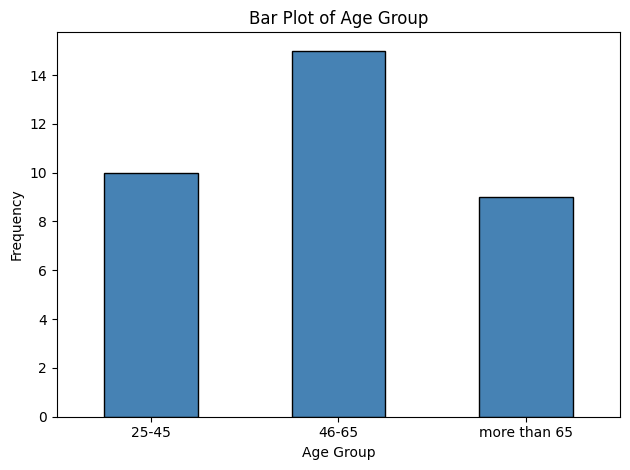

In [152]:
# EXAMPLE VALUES EXPLAINED: Bar heights are calculated frequencies of age groups.
# Normalising instead gives proportions; category order and colours are display
# choices.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Pass normalize=True inside value_counts() if you want Proportions instead of Frequency
# Count categories; normalize=True changes counts to proportions.
counts = lung["age_grp"].value_counts(sort=False)

plt.figure()
counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.xlabel("Age Group")
plt.ylabel("Frequency")
plt.title("Bar Plot of Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#### 2.2B Pie Chart (1 Categorical Variable)

**APPENDIX-09 · Example values explained:** Pie slices use computed gender counts. %1.1f%% displays one decimal percentage; the two colours correspond to the two categories.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `counts = s.value_counts(dropna=False)` | normalize=True returns proportions; sort=False avoids frequency sorting; dropna=False includes missing values.<br><br>**Parameter choices and examples:**<br><br>**normalize / dropna / sort:** Each takes True/False: normalize=True proportions, False counts; dropna=False includes missing, True excludes; sort=True orders by frequency, False preserves category/order behaviour. **Default:** normalize=False; dropna=True; sort=True.<br>**Examples:** s.value_counts(normalize=True,dropna=False,sort=False) | Returns counts/proportions indexed by category. Multiply proportions by 100 for percentages. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.pie(counts,labels=labels,autopct="%1.1f%%")` | Slice values are counts or nonnegative weights; labels match slice order; autopct formats percentage text.<br><br>**Parameter choices and examples:**<br><br>**labels / colors / autopct:** labels/colours match slice order. autopct=None omits percentages; a format string or callable formats them.<br>**Examples:** plt.pie(counts,labels=names,autopct="%1.1f%%"); plt.pie(counts,autopct="%1.0f%%")<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws the slices and returns plot artists; %1.1f displays one decimal place. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


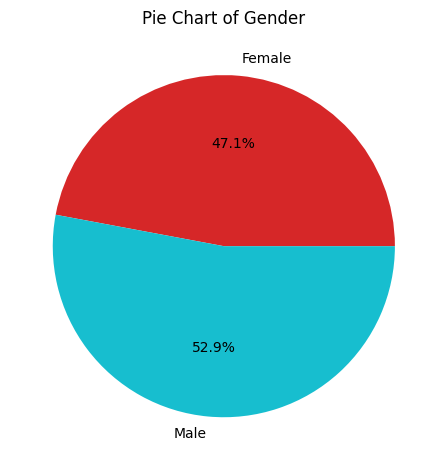

In [153]:
# EXAMPLE VALUES EXPLAINED: Pie slices use computed gender counts. %1.1f%% displays
# one decimal percentage; the two colours correspond to the two categories.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Count categories; normalize=True changes counts to proportions.
gender_counts = lung["gender"].value_counts(sort=False)

plt.figure()
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    colors=["tab:red", "tab:cyan"],
    autopct="%1.1f%%",
)
plt.title("Pie Chart of Gender")
plt.tight_layout()
plt.show()


#### 2.2C Histogram (1 Quantitative Variable)

**APPENDIX-10 · Example values explained:** Histogram edges from arange(0,65,5) are 0,5,...,60, giving width-5 mark intervals. This is a display choice appropriate to the example marks, not a required range for another exam.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


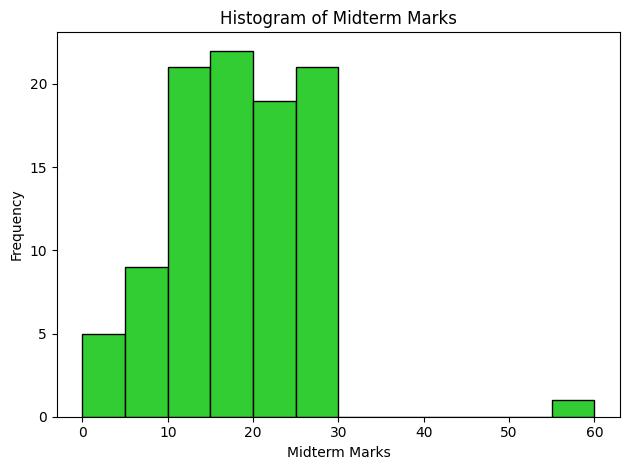

In [154]:
# EXAMPLE VALUES EXPLAINED: Histogram edges from arange(0,65,5) are 0,5,...,60,
# giving width-5 mark intervals. This is a display choice appropriate to the example
# marks, not a required range for another exam.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Set density=True if you want Probability Density instead of Frequency
plt.figure()
plt.hist(mark, bins=np.arange(0, 65, 5), color="limegreen", edgecolor="black")
plt.xlabel("Midterm Marks")
plt.ylabel("Frequency")
plt.title("Histogram of Midterm Marks")
plt.tight_layout()
plt.show()


#### 2.2D Boxplot (1 Quantitative Variable)

**APPENDIX-11 · Example values explained:** The boxplot uses actual example marks. patch_artist/colours are graphical settings; the fliers are computed values outside the boxplot whiskers.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `course_boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Run SETUP-01 for the portable helper. Supply one numeric array per box; horizontal=True changes orientation. boxprops={"facecolor":"lightblue"} styles filled boxes.<br><br>**Parameter choices and examples:**<br><br>**horizontal / labels / patch_artist / boxprops:** horizontal=True gives horizontal boxes, False vertical. labels is one label per box or None. patch_artist=True enables filled patches, False lines. boxprops is a styling dictionary. **Default:** horizontal=False; patch_artist=False.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True,patch_artist=True,boxprops={"facecolor":"lightblue"}) | Returns artists; fliers contains flagged points. &#124;SR&#124;>3 regression outliers are a different rule from boxplot IQR fliers. |
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `items = list(iterable)`<br>`settings = dict(color="blue")` | list converts an iterable; dict builds key/value associations.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Returns a Python container, not a pandas table or a NumPy array. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `artist.get_data()`<br>**OR**<br>`artist.get_ydata()` | Call on a plotted line, e.g. boxplot_result["fliers"][0]. | get_data returns x/y arrays; get_ydata returns y only. For a horizontal boxplot, observations are on x instead. |


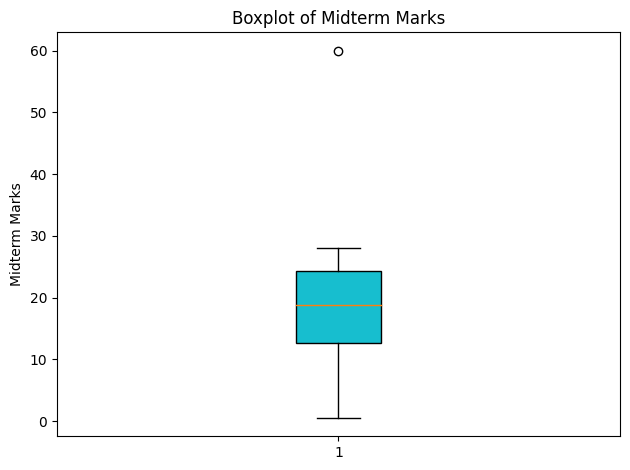

Boxplot outliers: [60.]


In [155]:
# EXAMPLE VALUES EXPLAINED: The boxplot uses actual example marks.
# patch_artist/colours are graphical settings; the fliers are computed values
# outside the boxplot whiskers.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Set orientation="horizontal" (and plt.xlabel) if you prefer a horizontal boxplot
plt.figure()
# Return rows complete in the stated columns; save the returned table.
bp = course_boxplot(
    mark.dropna(), patch_artist=True, boxprops=dict(facecolor="tab:cyan")
)
plt.ylabel("Midterm Marks")
plt.title("Boxplot of Midterm Marks")
plt.tight_layout()
plt.show()

# Optional: extract outlier values directly from the boxplot
print("Boxplot outliers:", bp["fliers"][0].get_data()[1])


---
### 2.3 Visualising Two Variables
- **Categorical vs Categorical:** Put the **explanatory variable on rows (`index`)** and **response variable on columns**, then condition on rows using `normalize="index"` (row percentages) before plotting a **Clustered** or **Stacked** bar plot.
- **Categorical vs Quantitative:** Side-by-side boxplots (`df.boxplot` or `plt.boxplot`).
- **Quantitative vs Quantitative:** Scatterplot (`plt.scatter(x, y)`) + Pearson correlation $r$ (`x.corr(y)`). Remember: $r$ only measures **linear** association, is sensitive to outliers, and **correlation $\neq$ causation**!

#### 1. Categorical vs Categorical $\to$ Contingency Table + Clustered / Stacked Bar Plot

**APPENDIX-12 · Example values explained:** In breast_cancer.csv, pmh codes 2/3 are No/Yes and bbd codes 0/1 Absent/Present. These numeric codes label categories; they are not measurements or arbitrary values to reuse with a differently coded file.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `coded = s.map({"Yes": 1, "No": 0})` | Mapping keys must match the original values exactly; values are the replacements. A function is another option.<br><br>**Parameter choices and examples:**<br><br>**mapping / function / regex:** Series.map takes a dictionary/Series or function; unlisted dictionary keys become missing. Series.replace accepts value/mapping and keeps unlisted values. str.replace takes pattern and replacement text; regex=True uses a regex, False literal text.<br>**Examples:** s.map({"Yes":1,"No":0}); s.replace({"SG":"Singapore"}); s.str.replace(".","",regex=False) | Returns recoded values; unlisted keys become missing. Assign to a new/existing column. |
| `renamed = data.rename(columns={"old": "new"})`<br>**OR**<br>`labelled = s.rename("new_series_name")` | DataFrame columns maps old column labels to new; index maps row labels. For a Series, a scalar changes its name; a mapping changes index labels. Unlisted mapped labels are retained.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns a renamed copy by default; assign it if later code uses the new names. |
| `tab = pd.crosstab(data["group"], data["outcome"], normalize="index")` | First variable forms rows, second columns. Omit normalize for counts; "index"=row, "columns"=column, "all"=overall proportions.<br><br>**Parameter choices and examples:**<br><br>**normalize:** False gives counts; True or "all" overall proportions; "index" (or 0) row proportions; "columns" (or 1) column proportions. **Default:** False.<br>**Examples:** pd.crosstab(a,b,normalize="index"); pd.crosstab(a,b,normalize="columns")<br><br>**margins / margins_name:** margins=True adds totals; False omits them. margins_name is any nonconflicting total label such as "Total". With normalisation, totals are normalised too. **Default:** margins=False; margins_name="All".<br>**Examples:** pd.crosstab(a,b,margins=True,margins_name="Total") | Returns a table. margins=True adds totals; multiply normalised proportions by 100 for percentages. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: In breast_cancer.csv, pmh codes 2/3 are No/Yes and bbd
# codes 0/1 Absent/Present. These numeric codes label categories; they are not
# measurements or arbitrary values to reuse with a differently coded file.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

bc = pd.read_csv(DATA_DIR / "breast_cancer.csv")
# Recode matching values; unlisted mapping keys become missing.
bc["pmh_use"] = bc["pmh"].map(
    {
        2: "No",
        3: "Yes",
    }
)
bc["cancer"] = bc["bbd"].map(
    {
        0: "Absent",
        1: "Present",
    }
)
pmh_use = bc["pmh_use"].rename("PMH Usage")
cancer = bc["cancer"].rename("Cancer")

# Step 1: Row-percentage contingency table (Explanatory = rows, Response = columns)
# Build a row-by-column table; normalization chooses the conditioning denominator.
row_pct = pd.crosstab(bc["pmh_use"], bc["cancer"], normalize="index") * 100
print("Row-Percentage Contingency Table (rows sum to 100%):")
print(row_pct.round(2))


**APPENDIX-13 · Example values explained:** The clustered bars use the previously computed row percentages. Heights/denominators come from data; two colours correspond to the two outcome categories.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `ax.set_xticks(positions,labels)`<br>**OR**<br>`plt.yticks(positions,labels)` | positions and labels must match in length; rotation adjusts text angle.<br><br>**Parameter choices and examples:**<br><br>**positions / labels / rotation:** positions are numeric tick locations; labels are an equal-length text list. rotation can be numeric degrees or "horizontal"/"vertical".<br>**Examples:** ax.set_xticks([0,1],["A","B"]); plt.xticks(rotation=45) | Changes tick positions/text; label order should match the plotted categories. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: The clustered bars use the previously computed row
# percentages. Heights/denominators come from data; two colours correspond to the
# two outcome categories.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1A. Clustered Bar Plot (stacked=False by default)
row_pct.plot(kind="bar", color=["darkblue", "tab:red"], edgecolor="black")
plt.xlabel("PMH Usage")
plt.ylabel("Percentage (%)")
plt.title("Clustered Bar Plot of Cancer by PMH Usage")
plt.xticks(rotation=0)
plt.legend(title="Cancer")
plt.tight_layout()
plt.show()


**APPENDIX-14 · Example values explained:** The stacked bars use the SAME row percentages as the clustered bars. stacked=True changes presentation, not the conditional proportions.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `ax.set_xticks(positions,labels)`<br>**OR**<br>`plt.yticks(positions,labels)` | positions and labels must match in length; rotation adjusts text angle.<br><br>**Parameter choices and examples:**<br><br>**positions / labels / rotation:** positions are numeric tick locations; labels are an equal-length text list. rotation can be numeric degrees or "horizontal"/"vertical".<br>**Examples:** ax.set_xticks([0,1],["A","B"]); plt.xticks(rotation=45) | Changes tick positions/text; label order should match the plotted categories. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: The stacked bars use the SAME row percentages as the
# clustered bars. stacked=True changes presentation, not the conditional
# proportions.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1B. Stacked Bar Plot (same code, just add stacked=True)
row_pct.plot(kind="bar", stacked=True, color=["darkblue", "tab:red"], edgecolor="black")
plt.xlabel("PMH Usage")
plt.ylabel("Percentage (%)")
plt.title("Stacked Bar Plot of Cancer by PMH Usage")
plt.xticks(rotation=0)
plt.legend(title="Cancer")
plt.tight_layout()
plt.show()


#### 2. Categorical vs Quantitative $\to$ Side-by-Side Boxplot

**APPENDIX-15 · Example values explained:** agemenop is the quantitative age-at-menopause column, grouped by the cancer label. The selected data define the boxes; there are no entered probability counts.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data.boxplot(column="score",by="group",grid=False)` | column is the numeric measurement; by names the categorical grouping column. patch_artist=True permits filled boxes.<br><br>**Parameter choices and examples:**<br><br>**column / by / grid / patch_artist:** column is one numeric label/list, by one grouping label/list or None. grid=True/False toggles background lines; patch_artist=True permits filled boxes.<br>**Examples:** data.boxplot(column="score",by="group",grid=False,patch_artist=True) | Draws grouped boxes and normally returns Axes, not the artist dictionary from course_boxplot. Use the latter to extract plotted fliers. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: agemenop is the quantitative age-at-menopause column,
# grouped by the cancer label. The selected data define the boxes; there are no
# entered probability counts.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Option A: Quickest pandas way (df.boxplot)
bc.boxplot(column="agemenop", by="cancer", grid=False, patch_artist=True)
plt.suptitle("")  # clears the automatic "Boxplot grouped by..." subtitle
plt.xlabel("Cancer Status")
plt.ylabel("Age at Menopause")
plt.title("Age at Menopause by Cancer Status")
plt.tight_layout()
plt.show()


**APPENDIX-16 · Example values explained:** The two arrays contain observed age-at-menopause values for Absent and Present groups in that order. fliers[0] and fliers[1] identify the first and second plotted boxes.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `complete = data.dropna(subset=["x", "y"])` | subset limits checked columns; default how="any" drops a row missing either; how="all" drops only if all checked values are missing.<br><br>**Parameter choices and examples:**<br><br>**how / subset / axis:** how="any" drops if any checked value is missing; "all" only if all are missing. subset=None checks all; a label/list limits the check. DataFrame axis=0/"index" drops rows; 1/"columns" drops columns. When dropping rows, subset lists columns. **Default:** how="any"; axis=0; subset=None.<br>**Examples:** data.dropna(subset=["x","y"], how="any"); data.dropna(subset=["x","y"], how="all"); data.dropna(axis=1)<br><br>**thresh:** A nonnegative integer minimum number of observed values; use instead of how, not together.<br>**Examples:** data.dropna(subset=["x","y","z"], thresh=2) keeps rows with at least two observed measurements.<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns complete rows. Keep paired columns together; save the returned table. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `course_boxplot([group1,group2],labels=["A","B"],patch_artist=True)` | Run SETUP-01 for the portable helper. Supply one numeric array per box; horizontal=True changes orientation. boxprops={"facecolor":"lightblue"} styles filled boxes.<br><br>**Parameter choices and examples:**<br><br>**horizontal / labels / patch_artist / boxprops:** horizontal=True gives horizontal boxes, False vertical. labels is one label per box or None. patch_artist=True enables filled patches, False lines. boxprops is a styling dictionary. **Default:** horizontal=False; patch_artist=False.<br>**Examples:** course_boxplot([a,b],labels=["A","B"],horizontal=True,patch_artist=True,boxprops={"facecolor":"lightblue"}) | Returns artists; fliers contains flagged points. &#124;SR&#124;>3 regression outliers are a different rule from boxplot IQR fliers. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `artist.get_data()`<br>**OR**<br>`artist.get_ydata()` | Call on a plotted line, e.g. boxplot_result["fliers"][0]. | get_data returns x/y arrays; get_ydata returns y only. For a horizontal boxplot, observations are on x instead. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: The two arrays contain observed age-at-menopause values
# for Absent and Present groups in that order. fliers[0] and fliers[1] identify the
# first and second plotted boxes.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Option B: Explicit plt.boxplot way (also lets you extract outliers per group)
# Return rows complete in the stated columns; save the returned table.
absent_age = bc[bc["cancer"] == "Absent"]["agemenop"].dropna()
present_age = bc[bc["cancer"] == "Present"]["agemenop"].dropna()

plt.figure()
bp = course_boxplot(
    [absent_age, present_age], labels=["Absent", "Present"], patch_artist=True
)
plt.xlabel("Cancer Status")
plt.ylabel("Age at Menopause")
plt.title("Age at Menopause by Cancer Status")
plt.tight_layout()
plt.show()

# Optional: extract outliers from each box
print("Absent outliers:", bp["fliers"][0].get_data()[1])
print("Present outliers:", bp["fliers"][1].get_data()[1])


#### 3. Quantitative vs Quantitative $\to$ Scatterplot + Correlation

**APPENDIX-17 · Example values explained:** The plot uses actual floor area (x) and resale price (y). alpha=.4 is dot opacity and s=5 marker area, not significance or sample size.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `r = first.corr(second,method="pearson")` | Pearson is default; method="spearman" uses ranks. Series align by index and pairwise remove missing values.<br><br>**Parameter choices and examples:**<br><br>**method:** "pearson" linear correlation; "spearman" rank correlation; "kendall" Kendall rank correlation; a compatible callable is also allowed. **Default:** "pearson".<br>**Examples:** data["x"].corr(data["y"],method="pearson"); data["x"].corr(data["y"],method="spearman") | Returns correlation; for a DataFrame .corr() returns the matrix. Preserve correct pairs. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: The plot uses actual floor area (x) and resale price
# (y). alpha=.4 is dot opacity and s=5 marker area, not significance or sample size.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

hdb = pd.read_csv(DATA_DIR / "hdb_2017_now.csv")

plt.figure()
plt.scatter(
    hdb["floor_area_sqm"], hdb["resale_price"], color="tab:blue", alpha=0.4, s=5
)
plt.xlabel("Floor Area (sqm)")
plt.ylabel("Resale Price ($)")
plt.title("Floor Area vs Resale Price")
plt.tight_layout()
plt.show()

corr = hdb["floor_area_sqm"].corr(hdb["resale_price"])
print("Correlation r:", round(corr, 4))


---
<a id="topics-3-4"></a>
# Topics 3 & 4: Study Design, Confounding & Probability Foundations

*(Topics 3 and 4 are primarily conceptual/mathematical in ST1131, but Python is handy for Relative Risk, stratifying by confounders, combinatorics, and Bayes' Theorem calculations.)*

## Summary of Python Tools & Formulas (Topics 3 & 4)

| Function / Pattern | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `math.comb(n, k)` | `n`: total items (non-negative `int`)<br>`k`: number of items chosen without order (`int`) | Binomial coefficient $C^n_k = \binom{n}{k} = \frac{n!}{k!(n-k)!}$ |
| `math.factorial(n)` | `n`: non-negative `int` | Computes $n! = n \times (n-1) \times \dots \times 1$ |
| `pd.crosstab(exposure, outcome, normalize="index")` | `exposure`: explanatory group `Series`<br>`outcome`: binary outcome `Series` | Gives conditional risk $\hat{p} = P(\text{Event} \mid \text{Group})$ in each row for **Relative Risk** ($RR = \hat{p}_1 / \hat{p}_2$) and **Risk Difference** ($\hat{p}_1 - \hat{p}_2$) |
| `for lvl, sub in df.groupby(confounder): ...` | `confounder`: third recorded categorical variable $Z$ | **Stratification (slicing):** builds separate contingency tables / Relative Risks within each level of $Z$ to check for confounding or Simpson's Paradox |

### Quick Revision Cheat-Sheet
- **Topic 3 (Data Collection & Study Design):**
  - **Observational Study** (no intervention $\implies$ association only, vulnerable to confounders/lurking variables) vs **Randomised Experimental Study** (researcher **randomly assigns** treatments to experimental units $\implies$ can establish causation).
  - **Confounding Variable** (third variable associated with explanatory and response variables, distorting their relationship) vs **Lurking Variable** (unmeasured variable affecting both). **Simpson's Paradox:** direction of association reverses when data are aggregated vs stratified by a confounder.
  - **Biases:** **Sampling bias / Undercoverage** (unrepresentative sampling frame, convenience/volunteer sampling), **Non-response bias** (high refusal/non-reply rate), **Response bias** (leading questions, dishonest self-reporting, faulty instruments).
  - **Good Experimental Design:** Control / Placebo group (accounts for placebo/expectation effect), Random Assignment (balances confounders), Double-Blinding (neither subjects nor evaluators know group), Replication (adequate sample size $n$), Blocking (group similar subjects first, then randomize within blocks).
- **Topic 4 (Probability & Diagnostic Testing):**
  - **Addition Rule:** $P(A \cup B) = P(A) + P(B) - P(A \cap B)$.
  - **Mutually Exclusive (Disjoint):** $A \cap B = \emptyset \implies P(A \cap B) = 0$. *(Trap: If $P(A)>0$ and $P(B)>0$, mutually exclusive events are **NEVER** independent because $P(A \cap B) = 0 \neq P(A)P(B)$!)*
  - **Independence:** $P(A \cap B) = P(A)P(B) \iff P(A \mid B) = P(A)$.
  - **Diagnostic Screening ($D$ = disease, $+$ = positive test):**
    - **Prevalence** $= P(D)$, **Sensitivity** $= P(+ \mid D)$, **Specificity** $= P(- \mid D^c)$.
    - False Positive Rate $= P(+ \mid D^c) = 1 - \text{Specificity}$; False Negative Rate $= P(- \mid D) = 1 - \text{Sensitivity}$.
    - **Law of Total Probability:** $P(+) = P(+ \mid D)P(D) + P(+ \mid D^c)P(D^c)$.
    - **Bayes' Theorem (PPV):** $P(D \mid +) = \dfrac{P(+ \mid D)P(D)}{P(+)}$. *(Lower prevalence $P(D) \implies$ lower $P(D \mid +)$ even if sensitivity & specificity stay high!)*

**APPENDIX-18 · Example values explained:** Risks are computed from the breast-cancer contingency table. In the SEPARATE Bayes example prev=.01 is prevalence, sens=.96 sensitivity and spec=.95 specificity; replace all three screening rates together.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `tab = pd.crosstab(data["group"], data["outcome"], normalize="index")` | First variable forms rows, second columns. Omit normalize for counts; "index"=row, "columns"=column, "all"=overall proportions.<br><br>**Parameter choices and examples:**<br><br>**normalize:** False gives counts; True or "all" overall proportions; "index" (or 0) row proportions; "columns" (or 1) column proportions. **Default:** False.<br>**Examples:** pd.crosstab(a,b,normalize="index"); pd.crosstab(a,b,normalize="columns")<br><br>**margins / margins_name:** margins=True adds totals; False omits them. margins_name is any nonconflicting total label such as "Total". With normalisation, totals are normalised too. **Default:** margins=False; margins_name="All".<br>**Examples:** pd.crosstab(a,b,margins=True,margins_name="Total") | Returns a table. margins=True adds totals; multiply normalised proportions by 100 for percentages. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: Risks are computed from the breast-cancer contingency
# table. In the SEPARATE Bayes example prev=.01 is prevalence, sens=.96 sensitivity
# and spec=.95 specificity; replace all three screening rates together.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. Relative Risk & Difference in Proportions (Breast Cancer PMH example)
# Build a row-by-column table; normalization chooses the conditioning denominator.
prop_table = pd.crosstab(pmh_use, cancer, normalize="index")
risk_yes = prop_table.loc["Yes", "Present"]
risk_no = prop_table.loc["No", "Present"]
print(f"Risk (PMH=Yes): {risk_yes:.4f} | Risk (PMH=No): {risk_no:.4f}")
print(
    f"Relative Risk (RR) = {risk_yes / risk_no:.4f} | Risk Difference = {risk_yes - risk_no:.4f}"
)

# 2. Reusable Bayes' Theorem Calculator for Diagnostic Tests
# Question input: prevalence P(disease), as a proportion.
prev = 0.01  # P(D)
# Question input: sensitivity P(positive | disease).
sens = 0.96  # P(+ | D)
# Question input: specificity P(negative | no disease).
spec = 0.95  # P(- | D^c)

p_pos = sens * prev + (1 - spec) * (1 - prev)  # Law of Total Probability: P(+)
ppv = (sens * prev) / p_pos  # Bayes' Theorem: P(D | +)
print(f"\nP(+) = {p_pos:.5f} | Positive Predictive Value P(D | +) = {ppv:.4f}")


---
<a id="topic-5"></a>
# Topic 5: Random Variables & Probability Distributions (`scipy.stats`)

## Summary of Functions & Arguments (Topic 5)

Every distribution in `scipy.stats` (`bernoulli`, `binom`, `norm`, `t`, etc.) shares the **exact same method names** — only the distribution parameters (`...`) change:

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `<dist>.pmf(k, ...)` | `k`: integer value $x$ (or array `np.arange(...)`)<br>`...`: distribution parameters (see table below) | $P(X = x)$, for **discrete** distributions only (`bernoulli`, `binom`) |
| `<dist>.pdf(x, ...)` | `x`: value $x$ (or `np.linspace(...)` grid)<br>`...`: distribution parameters | Height of the density curve $f(x)$, for **continuous** distributions only. **Does NOT return a probability!** |
| `<dist>.cdf(x, ...)` | `x`: cutoff value $x$<br>`...`: distribution parameters | $P(X \le x)$, cumulative probability / area to the **left** (includes $x$ for discrete!) |
| `<dist>.sf(x, ...)` | `x`: cutoff value $x$<br>`...`: distribution parameters | $P(X > x) = 1 - P(X \le x)$, survival probability / area strictly to the **right** |
| `<dist>.ppf(q, ...)` | `q`: cumulative **left-tail** probability in `(0, 1)` *(if given top-$p$ right-tail area, input `1 - p`!)*<br>`...`: distribution parameters | Quantile $x_q$ such that $P(X \le x_q) = q$ (inverse of `.cdf`) |
| `<dist>.mean(...)`, `.var(...)`, `.std(...)` | `...`: distribution parameters only | Theoretical mean $\mu = E(X)$, variance $\sigma^2 = \text{Var}(X)$, and SD $\sigma$ |
| `<dist>.rvs(..., size=1)` | `...`: distribution parameters<br>`size`: integer count `N` or tuple `(N, n)` | Draws random simulated values from the distribution |
| `np.random.seed(seed)` | `seed`: non-negative integer (e.g. `1131`) | Fixes random seed so `.rvs(...)` / `np.random` simulations are reproducible |

### Exact Parameter Arguments (`...`) for Each Distribution in Topic 5

| Distribution | How to Call (`...` Arguments) | Caution / Formula Notes |
|---|---|---|
| $X \sim \text{Bernoulli}(p)$ | `bernoulli.<method>(x, p)`<br>• `x`: `0` or `1`<br>• `p`: probability of success ($1$) | Same as `binom.<method>(x, 1, p)`. $E(X)=p$, $\text{Var}(X)=p(1-p)$ |
| $X \sim \text{Bin}(n, p)$ | `binom.<method>(x, n, p)`<br>• `x`: integer count in `0, 1, ..., n`<br>• `n`: total independent trials<br>• `p`: probability of success per trial | $E(X)=np$, $\text{Var}(X)=np(1-p)$.<br>**Discrete trap:** $P(X \ge k) = P(X > k-1) =$ **`binom.sf(k - 1, n, p)`**! |
| $X \sim N(\mu, \sigma^2)$ | `norm.<method>(x, loc=0, scale=1)`<br>• `x` (or `q` for `.ppf`): value / probability<br>• `loc`: mean $\mu$ (default `0`)<br>• `scale`: **SD $\sigma = \sqrt{\sigma^2}$** (default `1`) | **CRITICAL:** Lectures write $N(\mu, \sigma^2)$, e.g. $N(80, 144)$, so you **must** pass `scale=np.sqrt(144)` (`12`), **NOT** `144`! Omit `loc, scale` for standard normal $Z \sim N(0,1)$ |
| Custom Discrete Table $(x_i, p_i)$ | `mu = np.sum(x * probs)`<br>`var = np.sum((x - mu)**2 * probs)` | Pass 1D NumPy arrays `x` and `probs` (check `np.isclose(probs.sum(), 1)`). Linear rules: $E(aX+b)=aE(X)+b$, $\text{Var}(aX+b)=a^2\text{Var}(X)$; independent sum/diff: $\text{Var}(X \pm Y) = \text{Var}(X) + \text{Var}(Y)$ |

---

### 5.1 Custom Discrete RVs & Binomial Distribution

**APPENDIX-19 · Example values explained:** Outcomes [0,1,2,3,4] pair with probabilities [.15,.35,.25,.15,.10]. Y=1.5X-.5 is a chosen profit transformation. The separate binomial uses n=10,p=.25,k=5; 1131 is a random seed.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `values = np.array([1, 2, 3], dtype=float)` | array constructs an array; asarray converts existing data and may reuse memory. dtype selects number/type representation.<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64") | Returns an ndarray. If you need an independent editable copy, use .copy(). |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `probability = binom.pmf(k,n,p)` | k is a success count, n fixed trials, p per-trial success probability.<br><br>**Parameter choices and examples:**<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns P(X=k), the exact point probability of a discrete binomial count. |
| `combinations = math.comb(n,k)` | n and k are nonnegative integers with k<=n; order of selected items is ignored. | Returns the binomial combination count n choose k, not a probability by itself. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: Outcomes [0,1,2,3,4] pair with probabilities
# [.15,.35,.25,.15,.10]. Y=1.5X-.5 is a chosen profit transformation. The separate
# binomial uses n=10,p=.25,k=5; 1131 is a random seed.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

np.random.seed(1131)

# 1. Custom Discrete RV: E(X), Var(X), and Linear Transformation Y = 1.5X - 0.5
x_vals = np.array([0, 1, 2, 3, 4])
x_probs = np.array([0.15, 0.35, 0.25, 0.15, 0.10])
mu_x = np.sum(x_vals * x_probs)
var_x = np.sum((x_vals - mu_x) ** 2 * x_probs)
print(
    f"Custom Discrete X -> E(X) = {mu_x:.4f}, Var(X) = {var_x:.4f}, SD(X) = {np.sqrt(var_x):.4f}"
)
print(
    f"Transformed Y = 1.5X - 0.5 -> E(Y) = {1.5*mu_x - 0.5:.4f}, Var(Y) = {1.5**2 * var_x:.4f}"
)

# 2. Binomial Distribution: X ~ Bin(10, 0.25)
# Question input: number of observations/trials in this sample.
n = 10
p = 0.25
print(
    f"\nBin(10, 0.25): P(X = 5) = {binom.pmf(5, n, p):.4f} (by math.comb: {math.comb(n, 5) * p**5 * (1-p)**5:.4f})"
)
print(f"At most 4  P(X <= 4) = {binom.cdf(4, n, p):.4f}")
print(
    f"At least 5 P(X >= 5) = P(X > 4) = {binom.sf(4, n, p):.4f} (== {1 - binom.cdf(4, n, p):.4f})"
)
# Average values; for a Boolean mask this gives the True proportion.
# Compute variance: ddof=1 is sample variance, whose square root is sample SD.
print(f"Mean = {binom.mean(n, p)}, Variance = {binom.var(n, p)}")


### 5.2 Normal Distribution, Quantiles, Standardisation & Continuity Correction

When $n$ is large and $np(1-p) \ge 5$, $X \sim \text{Bin}(n, p)$ is well approximated by $Y \sim N\big(np,\; np(1-p)\big)$ with **continuity correction** ($\pm 0.5$):

| Discrete Binomial Event | Whole Numbers Included | Normal Approximation $Y \sim N(np, np(1-p))$ | Python Code (`sigma = np.sqrt(n*p*(1-p))`) |
|---|---|---|---|
| $P(X \le k)$ | $\dots, k-1, k$ | $P(Y \le k + 0.5)$ | `norm.cdf(k + 0.5, n*p, sigma)` |
| $P(X < k)$ | $\dots, k-2, k-1$ | $P(Y \le k - 0.5)$ | `norm.cdf(k - 0.5, n*p, sigma)` |
| $P(X \ge k)$ | $k, k+1, \dots$ | $P(Y \ge k - 0.5)$ | `norm.sf(k - 0.5, n*p, sigma)` |
| $P(X > k)$ | $k+1, k+2, \dots$ | $P(Y \ge k + 0.5)$ | `norm.sf(k + 0.5, n*p, sigma)` |
| $P(X = k)$ | $k$ only | $P(k - 0.5 \le Y \le k + 0.5)$ | `norm.cdf(k + 0.5, n*p, sigma) - norm.cdf(k - 0.5, n*p, sigma)` |

**APPENDIX-20 · Example values explained:** Normal example: mean 80 and variance 144, so SD=12; 60/73/90 are event limits. .90 is a percentile probability. Separate binomial example: n=25,p=.4; 8/10 are event counts and .5 is the continuity correction. Plotting ranges/point counts only control display.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.cdf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.cdf(k,n,p)`<br>**OR**<br>`t.cdf(t_stat,df)` | First argument is a cutoff, not a probability. Normal scale is SD; binomial inputs are trials/probability; t needs degrees of freedom.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X<=cutoff), the LEFT tail. For integer strict <k, use binom.cdf(k-1,n,p). |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `probability = binom.pmf(k,n,p)` | k is a success count, n fixed trials, p per-trial success probability.<br><br>**Parameter choices and examples:**<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns P(X=k), the exact point probability of a discrete binomial count. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `ax.bar(positions,heights,width=.35)`<br>**OR**<br>`counts.plot.bar(rot=0)` | Manual bar uses x positions and heights; pandas plot.bar uses index labels and values. stacked=True stacks multiple series.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**width:** For plt.bar/ax.bar, a positive scalar or compatible array gives bar width in x-coordinate units. For pandas .plot.bar, width controls bar/group allocation.<br>**Examples:** ax.bar(positions,heights,width=.35); ax.bar(positions+.35,other_heights,width=.35)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Returns plot artists/Axes. Counts, proportions and percentages are different inputs; choose the intended denominator first. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `height = norm.pdf(x,loc=mu,scale=sigma)` | x can be one point or a plotting grid; scale is population SD.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns density HEIGHT, not probability. Use cdf differences or sf for areas. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: Normal example: mean 80 and variance 144, so SD=12;
# 60/73/90 are event limits. .90 is a percentile probability. Separate binomial
# example: n=25,p=.4; 8/10 are event counts and .5 is the continuity correction.
# Plotting ranges/point counts only control display.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. Normal probabilities & quantiles for X ~ N(80, 144) -> mu = 80, sigma = sqrt(144) = 12
mu, sigma = 80, np.sqrt(144)
print(f"P(60 <= X <= 73) = {norm.cdf(73, mu, sigma) - norm.cdf(60, mu, sigma):.4f}")
print(f"P(X >= 90)       = {norm.sf(90, mu, sigma):.4f}")
print(f"90th percentile (top 10% cutoff): x = {norm.ppf(0.90, mu, sigma):.4f}")

# Standardisation check: Z = (X - mu) / sigma ~ N(0, 1)
z_73 = (73 - mu) / sigma
print(
    f"Direct norm.cdf(73, 80, 12) = {norm.cdf(73, mu, sigma):.4f} == Standardised norm.cdf(z) = {norm.cdf(z_73):.4f}"
)

# 2. Normal Approximation to Binomial with Continuity Correction: Bin(25, 0.4), np(1-p) = 6 >= 5
n_b = 25
p_b = 0.4
mu_b, sd_b = n_b * p_b, np.sqrt(n_b * p_b * (1 - p_b))
print(
    f"\nBin(25, 0.4) P(X <= 8): Exact = {binom.cdf(8, n_b, p_b):.4f} | Normal w/ CC = {norm.cdf(8.5, mu_b, sd_b):.4f}"
)
print(
    f"Bin(25, 0.4) P(X = 10): Exact = {binom.pmf(10, n_b, p_b):.4f} | Normal w/ CC = {norm.cdf(10.5, mu_b, sd_b) - norm.cdf(9.5, mu_b, sd_b):.4f}"
)

# Visualise Binomial bars + Normal Approximation curve
k = np.arange(0, n_b + 1)
xs = np.linspace(0, n_b, 400)
plt.figure(figsize=(7, 3.5))
plt.bar(
    k,
    binom.pmf(k, n_b, p_b),
    color="tab:blue",
    alpha=0.7,
    edgecolor="black",
    label="Exact Bin(25, 0.4)",
)
plt.plot(
    xs, norm.pdf(xs, mu_b, sd_b), color="red", linewidth=2, label=r"$N(10, 6)$ curve"
)
plt.xlabel(r"$x$")
plt.ylabel("Probability / Density")
plt.title(r"Normal Approximation to $Bin(25, 0.4)$ ($np(1-p) = 6 \geq 5$)")
plt.legend()
plt.tight_layout()
plt.show()


---
<a id="topic-6"></a>
# Topic 6: Sampling Distributions & Central Limit Theorem (CLT)

## Summary of Functions & Arguments (Topic 6)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `np.random.seed(seed)` | `seed`: integer (e.g. `1131`) | Resets random number generator so simulation output is identical every run |
| `np.random.normal(loc=0.0, scale=1.0, size=None)` | `loc`: population mean $\mu$<br>`scale`: **population SD $\sigma$** (not $\sigma^2$!)<br>`size`: `n` (1D sample) or **`(N, n)`** ($N$ rows, each a sample of size $n$) | Simulates random draws from $N(\mu, \sigma^2)$ |
| `np.random.exponential(scale=1.0, size=None)` | `scale`: population **mean** $\lambda$ (also equals SD $\lambda$)<br>`size`: `n` or **`(N, n)`** | Simulates draws from a right-skewed Exponential distribution with mean `scale` *(avoid naming variable `lambda`!)* |
| `np.random.binomial(n, p, size=None)` | `n`: sample size / trials per poll<br>`p`: true population proportion<br>`size`: `N` (number of simulated polls) | Draws $N$ counts from $\text{Bin}(n, p)$. Divide by `n` (`np.random.binomial(n, p, size=N) / n`) to simulate $N$ sample proportions $\hat{p}$! |
| `np.random.choice(a, size=None, replace=True, p=None)` | `a`: 1D population array/list to sample from<br>`size`: `n` or **`(N, n)`**<br>`replace`: `True` (with replacement, default), `False` (without)<br>`p`: optional probability weights | Draws random sample(s) from an existing array/population |
| `np.random.randint(low, high, size=None)` | `low`: inclusive min integer<br>`high`: **exclusive** max integer (use `1, 7` for fair 6-sided die!)<br>`size`: `n` or **`(N, n)`** | Draws discrete uniform random integers from `{low, ..., high - 1}` |
| `N_samples.mean(axis=1)` | `axis=1`: averages **across each row** of a `(N, n)` 2D array | Produces a 1D array of $N$ simulated sample means $\bar{x}_1, \dots, \bar{x}_N$ |
| `np.mean(bool_condition)` | `bool_condition`: boolean array, e.g. `np.abs(p_hat - p) <= 3*se` | Because `True == 1` and `False == 0`, returns the **empirical proportion** of simulated samples satisfying the condition |

### Key Concepts & Formulas (Topic 6)
1. **Three Distributions — Don't Mix Them Up:**
   - **Population distribution:** distribution of $X$ across the entire population (mean $\mu$, SD $\sigma$, fixed/unknown).
   - **Sample (data) distribution:** histogram of $n$ observations in **one** collected sample (resembles the population shape).
   - **Sampling distribution:** probability distribution of a **statistic** ($\bar{X}$ or $\hat{p}$) across all possible random samples of size $n$.
2. **Sampling Distribution of the Sample Mean $\bar{X}$:**
   - For independent observations from a common population with finite variance, for **any** $n$: $E(\bar{X}) = \mu$ and $SD(\bar{X}) = \dfrac{\sigma}{\sqrt{n}}$.
   - If the population is **Normal** $N(\mu, \sigma^2)$: $\bar{X} \sim N\left(\mu, \dfrac{\sigma^2}{n}\right)$ **exact for any $n$**.
   - **Central Limit Theorem (CLT):** Even if the population is non-normal/skewed, for large sample size **$n \ge 30$** (rule of thumb), $\bar{X} \approx N\left(\mu, \dfrac{\sigma^2}{n}\right)$ approximately.
3. **Sample Size $n$ vs Number of Simulated Samples $N$:**
   - Increasing **$n$** changes the **true** sampling distribution (shrinks spread $\sigma/\sqrt{n}$ and makes skewed distributions bell-shaped via CLT).
   - Increasing **$N$** (simulation-only!) does **not** change the true curve — it only makes the simulated histogram smoother.
4. **Sampling Distribution of Sample Proportion $\hat{p} = X/n$:**
   - $E(\hat{p}) = p$, $SD(\hat{p}) = \sqrt{\dfrac{p(1-p)}{n}}$. When $np(1-p) \ge 5$ (the course condition; separate expected-count checks used elsewhere are not identical), $\hat{p} \approx N\left(p, \dfrac{p(1-p)}{n}\right)$.

**APPENDIX-21 · Example values explained:** 151 and 3889 are seeds in different simulation blocks. Exponential mean/SD=5000, N=2000 repeated samples, and n=7/50 compare sample sizes. Polling example uses true p=.531, n=3889 and 10000 repetitions. The 3-SE band is a chosen probability comparison.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.random.seed(1131)` | Replace the integer seed if prescribed; set it immediately before the intended simulation.<br><br>**Parameter choices and examples:**<br><br>**seed / random_state:** A fixed supported nonnegative integer makes repeated draws reproducible. None uses changing generator state/entropy. np.random.seed affects the legacy generator, not independent default_rng generators. For an integer legacy seed use 0<=seed<=2**32-1.<br>**Examples:** np.random.seed(42); data.sample(n=3,random_state=1131) | Resets the legacy NumPy generator so a repeated sequence is reproducible; does not set sample size. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `for first,second in zip(values,weights): ...` | Supply matching ordered collections; ordinary zip stops at the shortest. | Pairs same-position items; it does not align pandas labels or verify equal lengths. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `draws = np.random.exponential(scale=1/rate,size=(N,n))` | scale is MEAN (also SD), not rate; if mean is given use scale=mean directly.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**scale:** Nonnegative numeric mean (also SD); positive gives the ordinary exponential distribution. If rate r is given use scale=1/r, requiring r>0.<br>**Examples:** np.random.exponential(scale=5,size=25); np.random.exponential(scale=1/.2,size=25) | Returns positive right-skewed draws; each row is one sample when size=(N,n). |
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `height = norm.pdf(x,loc=mu,scale=sigma)` | x can be one point or a plotting grid; scale is population SD.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns density HEIGHT, not probability. Use cdf differences or sf for areas. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.xlabel("Hours")`<br>**OR**<br>`ax.set_ylabel("Score")` | Supply the label text, including units when available. | Labels the horizontal/vertical axis; it does not choose data columns. |
| `plt.legend(title="Group")` | Give plotted series label=... first; the legend uses those labels.<br><br>**Parameter choices and examples:**<br><br>**title / loc:** title is arbitrary descriptive text or None. Common loc values: "best", "upper right", "upper left", "lower left", "lower right", "right", "center left", "center right", "lower center", "upper center", "center".<br>**Examples:** plt.legend(title="Group",loc="upper left") | Displays the mapping between plotted colours/symbols and groups. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `counts = np.random.binomial(n,p,size=N)` | n trials per experiment, p success probability, N simulated experiments.<br><br>**Parameter choices and examples:**<br><br>**size:** None gives one scalar draw; a nonnegative integer gives a 1D length; a tuple gives an array shape. For repeated samples, size=(N,n) means N rows, n observations per row. Use positive dimensions for nonempty samples; size=0 produces no observations.<br>**Examples:** size=None -> scalar; size=25 -> shape (25,); size=(5000,25) -> shape (5000,25); size=(25,) -> one 1D sample.<br><br>**n / p / k:** n is a nonnegative integer trials count; p is a probability in [0,1]; binomial k is an integer success count. k outside 0..n has zero PMF.<br>**Examples:** np.random.binomial(20,.3,size=1000); binom.pmf(5,20,.3) | Returns success COUNTS; divide by n to obtain simulated sample proportions. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: 151 and 3889 are seeds in different simulation blocks.
# Exponential mean/SD=5000, N=2000 repeated samples, and n=7/50 compare sample
# sizes. Polling example uses true p=.531, n=3889 and 10000 repetitions. The 3-SE
# band is a chosen probability comparison.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

np.random.seed(151)

# 1. CLT Demo on a heavily right-skewed Exponential(mean=5000) population: n = 7 vs n = 50
# Question input: exponential SCALE/mean (also its SD), not a rate.
lam = 5000
# Simulation setting: number of repeated samples/experiments.
N = 2000

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, [7, 50]):
    # Average values; for a Boolean mask this gives the True proportion.
    means = np.random.exponential(scale=lam, size=(N, n)).mean(axis=1)
    xs = np.linspace(means.min(), means.max(), 300)
    ax.hist(
        means, bins=25, density=True, color="tab:red", alpha=0.75, edgecolor="black"
    )
    ax.plot(
        xs,
        norm.pdf(xs, loc=lam, scale=lam / np.sqrt(n)),
        color="black",
        lw=2,
        label="CLT Normal curve",
    )
    # Compute SD: ddof=1 is sample SD; do not pass variance where SD is required.
    ax.set_title(
        f"n = {n}: Mean={means.mean():.1f}, SD={means.std(ddof=1):.1f} (Theory {lam/np.sqrt(n):.1f})"
    )
    ax.set_xlabel(r"Sample Mean $\bar{x}$")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

# 2. Sampling Distribution of Sample Proportion p_hat (n = 3889, p = 0.531)
np.random.seed(3889)
n_poll = 3889
p_true = 0.531
p_hats = np.random.binomial(n_poll, p_true, size=10000) / n_poll
se_true = np.sqrt(p_true * (1 - p_true) / n_poll)
print(
    f"Simulated p_hat -> Mean: {p_hats.mean():.4f} (true p={p_true}), SD: {p_hats.std(ddof=1):.4f} (theory={se_true:.4f})"
)
print(
    f"Proportion within 3 SE of p: {np.mean(np.abs(p_hats - p_true) <= 3 * se_true):.4f}"
)


---
<a id="topic-7"></a>
# Topic 7: Confidence Intervals

$$\text{Confidence Interval} = \text{Point Estimate} \pm \text{Multiplier} \times \text{Standard Error (SE)}$$

## Summary of Functions & Arguments (Topic 7)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `norm.ppf(q)` | `q`: **`1 - alpha / 2`** (e.g. `0.975` for 95% CI, `0.95` for 90% CI, `0.995` for 99% CI)<br>`loc=0, scale=1` omitted | Standard normal multiplier $z_{1-\alpha/2}$ (used for **proportion $p$ CIs** and **all sample-size formulas**) |
| `t.ppf(q, df)` | `q`: **`1 - alpha / 2`** (two-tailed quantile)<br>`df`: degrees of freedom **`n - 1`** | $t$-distribution multiplier $t_{n-1,\, 1-\alpha/2}$ (used for **population mean $\mu$ CI** when $\sigma$ is unknown) |
| `np.sqrt(p_hat * (1 - p_hat) / n)` | `p_hat`: sample proportion $\hat{p}$<br>`n`: sample size | Standard error $SE(\hat{p})$ for a proportion CI *(uses $\hat{p}$ because true $p$ is unknown; check $n\hat{p}(1-\hat{p}) \ge 5$)* |
| `s / np.sqrt(n)` | `s`: **sample** SD (`np.std(data, ddof=1)` or `series.std()`)<br>`n`: `len(data)` | Standard error $SE(\bar{x})$ for a population mean CI |
| `norm.interval(confidence, loc, scale)` | `confidence`: CI level in `(0, 1)`, e.g. **`0.95`**<br>`loc`: point estimate `p_hat`<br>`scale`: standard error `se` | Shortcut returning `(lower, upper)` $100(1-\alpha)\%$ CI for population proportion $p$ |
| `t.interval(confidence, df, loc, scale)` | `confidence`: CI level in `(0, 1)`, e.g. **`0.95`**<br>`df`: **`n - 1`**<br>`loc`: sample mean `x_bar`<br>`scale`: standard error `s / np.sqrt(n)` | Shortcut returning `(lower, upper)` $100(1-\alpha)\%$ CI for population mean $\mu$ |
| `math.ceil(x)` *(or `np.ceil(x)`)* | `x`: unrounded minimum sample size `n_needed` | **Always round UP** to the next integer when finding required sample size $n$ (`round()` can make $n$ too small!) |

### Formula & Assumptions Reference (Topic 7)

| Parameter | $100(1-\alpha)\%$ Confidence Interval Formula | Assumptions / Validity Check | Sample Size $n$ for Width $\le D$ *(note: Margin of Error $M = D/2$)* |
|---|---|---|---|
| **Proportion $p$** | $\hat{p} \pm z_{1-\alpha/2}\sqrt{\dfrac{\hat{p}(1-\hat{p})}{n}}$ | Random sample & $n\hat{p}(1-\hat{p}) \ge 5$ | $n \ge \left(\dfrac{2 z_{1-\alpha/2}}{D}\right)^2 p(1-p)$<br>*(Use conservative **$p = 0.5$** if $p$ is unknown)* |
| **Mean $\mu$** ($\sigma$ unknown) | $\bar{x} \pm t_{n-1,\, 1-\alpha/2}\dfrac{s}{\sqrt{n}}$ | Independent random sample; population normal for exact small-n inference, or adequate large-n approximation (n>=30 is a rule of thumb) | $n \ge \left(\dfrac{2 z_{1-\alpha/2}\, s}{D}\right)^2$<br>*(Uses $z_{1-\alpha/2}$ since $n$, hence $df$, is unknown; $s$ from pilot study)* |

> **Interpreting 95% Confidence:** "We are 95% confident that the true parameter lies in `(lower, upper)`." Over many repeated random samples, ~95% of intervals constructed this way will cover the fixed true parameter. **Never** say "there is a 95% probability that $\mu$ moves/falls inside `(3.06, 3.36)`" — once computed, both $\mu$ and the numbers `(3.06, 3.36)` are fixed!

**APPENDIX-22 · Example values explained:** Proportion example n=3889,p_hat=.531,confidence=.95. Separate mean example n=47,mean=3.208,sample SD=.506. Total target widths .10/.20 differ from margin of error; .5064 is the pilot SD for planning. .975 is the 95% two-sided normal quantile probability.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: Proportion example n=3889,p_hat=.531,confidence=.95.
# Separate mean example n=47,mean=3.208,sample SD=.506. Total target widths .10/.20
# differ from margin of error; .5064 is the pilot SD for planning. .975 is the 95%
# two-sided normal quantile probability.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. 95% CI for a Population Proportion p (Election: n = 3889, p_hat = 0.531)
n_p = 3889
# Question input/statistic: observed sample success proportion.
p_hat = 0.531
# Question input: desired confidence level as a proportion.
conf = 0.95
alpha = 1 - conf
print(f"Assumption check n*p_hat*(1-p_hat) = {n_p * p_hat * (1 - p_hat):.2f} >= 5")

se_p = np.sqrt(p_hat * (1 - p_hat) / n_p)
z_mult = norm.ppf(1 - alpha / 2)
ci_p_manual = (p_hat - z_mult * se_p, p_hat + z_mult * se_p)
ci_p_short = norm.interval(conf, loc=p_hat, scale=se_p)
print(f"95% CI for p (manual):   ({ci_p_manual[0]:.4f}, {ci_p_manual[1]:.4f})")
print(f"95% CI for p (shortcut): ({ci_p_short[0]:.4f}, {ci_p_short[1]:.4f})")

# 2. 95% CI for a Population Mean mu (Baby weights: n = 47, x_bar = 3.208, s = 0.506)
n_m = 47
# Question input/statistic: sample mean.
x_bar = 3.208
# Question input/statistic: SAMPLE standard deviation, not variance.
s = 0.506
se_m = s / np.sqrt(n_m)
t_mult = t.ppf(1 - alpha / 2, df=n_m - 1)  # Note: variable named t_mult, NEVER 't'!
ci_m_manual = (x_bar - t_mult * se_m, x_bar + t_mult * se_m)
ci_m_short = t.interval(conf, df=n_m - 1, loc=x_bar, scale=se_m)
print(
    f"\n95% CI for mu (manual):   ({ci_m_manual[0]:.3f}, {ci_m_manual[1]:.3f}) | t-multiplier = {t_mult:.4f}"
)
print(f"95% CI for mu (shortcut): ({ci_m_short[0]:.3f}, {ci_m_short[1]:.3f})")

# 3. Sample Size Determination (Target total width D; if given Margin of Error M, set D = 2 * M!)
D_prop = 0.10
n_prop_needed = (2 * norm.ppf(0.975) / D_prop) ** 2 * 0.5 * (1 - 0.5)
print(
    f"\nSample size for p (95% CI, width <= 0.10, p=0.5): {n_prop_needed:.2f} -> math.ceil = {math.ceil(n_prop_needed)}"
)

D_mean = 0.20
# Question input: SD estimated from a pilot/similar study.
s_pilot = 0.5064
n_mean_needed = (2 * norm.ppf(0.975) * s_pilot / D_mean) ** 2
print(
    f"Sample size for mu (95% CI, width <= 0.20):       {n_mean_needed:.2f} -> math.ceil = {math.ceil(n_mean_needed)}"
)


## SHORT CUT FUNCTIONS

### CI for population mean and proportion

**APPENDIX-23 · Example values explained:** mean_ci arguments are sample mean, integer sample size and SAMPLE SD; confidence defaults to .95. Validation limits 0/1 bound a probability; n-1 is the t degrees-of-freedom rule.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `type(value)`<br>**OR**<br>`isinstance(value,(int,float))` | type inspects the actual class; isinstance tests membership of one or several classes. | Returns a type object or Boolean; used for checking helper inputs, not estimating a parameter. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `int(3.9)`<br>**OR**<br>`float("3.5")`<br>**OR**<br>`str(10)`<br>**OR**<br>`bool(value)` | int truncates toward zero; float parses valid numeric text; str makes text. Empty/zero values are False, but nonempty "0" is True. | Returns the converted scalar. Dirty numeric text needs to_numeric(errors="coerce") if invalid input should become missing. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: mean_ci arguments are sample mean, integer sample size
# and SAMPLE SD; confidence defaults to .95. Validation limits 0/1 bound a
# probability; n-1 is the t degrees-of-freedom rule.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.


def mean_ci(mean, n, s, confidence=0.95):
    """Two-sided t CI: mean=sample mean, n=sample size, s=SAMPLE SD."""
    if not isinstance(n, (int, np.integer)) or n < 2:
        raise ValueError("Require integer n >= 2.")
    if not np.isfinite(mean) or not np.isfinite(s) or s < 0 or not 0 < confidence < 1:
        raise ValueError("Require finite mean, finite s >= 0 and 0 < confidence < 1.")
    if s == 0:
        return float(mean), float(mean)
    se = s / np.sqrt(n)
    return stats.t.interval(confidence=confidence, df=n - 1, loc=mean, scale=se)


**APPENDIX-24 · Example values explained:** proportion_ci arguments are the observed success proportion and sample size; confidence defaults to .95. The threshold 5 is the course approximation condition, not a success count supplied by an example.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `type(value)`<br>**OR**<br>`isinstance(value,(int,float))` | type inspects the actual class; isinstance tests membership of one or several classes. | Returns a type object or Boolean; used for checking helper inputs, not estimating a parameter. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `low,high = t.interval(confidence,df=n-1,loc=mean,scale=se)` | confidence is coverage, e.g. .95, not alpha. For a mean CI scale is SE=s/sqrt(n); normal intervals omit df.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90)<br><br>**loc / scale / df:** For a mean CI, loc=sample mean, scale=SE (not raw SD), and t df=n-1. For a population distribution interval, loc/scale are distribution mean/SD.<br>**Examples:** t.interval(.95,df=n-1,loc=x_bar,scale=s/np.sqrt(n)); norm.interval(.95,loc=p_hat,scale=se) | Returns the central two-sided interval. Using population SD instead of SE gives a distribution interval, not a mean CI. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: proportion_ci arguments are the observed success
# proportion and sample size; confidence defaults to .95. The threshold 5 is the
# course approximation condition, not a success count supplied by an example.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.


def proportion_ci(p_hat, n, confidence=0.95):
    """Course normal/Wald CI with the course normal-approximation check."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("Require positive integer n.")
    if not 0 <= p_hat <= 1 or not 0 < confidence < 1:
        raise ValueError("Require 0 <= p_hat <= 1 and 0 < confidence < 1.")
    if n * p_hat * (1 - p_hat) < 5:
        raise ValueError("Normal-approximation condition is not satisfied.")
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    return stats.norm.interval(confidence=confidence, loc=p_hat, scale=se)


## Determine sample size 

**APPENDIX-25 · Example values explained:** sample_size_mean takes pilot SD and TOTAL desired width; sample_size_proportion takes total width and planning p (default .5). confidence defaults to .95; the factor 2 converts half-width to total width, and ceil rounds the required sample size upward.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `mask = np.isfinite(values)` | Supply numeric values; finite means neither NaN nor positive/negative infinity. | Returns a Boolean mask; values[mask] or data.loc[mask] removes these nonfinite entries, not arbitrary invalid ranges. |
| `raise ValueError("Explain the invalid input")` | Supply a helpful message; FileNotFoundError is for an unavailable input path. | Stops the calculation rather than producing an invalid answer. Correct the stated input problem before rerunning. |
| `cutoff = norm.ppf(q,loc=mu,scale=sigma)`<br>**OR**<br>`t.ppf(q,df)` | q is the LEFT-tail probability in 0–1, e.g. .90 for 90th percentile; two-sided multiplier uses q=1-alpha/2.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**q:** One probability or array of probabilities in [0,1]. For a normal/t finite cutoff use 0<q<1; endpoints can give infinities.<br>**Examples:** norm.ppf(.90); norm.ppf([.025,.975]); t.ppf(.975,df=11) | Returns the quantile/cutoff VALUE. To find a top 10% boundary use q=.90, not .10. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: sample_size_mean takes pilot SD and TOTAL desired width;
# sample_size_proportion takes total width and planning p (default .5). confidence
# defaults to .95; the factor 2 converts half-width to total width, and ceil rounds
# the required sample size upward.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.


def sample_size_mean(s, width, confidence=0.95):
    """Approximate planned n for a mean CI; s is pilot SD, width is TOTAL width."""
    if (
        not np.isfinite(s)
        or not np.isfinite(width)
        or s <= 0
        or width <= 0
        or not 0 < confidence < 1
    ):
        raise ValueError(
            "Require finite s > 0, finite width > 0 and 0 < confidence < 1."
        )
    z = stats.norm.ppf((1 + confidence) / 2)
    return math.ceil((2 * z * s / width) ** 2)


def sample_size_proportion(width, confidence=0.95, p=0.5):
    """Approximate planned n for a proportion CI; p=.5 is conservative if unknown."""
    if not np.isfinite(width) or width <= 0 or not 0 < confidence < 1 or not 0 < p < 1:
        raise ValueError("Require finite width > 0, 0 < confidence < 1 and 0 < p < 1.")
    z = stats.norm.ppf((1 + confidence) / 2)
    return math.ceil((2 * z / width) ** 2 * p * (1 - p))


---
<a id="topic-8"></a>
# Topic 8: Hypothesis Testing

Every hypothesis test follows **5 Steps**: (1) Check assumptions $\to$ (2) State $H_0$ and $H_1$ $\to$ (3) Compute test statistic $\to$ (4) Find $p$-value $\to$ (5) Conclusion in context (reject $H_0$ if $p\text{-value} \le \alpha$).

## Summary of Functions & Arguments (Topic 8)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `norm.sf(z)`<br>`norm.cdf(z)`<br>`2 * norm.sf(abs(z))` | `z`: observed $Z$-statistic $\dfrac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}}$ *(uses **$p_0$**, NOT $\hat{p}$!)* | Normal-approximation $p$-value for **proportion $Z$-test**:<br>• `norm.sf(z)`: right-sided ($H_1: p > p_0$)<br>• `norm.cdf(z)`: left-sided ($H_1: p < p_0$)<br>• `2 * norm.sf(abs(z))`: two-sided ($H_1: p \neq p_0$) |
| `t.sf(T, df)`<br>`t.cdf(T, df)`<br>`2 * t.sf(abs(T), df)` | `T`: observed $T$-statistic<br>`df`: degrees of freedom (`n - 1` for 1-sample/paired, `n1 + n2 - 2` for pooled 2-sample) | Exact $p$-value from $t_{df}$ for right-sided (`sf`), left-sided (`cdf`), or two-sided (`2 * sf(abs(T))`) $t$-tests when working from summary statistics |
| `ttest_1samp(a, popmean, alternative="two-sided", axis=0)` | `a`: 1D sample array/`Series` (drop `NaN`s if any)<br>`popmean`: null value $\mu_0$ under $H_0: \mu = \mu_0$<br>`alternative`: `"two-sided"` ($\mu \neq \mu_0$), `"greater"` ($\mu > \mu_0$), or `"less"` ($\mu < \mu_0$)<br>`axis`: `1` to test all rows of a `(N, n)` simulated matrix at once | One-sample $t$-test on raw data. Returns result object with `.statistic`, `.pvalue`, and `.df` |
| `levene(sample1, sample2)` | `sample1`, `sample2`: two independent numeric samples | **Levene's Test for Equal Variances** ($H_0: \sigma_1^2 = \sigma_2^2$ vs $H_1: \sigma_1^2 \neq \sigma_2^2$).<br>• Large $p > \alpha$ $\implies$ do not reject $H_0$ $\implies$ set **`equal_var=True`**<br>• Small $p \le \alpha$ $\implies$ reject $H_0$ $\implies$ set **`equal_var=False`** |
| `ttest_ind(a, b, equal_var=True, alternative="two-sided")` | `a`: Sample 1 (`Series`/array)<br>`b`: Sample 2 (`Series`/array) — **tests $\mu_a - \mu_b$**, so order matters!<br>`equal_var`: `True` (pooled $t$-test, $df=n_1+n_2-2$) or `False` (Welch's $t$-test)<br>`alternative`: `"two-sided"` ($\mu_a - \mu_b \neq 0$), `"greater"` ($\mu_a - \mu_b > 0$), `"less"` ($\mu_a - \mu_b < 0$) | Two-sample **independent** $t$-test comparing $\mu_a$ and $\mu_b$. Access `.statistic` and `.pvalue`; independent-test df/CI use `independent_t_interval` from SETUP-01 for SciPy 1.10 compatibility |
| `ttest_rel(a, b, alternative="two-sided")` | `a`, `b`: **paired/matched** arrays of identical length (**tests mean of $D = a - b$**)<br>`alternative`: `"two-sided"` ($\mu_D \neq 0$), `"greater"` ($\mu_D > 0$), `"less"` ($\mu_D < 0$) | **Paired (dependent)** $t$-test. Equivalent to `ttest_1samp(a - b, popmean=0, alternative=...)` |
| `res.confidence_interval(confidence_level=0.95)` | `confidence_level`: e.g. **`0.95`** or **`0.99`**<br>*(Call on a **two-sided** `ttest_*` result `res` (independent `ttest_ind` requires newer SciPy; use the SETUP-01 helper on 1.10); a one-sided test returns an infinite bound!)* | Returns CI object with `.low` and `.high` for $\mu$, $\mu_a - \mu_b$, or $\mu_D$ |
| `probplot(x, dist="norm", plot=plt)` | `x`: 1D numeric sample or residuals<br>`plot`: pass `plt` (single figure) or `axes[i]` (subplot) | Normal **QQ Plot** with reference line (points hugging the line $\implies$ approximately normal) |
| `shapiro(x)` | `x`: 1D numeric sample | **Shapiro-Wilk Normality Test** ($H_0$: data is from a normal distribution). Large `.pvalue > alpha` $\implies$ normality is plausible *(sensitive to minor deviations when $n$ is huge)* |

### Key Conceptual Reminders (Topic 8)
- **CI vs Two-Sided Test Consistency:** For means ($\mu$), a two-sided $t$-test at level $\alpha$ rejects $H_0: \mu = \mu_0 \iff \mu_0$ lies **outside** the $100(1-\alpha)\%$ CI (identical $SE = s/\sqrt{n}$). For proportions ($p$), borderline cases can occasionally disagree because the test uses $SE_0 = \sqrt{p_0(1-p_0)/n}$ while the CI uses $\sqrt{\hat{p}(1-\hat{p})/n}$.
- **Errors & Power:** Type I error = rejecting true $H_0$ (prob $= \alpha$); Type II error = failing to reject false $H_0$ (prob $= \beta$); **Power** $= 1 - \beta$. Lowering $\alpha$ decreases Type I error but increases $\beta$ (lowers power); increasing sample size **$n$** increases power without raising $\alpha$.

**APPENDIX-26 · Example values explained:** The proportion example uses n=3889,p_hat=.531,null p0=.5. The one-mean null is 38.8 in the penguin example. Weather code 1 defines good weather; .05 is the Levene level; .95/.99 are confidence levels. Paired reaction differences are Yes minus No, with greater as the directional alternative.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `norm.sf(x,loc=mu,scale=sigma)`<br>**OR**<br>`binom.sf(k,n,p)`<br>**OR**<br>`t.sf(t_stat,df)` | Same distribution parameters as cdf; first argument is the cutoff/statistic.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11)<br><br>**cutoff / binomial parameters:** For normal/t: any real cutoff/statistic. For binomial: n integer>=0 and p in [0,1]; cdf(k)=P(X<=k), sf(k)=P(X>k). Inclusive/strict integer events differ by 1.<br>**Examples:** binom.sf(4,20,.3) gives P(X>=5); binom.cdf(4,20,.3) gives P(X<5). | Returns P(X>cutoff), the RIGHT tail. Binomial P(X>=k)=sf(k-1,n,p). |
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `res = ttest_1samp(values,popmean=mu0,alternative="two-sided")` | values are observed numeric data; popmean is the NULL mean. alternative: "greater", "less", "two-sided".<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**popmean / axis:** popmean is any real hypothesised mean, not the observed mean. axis=0 tests columns; axis=1 tests each row of a simulated matrix; None flattens all data into one test. **Default:** axis=0.<br>**Examples:** ttest_1samp(x,popmean=3.3); ttest_1samp(samples,popmean=70,axis=1)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Returns a result; read res.statistic, res.pvalue, res.df. It tests population mean minus mu0. |
| `ci = res.confidence_interval(confidence_level=.95)` | Use the desired confidence level. The result’s alternative determines one- versus two-sided bounds; use a two-sided result for two finite endpoints.<br><br>**Parameter choices and examples:**<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Read ci.low and ci.high. SciPy 1.10 independent-test results lack this method; use independent_t_interval instead. |
| `res = shapiro(values)` | Use the relevant data: paired differences for paired t, residuals for regression; remove missing values first. | Returns statistic/pvalue for H0 normality. Small p is evidence against normality; large p is not proof. |
| `lower = ci.low`<br>`upper = ci.high` | First create ci from confidence_interval(...) or the portable helper. A one-sided interval has an infinite endpoint. | Extracts the two scalar endpoints; low/high are attributes, not methods with parentheses. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `res = levene(first,second)` | Supply the two independent numeric samples. Compare its p-value with the VARIANCE-test alpha.<br><br>**Parameter choices and examples:**<br><br>**center:** "median" (default Brown-Forsythe form), "mean" (classical Levene), "trimmed" (trimmed centre). Follow the course’s default unless another form is requested. **Default:** "median".<br>**Examples:** levene(a,b); levene(a,b,center="mean") | H0: equal population variances. Small p rejects; large p does not prove equality. Course workflow then selects pooled/Welch. |
| `res = ttest_ind(first,second,equal_var=False,alternative="two-sided")` | first/second are INDEPENDENT samples. True assumes equal variances (pooled); False uses Welch. Difference is first minus second.<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read res.statistic and res.pvalue. On SciPy 1.10, obtain df/CI from independent_t_interval in SETUP-01. |
| `degrees,ci = independent_t_interval(first,second,.95,equal_var=False)` | Run SETUP-01 to define the helper. Use the SAME samples and equal_var choice as ttest_ind; .95 is confidence.<br><br>**Parameter choices and examples:**<br><br>**equal_var:** True uses pooled equal-population-variance SE and n1+n2-2 df; False uses Welch unequal-variance SE/df. The SAME choice must be used for the test and interval. **Default:** True in these functions.<br>**Examples:** ttest_ind(a,b,equal_var=False); degrees,ci=independent_t_interval(a,b,.95,equal_var=False)<br><br>**confidence / confidence_level:** Use a proportion such as .90, .95 or .99 (not 90/95/99); these course/helper interval templates use 0<confidence<1. Higher confidence widens the interval for fixed data. Exact argument name depends on the method.<br>**Examples:** res.confidence_interval(confidence_level=.99); t.interval(.95,df=11,loc=480,scale=95/12**.5); mean_ci(480,12,95,confidence=.90) | Returns df and a TWO-sided CI with ci.low/ci.high, including on SciPy 1.10. It does not calculate the p-value. |
| `res = ttest_rel(after,before,alternative="less")` | Supply matching observations in identical pair order, after jointly removing missing pairs. Tests mean(after-before).<br><br>**Parameter choices and examples:**<br><br>**alternative:** "two-sided": mean/difference != null; "greater": mean/difference > null; "less": mean/difference < null. Two-sample order is first minus second. **Default:** "two-sided".<br>**Examples:** ttest_1samp(x,popmean=70,alternative="greater"); ttest_rel(after,before,alternative="less")<br><br>**nan_policy:** "propagate" returns NaN when relevant data contain NaN; "omit" ignores missing entries; "raise" rejects them. For paired data, jointly form complete pairs first rather than dropping each sample independently. **Default:** "propagate".<br>**Examples:** ttest_1samp(x,70,nan_policy="omit"); ttest_rel(a,b,nan_policy="raise") | Read statistic/pvalue/df. less means mean(first-second)<0; it does not automatically mean an after decrease unless order matches. |
| `plt.figure(figsize=(8,4))` | figsize is width/height in INCHES, a display choice.<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7)) | Creates a new figure for subsequent plt plotting calls. |
| `probplot(values,dist="norm",plot=plt)` | Use the relevant sample/differences/residuals. plot can be plt or an Axes from subplots.<br><br>**Parameter choices and examples:**<br><br>**dist / plot:** dist="norm" is the course normal QQ comparison; another supported scipy distribution can be specified for a different theoretical reference. plot=plt or an Axes draws a graph; plot=None returns calculations only. **Default:** dist="norm"; plot=None.<br>**Examples:** probplot(x,dist="norm",plot=plt); probplot(x,dist="norm",plot=axes[1]) | Draws a QQ plot when plot is supplied and returns plotting quantities. Approximate straightness supports normality. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: The proportion example uses n=3889,p_hat=.531,null
# p0=.5. The one-mean null is 38.8 in the penguin example. Weather code 1 defines
# good weather; .05 is the Levene level; .95/.99 are confidence levels. Paired
# reaction differences are Yes minus No, with greater as the directional
# alternative.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. One-Sample Proportion Z-test (H0: p = 0.5 vs H1: p > 0.5)
# Question input: number of observations/trials in this sample.
n = 3889
# Question input/statistic: observed sample success proportion.
p_hat = 0.531
# Question input: hypothesised success probability under H0.
p0 = 0.5
se0 = np.sqrt(p0 * (1 - p0) / n)  # Uses p0 under H0!
z_stat = (p_hat - p0) / se0
print(
    f"1-Sample Proportion Z = {z_stat:.3f}, right-sided p-value = {norm.sf(z_stat):.3e}"
)

# 2. One-Sample t-test + Normality Check (Gentoo Penguin Bill Length: H0: mu = 38.8 vs H1: mu != 38.8)
gentoo = pd.read_csv(DATA_DIR / "billlength_Gentoo.csv")["length"]
# Test this sample mean against popmean; alternative sets the tail.
res_1s = ttest_1samp(gentoo, popmean=38.8, alternative="two-sided")
# Read ci.low/ci.high; the test alternative controls one- versus two-sided bounds.
ci_1s = res_1s.confidence_interval(0.95)
sw_res = shapiro(gentoo)
print(
    f"\nGentoo 1-Sample t-test: T = {res_1s.statistic:.2f}, df = {res_1s.df}, p = {res_1s.pvalue:.3e}"
)
print(
    f"95% CI = ({ci_1s.low:.2f}, {ci_1s.high:.2f}) | Shapiro-Wilk W = {sw_res.statistic:.4f}, p = {sw_res.pvalue:.4f}"
)

# 3. Two Independent Samples: Levene's Test -> Pooled vs Welch's t-test (Bike Rentals)
bike = pd.read_csv(DATA_DIR / "bike_day.csv")
good = bike.loc[bike["weathersit"] == 1, "cnt"]
bad = bike.loc[bike["weathersit"] != 1, "cnt"]

lev_p = levene(good, bad).pvalue
eq_var = lev_p > 0.05  # True here (p = 0.9992 > 0.05) -> Pooled t-test
# Test first-minus-second independent means; False=Welch, True=pooled.
res_ind = ttest_ind(good, bad, equal_var=eq_var, alternative="two-sided")
# Get df and a two-sided independent-means CI; define in SETUP-01 first.
ind_df, ci_ind = independent_t_interval(good, bad, 0.95, equal_var=eq_var)
print(f"\nBike Levene p = {lev_p:.4f} -> equal_var={eq_var}")
print(
    f"2-Sample Ind t-test: T = {res_ind.statistic:.4f}, df = {ind_df:.1f}, p = {res_ind.pvalue:.3e}, 95% CI = ({ci_ind.low:.2f}, {ci_ind.high:.2f})"
)

# 4. Paired Samples t-test (Cellphone Reaction Time: D = Yes - No, H0: mu_D = 0 vs H1: mu_D > 0)
reaction = pd.read_csv(DATA_DIR / "cellphone_reaction.csv", index_col=0)
# Test matched first-minus-second measurements; keep complete pairs together.
res_rel = ttest_rel(reaction["Yes"], reaction["No"], alternative="greater")
ci_rel99 = ttest_rel(
    reaction["Yes"], reaction["No"], alternative="two-sided"
).confidence_interval(0.99)
print(
    f"\nPaired t-test (Yes - No): T = {res_rel.statistic:.4f}, df = {res_rel.df}, one-sided p = {res_rel.pvalue:.3e}"
)
print(
    f"99% Two-Sided CI for Mean Difference: ({ci_rel99.low:.3f}, {ci_rel99.high:.3f})"
)

# QQ Plot of Gentoo Bill Lengths
plt.figure(figsize=(5.5, 3.8))
probplot(gentoo, plot=plt)
plt.title("Normal QQ Plot of Gentoo Bill Lengths")
plt.tight_layout()
plt.show()


---
<a id="topic-9"></a>
# Topic 9: Linear Regression (`statsmodels`)

**5-Step Regression Workflow:** (1) Scatterplot & correlation $\to$ (2) Fit OLS model $\to$ (3) $F$-test & $t$-tests $\to$ (4) Residual & Cook's distance diagnostics $\to$ (5) Interpret or refine (interactions, polynomials, transformations, influential points).

## Summary of Functions & Arguments (Topic 9)

| Function / Attribute | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `smf.ols(formula, data).fit()` | `formula`: string `"Y ~ X1 + X2"` (response on left of `~`, predictors on right; intercept included automatically)<br>`data`: `pandas` `DataFrame` | Fits Ordinary Least Squares (OLS) linear regression model and returns fitted `model` object |
| `model.summary()` | *(No arguments)* | Full regression summary table ($R^2$, Adj. $R^2$, $F$-test, $\hat{\beta}_j$, SE, $t$, $p$-values, 95% CIs) |
| `model.params` / `model.bse` | *(Attributes — no `()`; index by name e.g. `model.params["Intercept"]`)* | `Series` of estimated coefficients $\hat{\beta}_j$ (`params`) and their standard errors $SE(\hat{\beta}_j)$ (`bse`) |
| `model.tvalues` / `model.pvalues` | *(Attributes — no `()`)* | `Series` of $t$-statistics $\hat{\beta}_j / SE(\hat{\beta}_j)$ and two-sided $p$-values testing $H_0: \beta_j = 0$ |
| `model.rsquared` / `model.rsquared_adj` | *(Attributes — no `()`)* | $R^2$ (proportion of variation explained) and **Adjusted $R^2$** (penalises extra regressors; use to compare models with **same** response $Y$) |
| `model.fvalue` / `model.f_pvalue`<br>`model.df_model` / `model.df_resid` | *(Attributes — no `()`)* | Overall $F$-test statistic & $p$-value ($H_0: \beta_1 = \dots = \beta_k = 0$), with $df_1 = k$ (`df_model`) and $df_2 = n - k - 1$ (`df_resid`) |
| `np.sqrt(model.mse_resid)` | `model.mse_resid`: residual mean squared error $SSR / df_2$ | **Residual Standard Error $\hat{\sigma}$** (typical distance of points from fitted model) |
| `model.conf_int(alpha=0.05)` | `alpha`: **significance level $1 - \text{conf\_level}$** (`0.05` for 95% CI, `0.01` for 99% CI — **do NOT pass `0.95`!**) | `DataFrame` with columns `[0, 1]` giving `[lower, upper]` $100(1-\alpha)\%$ CIs for all $\beta_j$ |
| `model.predict(exog)` | `exog`: **`pd.DataFrame({"X1": [...], "X2": [...]})`** with exact predictor column names from the formula | Point estimates $\hat{Y}$ of the mean response at the new $X$ values |
| `model.get_prediction(exog).summary_frame(alpha=0.05)` | `exog`: `pd.DataFrame` of new $X$ values<br>`alpha`: **`0.05`** for 95% CI (`1 - conf_level`) | Returns DataFrame; select `[["mean", "mean_ci_lower", "mean_ci_upper"]]` for point estimate & **CI for mean response $E(Y \mid X)$** |
| `model.fittedvalues` / `model.resid` | *(Attributes — no `()`)* | Fitted values $\hat{y}_i$ and raw residuals $e_i = y_i - \hat{y}_i$ for every row in the dataset |
| `model.get_influence().resid_studentized_internal` | *(Chained attribute — no `()` on `resid_studentized_internal`)* | **Standardized Residuals ($SR_i$)**. Check `np.abs(sr) > 3` to identify **outliers** |
| `model.get_influence().cooks_distance[0]` | *(Index **`[0]`** required! `cooks_distance` returns `(distances, pvals)`)* | **Cook's Distance ($D_i$)** for each observation. Check `cooks > 1` to identify **influential points** |
| `plt.stem(x, y)` | `x`: `df.index`<br>`y`: `cooks` (`cooks_distance[0]`) | Lollipop stem plot of Cook's distances across observations (add `plt.axhline(1, color="red", ls="--")`) |

### Formula Syntax Cheat-Sheet (`smf.ols("...", data=df)`)

| Goal | Formula String Syntax | Notes & Interpretation |
|---|---|---|
| Intercept-only model | `"Y ~ 1"` | Predicts $\hat{Y} = \bar{Y}$ for every observation |
| Simple / Multiple Linear Regression | `"Y ~ X1 + X2"` | Holding other variables fixed, +1 unit in $X_1$ changes mean $Y$ by $\hat{\beta}_1$ |
| Categorical variable (default baseline) | `"Y ~ X1 + C(Trans)"` | Creates $k-1$ indicator (dummy) variables; **first category in the encoded ordering** is the baseline (usually alphabetical for ordinary strings) |
| Categorical variable (custom baseline) | `"Y ~ X1 + C(Fuel, Treatment('Petrol'))"` | Forces `'Petrol'` as baseline *(use quotes `'Petrol'` for string columns, bare `Treatment(0)` for numeric `0/1` columns!)* |
| Interaction between quantitative & categorical | `"Y ~ X1 * C(Trans)"` | Expands to `X1 + C(Trans) + X1:C(Trans)` (different intercepts **and** different slopes per group). **Hierarchy rule:** if interaction is significant, keep both main effects even if a main-effect $p$-value is $> 0.05$! |
| Higher-order / polynomial term | `"Y ~ X1 + I(X1**2)"` | **`I(...)` is mandatory** so `**2` is computed mathematically. Effect of +1 unit in $X_1$ now depends on starting $X_1$ |
| Transformed response | `"np.sqrt(Y) ~ X1"` or `"np.log(Y) ~ X1"` | Remedies funnel shape (non-constant variance). Slope is now change in $\sqrt{Y}$ or $\ln(Y)$ per +1 unit of $X_1$. **Never compare $R^2$ across models with different response scales ($Y$ vs $\ln Y$)!** |

---

### 9.1 Simple Linear Regression, CIs, Prediction & Reusable Diagnostic Plots

**APPENDIX-27 · Example values explained:** 20 and 40 are NEW Present_Price values at which to predict mean Selling_Price, in the original dataset scale. .05 is alpha for 95% coefficient/mean intervals. Model estimates and df are computed from oldcars.csv.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `data = pd.read_csv(DATA_DIR`<br>**OR**<br>`"exam.csv")` | Replace filename. sep="," is default; header=None means no header. index_col=0 uses the first column as labels only if requested.<br><br>**Parameter choices and examples:**<br><br>**file / sep / header / index_col:** file is a path string/Path. sep may be comma, tab, or a suitable regex (e.g. r"\s+"). header="infer" uses the first row by default, None means no header, an integer selects the header row. index_col=None leaves ordinary row numbering; a label/integer/list selects identifier column(s). **Default:** sep=","; header="infer"; index_col=None.<br>**Examples:** pd.read_csv(DATA_DIR/"exam.csv"); pd.read_csv(DATA_DIR/"exam.tsv",sep="\t"); pd.read_csv(DATA_DIR/"no_header.csv",header=None); pd.read_csv(DATA_DIR/"exam.csv",index_col=0)<br><br>**dtype / na_values:** dtype can be one target type or a column-to-type dictionary; na_values can be an extra missing marker/list/dictionary. Choose only rules supported by the question.<br>**Examples:** pd.read_csv(path,dtype={"id":"string"},na_values=["?","NA"]) | Returns a DataFrame; assign it to the data variable used in later lines. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `ci = model.conf_int(alpha=.05)` | alpha=.05 means 95% intervals; this method takes alpha, not .95 confidence.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | Returns coefficient CI rows. .loc["hours"] selects the slope interval; it is not a response prediction interval. |
| `data = pd.DataFrame({"x": [1, 2], "y": [3, 4]})` | Keys are column names; lists of equal length provide columns. For nested rows, supply columns=[...] and optional index=[...].<br><br>**Parameter choices and examples:**<br><br>**dtype:** Numeric int/float/bool or NumPy dtype strings such as "int64"/"float64". pandas additionally supports nullable "Int64", "string", "category". Choose a type that can represent missing values when present.<br>**Examples:** np.array([1,2],dtype=float); pd.Series([1,None],dtype="Int64")<br><br>**index / columns / name:** Index is matching row labels; DataFrame columns is a column-label list. Series has a single optional name string. Labels can be other hashable objects, not only strings.<br>**Examples:** pd.Series([10,20],index=["A","B"],name="score"); pd.DataFrame([[1,2]],columns=["x","y"]) | Returns a table. Values in the same row belong to the same observation. |
| `table = model.get_prediction(new_rows).summary_frame(alpha=.05)` | alpha=.05 requests 95% intervals; each output row corresponds to one supplied scenario.<br><br>**Parameter choices and examples:**<br><br>**alpha:** Use 0<alpha<1 for these intervals; .10 gives 90%, .05 gives 95%, .01 gives 99%. alpha=1-confidence; it is not the confidence level itself. **Default:** .05.<br>**Examples:** model.conf_int(alpha=.01); model.get_prediction(new_rows).summary_frame(alpha=.05) | mean is fitted response; mean_ci_* bounds its mean; obs_ci_* bounds a new individual response. |
| `prediction = model.get_prediction(new_rows)` | Supply a DataFrame of complete predictor scenarios with matching column names/categories.<br><br>**Parameter choices and examples:**<br><br>**new rows:** Supply one-row or many-row DataFrames with EVERY original predictor, matching column names and training category values. Numeric predictors can take requested real values; assess extrapolation.<br>**Examples:** new=pd.DataFrame({"hours":[2,4]}); model.get_prediction(new).summary_frame(alpha=.05) | Returns a prediction-results object; append .summary_frame(alpha=.05) to obtain numeric estimates and intervals. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: 20 and 40 are NEW Present_Price values at which to
# predict mean Selling_Price, in the original dataset scale. .05 is alpha for 95%
# coefficient/mean intervals. Model estimates and df are computed from oldcars.csv.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

cars = pd.read_csv(DATA_DIR / "oldcars.csv")

# 1. Fit Simple Linear Regression: Selling_Price ~ Present_Price
# Specify response ~ predictors; fit() is needed to estimate coefficients.
mdl1 = smf.ols("Selling_Price ~ Present_Price", data=cars).fit()
print("Coefficients:\n", mdl1.params.round(4))
print(
    f"\nR^2 = {mdl1.rsquared:.4f} (sqrt(R^2) = {np.sqrt(mdl1.rsquared):.4f}), Adj R^2 = {mdl1.rsquared_adj:.4f}"
)
print(
    f"Residual SE (sigma-hat) = {np.sqrt(mdl1.mse_resid):.3f} on df = {mdl1.df_resid:.0f}"
)
print(
    f"F-stat = {mdl1.fvalue:.2f} (p = {mdl1.f_pvalue:.3e}) == t_slope^2 = {mdl1.tvalues['Present_Price']**2:.2f}"
)

# 2. 95% CI for coefficients (alpha=0.05!) & 95% CI for Mean Response at X = 20, 40
print("\n95% CIs for Coefficients (alpha=0.05):")
# Coefficient intervals: alpha=.05 requests 95% confidence.
display(mdl1.conf_int(alpha=0.05).round(4))

new_cars = pd.DataFrame(
    {
        "Present_Price": [20, 40],
    }
)
# Prediction table: mean_ci is for mean response, obs_ci for one new observation.
# Supply all original predictor columns; summary_frame provides estimates/intervals.
pred_ci = mdl1.get_prediction(new_cars).summary_frame(alpha=0.05)[
    ["mean", "mean_ci_lower", "mean_ci_upper"]
]
print("Predicted Mean Selling Price & 95% CI:")
display(pred_ci.round(3))


### 9.2 Regression Diagnostics Helper Function ($2 \times 2$ SR Grid + Outliers & Cook's Distance)
- **Assumptions checked via Standardized Residuals ($SR_i$):**
  1. **Linearity & Constant Variance:** $SR$ vs $\hat{Y}$ (and $SR$ vs $X$) should form a random horizontal band around `0` (investigate values beyond `-3` or `3`) (no curve, no funnel).
  2. **Normality of Errors:** Histogram and QQ plot of $SR$ should look approximately normal.
- **Outliers vs Influential Points:** Outliers have $|SR_i| > 3$; Influential points have **Cook's Distance $D_i > 1$** (strongly pull the fitted line — try dropping with `df.drop(index=...)` and refitting to check sensitivity!).

#### Arguments for `plot_regression_diagnostics(fitted_model, x_series=None, x_name="X")`

| Argument | Required? | What to Pass In | What It Does |
|---|---|---|---|
| `fitted_model` | **Yes** | Your fitted OLS model object from `smf.ols(...).fit()` (e.g. `mdl1`) | Extracts fitted values $\hat{Y}$, Standardized Residuals (`sr`), and Cook's Distances (`cooks`) |
| `x_series` | Optional *(default `None`)* | Numeric predictor column `Series`, e.g. `cars["Present_Price"]` | • **If provided:** top-right plot `(0, 1)` draws **SR vs $X$**.<br>• **If omitted (`None`, e.g. in multiple regression):** top-right plot draws the **Cook's Distance stem plot** instead |
| `x_name` | Optional *(default `"X"`)* | String label for the $x$-axis & title of plot `(0, 1)`, e.g. `"Present_Price"` | Labels the horizontal axis and title of the top-right **SR vs $X$** plot |

- **Returns:** `(sr, cooks)` — two arrays (Standardized Residuals and Cook's Distances) so you can filter rows like `df[np.abs(sr) > 3]` or `df[cooks > 1]`.

**APPENDIX-28 · Example values explained:** 3 is the |standardised residual| screening threshold and 1 the Cook-distance screening threshold. A 2-by-2 layout, 20 histogram bins, a 300-point curve grid and 11-by-7.5-inch figure are presentation settings.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `influence = model.get_influence()` | Call on a fitted OLS model. Diagnostics refer only to rows actually fitted. | Use .resid_studentized_internal for SR and .cooks_distance[0] for Cook D. Align masks to fitted row labels. |
| `influence.resid_studentized_internal`<br>**OR**<br>`influence.cooks_distance[0]` | Create influence = model.get_influence() first. Internal studentized residuals are the course SR values; [0] extracts the Cook-distance array. | Compare abs(SR)>3 and Cook D>1 to flag observations. Flags warrant investigation, not automatic deletion. |
| `predicted = model.fittedvalues`<br>`residuals = model.resid` | Use a fitted model; fittedvalues/resid contain only the rows used in the fit, and row_labels identifies those fitted labels. | Residual is observed minus fitted. Align diagnostic masks to these fitted-row labels before selecting observations. |
| `items = values.tolist()`<br>**OR**<br>`data.columns.tolist()` | Call on an array, Series or Index. | Returns ordinary Python values in a list; a 2D array produces nested lists. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `values.sum()`<br>**OR**<br>`values.prod()`<br>**OR**<br>`values.min()`<br>**OR**<br>`values.max()` | Choose axis for 2D data; NumPy defaults to all elements, DataFrames normally summarise each column. Python min/max also accept separate scalars.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns total/product/extreme value. A Boolean sum counts True; a numeric sum is not a row count when missingness matters. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `fig,axes = plt.subplots(1,2,figsize=(9,4))` | nrows/ncols choose the panel layout. For 1x2 use axes[0]/axes[1]; for 2x2 use axes[row,col].<br><br>**Parameter choices and examples:**<br><br>**figsize:** A tuple of two positive numbers: (width,height) in INCHES, not rows/columns. subplots nrows/ncols are separate positive integer arguments.<br>**Examples:** plt.figure(figsize=(8,4)); fig,axes=plt.subplots(2,2,figsize=(10,7))<br><br>**squeeze:** True removes singleton dimensions: 1x1 gives one Axes, 1x2 a 1D Axes array, 2x2 a 2D array. False always gives a 2D Axes array. **Default:** True.<br>**Examples:** fig,axes=plt.subplots(1,2,squeeze=False); axes[0,1].plot(x,y) | Returns the figure and Axes objects; call axes[i].plot/hist/etc. on a particular panel. |
| `plt.scatter(x,y,alpha=.7,s=10)` | x/y are paired coordinates; alpha is dot opacity, s marker area, c/color colour.<br><br>**Parameter choices and examples:**<br><br>**s / alpha:** s is nonnegative marker area (scalar or per-point array); alpha is opacity from 0 (transparent) to 1 (opaque), or None for default. This alpha is not significance.<br>**Examples:** plt.scatter(x,y,s=10,alpha=.4); plt.scatter(x,y,s=sizes)<br><br>**label:** An arbitrary string identifying this set of points in the legend; None omits a user-supplied legend label.<br>**Examples:** plt.scatter(x,y,label="Group A"); plt.legend()<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws paired observations; alpha here is NOT a significance level. |
| `ax.set(xlabel="x",ylabel="y",title="Title")` | Supply named Axes properties.<br><br>**Parameter choices and examples:**<br><br>**xlabel / ylabel / title:** Each is your chosen display text, ideally including units; they do not select dataset columns.<br>**Examples:** ax.set(xlabel="Study hours",ylabel="Score",title="Scores by study time") | Sets several plot labels/properties in one call; not a statistical calculation. |
| `selected = data.loc[row_mask, ["x","y"]]` | Use row LABELS or a Boolean mask before the comma; column LABELS after it. Omit the column selector to retain every column. | Returns selected rows/columns. For assignment use data.loc[mask,"x"] = replacement; .loc[...] uses square brackets, not parentheses. |
| `ax.stem(positions,values)` | Supply matching coordinates; often used for discrete PMFs or Cook distances. | Draws stems from a baseline; does not change or test the values. |
| `grid = np.arange(start, stop, step)` | start is included; stop is EXCLUDED; step is spacing. np.arange(1,7) gives 1 through 6.<br><br>**Parameter choices and examples:**<br><br>**start / stop / step:** Numeric start included, stop excluded, nonzero step. Positive step increases; negative decreases. One argument means stop with start=0. **Default:** start=0; step=1 when omitted.<br>**Examples:** np.arange(5); np.arange(2,11,2); np.arange(5,0,-1) | Returns evenly spaced values; for a specified number of float points use linspace. |
| `plt.axhline(0)`<br>**OR**<br>`plt.axvline(cutoff)` | axhline takes a y value, axvline an x value; color/linestyle are display settings.<br><br>**Parameter choices and examples:**<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Adds a reference line to the current axes; use ax.axhline/axvline for a chosen subplot. |
| `plt.hist(values,bins=10,edgecolor="black")` | bins can be a count or edges. density=True makes AREA=1; weights=np.ones(n)/n instead gives bin probabilities.<br><br>**Parameter choices and examples:**<br><br>**bins / density / weights:** bins can be a positive integer count, explicit edge sequence, or strategy such as "auto", "fd", "sturges". density=True makes total bar AREA 1, False uses weighted counts. weights=None counts each observation once; weights=ones(n)/n gives bin probabilities. **Default:** density=False; weights=None.<br>**Examples:** plt.hist(x,bins=10); plt.hist(x,bins=[0,10,20],density=True); plt.hist(x,bins=10,weights=np.ones(len(x))/len(x))<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"]) | Draws a histogram; returns heights, edges and artists. Density heights need not sum to 1. |
| `grid = np.linspace(start, stop, num=100)` | num is the number of points; both endpoints are included by default.<br><br>**Parameter choices and examples:**<br><br>**start / stop / num / endpoint:** start/stop are numeric endpoints; num is a nonnegative integer point count; endpoint=True includes stop, False excludes it while adjusting spacing. **Default:** num=50; endpoint=True.<br>**Examples:** np.linspace(0,1,5); np.linspace(0,1,5,endpoint=False) | Returns a numeric grid, often used for a smooth plotted curve. |
| `plt.plot(x_grid,y_values,label="curve")` | x and y must have matching lengths. pandas s.plot(kind="bar") uses Series labels/values. In pandas DataFrame plots, stacked=True stacks series; linewidth/lw controls curve thickness.<br><br>**Parameter choices and examples:**<br><br>**stacked / kind / rot / ax:** For pandas plot/bar, stacked=True stacks series, False clusters them; kind chooses "line", "bar", "barh", "hist", "box", "kde", "density", "area", "pie", "scatter", "hexbin" subject to data/API requirements. rot is label rotation degrees; ax chooses a subplot. These options are not plt.plot/plt.bar options.<br>**Examples:** table.plot(kind="bar",stacked=True,rot=0,ax=axes[0]); table.plot.bar(stacked=False)<br><br>**alpha:** A number from 0 to 1: 0 transparent, 1 opaque, or None for default opacity. This is a display choice, not significance.<br>**Examples:** plt.hist(values,alpha=.5); plt.plot(x,y,alpha=1)<br><br>**color / colors / edgecolor / facecolor:** Use valid colour names ("red", "steelblue"), hex strings ("#336699") or RGB(A) tuples with components 0..1. For several groups, supply a matching list where supported. color is singular for many calls; pie uses colors. edgecolor is border; facecolor interior.<br>**Examples:** plt.scatter(x,y,color="red"); plt.hist(x,edgecolor="black"); plt.pie(counts,colors=["red","blue"])<br><br>**linestyle / linewidth / lw / label:** linestyle can be "-" solid, "--" dashed, "-." dash-dot, ":" dotted, "None" no line. linewidth/lw is nonnegative thickness. label is your legend text.<br>**Examples:** plt.plot(x,y,linestyle="--",linewidth=2,label="Normal curve"); plt.axhline(0,linestyle=":") | Draws a connected curve by default; use scatter for unconnected individual points. |
| `height = norm.pdf(x,loc=mu,scale=sigma)` | x can be one point or a plotting grid; scale is population SD.<br><br>**Parameter choices and examples:**<br><br>**loc / scale / df:** For normal calls, loc is any real mean and scale is a positive SD for density/probability calculations (zero allowed for degenerate NumPy random draws). For t calls, df is positive degrees of freedom. Only pass parameters applicable to that distribution.<br>**Examples:** np.random.normal(loc=70,scale=10,size=25); norm.cdf(90,loc=80,scale=12); t.sf(2,df=11) | Returns density HEIGHT, not probability. Use cdf differences or sf for areas. |
| `estimate = values.mean()`<br>**OR**<br>`data["score"].mean()` | For 2D arrays choose axis=0 for per-column, axis=1 for per-row. NumPy default averages all entries; DataFrame default is per column. NumPy keepdims=True retains reduced axes as length-1 dimensions for broadcasting.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns). | Returns an average. pandas skips missing values by default; ordinary NumPy mean does not. Boolean mean is the True proportion. |
| `sample_sd = values.std(ddof=1)`<br>`sample_variance = values.var(ddof=1)` | ddof means delta degrees of freedom: divisor=n-ddof. ddof=1 uses n-1 for sample variance/SD; ddof=0 uses n. NumPy defaults to 0, pandas to 1. NP-08 has a worked example.<br><br>**Parameter choices and examples:**<br><br>**axis:** For a 2D NumPy reduction: 0 reduces rows -> one value per column; 1 reduces columns -> one per row; None reduces everything. NumPy also accepts negative axis numbers and, for supported reductions, a tuple such as (0,1). For DataFrames use 0/"index" or 1/"columns"; Series uses its sole axis. Defaults differ by method/library.<br>**Examples:** matrix.mean(axis=1); matrix.mean(axis=0); np.mean(matrix,axis=None)<br><br>**keepdims:** For NumPy reductions, True retains reduced dimensions with length 1 for broadcasting; False removes them. This is not a pandas DataFrame reduction option. **Default:** False for NumPy.<br>**Examples:** matrix.mean(axis=0,keepdims=True) has shape (1,number_of_columns).<br><br>**ddof:** Divisor is n-ddof. 0 gives population-style variance/SD; 1 sample variance/SD; other numeric values are mathematical corrections, with n>ddof required. n counts used observations. **Default:** NumPy 0; pandas 1.<br>**Examples:** np.std(values,ddof=0); np.std(values,ddof=1); data["score"].var(ddof=1) | Returns variance or its square root (SD), not standard error. Sample SE needs SD/sqrt(n). Use SD, not variance, for scipy scale or t-test summary inputs. |
| `probplot(values,dist="norm",plot=plt)` | Use the relevant sample/differences/residuals. plot can be plt or an Axes from subplots.<br><br>**Parameter choices and examples:**<br><br>**dist / plot:** dist="norm" is the course normal QQ comparison; another supported scipy distribution can be specified for a different theoretical reference. plot=plt or an Axes draws a graph; plot=None returns calculations only. **Default:** dist="norm"; plot=None.<br>**Examples:** probplot(x,dist="norm",plot=plt); probplot(x,dist="norm",plot=axes[1]) | Draws a QQ plot when plot is supplied and returns plotting quantities. Approximate straightness supports normality. |
| `plt.title("Title")`<br>**OR**<br>`ax.set_title("Panel")`<br>**OR**<br>`fig.suptitle("Overall")` | Supply title text; suptitle labels the whole figure. | Changes display text only. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `plt.tight_layout()`<br>`plt.show()` | tight_layout adjusts panel spacing; show displays the figure. | Display operations, not computations. They normally return None; do not assign them as your dataset. |
| `sr,cooks = plot_regression_diagnostics(model,data["x"],x_name="x")` | Define the retained appendix helper first; x Series must align with fitted-row labels.<br><br>**Parameter choices and examples:**<br><br>**predictor Series / x_name:** Predictor may be a matching-index Series or None. None selects the helper’s alternative panel; x_name is any descriptive axis label. Only the appendix helper has x_name.<br>**Examples:** regression_diagnostics(model,data["hours"]); plot_regression_diagnostics(model,None); plot_regression_diagnostics(model,data["x"],x_name="Size") | Draws diagnostic plots and returns SR/Cook arrays in fitted-row order. Label alignment matters before filtering data. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: 3 is the |standardised residual| screening threshold and
# 1 the Cook-distance screening threshold. A 2-by-2 layout, 20 histogram bins, a
# 300-point curve grid and 11-by-7.5-inch figure are presentation settings.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.


def plot_regression_diagnostics(fitted_model, x_series=None, x_name="X"):
    """Plot regression diagnostics and report unusual observations."""
    inf = fitted_model.get_influence()
    sr = inf.resid_studentized_internal
    cooks = inf.cooks_distance[0]
    yhat = fitted_model.fittedvalues

    out_idx = yhat.index[np.abs(sr) > 3].tolist()
    inf_idx = yhat.index[cooks > 1].tolist()

    print(
        f"SR range: [{sr.min():.2f}, {sr.max():.2f}]\n"
        f"Outliers (|SR| > 3): {len(out_idx)} -> indices {out_idx}"
    )
    print(
        f"Max Cook's D: {cooks.max():.2f}\n"
        f"Influential points (Cook's D > 1): "
        f"{len(inf_idx)} -> indices {inf_idx}"
    )

    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

    # 1. Standardised residuals against fitted values
    axes[0, 0].scatter(yhat, sr, color="tab:blue", alpha=0.6)
    axes[0, 0].set(
        title="SR vs Fitted Values",
        xlabel=r"Fitted values $\hat{Y}$",
        ylabel="Standardised Residuals",
    )

    # 2. SR against X, or Cook's distance if X is not supplied
    if x_series is not None:
        axes[0, 1].scatter(x_series.loc[yhat.index], sr, color="tab:blue", alpha=0.6)
        axes[0, 1].set(
            title=f"SR vs {x_name}", xlabel=x_name, ylabel="Standardised Residuals"
        )
        scatter_axes = [axes[0, 0], axes[0, 1]]
    else:
        axes[0, 1].stem(np.arange(len(cooks)), cooks)
        axes[0, 1].axhline(1, color="red", linestyle="--")
        axes[0, 1].set(
            title="Cook's Distance", xlabel="Observation Position", ylabel="Cook's D"
        )
        scatter_axes = [axes[0, 0]]

    for ax in scatter_axes:
        ax.axhline(0, color="black", linestyle="--")
        ax.axhline(3, color="red", linestyle="--")
        ax.axhline(-3, color="red", linestyle="--")

    # 3. Histogram of SR with a normal density curve
    axes[1, 0].hist(
        sr, bins=20, density=True, color="tab:green", alpha=0.75, edgecolor="black"
    )

    xs = np.linspace(sr.min() - 0.5, sr.max() + 0.5, 300)

    axes[1, 0].plot(
        xs,
        stats.norm.pdf(xs, loc=np.mean(sr), scale=np.std(sr, ddof=1)),
        color="red",
        lw=2,
    )
    axes[1, 0].set(
        title="Histogram of SR", xlabel="Standardised Residuals", ylabel="Density"
    )

    # 4. Normal QQ plot of SR
    stats.probplot(sr, plot=axes[1, 1])
    axes[1, 1].set_title("Normal QQ Plot of SR")

    plt.tight_layout()
    plt.show()

    return sr, cooks


sr_1, cooks_1 = plot_regression_diagnostics(
    mdl1, cars["Present_Price"], x_name="Present_Price"
)


#### Removing Regression Outliers (`|SR| > 3`) & Influential Points (`Cook's D > 1`)
Because `df.drop(index=...)` returns a **new copy** by default, assigning it to a new variable (e.g. `cars_clean`) keeps the original `cars` DataFrame intact so you can refit and compare models safely:

**APPENDIX-29 · Example values explained:** 86 is the example observation INDEX LABEL used for a sensitivity refit. It is not a universal outlier position. Other removal options use computed Cook/SR masks with thresholds 1/3; do not remove points without instructions/justification.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `smaller = data.drop(columns=["unused"])` | columns lists column labels; index lists row labels. A label is not necessarily a row position.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns data with those labels removed; assign it. Missing requested labels normally raise KeyError. |
| `data.columns`<br>**OR**<br>`data.index`<br>**OR**<br>`data.dtypes`<br>**OR**<br>`s.dtype` | No parentheses: columns are column labels, index is row labels, dtypes lists column types and dtype is one array/Series type. | Use .tolist() on labels to inspect exact names; these properties do not select a subset by themselves. |
| `np.sqrt(x)`<br>**OR**<br>`np.log(x)`<br>**OR**<br>`np.exp(x)`<br>**OR**<br>`np.expm1(x)`<br>**OR**<br>`np.abs(x)` | sqrt needs x>=0; log needs x>0. exp computes e**x; expm1 computes e**x-1 accurately near zero; abs gives magnitude. | Returns transformed values elementwise. np.log is natural log; the same names apply to arrays and numeric scalars. |
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `n = len(data)`<br>**OR**<br>`s.str.len()` | Python len(data) counts rows/items, including missing entries. s.str.len() instead measures each string length. | Returns one count or per-string lengths; len(data) is not the number of observed values in every column. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: 86 is the example observation INDEX LABEL used for a
# sensitivity refit. It is not a universal outlier position. Other removal options
# use computed Cook/SR masks with thresholds 1/3; do not remove points without
# instructions/justification.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# Inspect the flagged rows first
print("Influential rows (Cook's D > 1):")
print(cars[cooks_1 > 1][["Car_Name", "Present_Price", "Selling_Price"]])

# Way 1: Drop by specific row index(es) -> original `cars` is NOT modified
cars_no_86 = cars.drop(index=86)  # single index (use index=[64, 86] for multiple)

# Way 2: Automatically drop using `cooks_1` or `sr_1` returned by plot_regression_diagnostics()
cars_no_inf = cars.drop(index=cars.index[cooks_1 > 1])  # drop influential points only
cars_no_out = cars.drop(
    index=cars.index[np.abs(sr_1) > 3]
)  # drop |SR| > 3 outliers only
cars_no_both = cars.drop(
    index=cars.index[(np.abs(sr_1) > 3) | (cooks_1 > 1)]
)  # drop both

# Refit model on the cleaned copy and compare slopes
# Specify response ~ predictors; fit() is needed to estimate coefficients.
mdl1_clean = smf.ols("Selling_Price ~ Present_Price", data=cars_no_inf).fit()
print(
    f"\nOriginal rows = {len(cars)}, Slope = {mdl1.params['Present_Price']:.4f}, R^2 = {mdl1.rsquared:.4f}"
)
print(
    f"Cleaned  rows = {len(cars_no_inf)}, Slope = {mdl1_clean.params['Present_Price']:.4f}, R^2 = {mdl1_clean.rsquared:.4f}"
)


### 9.3 Multiple Regression, Categorical Baselines, Interactions, Quadratics & Transformations

**APPENDIX-30 · Example values explained:** Petrol is an explicit category baseline. Manual adds an indicator and interaction to the automatic group equation. Index 86 is a specific sensitivity comparison; power 2 adds a quadratic term; log/sqrt transform the response scale. None of these choices should be copied to a different schema without adaptation.

**Replace for your question:** Use your question’s data, labels and stated inputs. Keep the method conventions and row alignment described here; these retained examples may depend on earlier appendix cells.

### Method guide — syntax, inputs and result

`data` = your table; `s` = one column; `values` = numeric sample. **OR separates alternatives: choose one.**

| Copyable pattern | Arguments / defaults to understand | Result / what to do next |
|---|---|---|
| `model = smf.ols(formula,data=data).fit()` | Call on the model specification after selecting data and formula. | Returns the fitted result object used for params, pvalues, prediction and diagnostics; save it as model. |
| `model = smf.ols("score ~ hours + income",data=data).fit()` | Left of ~ is numeric response; right lists predictors. C(group) makes a factor; I(hours**2) a square; Q("name with spaces") quotes a name.<br><br>**Parameter choices and examples:**<br><br>**formula / data:** Formula is a string: y~x+z adds terms; x*C(g) includes main effects and interaction; x:C(g) interaction alone; I(x**2) arithmetic power; -1 removes intercept; Q("name") quotes awkward names. data is the DataFrame with original columns.<br>**Examples:** smf.ols("score ~ hours + C(group)",data=data).fit(); smf.ols("score ~ hours + I(hours**2)",data=data).fit() | ols builds a model specification; .fit() estimates it. The formula includes an intercept unless -1 is specified. |
| `smf.ols("score ~ C(group, Treatment('A'))", data=data).fit()` | Use C(...) INSIDE a formula to encode a category; numerical codes also need C if they represent labels.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | Adds k-1 indicators with an intercept. This is a formula helper, not a DataFrame method. |
| `C(group, Treatment('A'))` | Put this inside the formula; the value specifies the reference category and must match an observed/encoded level.<br><br>**Parameter choices and examples:**<br><br>**reference:** Choose an observed/encoded category of the actual type, e.g. string "A" or numeric 0. It is the omitted category, not a coefficient value.<br>**Examples:** "y ~ x + C(group, Treatment('A'))"; "y ~ C(code, Treatment(0))" | The omitted reference group has zero indicators; category coefficients are relative to it, holding other predictors fixed. |
| `math.ceil(x)`<br>**OR**<br>`np.floor(x)`<br>**OR**<br>`np.trunc(x)`<br>**OR**<br>`np.round(x,2)` | ceil rounds up; floor down; trunc toward zero; round uses requested decimal places and ties-to-even conventions.<br><br>**Parameter choices and examples:**<br><br>**decimals / ndigits:** Integer decimal places: positive for fractional digits, 0 whole numbers, negative for tens/hundreds. NumPy/pandas use decimals; Python round uses ndigits or its second positional argument.<br>**Examples:** np.round(123.456,2) -> 123.46; np.round(123.456,-1) -> 120. | Returns rounded values. Use ceil for minimum sample size, retain unrounded inputs for intermediate calculations. |
| `slope = model.params["hours"]` | Use the exact fitted coefficient key; inspect model.params.index.tolist() for category/interaction keys. | Extracts one coefficient. model.bse/tvalues/pvalues use the same keys; rsquared/df_resid/etc. are scalar attributes. |
| `model.rsquared`<br>**OR**<br>`model.rsquared_adj`<br>**OR**<br>`model.df_model`<br>**OR**<br>`model.df_resid` | No parentheses. R² and adjusted R² differ; model df counts encoded nonintercept regressors, residual df is n-k-1 with an intercept. | fvalue/f_pvalue are overall F/p; nobs counts fitted rows; mse_resid is residual variance; ssr residual sum of squares, ess explained sum of squares, centered_tss total centred sum of squares. R²=1-ssr/centered_tss with an intercept. |
| `smaller = data.drop(columns=["unused"])` | columns lists column labels; index lists row labels. A label is not necessarily a row position.<br><br>**Parameter choices and examples:**<br><br>**columns / index / errors:** columns/index takes labels (drop) or old-to-new dictionaries (rename). errors="raise" rejects missing labels; "ignore" skips them. Defaults differ: drop raises, rename ignores.<br>**Examples:** data.drop(columns=["unused"],errors="ignore"); data.rename(columns={"old":"new"},errors="raise")<br><br>**inplace (pandas only):** False returns a new result to assign; True changes that pandas object and returns None. NumPy versions of similarly named functions do not take pandas inplace=. **Default:** False.<br>**Examples:** clean=data.dropna(subset=["score"]); data.dropna(subset=["score"],inplace=True) | Returns data with those labels removed; assign it. Missing requested labels normally raise KeyError. |
| `smf.ols("score ~ hours + I(hours**2)", data=data).fit()` | I(...) makes the expression inside arithmetic rather than formula operators; retain the main effect unless instructed otherwise. | Adds an arithmetic term such as a square. Formula ** by itself has a different meaning. |


In [ ]:
# EXAMPLE VALUES EXPLAINED: Petrol is an explicit category baseline. Manual adds an
# indicator and interaction to the automatic group equation. Index 86 is a specific
# sensitivity comparison; power 2 adds a quadratic term; log/sqrt transform the
# response scale. None of these choices should be copied to a different schema
# without adaptation.
# REPLACE FOR YOUR QUESTION: Use your question’s data, labels and stated inputs.
# Keep the method conventions and row alignment described here; these retained
# examples may depend on earlier appendix cells.

# 1. Multiple Regression + Custom Categorical Baseline ('Petrol' instead of alphabetical 'CNG')
# Specify response ~ predictors; fit() is needed to estimate coefficients.
mdl_fuel = smf.ols(
    "Selling_Price ~ Present_Price + Kms_Driven + C(Fuel_Type, Treatment('Petrol'))",
    data=cars,
).fit()
print("Multiple Regression w/ Custom Baseline ('Petrol'):")
print(mdl_fuel.params.round(5))
print(f"Adjusted R^2: {mdl_fuel.rsquared_adj:.4f}\n")

# 2. Interaction Model (Present_Price * C(Transmission)) & Sensitivity to Influential Point (index 86)
mdl_int = smf.ols("Selling_Price ~ Present_Price * C(Transmission)", data=cars).fit()
p_int = mdl_int.params
print("Interaction Model Group Equations (Full Data):")
print(
    f"  Automatic (baseline): Y_hat = {p_int['Intercept']:.3f} + {p_int['Present_Price']:.3f} * Present_Price"
)
print(
    f"  Manual:               Y_hat = {p_int['Intercept'] + p_int['C(Transmission)[T.Manual]']:.3f} + "
    f"{p_int['Present_Price'] + p_int['Present_Price:C(Transmission)[T.Manual]']:.3f} * Present_Price"
)
print(
    f"  Interaction p-value (with index 86):    {mdl_int.pvalues['Present_Price:C(Transmission)[T.Manual]']:.3e}"
)

mdl_int_drop = smf.ols(
    "Selling_Price ~ Present_Price * C(Transmission)", data=cars.drop(index=86)
).fit()
print(
    f"  Interaction p-value (without index 86): {mdl_int_drop.pvalues['Present_Price:C(Transmission)[T.Manual]']:.4f} (no longer significant!)\n"
)

# 3. Quadratic Term I(X**2) & Response Transformations (sqrt(Y), log(Y))
mdl_quad = smf.ols(
    "Selling_Price ~ Present_Price + I(Present_Price**2)", data=cars
).fit()
mdl_sqrt = smf.ols("np.sqrt(Selling_Price) ~ Present_Price", data=cars).fit()
mdl_log = smf.ols("np.log(Selling_Price) ~ Present_Price", data=cars).fit()

print(
    f"Quadratic Model Adj R^2 = {mdl_quad.rsquared_adj:.4f} (vs Simple Linear Adj R^2 = {mdl1.rsquared_adj:.4f})"
)
print(
    f"Sqrt-Response Fitted: sqrt(Selling_Price)_hat = {mdl_sqrt.params['Intercept']:.4f} + {mdl_sqrt.params['Present_Price']:.4f} * Present_Price"
)
print(
    f"Log-Response Fitted:  ln(Selling_Price)_hat   = {mdl_log.params['Intercept']:.4f} + {mdl_log.params['Present_Price']:.4f} * Present_Price"
)
